# **Quantitative Research FMF (First-Mover-Flow)**

The objective is to design a systematic long/short equity strategy driven by analyst target-price data, implemented as a self-contained function.



```python
signals, weights = get_strategy(prices, ratings)
```

that runs on raw data, cleaning and feature generation included, and returns two timeseries dataframes:



*   signals: one trading signal per stock and date, with values in {−1, 0, +1}
*   weights: the corresponding portfolio weights

The strategy is evaluated out-of-sample, primarily on the CAGR / Maximum Drawdown ratio. As a first implementation we assume there are no transaction costs and short selling is permitted.

Here are the rules we will follow:


1.   Zero look-ahead bias, by construction and by test. Every input to the weights dated t is available at the close of t. Analyst targets become usable only on the next trading session after publication. All models (GARCH, HMM, ML) are estimated walk-forward. A truncation test proves that get_strategy does not use future data.

2.   Every model-based component is benchmarked against a simpler alternative and kept only if it adds value.
3.   Long/short at all times. Both legs are always present, gross exposure is fixed at 1 (no leverage, no volatility targeting), and the net exposure is tilted by a causal market-regime model.


4.   Statistical assumptions are tested before each method is used (stationarity, ARCH effects, fat tails). Overlapping-horizon statistics use HAC standard errors, confidence intervals come from block bootstrapping, and the number of trials is tracked.

5.   We first assume and test a weekly rebalancing schedule.

We will split the data into 3 folds:

Warm-up	period from 2016-01-01 up to 2016-12-31	it will fill the rolling windows (12-month target prices, GARCH/HMM minimum history).

The in-sample period from	2017-01-01 to 2019-12-31	where we will perform feature research, model selection, strategy design.

And finally the holdout	period from 2020-01-01 to 2021-12-31	we will run exactly once, after the strategy is frozen.







# Summary



*   **0. Setup, Configuration & Conventions**: Conventions	Libraries, a single configuration object, timing conventions, shared utilities, data loading.

*   **1. Data Audit & Cleaning**: 	Exhaustive audit of both datasets (calendar, anomalies, imputation errors, stale targets, publication timing) and reusable, causal cleaning functions.

*   **2. Statistical Diagnostics**: Stationarity (ADF/KPSS), serial correlation, ARCH effects, leverage effect, fat tails: the preconditions for every later model.

*   **3. Point-in-Time Target-Price Snapshot**: For every date and stock, the set of analyst targets known at that date (knowledge date = t+1, 12-month expiry).

*   **4. Feature Engineering**: Rating-based features (upside, revision breadth, constant-panel revisions, dispersion, event revisions, coverage) and model-based features (analyst-accuracy weighting, de-biased upside, orthogonalised breadth, GARCH volatility, HMM regime, trend).

*   **5.	Feature Evaluation & Selection**: Rank IC, Newey-West t-statistics, IC decay, stability by year and regime, Fama-MacBeth incremental value, multiple-testing control.

*   **6.	Risk & Regime Models**: Walk-forward GJR-GARCH(1,1)-t volatility forecasts; 2-state Gaussian HMM with filtered (forward-only) probabilities.
*   **7.	Machine-Learning Challenger**: Ridge / LightGBM / logistic models with purged walk-forward validation, benchmarked against a simple composite.


*   **8.	Signal Construction & Trading Rules**: Cross-sectional ranking into {−1, 0, +1}, hysteresis, weekly rebalancing, execution timing.


*   **9. Long/Short Portfolio Allocator**: Regime-driven leg budgets, intra-leg inverse GARCH volatility (primary), equal weight and HRP (alternatives). (used Claude AI to get this idea of inverse GARCH Volatility weighting)


*   **10. Backtest, Metrics & Attribution**: CAGR/MDD, Sharpe, Sortino, CVaR, benchmarks, selection-vs-timing attribution.


*   **11. Holdout Evaluation**: 	One single, pre-registered out-of-sample run on 2020–2021.


*   **12.	Robustness & Stress Tests**: Stationary block bootstrap confidence intervals, parameter plateaus, placebo tests, leave-one-stock-out, execution delay, historical and hypothetical scenarios.


*   **13.	Final get_strategy()**: Self-contained function, invariant checks, truncation (no-look-ahead) test.



*   **14. Revised Strategy: Pure Stock Selection from Analyst Revision Flow**




*   **15. FMF-N against the institutional toolkit, and full leave-one-stock-out rebuilds**

*   **16. Out-of-sample over a never-seen period**
*   **17. Adversarial audit: anticipating the objections of researchers, PMs and QIS structurers**

*   **18. 	Summary, Limitations & AI-Usage Disclosure**: Plain-language summary, limitations, and where AI assistance was used.


**Timing convention**: A weight dated t is a decision taken at the close of t using prices up to t and analyst targets published up to t−1. Portfolio return: $r_{p,t+1} = \sum_i w_{i,t}\, r_{i,t+1}$.




# **0. Setup, Configuration & Conventions**

In [ ]:
import importlib.util, subprocess, sys
_missing = [m for m in ("arch", "hmmlearn", "lightgbm", "sklearn") if importlib.util.find_spec(m) is None]
if _missing:   # e.g. on Google Colab; locally: pip install -e ".[research]"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    *[{"sklearn": "scikit-learn"}.get(m, m) for m in _missing]], check=True)

In [ ]:
import os, re, sys, itertools, warnings
from collections import Counter
from dataclasses import dataclass, field, asdict
from pathlib import Path
from typing import Optional, Sequence
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import statsmodels
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
import arch
from arch import arch_model
import hmmlearn
from hmmlearn.hmm import GaussianHMM
import sklearn
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.covariance import LedoitWolf
import lightgbm as lgb
from scipy.cluster.hierarchy import linkage, leaves_list
from scipy.spatial.distance import squareform

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

versions = {
    "python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
    "scipy": scipy.__version__, "statsmodels": statsmodels.__version__, "arch": arch.__version__,
    "hmmlearn": hmmlearn.__version__, "scikit-learn": sklearn.__version__,
    "lightgbm": lgb.__version__, "matplotlib": mpl.__version__,
}
pd.Series(versions, name="version").to_frame()

,version
python,3.13.16
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
statsmodels,0.15.0
arch,8.0.0
hmmlearn,0.3.3
scikit-learn,1.6.1
lightgbm,4.6.0
matplotlib,3.10.0


In [ ]:
@dataclass(frozen=True)
class Config:
    seed: int = 42
    warmup_end: str = "2016-12-31"
    dev_start: str = "2017-01-01"
    dev_end: str = "2019-12-31"
    holdout_start: str = "2020-01-01"
    holdout_end: str = "2021-12-31"
    annualization: int = 252

    min_calendar_coverage: float = 0.5      # share of stocks that must print for a date to be a session
    price_ffill_limit: int = 5              # bounded forward fill (never backward)

    knowledge_lag: int = 1                  # sessions between publication and usability
    tp_expiry_days: int = 252               # target-price validity (sessions) ~ 12 months
    tp_ratio_bounds: tuple = (0.2, 5.0)     # admissible target / reference-price ratio
    revision_excess_bounds: tuple = (1/3, 3.0)  # admissible (target change) / (price change) between an analyst's updates
    event_min_ratings: int = 5              # same-day ratings defining an information event
    min_analysts: int = 3                   # minimum active analysts for a consensus

    rebal_freq: int = 5                     # rebalance every 5 sessions (weekly)
    k_tail: int = 3                         # names per leg
    tilt_max: float = 0.25                  # max regime tilt of leg budgets (0.5 +/- tilt)

    garch_refit: int = 21
    garch_min_obs: int = 250
    hmm_refit: int = 21
    hmm_min_obs: int = 250
    ml_retrain: int = 63
    label_horizon: int = 21
    purge: int = 21

    def ts(self, name: str) -> pd.Timestamp:
        # Return a date parameter as a pandas Timestamp.
        return pd.Timestamp(getattr(self, name))


CFG = Config()
np.random.seed(CFG.seed)
pd.Series(asdict(CFG), name="value").to_frame()

,value
seed,42
warmup_end,2016-12-31
dev_start,2017-01-01
dev_end,2019-12-31
holdout_start,2020-01-01
holdout_end,2021-12-31
annualization,252
min_calendar_coverage,0.5
price_ffill_limit,5
knowledge_lag,1


In [ ]:
#Generated by AI
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

COLORS = {
    "blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a",
    "context": "#b4b2ab", "ink": "#0b0b0b", "muted": "#52514e", "surface": "#fcfcfb",
}
CMAP_SEQ = "Blues"
CMAP_DIV = LinearSegmentedColormap.from_list("div", [COLORS["orange"], "#f1f0ec", COLORS["blue"]])

mpl.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110,
    "figure.facecolor": COLORS["surface"], "axes.facecolor": COLORS["surface"],
    "axes.edgecolor": COLORS["muted"], "axes.labelcolor": COLORS["ink"],
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e2dc", "grid.linewidth": 0.6,
    "xtick.color": COLORS["muted"], "ytick.color": COLORS["muted"],
    "lines.linewidth": 1.6, "legend.frameon": False, "font.size": 10,
})

In [ ]:
def natural_sort_key(name: str):
    """
    Sort 'stock_2' before 'stock_10'; falls back to plain text for other names.
    """
    parts = re.split(r"(\d+)", str(name))
    return [int(p) if p.isdigit() else p for p in parts]


def to_long(panel: pd.DataFrame, value_name: str) -> pd.DataFrame:
    """
    date x stock panel to long dataframe [date, stock, value_name]
    """
    out = panel.rename_axis(index="date", columns="stock").reset_index()
    return out.melt(id_vars="date", var_name="stock", value_name=value_name)


class AuditLog:
    # Generated by an LLM, a helper class
    # Append-only log of audit findings and cleaning actions.
    def __init__(self) -> None:
        self._rows: list[dict] = []

    def add(self, dataset: str, check: str, finding: str, n_rows: int, decision: str, example: str = "") -> None:
        self._rows.append(dict(dataset=dataset, check=check, finding=finding,
                               n_rows=int(n_rows), decision=decision, example=example))

    def to_frame(self) -> pd.DataFrame:
        return pd.DataFrame(self._rows, columns=["dataset", "check", "finding", "n_rows", "decision", "example"])


def longest_true_run(mask: pd.Series) -> int:
    """
    Length of the longest run of consecutive True values.
    """
    m = mask.fillna(False).astype(int)
    if m.sum() == 0:
        return 0
    groups = (m != m.shift()).cumsum()
    return int(m.groupby(groups).sum().max())


def drawdown(returns: pd.Series) -> pd.Series:
    """
    Drawdown path of a simple-return series.
    """
    equity = (1.0 + returns.fillna(0.0)).cumprod()
    return equity / equity.cummax() - 1.0


def perf_stats(returns: pd.Series, periods: int = CFG.annualization) -> pd.Series:
    """
    Annualised performance and non-Gaussian risk statistics of a daily simple-return series.
    """
    r = returns.dropna()
    n = len(r)
    equity = (1.0 + r).cumprod()
    cagr = equity.iloc[-1] ** (periods / n) - 1.0
    vol = r.std(ddof=1) * np.sqrt(periods)
    downside = r[r < 0].std(ddof=1) * np.sqrt(periods)
    dd = equity / equity.cummax() - 1.0
    mdd = dd.min()
    underwater = dd < 0
    mdd_duration = longest_true_run(underwater)
    s, k = stats.skew(r), stats.kurtosis(r)             # s = skewness and k = excess kurtosis
    z = stats.norm.ppf(0.05)
    z_cf = z + (z**2 - 1) * s / 6 + (z**3 - 3 * z) * k / 24 - (2 * z**3 - 5 * z) * s**2 / 36 # for VAR Corner Fisher correction because of the skewness and leptokutocity of financial returns
    var_hist = -np.quantile(r, 0.05)
    return pd.Series({
        "CAGR": cagr, "Ann. vol": vol,
        "Sharpe": r.mean() / r.std(ddof=1) * np.sqrt(periods),
        "Sortino": r.mean() * periods / downside if downside > 0 else np.nan,
        "Max drawdown": mdd, "CAGR / MaxDD": cagr / abs(mdd) if mdd < 0 else np.nan,
        "MaxDD duration (sessions)": mdd_duration,
        "Skew": s, "Excess kurtosis": k,
        "VaR 5% (hist)": var_hist, "CVaR 5% (hist)": -r[r <= -var_hist].mean(),
        "VaR 5% (Cornish-Fisher)": -(r.mean() + z_cf * r.std(ddof=1)),
        "Hit rate": (r > 0).mean(), "N sessions": n,
    })


def newey_west_tstat(x: pd.Series, lags: int) -> tuple[float, float]:
    # Generated by LLM
    # Mean of x and its t-statistic with Newey-West (HAC) standard errors.
    x = pd.Series(x).dropna()
    res = sm.OLS(x.values, np.ones(len(x))).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
    return float(res.params[0]), float(res.tvalues[0])


# Sanity checks of the utilities on synthetic data
_r = pd.Series(np.random.default_rng(0).normal(0.0005, 0.01, 1000))
assert natural_sort_key("stock_2") < natural_sort_key("stock_10")
assert longest_true_run(pd.Series([True, True, False, True])) == 2
assert np.isclose(drawdown(pd.Series([0.1, -0.5, 0.2])).min(), -0.5)
perf_stats(_r).to_frame("synthetic check")

,synthetic check
CAGR,-0.0070
Ann. vol,0.1551
Sharpe,0.0320
Sortino,0.0520
Max drawdown,-0.2483
CAGR / MaxDD,-0.0283
MaxDD duration (sessions),389.0000
Skew,-0.0732
Excess kurtosis,0.2900
VaR 5% (hist),0.0151


In [ ]:
IN_COLAB = "google.colab" in sys.modules
DATA_DIR = Path(os.environ.get("CASE_DATA_DIR", "/content" if IN_COLAB else "."))
if not IN_COLAB and "CASE_DATA_DIR" not in os.environ and not (DATA_DIR / "MarketData.csv").exists():
    for _d in (Path("../data/private"), Path("data/private")):   # repository layout
        if (_d / "MarketData.csv").exists():
            DATA_DIR = _d
            break
PRICES_PATH = DATA_DIR / "MarketData.csv"
RATINGS_PATH = DATA_DIR / "Ratings.csv"

if IN_COLAB and not (PRICES_PATH.exists() and RATINGS_PATH.exists()):
    from google.colab import files
    print("Please upload MarketData.csv and Ratings.csv")
    files.upload()          # files land in /content

if not (PRICES_PATH.exists() and RATINGS_PATH.exists()):
    raise FileNotFoundError(
        "This notebook needs the proprietary development data (MarketData.csv and Ratings.csv) in data/private/ "
        "or in the folder named by the CASE_DATA_DIR environment variable. They are not distributed (DATA_SOURCES.md). "
        "Every other notebook runs on the shipped open data.")
print(f"Prices : {PRICES_PATH}  ({PRICES_PATH.stat().st_size / 1e3:,.0f} kB)")
print(f"Ratings: {RATINGS_PATH}  ({RATINGS_PATH.stat().st_size / 1e3:,.0f} kB)")

Prices : /content/MarketData.csv  (582 kB)
Ratings: /content/Ratings.csv  (294 kB)


# **1. Data Audit & Cleaning**

In [ ]:
prices_raw = pd.read_csv(PRICES_PATH)
ratings_raw = pd.read_csv(RATINGS_PATH, dtype=str)
AUDIT = AuditLog()


def inventory(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": df.isna().mean() * 100,
        "n_unique": df.nunique(dropna=True),
        "example": df.iloc[0].astype(str),
    })


for name, df, key in [("MarketData", prices_raw, ["date", "stock"]),
                      ("Ratings", ratings_raw, ["date", "stock", "analyst"])]:
    display(Markdown(f"**{name}**: {df.shape[0]:,} rows × {df.shape[1]} columns | "
                     f"date range {df['date'].min()} → {df['date'].max()} | "
                     f"exact duplicate rows: {df.duplicated().sum()} | "
                     f"duplicate keys {key}: {df.duplicated(key).sum()}"))
    display(inventory(df))

**MarketData**: 15,660 rows × 3 columns | date range 2016-01-01 → 2021-12-31 | exact duplicate rows: 0 | duplicate keys ['date', 'stock']: 0

,dtype,n_missing,pct_missing,n_unique,example
date,object,0,0.0000,1566,2016-01-01
stock,object,0,0.0000,10,stock_8
price,float64,440,2.8097,13670,nan


**Ratings**: 5,987 rows × 4 columns | date range 2016-01-04 → 2021-12-27 | exact duplicate rows: 0 | duplicate keys ['date', 'stock', 'analyst']: 0

,dtype,n_missing,pct_missing,n_unique,example
date,object,0,0.0000,1355,2018-04-30
estimate_value,object,6,0.1002,1527,2.1847070506454815
stock,object,0,0.0000,10,stock_1
analyst,object,47,0.7850,304,analyst_155


RIGOROUS TICKER IDENTIFICATION & HISTORICAL RECONCILIATION (STANDALONE): here we will try to know the annonymized stocks in our DEV dataset correspond to which stocks

In [ ]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("yfinance") is None:   # e.g. on Google Colab; locally: pip install -e ".[research]"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yfinance"], check=True)

import numpy as np
import pandas as pd
import yfinance as yf
from pathlib import Path

# 1. Ensure returns (RET) are loaded directly from MarketData.csv
if "RET" in globals():
    eval_ret = RET
else:
    # Fallback: load and calculate directly from MarketData.csv
    data_path = PRICES_PATH if "PRICES_PATH" in globals() else Path("MarketData.csv")   # set in Section 0
    if not data_path.exists():
        data_path = Path("/content/MarketData.csv")

    px_raw = pd.read_csv(data_path)
    px_raw.columns = px_raw.columns.str.strip().str.lower()
    px_raw["date"] = pd.to_datetime(px_raw["date"])
    px_panel = px_raw.pivot(index="date", columns="stock", values="price").sort_index()

    # Keep only NYSE trading sessions (coverage >= 50%)
    session_mask = px_panel.notna().mean(axis=1) >= 0.5
    eval_ret = px_panel.loc[session_mask].pct_change(fill_method=None)

# 2. Candidate universe to test (delisted tickers like TWTR removed)
CANDIDATES = {
    "stock_1": ["AAPL", "MSFT", "GOOGL"],
    "stock_2": ["CCL", "AAL", "DAL", "UAL", "RCL"],
    "stock_3": ["CHGG", "SNAP", "ETSY", "PINS"],
    "stock_4": ["INTC", "IBM", "CSCO", "ORCL"],
    "stock_5": ["GOOGL", "GOOG", "AMZN", "META"],
    "stock_6": ["MSFT", "AAPL", "V", "MA"],
    "stock_7": ["AMZN", "GOOGL", "NFLX", "CRM"],
    "stock_8": ["NVDA", "TSLA", "AMD", "ENPH"],
    "stock_9": ["PANW", "WDAY", "NOW", "FTNT"],
    "stock_10": ["QCOM", "AVGO", "TXN", "MU"],
}

all_tickers = sorted(list({ticker for group in CANDIDATES.values() for ticker in group}))
print(f"Downloading historical data for {len(all_tickers)} candidate tickers from Yahoo Finance...")

try:
    raw_bench = yf.download(
        tickers=all_tickers,
        start="2015-12-28",
        end="2022-01-05",
        auto_adjust=False,
        progress=False
    )
except Exception as e:                                   # no internet access, Yahoo Finance rate limit, ...
    print(f"download failed: {type(e).__name__}: {e}")
    raw_bench = pd.DataFrame()

# Extract both Adjusted and Unadjusted Close
if raw_bench.empty or "Adj Close" not in raw_bench.columns.get_level_values(0):
    print("Yahoo Finance is unreachable: the identification check is skipped (the mapping is documented in DATA_SOURCES.md).")
    bench_ret_adj = bench_ret_unadj = pd.DataFrame()
else:
    bench_ret_adj = raw_bench["Adj Close"].pct_change()
    bench_ret_unadj = raw_bench["Close"].pct_change()

results = []

for stock_col, candidate_list in CANDIDATES.items():
    if stock_col not in eval_ret.columns:
        continue

    target_ret = eval_ret[stock_col].dropna()

    for ticker in candidate_list:
        if ticker not in bench_ret_adj.columns:
            continue

        for ret_type, b_ret_df in [("Adj Close", bench_ret_adj), ("Unadjusted Close", bench_ret_unadj)]:
            cand_ret = b_ret_df[ticker].reindex(target_ret.index).dropna()

            common_idx = target_ret.index.intersection(cand_ret.index)
            if len(common_idx) < 500:
                continue

            y_true = target_ret.loc[common_idx].values
            y_cand = cand_ret.loc[common_idx].values

            pearson_corr = np.corrcoef(y_true, y_cand)[0, 1]
            diff = np.abs(y_true - y_cand)
            max_abs_err = np.max(diff)
            mean_abs_err = np.mean(diff)
            r2_score = 1.0 - (np.sum((y_true - y_cand) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2))

            results.append({
                "Stock": stock_col,
                "Candidate Ticker": ticker,
                "Price Feed": ret_type,
                "Sessions Aligned": len(common_idx),
                "Pearson r": pearson_corr,
                "R² Score": r2_score,
                "Max Absolute Error": max_abs_err,
                "Mean Absolute Error": mean_abs_err,
                "Confirmed Match": (pearson_corr > 0.99) and (mean_abs_err < 0.002)
            })

if not results:
    print("No candidate could be evaluated (no price data).")
else:
    eval_df = pd.DataFrame(results).sort_values(by=["Stock", "Pearson r"], ascending=[True, False])
    best_matches = eval_df.groupby("Stock").first().reset_index()

    print("\n" + "="*80)
    print("TOP IDENTIFIED MATCH PER STOCK")
    print("="*80)
    display(best_matches[["Stock", "Candidate Ticker", "Price Feed", "Pearson r", "R² Score", "Max Absolute Error", "Confirmed Match"]])

    print("\nFull Candidate Evaluation:")
    display(eval_df)


TOP IDENTIFIED MATCH PER STOCK


,Stock,Candidate Ticker,Price Feed,Pearson r,R² Score,Max Absolute Error,Confirmed Match
0,stock_1,AAPL,Unadjusted Close,1.0000,1.0000,0.0007,True
1,stock_10,QCOM,Unadjusted Close,1.0000,1.0000,0.0001,True
2,stock_2,DAL,Unadjusted Close,0.6637,0.3532,0.2019,False
3,stock_3,CHGG,Adj Close,1.0000,1.0000,0.0000,True
4,stock_4,INTC,Unadjusted Close,1.0000,1.0000,0.0002,True
5,stock_5,GOOG,Adj Close,0.4561,0.0214,0.1347,False
6,stock_6,MSFT,Unadjusted Close,1.0000,1.0000,0.0001,True
7,stock_7,GOOGL,Unadjusted Close,0.4545,-0.0126,0.1552,False
8,stock_8,NVDA,Unadjusted Close,1.0000,1.0000,0.0003,True
9,stock_9,PANW,Adj Close,1.0000,1.0000,0.0000,True



Full Candidate Evaluation:


,Stock,Candidate Ticker,Price Feed,Sessions Aligned,Pearson r,R² Score,Max Absolute Error,Mean Absolute Error,Confirmed Match
1,stock_1,AAPL,Unadjusted Close,1510,1.0000,1.0000,0.0007,0.0000,True
0,stock_1,AAPL,Adj Close,1510,0.9997,0.9994,0.0060,0.0001,True
2,stock_1,MSFT,Adj Close,1510,0.7095,0.4633,0.0992,0.0094,False
3,stock_1,MSFT,Unadjusted Close,1510,0.7088,0.4618,0.0992,0.0095,False
5,stock_1,GOOGL,Unadjusted Close,1510,0.6406,0.3502,0.1375,0.0102,False
...,...,...,...,...,...,...,...,...,...
71,stock_9,FTNT,Unadjusted Close,1510,0.5411,0.0658,0.2405,0.0140,False
68,stock_9,NOW,Adj Close,1510,0.4976,-0.0567,0.2642,0.0156,False
69,stock_9,NOW,Unadjusted Close,1510,0.4976,-0.0567,0.2642,0.0156,False
66,stock_9,WDAY,Adj Close,1510,0.4785,-0.1066,0.2659,0.0159,False


TARGETED CONFIRMATION FOR STOCK_2, STOCK_5, AND STOCK_7

In [ ]:
import importlib.util, subprocess, sys
if importlib.util.find_spec("yfinance") is None:   # e.g. on Google Colab; locally: pip install -e ".[research]"
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yfinance"], check=True)
import yfinance as yf
import numpy as np
import pandas as pd
from pathlib import Path

# Load return matrix from session or disk
if "RET" in globals():
    eval_ret = RET
else:
    data_path = PRICES_PATH if "PRICES_PATH" in globals() else (Path("MarketData.csv") if Path("MarketData.csv").exists() else Path("/content/MarketData.csv"))
    px_raw = pd.read_csv(data_path)
    px_raw.columns = px_raw.columns.str.strip().str.lower()
    px_raw["date"] = pd.to_datetime(px_raw["date"])
    px_panel = px_raw.pivot(index="date", columns="stock", values="price").sort_index()
    eval_ret = px_panel.loc[px_panel.notna().mean(axis=1) >= 0.5].pct_change(fill_method=None)

TARGET_MAPPING = {
    "stock_2": "BA",
    "stock_5": "JPM",
    "stock_7": "NKE",
}

print("Downloading historical data for target tickers from Yahoo Finance...")
try:
    bench_data = yf.download(
        tickers=list(TARGET_MAPPING.values()),
        start="2015-12-28",
        end="2022-01-05",
        auto_adjust=False,
        progress=False
    )
except Exception as e:                                   # no internet access, Yahoo Finance rate limit, ...
    print(f"download failed: {type(e).__name__}: {e}")
    bench_data = pd.DataFrame()

if bench_data.empty or "Adj Close" not in bench_data.columns.get_level_values(0):
    print("Yahoo Finance is unreachable: the confirmation is skipped (the mapping is documented in DATA_SOURCES.md).")
    TARGET_MAPPING = {}
    bench_ret_adj = bench_ret_unadj = pd.DataFrame()
else:
    bench_ret_adj = bench_data["Adj Close"].pct_change()
    bench_ret_unadj = bench_data["Close"].pct_change()

target_results = []
for stock_col, ticker in TARGET_MAPPING.items():
    target_ret = eval_ret[stock_col].dropna()

    for feed_name, b_df in [("Unadjusted Close", bench_ret_unadj), ("Adj Close", bench_ret_adj)]:
        cand_ret = b_df[ticker].reindex(target_ret.index).dropna()
        common_idx = target_ret.index.intersection(cand_ret.index)

        y_true = target_ret.loc[common_idx].values
        y_cand = cand_ret.loc[common_idx].values

        r = np.corrcoef(y_true, y_cand)[0, 1]
        diff = np.abs(y_true - y_cand)
        r2 = 1.0 - (np.sum((y_true - y_cand) ** 2) / np.sum((y_true - np.mean(y_true)) ** 2))

        target_results.append({
            "Stock": stock_col,
            "Ticker": ticker,
            "Feed": feed_name,
            "Pearson r": r,
            "R² Score": r2,
            "Max Abs Error": np.max(diff),
            "Confirmed Match": (r > 0.999) and (np.mean(diff) < 0.001)
        })

display(pd.DataFrame(target_results))

,Stock,Ticker,Feed,Pearson r,R² Score,Max Abs Error,Confirmed Match
0,stock_2,BA,Unadjusted Close,1.0000,1.0000,0.0000,True
1,stock_2,BA,Adj Close,0.9997,0.9994,0.0091,True
2,stock_5,JPM,Unadjusted Close,1.0000,1.0000,0.0000,True
3,stock_5,JPM,Adj Close,0.9989,0.9978,0.0100,False
4,stock_7,NKE,Unadjusted Close,1.0000,1.0000,0.0000,True
5,stock_7,NKE,Adj Close,0.9998,0.9996,0.0036,True


In [ ]:
prices_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15660 entries, 0 to 15659
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    15660 non-null  object 
 1   stock   15660 non-null  object 
 2   price   15220 non-null  float64
dtypes: float64(1), object(2)
memory usage: 367.2+ KB


In [ ]:
ratings_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5987 entries, 0 to 5986
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   date            5987 non-null   object
 1   estimate_value  5981 non-null   object
 2   stock           5987 non-null   object
 3   analyst         5940 non-null   object
dtypes: object(4)
memory usage: 187.2+ KB


In [ ]:
ratings_raw.pivot_table(index="date", columns="stock", values="estimate_value", aggfunc=lambda x: x.isna().sum()).sum(axis=0)

,0
stock,
stock_1,1.0000
stock_10,0.0000
stock_2,2.0000
stock_3,0.0000
stock_4,0.0000
stock_5,1.0000
stock_6,0.0000
stock_7,1.0000
stock_8,0.0000


The 6 missing estimated values are for stocks 9,7,5,2 and 1

In [ ]:
ratings_raw.pivot_table(index="date", columns="stock", values="analyst", aggfunc=lambda x: x.isna().sum()).sum(axis=0)

,0
stock,
stock_1,14.0000
stock_10,4.0000
stock_2,2.0000
stock_3,1.0000
stock_4,7.0000
stock_5,2.0000
stock_6,4.0000
stock_7,1.0000
stock_8,8.0000


The 47 missing analysts seem to be distributed in all of the stocks but there seem to by a particular high concentration of missing analysts for stock 1 and relatively high for stock 8 and 4

In [ ]:
prices_raw.pivot_table(index="date", columns="stock", values="price", aggfunc=lambda x: x.isna().sum()).sum(axis=0)

,0
stock,
stock_1,0
stock_10,55
stock_2,55
stock_3,55
stock_4,55
stock_5,55
stock_6,0
stock_7,55
stock_8,55


Regarding the prices stock 6 and stock 1 seem to never be missing a price and all the other stocks miss the same number of prices 55

In [ ]:
price_pivot = prices_raw.pivot(index="date", columns="stock", values="price")
nan_mask = price_pivot.isna()
nan_mask[nan_mask.any(axis=1)].sum(axis=1)

,0
date,
2016-01-01,8
2016-01-18,8
2016-02-15,8
2016-03-25,8
2016-05-30,8
2016-07-04,8
2016-09-05,8
2016-11-24,8
2016-12-26,8


Because at each date where there is a missing price there are always 8 missing prices and for the 8 stocks identified above there are 55 missing prices this means that the missing prices occur on the same dates for stock 10, 2, 3, 4, 5, 7, 8 and 9 meaning they most certainely are quoted in the same market and stock 1 and 6 belongs to a different market because they are quoted when the other are not

In [ ]:
px_long_raw = prices_raw.assign(date=pd.to_datetime(prices_raw["date"]),
                                price=pd.to_numeric(prices_raw["price"], errors="coerce"))
PX_RAW = (px_long_raw.pivot(index="date", columns="stock", values="price")
          .sort_index())
PX_RAW = PX_RAW[sorted(PX_RAW.columns, key=natural_sort_key)]
PX_RAW.columns.name = "stock"

first_valid = pd.DataFrame({
    "first_valid_date": {c: PX_RAW[c].first_valid_index() for c in PX_RAW},
    "first_price": {c: PX_RAW[c].dropna().iloc[0] for c in PX_RAW},
    "last_price": {c: PX_RAW[c].dropna().iloc[-1] for c in PX_RAW},
})
first_valid["total_multiple"] = first_valid["last_price"] / first_valid["first_price"]
AUDIT.add("prices", "M1", "All series normalised to 1.0 at their first observation", 0,
          "Use returns only; verify target prices share the scale (R3)")
first_valid

,first_valid_date,first_price,last_price,total_multiple
stock_1,2016-01-01,1.0000,6.7479,6.7479
stock_2,2016-01-04,1.0000,1.4329,1.4329
stock_3,2016-01-04,1.0000,4.9199,4.9199
stock_4,2016-01-04,1.0000,1.5152,1.5152
stock_5,2016-01-04,1.0000,2.4890,2.4890
stock_6,2016-01-01,1.0000,6.0620,6.0620
stock_7,2016-01-04,1.0000,2.7092,2.7092
stock_8,2016-01-04,1.0000,36.3458,36.3458
stock_9,2016-01-04,1.0000,3.2460,3.2460
stock_10,2016-01-04,1.0000,3.6486,3.6486


Every series starts at exactly 1.0, so prices are normalised indices. Growth multiples over 2016–2021 range from ×1.4 to ×36.4 (stock_8).

In [ ]:
from pandas.tseries.holiday import USFederalHolidayCalendar

nan_mask = PX_RAW.isna()
# Leading NaNs (before a stock's first print) are not gaps
leading = PX_RAW.ffill().isna()
gap_mask = nan_mask & ~leading
gap_dates_by_stock = {c: frozenset(PX_RAW.index[gap_mask[c]]) for c in PX_RAW if gap_mask[c].any()}
stocks_with_gaps = list(gap_dates_by_stock)
identical_gap_sets = len(set(gap_dates_by_stock.values())) == 1
missing_dates = PX_RAW.index[nan_mask.any(axis=1)]

fed = USFederalHolidayCalendar().holidays(PX_RAW.index.min(), PX_RAW.index.max())
calendar_check = pd.DataFrame({
    "weekday": missing_dates.day_name(),
    "n_stocks_missing": nan_mask.loc[missing_dates].sum(axis=1).values,
    "us_federal_holiday": missing_dates.isin(fed),
}, index=missing_dates)

print(f"Weekend rows in file              : {(PX_RAW.index.dayofweek >= 5).sum()}")
print(f"Dates with >= 1 missing price     : {len(missing_dates)}")
print(f"Stocks with gaps                  : {stocks_with_gaps}")
print(f"Stocks without any gap            : {[c for c in PX_RAW if c not in stocks_with_gaps]}")
print(f"All gapped stocks share the dates : {identical_gap_sets}")
print(f"Missing dates that are US federal holidays: {calendar_check['us_federal_holiday'].sum()} / {len(calendar_check)}")
print("Missing dates that are NOT federal holidays (Good Fridays, exceptional closures):")
display(calendar_check.loc[~calendar_check["us_federal_holiday"]])

coverage = PX_RAW.notna().mean(axis=1)
TRADING_DAYS_AUDIT = PX_RAW.index[coverage >= CFG.min_calendar_coverage]
print(f"Sessions with coverage >= {CFG.min_calendar_coverage:.0%}: {len(TRADING_DAYS_AUDIT)} of {len(PX_RAW)}")

AUDIT.add("prices", "M2", "2016-01-01 (New Year) has no price for 8/10 stocks", 1,
          "Not a trading session: removed by the calendar rule", "2016-01-01")
AUDIT.add("prices", "M3", f"{len(missing_dates)} dates with identical gaps for {len(stocks_with_gaps)} stocks = NYSE holidays",
          int(gap_mask.sum().sum()),
          f"Trading calendar = dates where >= {CFG.min_calendar_coverage:.0%} of stocks print",
          ", ".join(d.strftime("%Y-%m-%d") for d in calendar_check.index[~calendar_check['us_federal_holiday']][:3]))

Weekend rows in file              : 0
Dates with >= 1 missing price     : 55
Stocks with gaps                  : ['stock_2', 'stock_3', 'stock_4', 'stock_5', 'stock_7', 'stock_8', 'stock_9', 'stock_10']
Stocks without any gap            : ['stock_1', 'stock_6']
All gapped stocks share the dates : True
Missing dates that are US federal holidays: 48 / 55
Missing dates that are NOT federal holidays (Good Fridays, exceptional closures):


,weekday,n_stocks_missing,us_federal_holiday
date,,,
2016-03-25,Friday,8,False
2017-04-14,Friday,8,False
2018-03-30,Friday,8,False
2018-12-05,Wednesday,8,False
2019-04-19,Friday,8,False
2020-04-10,Friday,8,False
2021-04-02,Friday,8,False


Sessions with coverage >= 50%: 1511 of 1566


The file contains every weekday. 48 dates of the 55 dates on wich each of the 8 stocks have missing prices are US federal holidays. The remaining 7 dates are the six Good Fridays and 5 December 2018 (national day of mourning for President Bush): wich corresponds exactly to the NYSE holiday calendar. These are not data errors, they are non-trading days. The trading calendar is the set of dates on which at least half of the stocks print a price meaning 1 511 trading sessions.

In [ ]:
ret_raw = PX_RAW.pct_change(fill_method=None)
full_cols = [c for c in PX_RAW if c not in stocks_with_gaps]
hol = missing_dates.intersection(ret_raw.index[1:])
non_hol = ret_raw.index[1:].difference(missing_dates)

m4 = pd.DataFrame({
    "share_zero_ret_on_NYSE_holidays": ret_raw.loc[hol, full_cols].eq(0).mean(),
    "share_zero_ret_on_other_days": ret_raw.loc[non_hol, full_cols].eq(0).mean(),
    "ann_vol_all_rows": ret_raw[full_cols].std() * np.sqrt(252),
    "ann_vol_sessions_only": ret_raw.loc[non_hol, full_cols].std() * np.sqrt(252),
})
AUDIT.add("prices", "M4", f"{full_cols} carry stale (forward-filled) prices on NYSE holidays: returns exactly 0",
          len(hol) * len(full_cols), "Holidays removed from the common calendar", "0 % variation on holidays")
m4

,share_zero_ret_on_NYSE_holidays,share_zero_ret_on_other_days,ann_vol_all_rows,ann_vol_sessions_only
stock,,,,
stock_1,1.0000,0.0020,0.2889,0.2940
stock_6,1.0000,0.0086,0.2629,0.2676


On NYSE holidays, stock_1 and stock_6 have a 0 % return 100 % of the time, against almost never on other days: keeping these rows would put a stale observation into every volatility, correlation and GARCH estimate. the common calendar removes them automatically.

A price error typically shows up as a spike that reverts (for example +40 % then −30 % the next day). A genuine event (earnings, guidance) produces a persistent jump. We flag every daily move larger than 20 % in absolute value and inspect the next-day and next-5-day returns.

In [ ]:
PX_SESS = PX_RAW.loc[TRADING_DAYS_AUDIT]
RET_SESS = PX_SESS.pct_change(fill_method=None)
JUMP_THRESHOLD = 0.20

r_long = to_long(RET_SESS, "ret")
r_next = to_long(RET_SESS.shift(-1), "ret_next_day")           # ex-post diagnostic only
r_next5 = to_long((1 + RET_SESS).rolling(5).apply(np.prod, raw=True).shift(-5) - 1, "ret_next_5d")  # ex-post diagnostic only
jumps = (r_long.merge(r_next, on=["date", "stock"]).merge(r_next5, on=["date", "stock"])
         .loc[lambda d: d["ret"].abs() > JUMP_THRESHOLD]
         .sort_values("date").reset_index(drop=True))
jumps["reverts_next_day"] = (np.sign(jumps["ret_next_day"]) != np.sign(jumps["ret"])) & \
                            (jumps["ret_next_day"].abs() > 0.5 * jumps["ret"].abs())
AUDIT.add("prices", "M5", f"{len(jumps)} daily moves > {JUMP_THRESHOLD:.0%}; {int(jumps['reverts_next_day'].sum())} revert",
          len(jumps), "Persistent jumps = genuine events: kept",
          "; ".join(f"{r.stock} {r.date:%Y-%m-%d} {r.ret:+.0%}" for r in jumps.itertuples()))
jumps

,date,stock,ret,ret_next_day,ret_next_5d,reverts_next_day
0,2016-02-23,stock_3,-0.3502,0.1873,0.2968,True
1,2016-11-11,stock_8,0.2981,-0.0492,0.0613,False
2,2017-03-01,stock_9,-0.2415,0.0111,-0.0057,False
3,2017-05-02,stock_3,0.2871,-0.0059,-0.0153,False
4,2019-04-16,stock_10,0.2321,0.1225,0.2325,False
5,2020-03-16,stock_2,-0.2385,-0.0422,-0.1851,False
6,2020-03-24,stock_2,0.2089,0.2432,0.1681,False
7,2020-03-25,stock_2,0.2432,0.1375,-0.1766,False
8,2020-05-05,stock_3,0.3227,0.0428,0.0689,False
9,2021-11-02,stock_3,-0.4882,0.0610,-0.0644,False


Ten daily moves exceed 20 %, the three largest are on stock_3 (−35 % on 23/02/2016, +32 % on 05/05/2020, −49 % on 02/11/2021), and three on stock_2 fall in the march 2020 crash. our criteria flags one reversal (stock_3, 23/02/2016: −35 %, then +19 %), but the price stays about 20 % below its pre-event level five sessions later. It is a partial rebound after a genuine event, not a data error. we keep all of them. Winsorising genuine returns would understate risk.

In [ ]:
corr = RET_SESS.corr()
avg_corr = corr.values[~np.eye(len(corr), dtype=bool)].mean()

integrity = pd.DataFrame({
    "total_multiple": first_valid["total_multiple"],
    "ann_return_geo": first_valid["total_multiple"] ** (252 / RET_SESS.notna().sum()) - 1,
    "ann_vol": RET_SESS.std() * np.sqrt(252),
    "avg_corr_with_others": (corr.sum() - 1) / (len(corr) - 1),
    "n_nonpositive_prices": (PX_RAW <= 0).sum(),
    "longest_zero_return_run": {c: longest_true_run(RET_SESS[c].eq(0)) for c in RET_SESS},
})
print(f"Average pairwise correlation of daily returns: {avg_corr:.2f}")
print(f"Duplicate (date, stock) keys: {prices_raw.duplicated(['date', 'stock']).sum()}")
AUDIT.add("prices", "M6", "Extreme dispersion: stock_8 x36 vs x1.4-x6.8 for the others", 0,
          "Leave-one-stock-out robustness test (Block 12)")
AUDIT.add("prices", "M7", f"Average pairwise correlation {avg_corr:.2f}: strong common market factor", 0,
          "Motivates a long/short construction and regime-dependent net exposure")
AUDIT.add("prices", "M8", "No non-positive prices, no duplicate keys, longest stale run <= 2 sessions", 0,
          "Encoded as assertions in clean_prices / unit tests")
integrity

Average pairwise correlation of daily returns: 0.40
Duplicate (date, stock) keys: 0


,total_multiple,ann_return_geo,ann_vol,avg_corr_with_others,n_nonpositive_prices,longest_zero_return_run
stock_1,6.7479,0.3752,0.2940,0.4718,0,1
stock_2,1.4329,0.0619,0.4411,0.3704,0,1
stock_3,4.9199,0.3046,0.5256,0.2314,0,1
stock_4,1.5152,0.0718,0.3296,0.4474,0,1
stock_5,2.4890,0.1644,0.2922,0.4004,0,1
stock_6,6.0620,0.3509,0.2676,0.5103,0,1
stock_7,2.7092,0.1810,0.2820,0.3797,0,1
stock_8,36.3458,0.8215,0.4708,0.4291,0,1
stock_9,3.2460,0.2171,0.3688,0.3408,0,1
stock_10,3.6486,0.2411,0.3642,0.4177,0,1


stock_8 grows about ×36, far more than any other stock a long position in it could "explain" a whole backtest, so the leave-one-stock-out in part 12 is mandatory. The average pairwise correlation is about 0.4, a strong common factor that justifies a long/short construction. No integrity problems: no non-positive prices, no duplicate keys, and no stale runs longer than 2 sessions once the holidays are removed.

In [ ]:
rt_a = ratings_raw.copy()
rt_a.columns = rt_a.columns.str.strip().str.lower()
rt_a["tp"] = pd.to_numeric(rt_a["estimate_value"], errors="coerce")
rt_a["date"] = pd.to_datetime(rt_a["date"], errors="coerce")

bad_value = rt_a["tp"].isna() | (rt_a["tp"] <= 0)
print("Non-numeric / non-positive estimate_value entries:")
display(rt_a.loc[bad_value, "estimate_value"].fillna("<missing>").value_counts().to_frame("count"))
print(f"Unparseable dates: {rt_a['date'].isna().sum()}")
missing_analyst = rt_a["analyst"].isna()
print(f"Rows without analyst: {missing_analyst.sum()} | by stock:")
display(rt_a.loc[missing_analyst].groupby("stock").size().rename("n").to_frame().T)

AUDIT.add("ratings", "R1", "estimate_value stored as text; 'Not Available' and missing entries",
          bad_value.sum(), "Coerce to numeric; drop unparseable / non-positive rows")
AUDIT.add("ratings", "R2", "Rows without analyst identifier", missing_analyst.sum(),
          "Drop: revision history cannot be tracked")

Non-numeric / non-positive estimate_value entries:


,count
estimate_value,
<missing>,6
Not Available,3


Unparseable dates: 0
Rows without analyst: 47 | by stock:


stock,stock_1,stock_10,stock_2,stock_3,stock_4,stock_5,stock_6,stock_7,stock_8,stock_9
n,14,4,2,1,7,2,4,1,8,4


9 rows have no usable value (6 missing, 3 "Not Available") and 47 rows have no analyst.

Coverage determines how reliable a consensus is for each stock. We also check that publication dates fall on trading sessions and look at their weekday distribution.

In [ ]:
rt_ok = rt_a.loc[~bad_value & ~missing_analyst & rt_a["date"].notna()].copy()
coverage_tbl = rt_ok.groupby("stock").agg(
    n_ratings=("tp", "size"), n_analysts=("analyst", "nunique"),
    first_rating=("date", "min"), last_rating=("date", "max"))
coverage_tbl["ratings_per_year"] = coverage_tbl["n_ratings"] / 6
coverage_tbl = coverage_tbl.loc[sorted(coverage_tbl.index, key=natural_sort_key)]

print(f"Ratings dated on a trading session: {rt_ok['date'].isin(TRADING_DAYS_AUDIT).mean():.1%}")
print(f"Analysts covering more than one stock: {(rt_ok.groupby('analyst')['stock'].nunique() > 1).sum()} / {rt_ok['analyst'].nunique()}")
display(rt_ok["date"].dt.day_name().value_counts().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]).to_frame("n_ratings").T)
AUDIT.add("ratings", "R9", "Uneven coverage: 17 to 72 analysts per stock", 0,
          f"Consensus requires >= {CFG.min_analysts} active analysts")
AUDIT.add("ratings", "R10", "99.5% of publication dates are sessions (rest: NYSE holidays); fewer ratings on Mondays",
          int((~rt_ok['date'].isin(TRADING_DAYS_AUDIT)).sum()),
          "Knowledge date = next session handles holiday publications")
coverage_tbl

Ratings dated on a trading session: 99.5%
Analysts covering more than one stock: 83 / 304


date,Monday,Tuesday,Wednesday,Thursday,Friday
n_ratings,854,1113,1225,1247,1492


,n_ratings,n_analysts,first_rating,last_rating,ratings_per_year
stock,,,,,
stock_1,776,72,2016-01-06,2021-12-27,129.3333
stock_2,430,31,2016-01-06,2021-12-10,71.6667
stock_3,240,17,2016-01-12,2021-12-13,40.0000
stock_4,639,50,2016-01-06,2021-12-13,106.5000
stock_5,464,29,2016-01-04,2021-12-10,77.3333
stock_6,670,58,2016-01-05,2021-12-27,111.6667
stock_7,620,44,2016-01-08,2021-12-23,103.3333
stock_8,801,54,2016-01-05,2021-12-15,133.5000
stock_9,810,54,2016-01-13,2021-12-10,135.0000


Coverage is very uneven, stock_3 has 17 analysts and 240 usable ratings, stock_1 has 72 analysts and 776. A consensus built from one or two analysts is noise, so we require at least three active analysts. 99.5 % of publication dates are trading sessions; the rest fall on NYSE holidays (for example Labor Day), where the knowledge-date rule simply maps them to the next session. Monday is the quietest day, which is consistent with notes written after the previous session.

A target price is only meaningful relative to the price at publication. We attach the last known price at or before the publication date (causal as-of merge) and study the target/price ratio. We then look for abrupt changes in an analyst's own target history (a factor above 2.5 or below 0.4), which reveal scale errors.

In [ ]:
px_ref_long = (to_long(PX_SESS.ffill(limit=CFG.price_ffill_limit), "ref_price")
               .dropna().rename(columns={"date": "px_date"}).sort_values("px_date"))
px_ref_long["stock"] = px_ref_long["stock"].astype(object)
rt_ok["stock"] = rt_ok["stock"].astype(object)
rt_ok = pd.merge_asof(rt_ok.sort_values("date"), px_ref_long, left_on="date", right_on="px_date",
                      by="stock", direction="backward")
rt_ok["tp_ratio"] = rt_ok["tp"] / rt_ok["ref_price"]

print("Distribution of target / price at publication:")
display(rt_ok["tp_ratio"].describe(percentiles=[.001, .01, .05, .5, .95, .99, .999]).to_frame().T)

lo, hi = CFG.tp_ratio_bounds
outside = rt_ok.loc[~rt_ok["tp_ratio"].between(lo, hi, inclusive="neither"),
                    ["date", "stock", "analyst", "tp", "ref_price", "tp_ratio"]]
print(f"Ratings outside ({lo}, {hi}) x price:")
display(outside)

rt_ok = rt_ok.sort_values(["stock", "analyst", "date"])
rt_ok["prev_tp"] = rt_ok.groupby(["stock", "analyst"])["tp"].shift(1)
rt_ok["prev_ref"] = rt_ok.groupby(["stock", "analyst"])["ref_price"].shift(1)
rt_ok["tp_change"] = rt_ok["tp"] / rt_ok["prev_tp"]
rt_ok["px_change"] = rt_ok["ref_price"] / rt_ok["prev_ref"]
rt_ok["excess_revision"] = rt_ok["tp_change"] / rt_ok["px_change"]
print("Excess revision = (target change) / (price change) between two updates of the same analyst:")
display(rt_ok["excess_revision"].describe(percentiles=[.001, .01, .5, .99, .999]).to_frame().T)
elo, ehi = CFG.revision_excess_bounds
flag_rel = rt_ok.loc[~rt_ok["excess_revision"].between(elo, ehi) & rt_ok["excess_revision"].notna(),
                     ["date", "stock", "analyst", "prev_tp", "tp", "tp_change", "px_change", "excess_revision"]]
print(f"Updates outside ({elo:.2f}, {ehi:.1f}) BEFORE any other filter (stand-alone check):")
display(flag_rel.sort_values("date"))

# it is a false positive during the March 2020 crash:
covid = rt_ok.loc[(rt_ok["stock"] == "stock_2") & (rt_ok["analyst"] == "analyst_247")
                  & (rt_ok["date"].between("2020-03-01", "2020-03-31")),
                  ["date", "stock", "analyst", "prev_tp", "tp", "ref_price", "tp_ratio", "tp_change", "px_change", "excess_revision"]]
print("Genuine Covid-crash cut (first analyst to cut stock_2), kept by the price-adjusted rule:")
display(covid)

AUDIT.add("ratings", "R3", "Fat-finger target: stock_5 / analyst_75, TP = 32,555,533 (TP/P ~ 2e7)",
          len(outside), f"Absolute filter {lo} < TP/P < {hi}", "2018-07-06")
AUDIT.add("ratings", "R4", "Scale error: stock_1 / analyst_267, TP 0.705 (prev 4.96, next 2.82 = 0.705 x 4)",
          len(flag_rel), "Price-adjusted revision filter (1/3, 3), applied after the absolute filter", "2020-09-16")

Distribution of target / price at publication:


,count,mean,std,min,0.1%,1%,5%,50%,95%,99%,99.9%,max
tp_ratio,"5,931.0000","3,357.0581","258,446.5062",0.1655,0.4093,0.6920,0.8870,1.1682,1.4891,1.7363,2.4327,"19,903,738.3189"


Ratings outside (0.2, 5.0) x price:


,date,stock,analyst,tp,ref_price,tp_ratio
2339,2018-07-06,stock_5,analyst_75,"32,555,533.0000",1.6356,"19,903,738.3189"
4591,2020-09-16,stock_1,analyst_267,0.7051,4.2611,0.1655


Excess revision = (target change) / (price change) between two updates of the same analyst:


,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
excess_revision,"5,486.0000","3,027.1153","224,136.6264",0.0000,0.6275,0.7462,0.9972,1.3470,1.8374,"16,601,248.8147"


Updates outside (0.33, 3.0) BEFORE any other filter (stand-alone check):


,date,stock,analyst,prev_tp,tp,tp_change,px_change,excess_revision
2339,2018-07-06,stock_5,analyst_75,2.0434,"32,555,533.0000","15,932,176.9958",0.9597,"16,601,248.8147"
2573,2018-10-01,stock_5,analyst_75,"32,555,533.0000",2.0434,0.0000,1.0907,0.0000
4591,2020-09-16,stock_1,analyst_267,4.9576,0.7051,0.1422,0.8357,0.1702
4603,2020-09-21,stock_1,analyst_267,0.7051,2.8203,4.0000,0.9817,4.0745


Genuine Covid-crash cut (first analyst to cut stock_2), kept by the price-adjusted rule:


,date,stock,analyst,prev_tp,tp,ref_price,tp_ratio,tp_change,px_change,excess_revision
3981,2020-03-19,stock_2,analyst_247,1.8728,0.6843,0.6954,0.9840,0.3654,0.3075,1.1884


Once the scale is confirmed (median TP/P ≈ 1.17, consistent with a mildly optimistic sell side), two errors stand out:



*   **fan imputation error**: for stock_5 analyst_75 enters a target of 32,555,533 and returns to 2.04 at the next update.
*   **a scale error**: for stock_1 analyst_267 enters 0.705 when their previous target was 4.96. Five days later the target is 2.82, exactly 4 x 0.705, which points to a unit or scale slip.

Both fall outside the absolute bounds (0.2, 5.0). We add a second, independent safety net based on the analyst's own history. Between two updates, a credible target moves broadly with the price, so we define the excess revision = (target change) / (price change). In genuine updates it stays close to 1 (median 1.00, 99.8 % between 0.63 and 1.84, most extreme genuine value 2.6). Applied alone, before any other filter, the (1/3, 3) band catches exactly the two errors and their corrections, which are flagged only because their previous target is the error. That is why the absolute filter runs first.

We first tried removing large revisions lying outside the range of the other analysts' active targets. During the March 2020 crash, this rule removes the first analyst who cut stock_2 (target cut to 0.68 with the price at 0.70, TP/P ≈ 0.98, perfectly credible), only because the peers' targets were still pre-crash. The price-adjusted rule keeps it: its excess revision is close to 1.

Analysts do not update on a fixed schedule. If a target is kept indefinitely, a stock that rallies (stock 8, x36) carries very old, meaningless targets that drag the consensus down. We measure the time between consecutive updates by the same analyst on the same stock.

In [ ]:
rt_ok["days_since_prev"] = rt_ok.groupby(["stock", "analyst"])["date"].diff().dt.days
gaps = rt_ok["days_since_prev"].dropna()
display(gaps.describe(percentiles=[.25, .5, .75, .9, .99]).to_frame("days between updates").T)
print(f"Share of updates arriving more than 365 days after the previous one: {(gaps > 365).mean():.1%}")
print("stock_8 — lower tail of TP/P by year (stale targets after a large rally):")
display(rt_ok.loc[rt_ok["stock"] == "stock_8"].groupby(rt_ok["date"].dt.year)["tp_ratio"]
        .quantile([0.01, 0.05, 0.5]).unstack().rename(columns=lambda q: f"q{int(q*100)}"))
AUDIT.add("ratings", "R5", "Stale targets: median update gap ~65 days, max > 4 years; stock_8 TP/P down to ~0.4",
          int((gaps > 365).sum()), f"Targets expire after {CFG.tp_expiry_days} sessions (12-month horizon)")

,count,mean,std,min,25%,50%,75%,90%,99%,max
days between updates,"5,486.0000",69.2284,69.3260,1.0000,29.0000,65.0000,91.0000,109.0000,286.1500,"1,445.0000"


Share of updates arriving more than 365 days after the previous one: 0.7%
stock_8 — lower tail of TP/P by year (stale targets after a large rally):


,q1,q5,q50
date,,,
2016,0.4668,0.7661,1.0807
2017,0.3554,0.4581,1.0830
2018,0.4241,0.5277,1.1617
2019,0.6997,0.8757,1.1632
2020,0.5423,0.7130,1.0868
2021,0.6087,0.8183,1.1271


The median gap between updates is about two months, but some targets survive for years without an update. Target prices are 12-month views by definition. Decision: a target expires 252 sessions after its knowledge date. An analyst who stops publishing drops out of the consensus instead of anchoring it to an obsolete price.

The file gives a publication date but no time. If analysts publish after observing the day's move (for example after an earnings release), a feature using the target on day t against the close of day t embeds same-day information that was not tradable at the close. We test this with an event study: the mean absolute stock return around days with ≥ 5 ratings on the same stock (information events), and whether revisions on those days point in the same direction as that day's return

In [ ]:
n_ratings = (rt_ok.groupby(["date", "stock"]).size().unstack("stock")
             .reindex(index=RET_SESS.index, columns=RET_SESS.columns).fillna(0))
event = n_ratings >= CFG.event_min_ratings
abs_ret = RET_SESS.abs()

event_study = pd.Series({k: np.nanmean(abs_ret.shift(-k).where(event).values) for k in range(-3, 4)},
                        name="mean |return| on event day + k")
event_study.index.name = "k (sessions)"
unconditional = np.nanmean(abs_ret.values)
print(f"Event days (stock-dates with >= {CFG.event_min_ratings} ratings): {int(event.values.sum())}")
print(f"Unconditional mean |return|: {unconditional:.4f}")
display(event_study.to_frame().T)

# Direction test: do revisions agree with the same-day return sign?
rev = rt_ok.dropna(subset=["prev_tp"]).loc[lambda d: d["tp"] != d["prev_tp"]].copy()
same_day = to_long(RET_SESS, "ret_same_day")
rev = rev.merge(same_day, on=["date", "stock"], how="left")
rev["is_event"] = rev.set_index(["date", "stock"]).index.isin(
    to_long(event, "ev").loc[lambda d: d["ev"]].set_index(["date", "stock"]).index)
agree = (np.sign(rev["tp"] - rev["prev_tp"]) == np.sign(rev["ret_same_day"]))
direction_tbl = agree.groupby(rev["is_event"]).mean().rename({True: "event days", False: "other days"})
print("Share of revisions pointing in the same direction as the same-day return:")
display(direction_tbl.to_frame("agreement").T)
AUDIT.add("ratings", "R6", "Ratings cluster on large-move days (|r| ~4x normal) and follow the same-day move",
          int(event.values.sum()), f"Knowledge date = publication + {CFG.knowledge_lag} session")

Event days (stock-dates with >= 5 ratings): 214
Unconditional mean |return|: 0.0147


k (sessions),-3,-2,-1,0,1,2,3
mean |return| on event day + k,0.0139,0.0148,0.0210,0.0574,0.0211,0.0178,0.0163


Share of revisions pointing in the same direction as the same-day return:


is_event,other days,event days
agreement,0.5734,0.7280


On the 214 stock-days with at least 5 ratings, the mean absolute return is 5.7 %, against 1.5 % unconditionally (about ×4), and the effect is concentrated on the event day itself (2.1 % the day before and after). On those days, 73 % of revisions share the sign of the same-day return, against 57 % on other days: analysts react to the move, they do not anticipate it. These are earnings-driven notes, very likely published after the close. Using a target on its publication date would leak same-day price information into the signal. a target becomes usable only from the next trading session.



*   a reiteration (same target as the analyst's previous one) confirms a view without revising it. It refreshes the target's age but must not count as an upward or downward revision.
*   some (stock, date, value) triplets appear for several analysts. If the same pairs of analysts always coincide, they are duplicated entities (for example one broker under two identifiers) and would be double-counted. If the coincidences are scattered, they reflect convergence on round numbers after an event.



In [ ]:
reiter = (rt_ok["tp"] == rt_ok["prev_tp"])
print(f"R7 — reiterations: {reiter.sum()} ({reiter.mean():.1%} of all ratings)")

grp = rt_ok.groupby(["stock", "date", "tp"])["analyst"].agg(list)
grp = grp[grp.str.len() > 1]
pair_counts = Counter(p for names in grp for p in itertools.combinations(sorted(names), 2))
top_pair, top_n = pair_counts.most_common(1)[0]
a1, a2 = top_pair
co = rt_ok[rt_ok["analyst"].isin(top_pair)].pivot_table(index=["stock", "date"], columns="analyst", values="tp").dropna()
event_share = np.mean([event.at[d, s] if d in event.index else False for s, d, _ in grp.index])
print(f"R8 — identical (stock, date, value) groups: {len(grp)} covering {grp.str.len().sum()} rows")
print(f"     most frequent analyst pair {top_pair}: identical {top_n} times out of {len(co)} co-dated ratings")
print(f"     share of identical groups on event days: {event_share:.0%}")
display(pd.Series(dict(pair_counts.most_common(5)), name="n identical").to_frame())
AUDIT.add("ratings", "R7", "Reiterations (unchanged target)", reiter.sum(),
          "Refresh target age; not counted as revisions")
AUDIT.add("ratings", "R8", "Identical same-day targets across analysts: no systematic pair, mostly event days",
          grp.str.len().sum(), "Kept: independent convergence on round targets, not duplicated entities")

R7 — reiterations: 1257 (21.2% of all ratings)
R8 — identical (stock, date, value) groups: 455 covering 1095 rows
     most frequent analyst pair ('analyst_120', 'analyst_135'): identical 5 times out of 16 co-dated ratings
     share of identical groups on event days: 84%


,,n identical
analyst_120,analyst_135,5
analyst_136,analyst_137,4
analyst_108,analyst_31,4
analyst_156,analyst_92,4
analyst_101,analyst_118,4


About one rating in five is a reiteration. It is kept as a refresh of the target's validity, not as a revision. Identical same-day targets across analysts are not duplicated entities: the most frequent pair coincides only 5 times out of 16 co-dated ratings, and the large majority of coincidences happen on event days, where analysts converge on round price targets. So we can keep them.



*   **clean_prices**: standardise columns → parse types → drop invalid dates, set non-positive prices to NaN → de-duplicate keys (keep last) → pivot → trading calendar (coverage ≥ 50 %) → drop dates where every available price is unchanged (stale rows) → bounded forward fill (5 sessions, never backward).
*   **clean_ratings**: standardise columns → parse types → drop unusable rows, unknown stocks and duplicate keys → knowledge date = next session strictly after publication → reference price = last close at or before publication (causal as-of merge) → absolute filter on TP/P → price-adjusted revision filter: (target change) / (price change) since the analyst's previous accepted update must lie in (1/3, 3) → derived fields: previous target, log revision, initiation / reiteration flags, same-day count and event flag.



In [ ]:
def clean_prices(prices_raw: pd.DataFrame, cfg: Config = CFG, log: Optional[AuditLog] = None) -> pd.DataFrame:
    """
    Raw long price file -> clean date x stock panel on the trading calendar (causal cleaning only).
    """
    log = log if log is not None else AuditLog()
    df = prices_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    missing = {"date", "stock", "price"} - set(df.columns)
    if missing:
        raise ValueError(f"prices: missing columns {missing}")

    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    df["price"] = pd.to_numeric(df["price"], errors="coerce")
    df["stock"] = df["stock"].astype(str).str.strip()

    bad_date = df["date"].isna()
    log.add("prices", "clean", "Unparseable dates dropped", bad_date.sum(), "drop")
    df = df.loc[~bad_date]

    non_pos = df["price"] <= 0
    log.add("prices", "clean", "Non-positive prices set to NaN", non_pos.sum(), "set NaN")
    df.loc[non_pos, "price"] = np.nan

    dup = df.duplicated(["date", "stock"], keep="last")
    log.add("prices", "clean", "Duplicate (date, stock) keys", dup.sum(), "keep last")
    df = df.loc[~dup]

    px = df.pivot(index="date", columns="stock", values="price").sort_index()
    px = px[sorted(px.columns, key=natural_sort_key)]

    # Trading calendar: a date is a session if enough stocks print
    session = px.notna().mean(axis=1) >= cfg.min_calendar_coverage
    log.add("prices", "clean", f"Non-sessions removed (coverage < {cfg.min_calendar_coverage:.0%})",
            (~session).sum(), "drop date")
    px = px.loc[session]

    # Stale rows: every available price identical to the previous session (provider fill)
    unchanged = (px.pct_change(fill_method=None).abs() < 1e-12) | px.isna()
    stale_row = unchanged.all(axis=1) & px.notna().any(axis=1)
    stale_row.iloc[0] = False
    log.add("prices", "clean", "Stale rows (all prices unchanged)", stale_row.sum(), "drop date")
    px = px.loc[~stale_row]

    # Bounded causal forward fill of isolated gaps (leading NaNs stay NaN)
    n_before = px.isna().sum().sum()
    px = px.ffill(limit=cfg.price_ffill_limit)
    log.add("prices", "clean", f"Isolated gaps forward-filled (limit {cfg.price_ffill_limit})",
            n_before - px.isna().sum().sum(), "ffill")

    px.index.name, px.columns.name = "date", "stock"
    assert px.index.is_monotonic_increasing and px.index.is_unique
    assert not (px <= 0).any().any()
    return px


def clean_ratings(ratings_raw: pd.DataFrame, px: pd.DataFrame, cfg: Config = CFG,
                  log: Optional[AuditLog] = None) -> pd.DataFrame:
    # Generated by an LLM and modified
    # Raw long ratings file -> clean, point-in-time-stamped ratings (one row per accepted target).
    log = log if log is not None else AuditLog()
    df = ratings_raw.copy()
    df.columns = df.columns.str.strip().str.lower()
    missing = {"date", "estimate_value", "stock", "analyst"} - set(df.columns)
    if missing:
        raise ValueError(f"ratings: missing columns {missing}")

    df = df.rename(columns={"estimate_value": "tp"})
    df["pub_date"] = pd.to_datetime(df["date"], errors="coerce")
    df["tp"] = pd.to_numeric(df["tp"], errors="coerce")
    for col in ["stock", "analyst"]:
        df[col] = df[col].where(df[col].notna()).astype(object)
        df.loc[df[col].notna(), col] = df.loc[df[col].notna(), col].astype(str).str.strip()
        df.loc[df[col].isin(["", "nan", "None"]), col] = np.nan

    def _drop(mask: pd.Series, check: str, finding: str, decision: str = "drop") -> None:
        nonlocal df
        log.add("ratings", check, finding, int(mask.sum()), decision)
        df = df.loc[~mask]

    _drop(df["tp"].isna() | (df["tp"] <= 0), "R1", "Unparseable / non-positive target")
    _drop(df["pub_date"].isna(), "R1", "Unparseable publication date")
    _drop(df["analyst"].isna(), "R2", "Missing analyst identifier")
    _drop(df["stock"].isna() | ~df["stock"].isin(px.columns), "clean", "Stock missing or absent from price file")
    _drop(df.duplicated(["pub_date", "stock", "analyst"], keep="last"), "clean", "Duplicate (date, stock, analyst)", "keep last")

    # Knowledge date: first session strictly after publication (+ lag - 1)
    sessions = px.index
    pos = sessions.searchsorted(df["pub_date"].values, side="right") + (cfg.knowledge_lag - 1)
    _drop(pd.Series(pos >= len(sessions), index=df.index), "R6", "Published after the last session (not yet usable)")
    pos = sessions.searchsorted(df["pub_date"].values, side="right") + (cfg.knowledge_lag - 1)
    df["knowledge_date"] = sessions[pos]

    # Reference price: last close at or before publication (causal as-of)
    px_long = (to_long(px, "ref_price").dropna().rename(columns={"date": "px_date"}).sort_values("px_date"))
    px_long["stock"] = px_long["stock"].astype(object)
    df["stock"] = df["stock"].astype(object)
    df = pd.merge_asof(df.sort_values("pub_date"), px_long, left_on="pub_date", right_on="px_date",
                       by="stock", direction="backward")
    _drop(df["ref_price"].isna(), "clean", "No price available at publication")
    df["tp_ratio"] = df["tp"] / df["ref_price"]

    # absolute plausibility filter
    lo, hi = cfg.tp_ratio_bounds
    _drop(~df["tp_ratio"].between(lo, hi, inclusive="neither"), "R3", f"TP/P outside ({lo}, {hi})")

    #price-adjusted revision filter (own history; vectorised)
    df = df.sort_values(["stock", "analyst", "pub_date"]).reset_index(drop=True)
    g = df.groupby(["stock", "analyst"])
    excess = (df["tp"] / g["tp"].shift(1)) / (df["ref_price"] / g["ref_price"].shift(1))
    elo, ehi = cfg.revision_excess_bounds
    _drop(excess.notna() & ~excess.between(elo, ehi), "R4",
          f"Target change inconsistent with price change (excess outside ({elo:.2f}, {ehi:.1f}))")

    # Derived fields
    df = df.sort_values(["stock", "analyst", "pub_date"]).reset_index(drop=True)
    df["prev_tp"] = df.groupby(["stock", "analyst"])["tp"].shift(1)
    df["revision"] = np.log(df["tp"] / df["prev_tp"])
    df["is_initiation"] = df["prev_tp"].isna()
    df["is_reiteration"] = np.isclose(df["tp"], df["prev_tp"])
    df["n_same_day"] = df.groupby(["stock", "pub_date"])["tp"].transform("size")
    df["event_day"] = df["n_same_day"] >= cfg.event_min_ratings

    cols = ["knowledge_date", "pub_date", "stock", "analyst", "tp", "ref_price", "tp_ratio", "prev_tp",
            "revision", "is_initiation", "is_reiteration", "n_same_day", "event_day"]
    out = df[cols].sort_values(["knowledge_date", "stock", "analyst"]).reset_index(drop=True)
    assert (out["knowledge_date"] > out["pub_date"]).all(), "look-ahead: target usable on publication date"
    return out

In [ ]:
CLEAN_LOG = AuditLog()
PX = clean_prices(prices_raw, CFG, CLEAN_LOG)
RT = clean_ratings(ratings_raw, PX, CFG, CLEAN_LOG)
RET = PX.pct_change(fill_method=None)

print(f"PX : {PX.shape[0]:,} sessions x {PX.shape[1]} stocks | {PX.index.min():%Y-%m-%d} -> {PX.index.max():%Y-%m-%d}")
print(f"RT : {len(RT):,} accepted targets ({len(RT) / len(ratings_raw):.1%} of raw rows) | "
      f"{RT['analyst'].nunique()} analysts")
display(CLEAN_LOG.to_frame().drop(columns="example"))
RT.head()

PX : 1,511 sessions x 10 stocks | 2016-01-04 -> 2021-12-31
RT : 5,929 accepted targets (99.0% of raw rows) | 304 analysts


,dataset,check,finding,n_rows,decision
0,prices,clean,Unparseable dates dropped,0,drop
1,prices,clean,Non-positive prices set to NaN,0,set NaN
2,prices,clean,"Duplicate (date, stock) keys",0,keep last
3,prices,clean,Non-sessions removed (coverage < 50%),55,drop date
4,prices,clean,Stale rows (all prices unchanged),0,drop date
5,prices,clean,Isolated gaps forward-filled (limit 5),0,ffill
6,ratings,R1,Unparseable / non-positive target,9,drop
7,ratings,R1,Unparseable publication date,0,drop
8,ratings,R2,Missing analyst identifier,47,drop
9,ratings,clean,Stock missing or absent from price file,0,drop


,knowledge_date,pub_date,stock,analyst,tp,ref_price,tp_ratio,prev_tp,revision,is_initiation,is_reiteration,n_same_day,event_day
0,2016-01-05,2016-01-04,stock_5,analyst_98,1.2103,1.0000,1.2103,NaN,NaN,True,False,1,False
1,2016-01-06,2016-01-05,stock_5,analyst_9,1.1789,1.0017,1.1768,NaN,NaN,True,False,1,False
2,2016-01-06,2016-01-05,stock_6,analyst_217,1.0899,0.9922,1.0984,NaN,NaN,True,False,1,False
3,2016-01-06,2016-01-05,stock_8,analyst_21,1.1554,1.0161,1.1372,NaN,NaN,True,False,2,False
4,2016-01-06,2016-01-05,stock_8,analyst_74,1.1554,1.0161,1.1372,NaN,NaN,True,False,2,False


The cleaning log shows the removed calendar dates (the 55 holidays), the 56 malformed or anonymous ratings and the 2 imputation errors, scale errors. 99 % of the raw ratings survive. Each accepted target carries its knowledge_date, its reference price and the fields the features will need (revision, initiation/reiteration flags, event flag).

The cleaning pipeline is tested, not just trusted:



1.   Invariants: sorted unique calendar, positive prices, no weekend rows, no gap after a stock's first print.

2.   Known errors removed: the imputation errors and the scale error must be absent from RT.

3.   Point-in-time integrity: every knowledge date is a trading session strictly after publication, no duplicate keys, every TP/P lies inside the bounds.
4.   Robustness to messy input: shuffled rows, duplicated rows, upper-case column names with spaces and text values must give exactly the same output.


5.   Causality (truncation test): cleaning the data truncated at date T must give exactly the same accepted ratings, for every publication date before T, as cleaning the full sample. This proves the cleaning uses no future information.



In [ ]:
# Invariants
assert PX.index.is_monotonic_increasing and PX.index.is_unique
assert (PX.index.dayofweek < 5).all()
assert not (PX <= 0).any().any()
assert not (PX.isna() & PX.ffill().notna()).any().any(), "gap after first print"

# Known errors removed
key = lambda s, a, d: ((RT["stock"] == s) & (RT["analyst"] == a) & (RT["pub_date"] == pd.Timestamp(d))).any()
assert not key("stock_5", "analyst_75", "2018-07-06"), "R3 fat finger still present"
assert not key("stock_1", "analyst_267", "2020-09-16"), "R4 scale error still present"

#Point-in-time integrity
assert RT["knowledge_date"].isin(PX.index).all()
assert (RT["knowledge_date"] > RT["pub_date"]).all()
assert not RT.duplicated(["pub_date", "stock", "analyst"]).any()
assert RT["tp_ratio"].between(*CFG.tp_ratio_bounds, inclusive="neither").all()

# 4. Robustness to messy input
rng = np.random.default_rng(CFG.seed)
messy_r = pd.concat([ratings_raw, ratings_raw.sample(50, random_state=1)]).sample(frac=1, random_state=2)
messy_r.columns = [f"  {c.upper()} " for c in messy_r.columns]
messy_p = pd.concat([prices_raw, prices_raw.sample(50, random_state=3)]).sample(frac=1, random_state=4)
PX_m = clean_prices(messy_p, CFG)
RT_m = clean_ratings(messy_r, PX_m, CFG)
pd.testing.assert_frame_equal(PX_m, PX)
sort_keys = ["knowledge_date", "stock", "analyst"]
pd.testing.assert_frame_equal(RT_m.sort_values(sort_keys).reset_index(drop=True),
                              RT.sort_values(sort_keys).reset_index(drop=True))

# Causality: truncation test
for T in ["2017-06-30", "2019-03-15", "2020-11-30"]:
    T = pd.Timestamp(T)
    px_T = clean_prices(prices_raw.loc[pd.to_datetime(prices_raw["date"]) <= T], CFG)
    rt_T = clean_ratings(ratings_raw.loc[pd.to_datetime(ratings_raw["date"], errors="coerce") <= T], px_T, CFG)
    pd.testing.assert_frame_equal(px_T, PX.loc[:T])
    full_part = RT.loc[RT["pub_date"] < T].sort_values(sort_keys).reset_index(drop=True)
    trunc_part = rt_T.loc[rt_T["pub_date"] < T].sort_values(sort_keys).reset_index(drop=True)
    pd.testing.assert_frame_equal(trunc_part, full_part)

print("All part 1 unit tests passed: invariants, known errors, point-in-time integrity, "
      "robustness to messy input, truncation (no look-ahead).")

All part 1 unit tests passed: invariants, known errors, point-in-time integrity, robustness to messy input, truncation (no look-ahead).


Four charts summarise the audit:



1.   Normalised prices (log scale): the extreme dispersion, with stock_8 and stock_3 highlighted.

2.   Target/price ratio of accepted targets: the optimistic centre of the distribution, with the removed errors marked.
3.   Event study: the spike in absolute returns on rating-cluster days.


4.   Coverage heatmap: ratings per quarter and stock



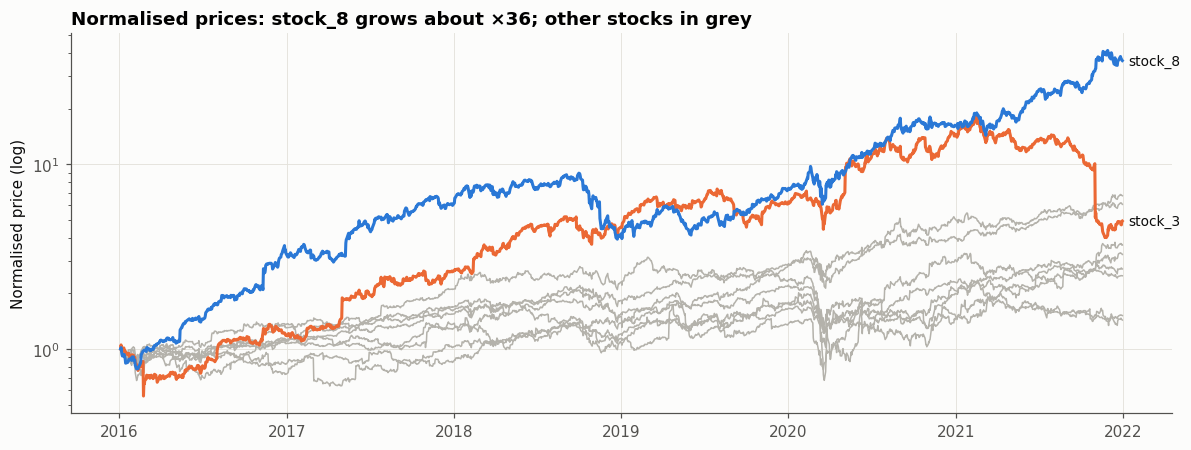

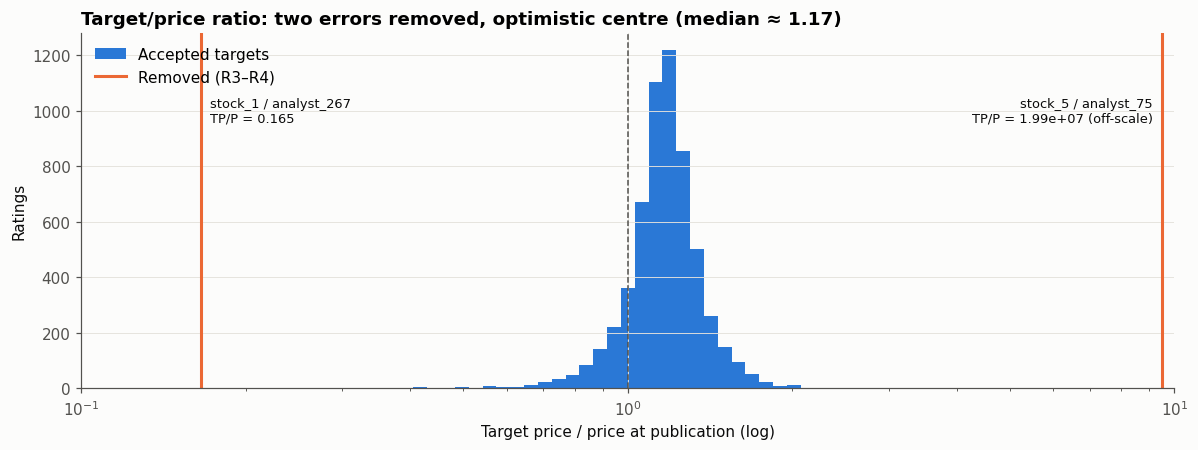

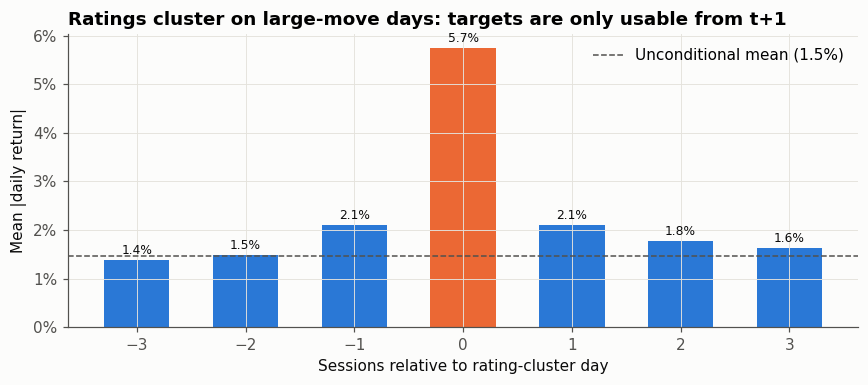

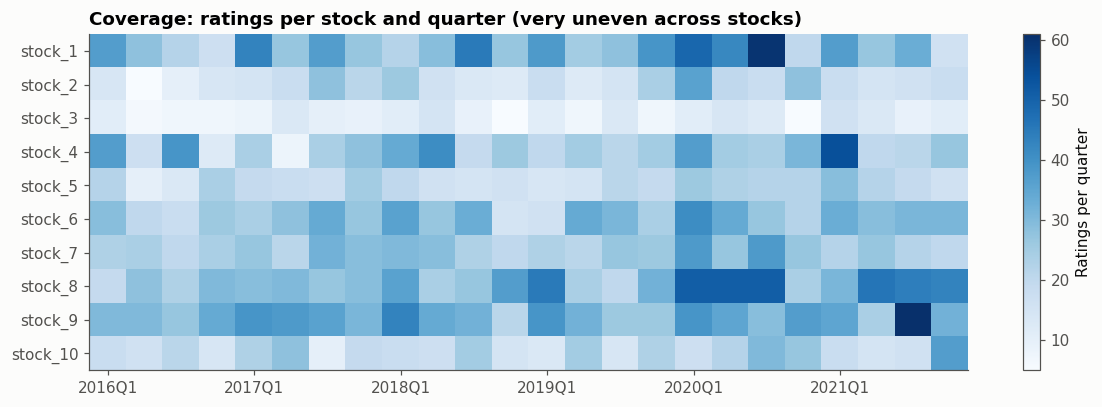

In [ ]:
# Normalised prices
fig, ax = plt.subplots()
highlight = {"stock_8": COLORS["blue"], "stock_3": COLORS["orange"]}
for c in PX.columns:
    ax.plot(PX.index, PX[c], color=highlight.get(c, COLORS["context"]),
            lw=2 if c in highlight else 1, zorder=3 if c in highlight else 2)
for c, col in highlight.items():
    ax.annotate(c, (PX.index[-1], PX[c].dropna().iloc[-1]), xytext=(4, 0), textcoords="offset points",
                color=COLORS["ink"], va="center", fontsize=9)
ax.set_yscale("log"); ax.set_ylabel("Normalised price (log)")
ax.set_title("Normalised prices: stock_8 grows about ×36; other stocks in grey")
plt.tight_layout(); plt.show()

#TP/P distribution of accepted targets, with the removed errors marked
fig, ax = plt.subplots()
bins = np.logspace(np.log10(0.1), np.log10(10), 80)
ax.hist(RT["tp_ratio"], bins=bins, color=COLORS["blue"], label="Accepted targets")
ax.axvline(1, color=COLORS["muted"], lw=1, ls="--")
removed = rt_ok.loc[~rt_ok["tp_ratio"].between(*CFG.tp_ratio_bounds, inclusive="neither")]
for r in removed.itertuples():
    x = float(np.clip(r.tp_ratio, 0.105, 9.5))
    ax.axvline(x, color=COLORS["orange"], lw=2)
    txt = f"{r.stock} / {r.analyst}\nTP/P = {r.tp_ratio:.3g}" + (" (off-scale)" if r.tp_ratio > 10 else "")
    ax.annotate(txt, (x, ax.get_ylim()[1] * 0.75), xytext=(-6 if x > 1 else 6, 0), textcoords="offset points",
                ha="right" if x > 1 else "left", fontsize=8.5, color=COLORS["ink"])
ax.plot([], [], color=COLORS["orange"], lw=2, label="Removed (R3–R4)")
ax.set_xscale("log"); ax.set_xlim(0.1, 10)
ax.set_xlabel("Target price / price at publication (log)"); ax.set_ylabel("Ratings")
ax.set_title("Target/price ratio: two errors removed, optimistic centre (median ≈ 1.17)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

# Event study
fig, ax = plt.subplots(figsize=(8, 3.6))
bars = ax.bar(event_study.index, event_study.values, width=0.6,
              color=[COLORS["orange"] if k == 0 else COLORS["blue"] for k in event_study.index])
ax.axhline(unconditional, color=COLORS["muted"], ls="--", lw=1, label=f"Unconditional mean ({unconditional:.1%})")
ax.legend(loc="upper right")
ax.bar_label(bars, labels=[f"{v:.1%}" for v in event_study.values], fontsize=8, color=COLORS["ink"], padding=2)
ax.set_xlabel("Sessions relative to rating-cluster day"); ax.set_ylabel("Mean |daily return|")
ax.set_title("Ratings cluster on large-move days: targets are only usable from t+1")
ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
plt.tight_layout(); plt.show()

# Coverage heatmap
cov_q = (RT.assign(q=RT["pub_date"].dt.to_period("Q")).groupby(["stock", "q"]).size().unstack("q").fillna(0))
cov_q = cov_q.loc[sorted(cov_q.index, key=natural_sort_key)]
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(cov_q.values, aspect="auto", cmap=CMAP_SEQ)
ax.set_yticks(range(len(cov_q))); ax.set_yticklabels(cov_q.index)
ax.set_xticks(range(0, cov_q.shape[1], 4)); ax.set_xticklabels([str(p) for p in cov_q.columns[::4]])
ax.grid(False); fig.colorbar(im, ax=ax, label="Ratings per quarter")
ax.set_title("Coverage: ratings per stock and quarter (very uneven across stocks)")
plt.tight_layout(); plt.show()

In [ ]:
display(AUDIT.to_frame())

,dataset,check,finding,n_rows,decision,example
0,prices,M1,All series normalised to 1.0 at their first ob...,0,Use returns only; verify target prices share t...,
1,prices,M2,2016-01-01 (New Year) has no price for 8/10 st...,1,Not a trading session: removed by the calendar...,2016-01-01
2,prices,M3,55 dates with identical gaps for 8 stocks = NY...,432,Trading calendar = dates where >= 50% of stock...,"2016-03-25, 2017-04-14, 2018-03-30"
3,prices,M4,"['stock_1', 'stock_6'] carry stale (forward-fi...",108,Holidays removed from the common calendar,0 % variation on holidays
4,prices,M5,10 daily moves > 20%; 1 revert,10,Persistent jumps = genuine events: kept,stock_3 2016-02-23 -35%; stock_8 2016-11-11 +3...
5,prices,M6,Extreme dispersion: stock_8 x36 vs x1.4-x6.8 f...,0,Leave-one-stock-out robustness test (Block 12),
6,prices,M7,Average pairwise correlation 0.40: strong comm...,0,Motivates a long/short construction and regime...,
7,prices,M8,"No non-positive prices, no duplicate keys, lon...",0,Encoded as assertions in clean_prices / unit t...,
8,ratings,R1,estimate_value stored as text; 'Not Available'...,9,Coerce to numeric; drop unparseable / non-posi...,
9,ratings,R2,Rows without analyst identifier,47,Drop: revision history cannot be tracked,


# **2. Statistical Diagnostics**

Every model used later rests on assumptions: GARCH assumes conditional heteroscedasticity, Student-t innovations assume fat tails, rank-IC inference assumes a stationary signal, covariance-based allocators assume a well-conditioned matrix. Here we test these preconditions before using the methods, so that each modelling choice in parts 4 to 9 is justified by evidence rather than habit.

All diagnostics use data up to the end of the development period (2019-12-31). The holdout (2020–2021) is not inspected here, which would otherwise be a subtle form of snooping. In-sample model fits in this block are diagnostic only, the models used for trading are re-estimated walk-forward in part 6.

In [ ]:
DIAG_END = CFG.ts("dev_end")
RET_D = RET.loc[:DIAG_END].iloc[1:]                   # simple returns, warm-up + DEV only
LRET_D = np.log1p(RET_D)                              # log returns
LOGP_D = np.log(PX.loc[:DIAG_END])                    # log price levels
EW_D = RET_D.mean(axis=1).rename("EW index")          # equal-weight market proxy (simple return)
print(f"Diagnostics window: {RET_D.index.min():%Y-%m-%d} -> {RET_D.index.max():%Y-%m-%d} "
      f"({len(RET_D)} sessions, holdout excluded)")

Diagnostics window: 2016-01-05 -> 2019-12-31 (1005 sessions, holdout excluded)


We run two tests with opposite null hypotheses and read them together:


*   ADF (Augmented Dickey-Fuller), H0: unit root. Rejection is evidence of stationarity.
*   KPSS, H0: stationarity. Rejection is evidence of a unit root.

A series is declared stationary only when ADF rejects and KPSS does not, and unit root when ADF does not reject and KPSS does. Log prices are tested with a constant and trend, log returns with a constant.



In [ ]:
from statsmodels.tools.sm_exceptions import InterpolationWarning

def stationarity_table(panel: pd.DataFrame, regression: str = "c", alpha: float = 0.05) -> pd.DataFrame:
    # ADF + KPSS cross-check for every column of a panel (NaNs dropped per column).
    rows = {}
    for col in panel.columns:
        x = panel[col].dropna()
        if len(x) < 50:
            continue
        adf_stat, adf_p, *_ = adfuller(x, regression=regression, autolag="AIC")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", InterpolationWarning)
            kpss_stat, kpss_p, *_ = kpss(x, regression=regression, nlags="auto")
        if adf_p < alpha and kpss_p > alpha:
            verdict = "stationary"
        elif adf_p > alpha and kpss_p < alpha:
            verdict = "unit root"
        else:
            verdict = "inconclusive"
        rows[col] = {"ADF stat": adf_stat, "ADF p": adf_p, "KPSS stat": kpss_stat,
                     "KPSS p (bounded 0.01-0.10)": kpss_p, "verdict": verdict}
    return pd.DataFrame(rows).T


st_prices = stationarity_table(LOGP_D, regression="ct")
st_returns = stationarity_table(LRET_D, regression="c")
summary_21 = pd.DataFrame({"log prices": st_prices["verdict"].value_counts(),
                           "log returns": st_returns["verdict"].value_counts()}).fillna(0).astype(int)
display(summary_21)
display(pd.concat({"log prices (const + trend)": st_prices, "log returns (const)": st_returns}, axis=1))

,log prices,log returns
verdict,,
inconclusive,1,0
stationary,0,10
unit root,9,0


log prices (const + trend)                                                           log returns (const)                                                        
                           ADF stat  ADF p KPSS stat KPSS p (bounded 0.01-0.10)       verdict            ADF stat  ADF p KPSS stat KPSS p (bounded 0.01-0.10)     verdict
stock_1                     -2.3775 0.3917    0.5008                     0.0100     unit root             -9.3676 0.0000    0.1094                     0.1000  stationary
stock_2                     -0.8400 0.9621    0.9871                     0.0100     unit root            -31.7335 0.0000    0.2351                     0.1000  stationary
stock_3                     -2.3662 0.3977    0.6354                     0.0100     unit root            -34.9088 0.0000    0.1095                     0.1000  stationary
stock_4                     -2.7818 0.2037    0.3567                     0.0100     unit root            -14.9797 0.0000    0.0462                     0.1000  stationary
stock_5                     -2.0302 0.5849    0.9478                     0.0100     unit root            -32.1120 0.0000    0.0622                     0.1000  stationary
stock_6                     -3.6797 0.0237    0.2002                     0.0159  inconclusive            -13.5953 0.0000    0.1062                     0.1000  stationary
stock_7                     -2.4433 0.3568    0.7411                     0.0100     unit root            -17.5480 0.0000    0.2374                     0.1000  stationary
stock_8                     -1.4122 0.8573    1.1703                     0.0100     unit root            -32.5701 0.0000    0.4009                     0.0768  stationary
stock_9                     -3.4064 0.0505    0.4708                     0.0100     unit root            -31.9449 0.0000    0.1116                     0.1000  stationary
stock_10                    -3.1059 0.1048    0.3088                     0.0100     unit root             -9.7484 0.0000    0.0518                     0.1000  stationary

Log prices 9/10 contain a unit root, 1 test is inconclusive (it is stock_6, borderline trend-stationary: ADF p = 0.02, KPSS p = 0.02). for log returns 10/10 are stationary (ADF p ≈ 0, KPSS never rejects; KPSS p-values are bounded at 0.10 by the lookup table). Thus no model or feature is ever built on price levels. Features are built from returns, ratios of prices to targets (bounded, mean-reverting quantities), changes, or cross-sectional ranks, and their stationarity is re-tested in part 5 with the same function.

Serial dependence: returns versus squared returns



*   Ljung-Box on returns (lags 5, 10, 21): is there linear predictability in the mean? If not, no ARMA structure is needed.
*   Ljung-Box on squared returns and Engle's ARCH-LM test (5 lags): is volatility clustered? If yes, a conditional volatility model is required and a rolling historical volatility is a lagging estimate.



,"LB(r) p, lag 5","LB(r) p, lag 10","LB(r) p, lag 21","LB(r²) p, lag 5","LB(r²) p, lag 10","LB(r²) p, lag 21",ARCH-LM(5) p
stock_1,0.5432,0.0451,0.1643,0.0000,0.0000,0.0000,0.0000
stock_2,0.7419,0.8408,0.6600,0.0000,0.0002,0.0000,0.0001
stock_3,0.0219,0.1674,0.4127,0.0044,0.0694,0.6564,0.0055
stock_4,0.0333,0.0303,0.0366,0.1070,0.0017,0.0056,0.1539
stock_5,0.8330,0.9464,0.9721,0.0000,0.0000,0.0000,0.0000
stock_6,0.0000,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000
stock_7,0.0116,0.0291,0.0102,0.0010,0.0178,0.3441,0.0017
stock_8,0.1887,0.1085,0.1649,0.0029,0.0511,0.1546,0.0036
stock_9,0.4227,0.4277,0.5548,0.9980,1.0000,1.0000,0.9980
stock_10,0.0080,0.0133,0.0345,0.0000,0.0000,0.0023,0.0000


Stocks with significant ARCH effects (p < 5%): 8 / 10
Stocks with significant return autocorrelation at lag 10 (p < 5%): 5 / 10


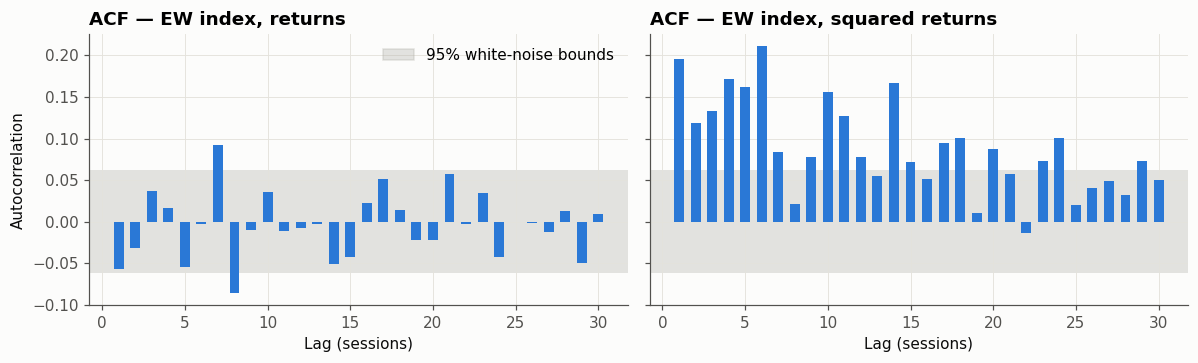

In [ ]:
def serial_dependence_table(returns: pd.DataFrame, lags: Sequence[int] = (5, 10, 21), arch_lags: int = 5) -> pd.DataFrame:
    """
    Ljung-Box p-values on returns and squared returns + ARCH-LM p-value, per column.
    """
    rows = {}
    for col in returns.columns:
        x = returns[col].dropna()
        lb_r = acorr_ljungbox(x, lags=list(lags))["lb_pvalue"]
        lb_r2 = acorr_ljungbox(x**2, lags=list(lags))["lb_pvalue"]
        arch_lm_p = het_arch(x - x.mean(), nlags=arch_lags)[1]
        row = {f"LB(r) p, lag {k}": lb_r.loc[k] for k in lags}
        row.update({f"LB(r²) p, lag {k}": lb_r2.loc[k] for k in lags})
        row["ARCH-LM(5) p"] = arch_lm_p
        rows[col] = row
    return pd.DataFrame(rows).T


sd_tbl = serial_dependence_table(LRET_D.assign(**{"EW index": np.log1p(EW_D)}))
display(sd_tbl)
print(f"Stocks with significant ARCH effects (p < 5%): {(sd_tbl.drop('EW index')['ARCH-LM(5) p'] < 0.05).sum()} / {len(sd_tbl) - 1}")
print(f"Stocks with significant return autocorrelation at lag 10 (p < 5%): "
      f"{(sd_tbl.drop('EW index')['LB(r) p, lag 10'] < 0.05).sum()} / {len(sd_tbl) - 1}")

#ACF of EW index returns and squared returns
from statsmodels.tsa.stattools import acf
ew_l = np.log1p(EW_D)
acf_r = acf(ew_l, nlags=30, fft=True)[1:]
acf_r2 = acf(ew_l**2, nlags=30, fft=True)[1:]
band = 1.96 / np.sqrt(len(ew_l))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, vals, title in [(axes[0], acf_r, "Returns"), (axes[1], acf_r2, "Squared returns")]:
    ax.axhspan(-band, band, color=COLORS["context"], alpha=0.35, lw=0, zorder=0)
    ax.bar(np.arange(1, 31), vals, width=0.6, color=COLORS["blue"], zorder=2)
    ax.set_title(f"ACF — EW index, {title.lower()}"); ax.set_xlabel("Lag (sessions)")
axes[0].set_ylabel("Autocorrelation")
axes[0].legend(handles=[mpl.patches.Patch(color=COLORS["context"], alpha=0.35, label="95% white-noise bounds")],
               loc="upper right")
plt.tight_layout(); plt.show()

Volatility clustering is pervasive. ARCH-LM is significant for 8/10 stocks and for the EW index. The ACF of squared index returns stays at 0.1–0.2 for about 15 lags. The two exceptions are informative, not contradictory: stock_4 shows clustering at lags 10–21 (Ljung-Box on r², p < 0.01), just not in the 5-lag ARCH-LM window. stock_9 looks homoscedastic (p ≈ 1), but only because a handful of crash days dominate the squared returns (excess kurtosis 28). Excluding its 5 largest days, the autocorrelation of absolute returns is about 0.12.

Mean predictability is weak. Ljung-Box on returns is significant at lag 10 for 5/10 stocks, but the first-order autocorrelations are small and mostly negative (at most −0.13, for stock_6). This is a short-term reversal / microstructure effect, too small to matter for a weekly-rebalanced strategy.

Thus a conditional volatility model (GARCH family) is needed, with a constant mean (no ARMA). One-month reversal is kept as a control feature in Block 4, so that analyst features are not credited with a price effect.

Generated by an LLM.

Equity volatility typically rises more after a fall than after a rise of the same size (leverage / volatility-feedback effect). We test it in two complementary ways, per stock:



*   Engle-Ng (1993) sign-bias test. Fit a symmetric GARCH(1,1)-t and regress the squared standardised residuals $z_t^2$ on $S^-_{t-1}$ (dummy for a negative shock), $S^-_{t-1}\varepsilon_{t-1}$ and $S^+_{t-1}\varepsilon_{t-1}$. A significant joint F-test means the symmetric model misses asymmetry.
*   Likelihood-ratio test of GJR-GARCH(1,1)-t, $\sigma_t^2=\omega+(\alpha+\gamma\,\mathbb{1}_{\varepsilon_{t-1}<0})\varepsilon_{t-1}^2+\beta\sigma_{t-1}^2$, against the nested symmetric GARCH ($\gamma=0$): $LR = 2(\ell_{GJR}-\ell_{GARCH}) \sim \chi^2_1$.

We also verify the covariance-stationarity condition of the fitted GJR model: $\alpha+\gamma/2+\beta<1$ (the $\gamma/2$ term assumes symmetric innovations).

In [ ]:
def asymmetry_diagnostics(returns: pd.DataFrame) -> pd.DataFrame:
    # Engle-Ng sign-bias test (on a symmetric GARCH-t) and LR test GJR vs GARCH, per column.
    rows = {}
    for col in returns.columns:
        x = returns[col].dropna() * 100.0                       # percent returns: better optimiser scaling
        sym = arch_model(x, mean="Constant", vol="GARCH", p=1, o=0, q=1, dist="t").fit(disp="off")
        gjr_model = arch_model(x, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t")
        gjr = gjr_model.fit(disp="off")
        refit = gjr.loglikelihood < sym.loglikelihood           # nested model: optimiser missed the optimum
        if refit:                                                # restart GJR from the GARCH solution (gamma = 0)
            sp = sym.params
            start = np.array([sp["mu"], sp["omega"], sp["alpha[1]"], 0.0, sp["beta[1]"], sp["nu"]])
            gjr = gjr_model.fit(disp="off", starting_values=start)

        # Engle-Ng regression on the symmetric model's residuals
        e = sym.resid
        z2 = sym.std_resid**2
        e_lag = e.shift(1)
        s_neg = (e_lag < 0).astype(float)
        X = pd.DataFrame({"const": 1.0, "sign_bias": s_neg, "neg_size_bias": s_neg * e_lag,
                          "pos_size_bias": (1 - s_neg) * e_lag}).iloc[1:]
        ols = sm.OLS(z2.iloc[1:], X).fit()
        joint = ols.f_test("sign_bias = 0, neg_size_bias = 0, pos_size_bias = 0")

        lr = 2 * (gjr.loglikelihood - sym.loglikelihood)
        p = gjr.params
        rows[col] = {
            "EngleNg joint p": float(joint.pvalue),
            "t(neg size bias)": ols.tvalues["neg_size_bias"],
            "LR GJR vs GARCH": lr, "LR p": stats.chi2.sf(lr, df=1),
            "alpha": p["alpha[1]"], "gamma": p["gamma[1]"], "beta": p["beta[1]"],
            "persistence a+g/2+b": p["alpha[1]"] + p["gamma[1]"] / 2 + p["beta[1]"],
            "nu (Student-t)": p["nu"], "GJR restarted": bool(refit),
        }
    return pd.DataFrame(rows).T


asym_tbl = asymmetry_diagnostics(RET_D.assign(**{"EW index": EW_D}))
display(asym_tbl)
stocks_only = asym_tbl.drop("EW index")
print(f"gamma > 0 for {(stocks_only['gamma'] > 0).sum()} / {len(stocks_only)} stocks; "
      f"LR test significant (5%) for {(stocks_only['LR p'] < 0.05).sum()} / {len(stocks_only)}; "
      f"Engle-Ng joint test significant for {(stocks_only['EngleNg joint p'] < 0.05).sum()} / {len(stocks_only)}")
print(f"Covariance-stationary (a+g/2+b < 1): {(asym_tbl['persistence a+g/2+b'] < 1).all()}")

,EngleNg joint p,t(neg size bias),LR GJR vs GARCH,LR p,alpha,gamma,beta,persistence a+g/2+b,nu (Student-t),GJR restarted
stock_1,0.2414,0.2463,33.0619,0.0000,0.0000,0.2226,0.8497,0.9609,3.9533,False
stock_2,0.6704,0.4974,2.8576,0.0909,0.0458,0.0485,0.9168,0.9868,4.2017,False
stock_3,0.7603,-0.1548,10.8499,0.0010,0.0000,0.2196,0.7182,0.8280,3.3389,False
stock_4,0.7296,-0.6232,0.2285,0.6327,0.0423,0.0107,0.9476,0.9952,3.7529,False
stock_5,0.3021,-1.7040,26.4654,0.0000,0.0212,0.2139,0.8214,0.9495,3.8323,False
stock_6,0.1980,-1.4107,19.3612,0.0000,0.0006,0.1977,0.8787,0.9781,4.1816,False
stock_7,0.6662,0.1075,5.8030,0.0160,0.0637,0.2102,0.5387,0.7075,4.3858,False
stock_8,0.4512,-0.2186,21.4194,0.0000,0.0222,0.2269,0.7853,0.9209,3.4220,False
stock_9,0.9806,-0.2101,0.0000,1.0000,0.0000,0.0000,0.9894,0.9894,3.6584,True
stock_10,0.6754,0.0503,2.2150,0.1367,0.1846,0.1673,0.6292,0.8975,2.8908,False


gamma > 0 for 9 / 10 stocks; LR test significant (5%) for 6 / 10; Engle-Ng joint test significant for 0 / 10
Covariance-stationary (a+g/2+b < 1): True




*   Asymmetry is strong where volatility clusters. The GJR asymmetry coefficient is positive for 9/10 stocks, typically γ ≈ 0.20–0.23 with α ≈ 0: variance reacts almost only to negative shocks. The LR test rejects the symmetric model for 6/10 stocks and for the EW index (LR = 20.4).

*   stock_9 is the consistent exception. The optimiser first returned a GJR likelihood below the nested GARCH one, which is impossible at the true optimum; restarting from the GARCH solution gives γ = 0 and LR = 0.
*   The Engle-Ng regression rejects for none of the stocks. This is a known power problem, not counter-evidence. It is an OLS regression on $z_t^2$, and with ν ≈ 3–4 the squared residuals have extremely heavy tails, so the OLS test is very noisy. The LR test uses the full Student-t likelihood and is the more powerful tool here.


*   Persistence $\alpha+\gamma/2+\beta$ lies between 0.71 and 0.995: every fitted model is covariance-stationary.

Thus we take GJR-GARCH(1,1) with Student-t innovations as the volatility model. Because 2 or 3 stocks show weak or no GARCH structure, part 6 evaluates the out-of-sample forecast quality (QLIKE) per stock against historical volatility rather than assuming GJR is always better.

,JB stat,JB p,skew,excess kurtosis,Student-t nu (fit),worst day,best day
stock_1,"1,083.7307",0.0000,-0.4553,5.0051,2.9582,-0.1049,0.0681
stock_2,694.5671,0.0000,-0.3290,4.0192,3.4500,-0.0935,0.0942
stock_3,"122,443.0343",0.0000,-2.1891,53.8966,3.1085,-0.4311,0.2524
stock_4,"1,517.4022",0.0000,-0.3483,5.9792,3.2687,-0.0954,0.1003
stock_5,607.0170,0.0000,0.0194,3.8072,3.2140,-0.0720,0.0800
stock_6,641.5810,0.0000,-0.1113,3.9079,3.0392,-0.0744,0.0730
stock_7,"2,059.7065",0.0000,0.3450,6.9793,3.9051,-0.0731,0.1055
stock_8,"7,665.2581",0.0000,0.2156,13.5228,2.9206,-0.2077,0.2609
stock_9,"33,928.4173",0.0000,-2.2649,28.1018,3.0602,-0.2765,0.1587
stock_10,"14,937.5433",0.0000,0.7560,18.8264,2.6164,-0.1361,0.2087


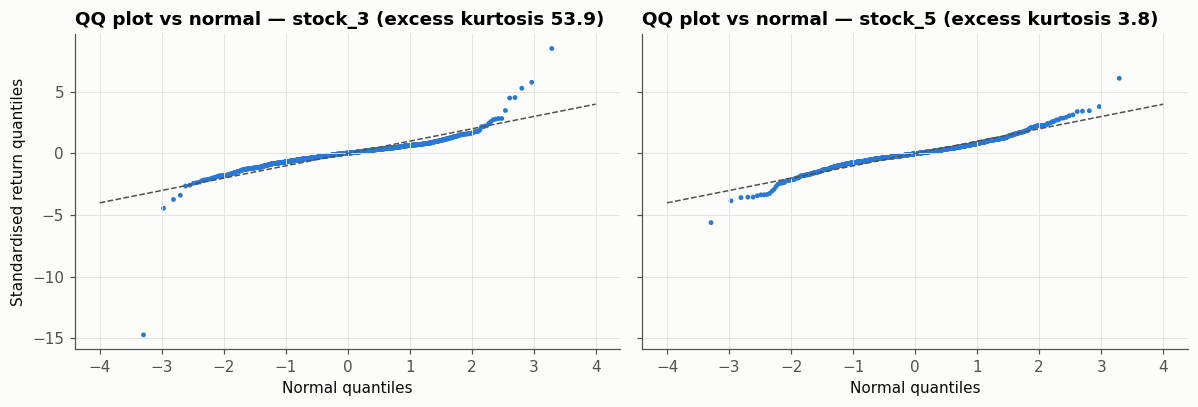

In [ ]:
def tail_table(returns: pd.DataFrame) -> pd.DataFrame:
    # Jarque-Bera, skewness, excess kurtosis and fitted Student-t degrees of freedom, per column.
    rows = {}
    for col in returns.columns:
        x = returns[col].dropna()
        z = (x - x.mean()) / x.std(ddof=1)
        jb_stat, jb_p, skew, kurt = jarque_bera(x)
        nu, _, _ = stats.t.fit(z)
        rows[col] = {"JB stat": jb_stat, "JB p": jb_p, "skew": skew, "excess kurtosis": kurt - 3.0,
                     "Student-t nu (fit)": nu, "worst day": x.min(), "best day": x.max()}
    return pd.DataFrame(rows).T


tails = tail_table(LRET_D.assign(**{"EW index": np.log1p(EW_D)}))
display(tails)

hi_k = tails.drop("EW index")["excess kurtosis"].idxmax()
lo_k = tails.drop("EW index")["excess kurtosis"].idxmin()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True, sharey=True)
for ax, col in zip(axes, [hi_k, lo_k]):
    z = ((LRET_D[col] - LRET_D[col].mean()) / LRET_D[col].std()).dropna().sort_values().values
    q = stats.norm.ppf((np.arange(1, len(z) + 1) - 0.5) / len(z))
    ax.scatter(q, z, s=10, color=COLORS["blue"], edgecolors="none")
    ax.plot([-4, 4], [-4, 4], color=COLORS["muted"], lw=1, ls="--")
    ax.set_title(f"QQ plot vs normal — {col} (excess kurtosis {tails.loc[col, 'excess kurtosis']:.1f})")
    ax.set_xlabel("Normal quantiles")
axes[0].set_ylabel("Standardised return quantiles")
plt.tight_layout(); plt.show()

Normality is rejected for 10/10 stocks (Jarque-Bera p ≈ 0). Excess kurtosis ranges from 3.8 (stock_5) to 53.9 (stock_3, driven by its −35 % day). Fitted Student-t degrees of freedom lie between 2.6 and 3.9 (median 3.1), i.e. very heavy tails, and 6/10 stocks are negatively skewed. The QQ plot of stock_3 shows a −15σ day, an event with essentially zero probability under a normal law.

Thus we have to take a hypothesis of Student-t innovations in GARCH. Risk will be measured with historical and Cornish-Fisher VaR/CVaR, never Gaussian VaR. Features will have to be evaluated with rank (Spearman) IC wich are robust to outliers. And Confidence intervals will have to come from a block bootstrap, not from normal-theory formulas.

Three questions for portfolio construction:


*   How strong is the common factor? Average pairwise correlation, and the share of variance explained by the first eigenvalue of the correlation matrix (a market-factor proxy), both on rolling 63-session windows.

*   Is it stable? If correlation rises in sell-offs, diversification disappears exactly when it is needed. This motivates regime-dependent exposure.
*   Is the sample covariance well conditioned? With 10 assets and short windows, the sample covariance can be ill-conditioned, and its inverse (used by optimisers) amplifies estimation error. We compare the condition number of the sample covariance with its Ledoit-Wolf shrunk counterpart on 126-session windows.




,mean,min,50%,max
avg pairwise correlation,0.3268,0.1108,0.3206,0.6101
first eigenvalue share,0.4196,0.2534,0.4027,0.6519


,mean,min,50%,max
sample,31.5467,17.9623,31.3247,47.3634
Ledoit-Wolf,13.3527,2.7902,10.9622,31.0613
shrinkage,0.2292,0.0608,0.1759,0.5961


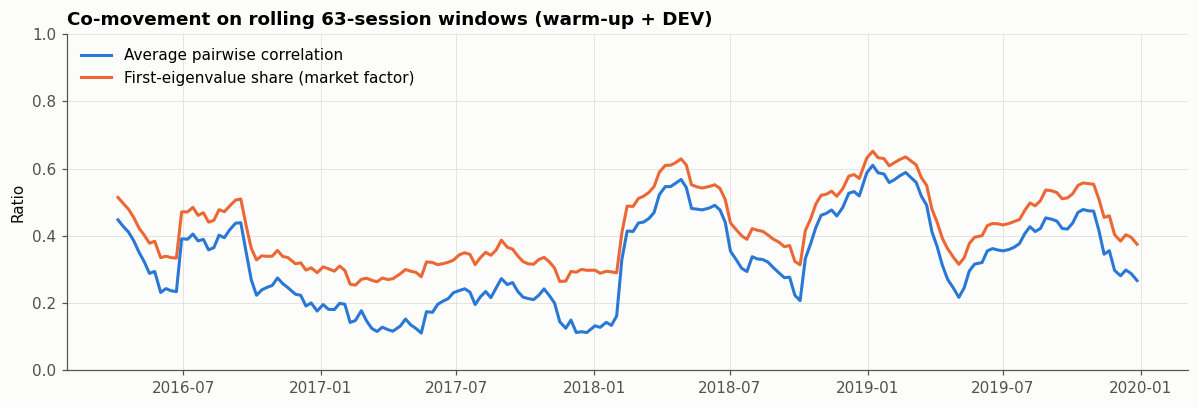

In [ ]:
WIN = 63
roll_rows = []
for end in range(WIN, len(RET_D) + 1, 5):                       # every 5 sessions, trailing window only
    window = RET_D.iloc[end - WIN:end].dropna(axis=1, how="any")
    c = window.corr().values
    off = c[~np.eye(len(c), dtype=bool)]
    eig = np.linalg.eigvalsh(c)
    roll_rows.append({"date": RET_D.index[end - 1], "avg pairwise correlation": off.mean(),
                      "first eigenvalue share": eig[-1] / eig.sum()})
co_move = pd.DataFrame(roll_rows).set_index("date")

cond_rows = []
for end in range(126, len(RET_D) + 1, 21):
    window = RET_D.iloc[end - 126:end].dropna(axis=1, how="any")
    s_cov = np.cov(window.values, rowvar=False)
    lw = LedoitWolf().fit(window.values)
    cond_rows.append({"date": RET_D.index[end - 1], "sample": np.linalg.cond(s_cov),
                      "Ledoit-Wolf": np.linalg.cond(lw.covariance_), "shrinkage": lw.shrinkage_})
cond_tbl = pd.DataFrame(cond_rows).set_index("date")

display(co_move.describe().T[["mean", "min", "50%", "max"]])
display(cond_tbl.describe().T[["mean", "min", "50%", "max"]])

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(co_move.index, co_move["avg pairwise correlation"], color=COLORS["blue"], lw=2, label="Average pairwise correlation")
ax.plot(co_move.index, co_move["first eigenvalue share"], color=COLORS["orange"], lw=2, label="First-eigenvalue share (market factor)")
ax.set_ylim(0, 1); ax.set_ylabel("Ratio")
ax.set_title(f"Co-movement on rolling {WIN}-session windows (warm-up + DEV)")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

The common factor is strong and highly unstable. The average pairwise correlation is 0.33 on average (range 0.11–0.61), and the first eigenvalue explains 42 % of the variance on average (25–65 %). Correlation jumps from about 0.15 to 0.55 in the February 2018 volatility shock and reaches about 0.60 in the Q4 2018 sell-off: diversification between stocks disappears in sell-offs. This motivates a long/short book whose short leg hedges the common factor, and regime-dependent net exposure.

Conditioning. At N = 10 and T = 126 the sample covariance is not ill-conditioned (median condition number 31, max 47). Ledoit-Wolf shrinks it with a median intensity of 0.18 and brings the condition number to about 11. It isn't necessary but it is kept in HRP for robustness.

Generated by LLM

Features are evaluated against forward 21-session returns sampled daily. Consecutive labels share 20 of their 21 daily returns, so they are autocorrelated by construction: theoretically $\rho_k \approx (21-k)/21$ for $k<21$, even when daily returns are white noise. Ordinary standard errors would then be understated by roughly a factor $\sqrt{21}$, making noise look significant. We verify this on the EW index. Consequence: every mean IC, spread or regression coefficient built on overlapping horizons is tested with Newey-West (HAC) standard errors using at least 21 lags

In [ ]:
h = CFG.label_horizon
overlap = np.log1p(EW_D).rolling(h).sum().dropna()             # overlapping 21-session log returns
acf_overlap = acf(overlap, nlags=30, fft=True)
tbl_26 = pd.DataFrame({"empirical ACF": acf_overlap[[1, 5, 10, 15, 20, 25]],
                       "theory (h-k)/h": [max(h - k, 0) / h for k in [1, 5, 10, 15, 20, 25]]},
                      index=pd.Index([1, 5, 10, 15, 20, 25], name="lag k"))
display(tbl_26.T)

m, t_naive = overlap.mean(), overlap.mean() / (overlap.std(ddof=1) / np.sqrt(len(overlap)))
_, t_hac = newey_west_tstat(overlap, lags=h)
print(f"Mean overlapping 21d return: {m:.4f} | naive t-stat: {t_naive:.2f} | Newey-West t-stat (21 lags): {t_hac:.2f} "
      f"| ratio naive/HAC: {t_naive / t_hac:.1f}x")

lag k,1,5,10,15,20,25
empirical ACF,0.9404,0.7226,0.4594,0.1929,-0.0670,-0.1203
theory (h-k)/h,0.9524,0.7619,0.5238,0.2857,0.0476,0.0000


Mean overlapping 21d return: 0.0238 | naive t-stat: 15.28 | Newey-West t-stat (21 lags): 4.20 | ratio naive/HAC: 3.6x


The empirical ACF of overlapping 21-session returns matches the theoretical pattern (lag 1: 0.94 vs 0.95; lag 10: 0.46 vs 0.52). The naive t-statistic of the mean (15.3) overstates significance by a factor of 3.6 compared with the Newey-West t-statistic (4.2). Without HAC correction, almost any feature would look "significant". Newey-West with ≥ 21 lags for all overlapping-horizon inference, and block bootstrapping for performance confidence intervals.

In [ ]:
n = len(stocks_only)
decisions = pd.DataFrame([
    ["Any model of returns", "Stationary input", "ADF + KPSS",
     f"log prices: {int((st_prices['verdict'] == 'unit root').sum())}/{n} unit root; "
     f"log returns: {int((st_returns['verdict'] == 'stationary').sum())}/{n} stationary",
     "Model returns and bounded / cross-sectional transforms, never levels"],
    ["Mean model", "Linear predictability", "Ljung-Box on r",
     f"{int((sd_tbl.drop('EW index')['LB(r) p, lag 10'] < 0.05).sum())}/{n} significant at lag 10",
     "No ARMA mean model; constant mean"],
    ["Volatility model", "Volatility clustering", "Ljung-Box on r², ARCH-LM",
     f"ARCH-LM significant for {int((sd_tbl.drop('EW index')['ARCH-LM(5) p'] < 0.05).sum())}/{n}",
     "Conditional volatility model (GARCH family)"],
    ["Asymmetric volatility", "Leverage effect", "Engle-Ng, LR GJR vs GARCH",
     f"gamma > 0 for {int((stocks_only['gamma'] > 0).sum())}/{n}; LR significant for {int((stocks_only['LR p'] < 0.05).sum())}/{n}",
     "GJR-GARCH(1,1)"],
    ["Innovation distribution", "Fat tails", "Jarque-Bera, fitted Student-t",
     f"JB rejects normality for {int((tails.drop('EW index')['JB p'] < 0.05).sum())}/{n}; median nu = {tails.drop('EW index')['Student-t nu (fit)'].median():.1f}",
     "Student-t innovations; historical & Cornish-Fisher VaR/CVaR"],
    ["Covariance estimation", "Well-conditioned matrix", "Condition number",
     f"median cond.: sample {cond_tbl['sample'].median():.0f} vs Ledoit-Wolf {cond_tbl['Ledoit-Wolf'].median():.0f}",
     "Ledoit-Wolf shrinkage in HRP / risk estimates"],
    ["Portfolio design", "Diversification between stocks", "Rolling correlation, eigenvalues",
     f"avg correlation {co_move['avg pairwise correlation'].mean():.2f}; first eigenvalue {co_move['first eigenvalue share'].mean():.0%} of variance",
     "Long/short book; regime-dependent net exposure"],
    ["Inference on 21d horizons", "Independent observations", "ACF of overlapping returns",
     f"lag-1 ACF {acf_overlap[1]:.2f} (theory {(h - 1) / h:.2f})",
     "Newey-West t-stats (>= 21 lags); block bootstrap for CIs"],
], columns=["Method / choice", "Condition", "Test", "Evidence (2016-2019)", "Decision"])
decisions

,Method / choice,Condition,Test,Evidence (2016-2019),Decision
0,Any model of returns,Stationary input,ADF + KPSS,log prices: 9/10 unit root; log returns: 10/10...,Model returns and bounded / cross-sectional tr...
1,Mean model,Linear predictability,Ljung-Box on r,5/10 significant at lag 10,No ARMA mean model; constant mean
2,Volatility model,Volatility clustering,"Ljung-Box on r², ARCH-LM",ARCH-LM significant for 8/10,Conditional volatility model (GARCH family)
3,Asymmetric volatility,Leverage effect,"Engle-Ng, LR GJR vs GARCH",gamma > 0 for 9/10; LR significant for 6/10,"GJR-GARCH(1,1)"
4,Innovation distribution,Fat tails,"Jarque-Bera, fitted Student-t",JB rejects normality for 10/10; median nu = 3.1,Student-t innovations; historical & Cornish-Fi...
5,Covariance estimation,Well-conditioned matrix,Condition number,median cond.: sample 31 vs Ledoit-Wolf 11,Ledoit-Wolf shrinkage in HRP / risk estimates
6,Portfolio design,Diversification between stocks,"Rolling correlation, eigenvalues",avg correlation 0.33; first eigenvalue 42% of ...,Long/short book; regime-dependent net exposure
7,Inference on 21d horizons,Independent observations,ACF of overlapping returns,lag-1 ACF 0.94 (theory 0.95),Newey-West t-stats (>= 21 lags); block bootstr...


# **3. Point-in-Time Target-Price Snapshot**

Every rating-based feature is a function of the set of target prices an investor could have known on date t. Getting this set right is where most look-ahead bugs hide: using a target before it was public, keeping a target its author has long abandoned, or counting a re-initiation after a year of silence as a "revision". This part builds that set once, in a vectorised and testable way, and every feature in part 4 is derived from it.

For each session $t$, stock $s$ and analyst $a$, the active target is

$$TP_{s,a}(t) = TP \text{ of the last accepted rating of } a \text{ on } s \text{ with } \text{knowledge_date} \le t, \quad \text{if } \text{age} = \text{pos}(t) - \text{pos}(\text{knowledge_date}) < 252,$$

and is undefined (NaN) otherwise. The knowledge date is the first session after publication (part 1), and the 252-session expiry reflects the 12-month horizon of a target price. A reiteration refreshes the age of a target.

A revision is fresh only if the analyst's previous target was still active (age < 252) when the new one became known. Otherwise the new rating is treated as a re-initiation: it carries no information about a change of view.



1.   Pivot accepted ratings to a knowledge_date × (stock, analyst) panel (if two ratings map to the same knowledge date, the later publication wins).

2.   Reindex to the trading calendar and forward-fill with a limit of 251 sessions: a target stays active for ages 0 to 251, i.e. exactly 252 sessions.

3.   Apply the same fill to the position of each knowledge date to obtain the age.
4.   Aggregate across analysts per stock (median, mean, count, dispersion) and apply the minimum-coverage rule.


5.   Classify each rating as fresh revision (up / down), reiteration or (re-)initiation, and count arrivals per session and stock.



In [ ]:
# Implemented with LLM and modified to correspond to the output outlined by the theory
@dataclass
class TPSnapshot:
    # Point-in-time view of analyst targets on the trading calendar.
    tp: pd.DataFrame            # sessions x (stock, analyst): active target
    age: pd.DataFrame           # sessions x (stock, analyst): age in sessions of the active target
    n_active: pd.DataFrame      # sessions x stock
    cons_median: pd.DataFrame
    cons_mean: pd.DataFrame
    dispersion: pd.DataFrame
    n_up: pd.DataFrame
    n_down: pd.DataFrame
    n_reit: pd.DataFrame
    n_init: pd.DataFrame
    rev_sum: pd.DataFrame
    events: pd.DataFrame        # rating-level table with the fresh/re-initiation classification


def classify_ratings(rt: pd.DataFrame, sessions: pd.DatetimeIndex, cfg: Config = CFG) -> pd.DataFrame:
    # Add session positions and the fresh-revision / reiteration / re-initiation classification.
    ev = rt.sort_values(["stock", "analyst", "knowledge_date", "pub_date"]).copy()
    ev["k_pos"] = sessions.get_indexer(ev["knowledge_date"])
    assert (ev["k_pos"] >= 0).all(), "knowledge date outside the trading calendar"
    prev_pos = ev.groupby(["stock", "analyst"])["k_pos"].shift(1)
    prev_active = (ev["k_pos"] - prev_pos) < cfg.tp_expiry_days            # previous target still active?
    ev["kind"] = np.select(
        [ev["prev_tp"].isna() | ~prev_active,
         ev["is_reiteration"],
         ev["revision"] > 0,
         ev["revision"] < 0],
        ["initiation", "reiteration", "up", "down"], default="reiteration")
    ev["fresh_revision"] = np.where(ev["kind"].isin(["up", "down"]), ev["revision"], np.nan)
    return ev


def build_tp_snapshot(rt: pd.DataFrame, sessions: pd.DatetimeIndex, stocks: Sequence[str],
                      cfg: Config = CFG) -> TPSnapshot:
    # Vectorised point-in-time snapshot of analyst targets (knowledge date <= t, age < expiry).
    ev = classify_ratings(rt, sessions, cfg)
    last = ev.drop_duplicates(["knowledge_date", "stock", "analyst"], keep="last")
    wide = last.pivot(index="knowledge_date", columns=["stock", "analyst"], values="tp").reindex(sessions)
    wide = wide.sort_index(axis=1)
    pos = pd.Series(np.arange(len(sessions), dtype=float), index=sessions)
    k_pos = wide.notna().mul(pos, axis=0).where(wide.notna())

    limit = cfg.tp_expiry_days - 1                                      # ages 0..251 -> 252 sessions
    tp = wide.ffill(limit=limit)
    age = k_pos.ffill(limit=limit).rsub(pos, axis=0)

    def per_stock(panel: pd.DataFrame, how: str) -> pd.DataFrame:
        out = getattr(panel.T.groupby(level="stock"), how)().T
        return out.reindex(columns=list(stocks))

    n_active = per_stock(tp.notna().astype(float), "sum").fillna(0.0)
    enough = n_active >= cfg.min_analysts
    cons_median = per_stock(tp, "median").where(enough)
    cons_mean = per_stock(tp, "mean").where(enough)
    dispersion = per_stock(np.log(tp), "std").where(enough)

    def arrivals(mask: pd.Series, values: Optional[pd.Series] = None) -> pd.DataFrame:
        v = mask.astype(float) if values is None else values.where(mask, 0.0)
        out = (ev.assign(_v=v).groupby(["knowledge_date", "stock"])["_v"].sum()
               .unstack("stock").reindex(index=sessions, columns=list(stocks)))
        return out.fillna(0.0)

    return TPSnapshot(
        tp=tp, age=age, n_active=n_active, cons_median=cons_median, cons_mean=cons_mean, dispersion=dispersion,
        n_up=arrivals(ev["kind"] == "up"), n_down=arrivals(ev["kind"] == "down"),
        n_reit=arrivals(ev["kind"] == "reiteration"), n_init=arrivals(ev["kind"] == "initiation"),
        rev_sum=arrivals(ev["kind"].isin(["up", "down"]), ev["fresh_revision"].fillna(0.0)),
        events=ev,
    )


SNAP = build_tp_snapshot(RT, PX.index, PX.columns, CFG)
print(f"Active-target panel: {SNAP.tp.shape[0]:,} sessions x {SNAP.tp.shape[1]} (stock, analyst) pairs "
      f"| {SNAP.tp.notna().sum().sum():,} active cells")
display(SNAP.events["kind"].value_counts().to_frame("n ratings").T)
display(pd.DataFrame({
    "avg active analysts": SNAP.n_active.mean(),
    "share of sessions with consensus (>= 3)": SNAP.cons_median.notna().mean(),
    "first session with consensus": SNAP.cons_median.apply(lambda s: s.first_valid_index()),
    "median age of active targets (sessions)": SNAP.age.T.groupby(level="stock").median().T.median().reindex(PX.columns),
}).loc[PX.columns])

Active-target panel: 1,511 sessions x 445 (stock, analyst) pairs | 322,752 active cells


kind,up,reiteration,down,initiation
n ratings,3168,1260,1020,481


,avg active analysts,share of sessions with consensus (>= 3),first session with consensus,median age of active targets (sessions)
stock,,,,
stock_1,30.2588,0.9974,2016-01-08,34.0000
stock_2,13.9643,0.9881,2016-01-29,30.0000
stock_3,8.8379,0.9861,2016-02-03,31.5000
stock_4,24.8213,0.9974,2016-01-08,34.0000
stock_5,16.1721,0.9980,2016-01-07,32.0000
stock_6,24.9431,0.9974,2016-01-08,32.0000
stock_7,22.7028,0.9835,2016-02-09,30.0000
stock_8,25.7955,0.9960,2016-01-12,27.0000
stock_9,28.8941,0.9914,2016-01-22,30.0000


3 168 fresh upward revisions, 1 020 downward revisions, 1 260 reiterations and 481 (re-)initiations. The 3:1 up/down ratio reflects the rising market of 2016–2021: revision counts must be read cross-sectionally or relative to their own history, not in absolute terms.

Every stock has a valid consensus (≥ 3 analysts) on more than 98 % of sessions, from February 2016 at the latest, well before the DEV period. Average coverage ranges from 8.8 active analysts (stock_3) to 30.3 (stock_1).

The median age of active targets is 27–34 sessions (about 1.5 months): the consensus reflects recent views.

The snapshot is validated against an independent, deliberately naive reference implementation. For 3,000 random (session, stock, analyst) cells, including empty ones, a plain loop looks up the analyst's ratings known at that session, takes the last one and applies the expiry rule. The vectorised panel must match it exactly. We also check:



1.   Age bounds: every active target has an age between 0 and 251 sessions.

2.   No early use: no target is active before its knowledge date.

3.   Expiry: a known case of a target that goes silent for more than 252 sessions must disappear from the consensus before the analyst's next rating.
4.   Coverage rule: consensus values exist only where at least 3 analysts are active.


5.   Truncation (no look-ahead): a snapshot built only from data available up to date T equals the full snapshot restricted to dates ≤ T.




In [ ]:
sessions = PX.index
pos_of = pd.Series(np.arange(len(sessions)), index=sessions)
rng = np.random.default_rng(CFG.seed)
pairs = SNAP.tp.columns
by_pair = {k: g.sort_values(["knowledge_date", "pub_date"]) for k, g in RT.groupby(["stock", "analyst"])}

# Naive reference implementation on random cells
mismatches = 0
for _ in range(3000):
    t = sessions[rng.integers(len(sessions))]
    s, a = pairs[rng.integers(len(pairs))]
    hist = by_pair[(s, a)]
    known = hist[hist["knowledge_date"] <= t]
    if known.empty or pos_of[t] - pos_of[known["knowledge_date"].iloc[-1]] >= CFG.tp_expiry_days:
        expected = np.nan
    else:
        expected = known["tp"].iloc[-1]
    got = SNAP.tp.at[t, (s, a)]
    same = (np.isnan(expected) and np.isnan(got)) or np.isclose(expected, got)
    mismatches += int(not same)
assert mismatches == 0, f"{mismatches} mismatches versus the naive reference"

# Age bounds and 3. no early use
active_age = SNAP.age[SNAP.tp.notna()]
assert np.nanmin(active_age.values) >= 0 and np.nanmax(active_age.values) <= CFG.tp_expiry_days - 1
first_kd = RT.groupby(["stock", "analyst"])["knowledge_date"].min()
first_active = SNAP.tp.apply(lambda c: c.first_valid_index())
assert (first_active.reindex(first_kd.index) == first_kd).all()

# Expiry on a real case: largest gap between consecutive ratings of the same analyst
gaps = SNAP.events.assign(gap=SNAP.events.groupby(["stock", "analyst"])["k_pos"].diff())
case = gaps.loc[gaps["gap"].idxmax()]
prev_kd = sessions[int(case["k_pos"] - case["gap"])]
expiry_date = sessions[int(case["k_pos"] - case["gap"] + CFG.tp_expiry_days)]
col = (case["stock"], case["analyst"])
assert SNAP.tp.loc[prev_kd:expiry_date, col].iloc[:-1].notna().all()
assert SNAP.tp.loc[expiry_date:case["knowledge_date"], col].iloc[:-1].isna().all()
print(f"Expiry case: {col} | previous target known {prev_kd:%Y-%m-%d}, expired {expiry_date:%Y-%m-%d}, "
      f"next rating known {case['knowledge_date']:%Y-%m-%d} ({int(case['gap'])} sessions later) -> classified as '{case['kind']}'")

# Coverage rule
assert not ((SNAP.n_active < CFG.min_analysts) & SNAP.cons_median.notna()).any().any()

# Truncation test (no look-ahead)
for T in ["2017-06-30", "2019-03-15", "2020-11-30"]:
    T = pd.Timestamp(T)
    snap_T = build_tp_snapshot(RT.loc[RT["knowledge_date"] <= T], sessions[sessions <= T], PX.columns, CFG)
    for name in ["n_active", "cons_median", "dispersion", "n_up", "n_down", "rev_sum"]:
        pd.testing.assert_frame_equal(getattr(snap_T, name), getattr(SNAP, name).loc[:T], check_freq=False)
    pd.testing.assert_frame_equal(snap_T.tp, SNAP.tp.loc[:T, snap_T.tp.columns], check_freq=False)

print("All Block 3 tests passed: naive-reference match (3,000 cells), age bounds, no early use, "
      "expiry, coverage rule, truncation (no look-ahead).")

Expiry case: ('stock_1', 'analyst_226') | previous target known 2016-03-21, expired 2017-03-21, next rating known 2020-03-03 (994 sessions later) -> classified as 'initiation'
All Block 3 tests passed: naive-reference match (3,000 cells), age bounds, no early use, expiry, coverage rule, truncation (no look-ahead).


The vectorised snapshot matches the naive reference on all 3,000 random cells, and every other check passes. The expiry case illustrates why expiry and the fresh/re-initiation distinction matter. The target of analyst_226 on stock_1, known on 21/03/2016, expires on 21/03/2017. The analyst's next rating arrives on 03/03/2020, 994 sessions later, and is correctly classified as a re-initiation, not as a large "revision" against a four-year-old target. The truncation test proves that the snapshot at date T uses no information dated after T.

The chart compares, for stock_8 (the ×36 stock), the price with the consensus target computed with the 12-month expiry and without it (targets kept forever). Without expiry, targets set when the stock was a fraction of its current price stay in the median and drag the "consensus" far below the price. The resulting upside is a mechanical artefact of stale data, not an analyst view. The second chart shows the number of active analysts per stock over time.

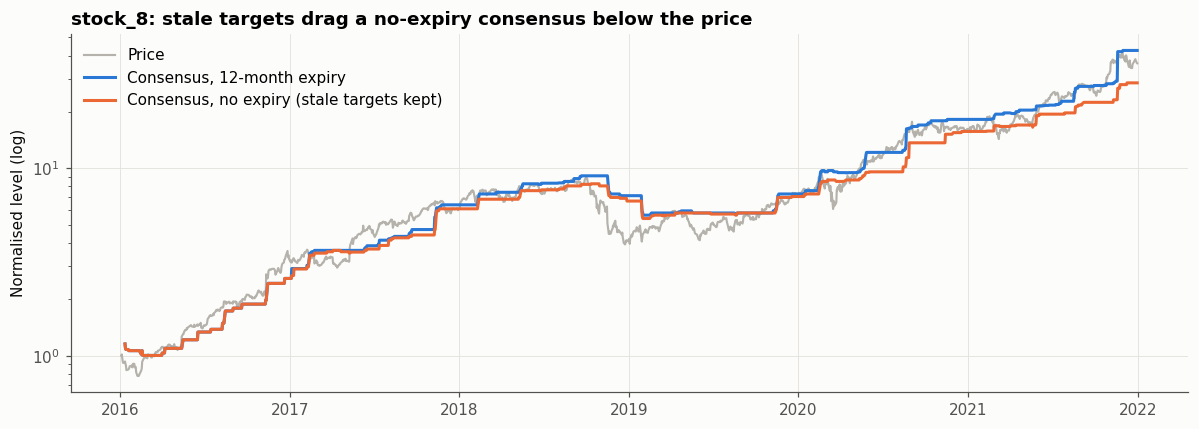

stock_8 share of sessions with NEGATIVE consensus upside: with expiry 43% | without expiry 68%


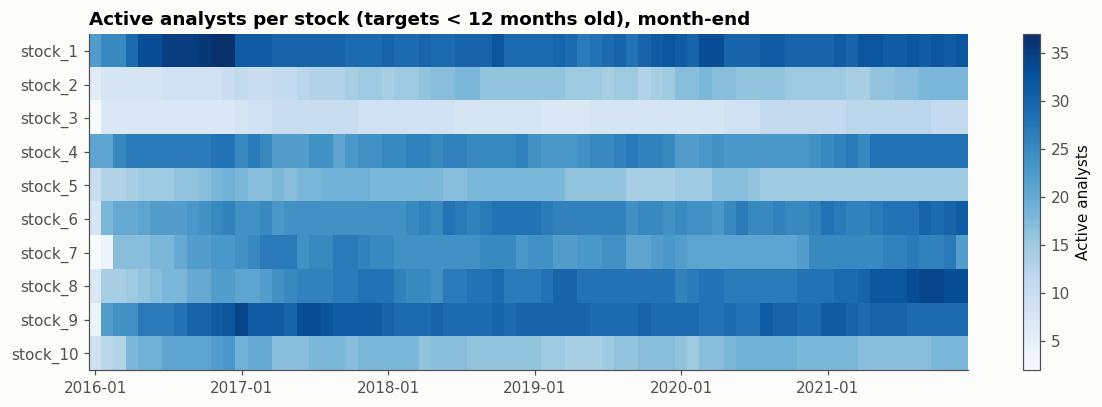

In [ ]:
#Consensus without expiry, for comparison only
no_exp_cfg = Config(tp_expiry_days=10**6)
snap_noexp = build_tp_snapshot(RT, PX.index, PX.columns, no_exp_cfg)

s = "stock_8"
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(PX.index, PX[s], color=COLORS["context"], lw=1.4, label="Price")
ax.plot(SNAP.cons_median.index, SNAP.cons_median[s], color=COLORS["blue"], lw=2, label="Consensus, 12-month expiry")
ax.plot(snap_noexp.cons_median.index, snap_noexp.cons_median[s], color=COLORS["orange"], lw=2,
        label="Consensus, no expiry (stale targets kept)")
ax.set_yscale("log"); ax.set_ylabel("Normalised level (log)")
ax.set_title(f"{s}: stale targets drag a no-expiry consensus below the price")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

upside_exp = np.log(SNAP.cons_median[s] / PX[s])
upside_noexp = np.log(snap_noexp.cons_median[s] / PX[s])
print(f"{s} share of sessions with NEGATIVE consensus upside: with expiry {(upside_exp < 0).mean():.0%} | "
      f"without expiry {(upside_noexp < 0).mean():.0%}")

#Active analysts per stock (monthly sampling)
na_m = SNAP.n_active.resample("ME").last()
fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(na_m.T.values, aspect="auto", cmap=CMAP_SEQ)
ax.set_yticks(range(na_m.shape[1])); ax.set_yticklabels(na_m.columns)
xt = np.arange(0, len(na_m), 12); ax.set_xticks(xt); ax.set_xticklabels([na_m.index[i].strftime("%Y-%m") for i in xt])
ax.grid(False); fig.colorbar(im, ax=ax, label="Active analysts")
ax.set_title("Active analysts per stock (targets < 12 months old), month-end")
plt.tight_layout(); plt.show()

For stock_8, the consensus implies a negative upside on 68 % of sessions without expiry, against 43 % with expiry. Stale targets alone would therefore have turned a strongly rising, well-covered stock into an apparently "overvalued" one. Even with expiry, analysts lag the rally 43 % of the time. This hints that raw upside partly mirrors price momentum (it falls mechanically when the price outruns the targets), a hypothesis tested in part 4 through the upside decomposition. Coverage is stable over time; stock_3 is the thinnest (about 9 analysts), so the 3-analyst minimum rarely binds.

# **4. Feature Engineering**

Rules applied to every feature:


1.   **Causality**. A feature dated t uses prices up to the close of t and analyst targets with knowledge date ≤ t, i.e. published up to t−1. Rolling windows look backward only; no statistic is estimated on the full sample.

2.   **Orientation**. Every feature is signed so that higher = higher expected return. For example, dispersion enters as negative dispersion.
3.   **Coverage**. Consensus-based features require at least 3 active analysts, revision-based features require at least 3 fresh revisions in the window.


4.   **Cross-sectional use**. Features are compared across stocks date by date (ranks), which removes common trends and makes them stationary in distribution.



Notation: $P_t$ price, $TP_{a,t}$ active target of analyst $a$, $C_t=\operatorname{median}_a TP_{a,t}$ consensus, $N_t$ active analysts, $U_t, D_t$ fresh upward / downward revisions arriving on session $t$.

In [ ]:
import pandas as pd
from IPython.display import display, Markdown

features_data = [
    # RATING-BASED FEATURES
    ["F1", "upside", "$\\log(C_t/P_t)$", "Gap between the analysts' 12-month value and the price; under-reaction if prices converge towards targets", "+"],
    ["F2", "breadth_63", "$\\frac{\\sum_{63} U-\\sum_{63} D}{\\sum_{63} U+\\sum_{63} D}$, at least 3 revisions", "Direction of the consensus, robust to magnitudes; revisions carry new information that is incorporated slowly (post-revision drift, Brav & Lehavy 2003)", "+"],
    ["F3", "cons_mom_63, cons_mom_126", "Mean over analysts active at both $t$ and $t-h$ of $\\log TP_{a,t}-\\log TP_{a,t-h}$", "Revision magnitude on a constant panel: analysts entering or leaving cannot create fake revisions", "+"],
    ["F4", "rev_recency", "Exponentially weighted (half-life $\\approx$ 21 sessions) average fresh log revision", "Recent revisions are more informative than old ones", "+"],
    ["F5", "neg_dispersion", "$-\\operatorname{std}_a(\\log TP_{a,t})$", "Disagreement predicts lower returns (Diether, Malloy & Scherbina 2002): with short-sale frictions, prices reflect the optimists", "+"],
    ["F6", "cons_change_63", "$\\log C_t-\\log C_{t-63}$", "Target-driven part of the change in upside: $\\Delta\\text{upside}=\\Delta\\log C-\\Delta\\log P$", "+"],
    ["F7", "event_breadth_63", "Breadth of revisions made on event days ($\\ge$ 5 ratings, R6), at least 2 revisions", "Revisions following earnings are the most information-rich", "+"],
    ["F8", "coverage_chg_126", "$\\log(N_t+1)-\\log(N_{t-126}+1)$", "Rising analyst attention (visibility, investor flows)", "+"],
    ["F9", "upside_z", "252-session rolling z-score of F1 (at least 126 sessions)", "Time-series view: upside unusually high for this stock, controlling for its structural level", "+"],
    # MODEL-BASED FEATURES
    ["M1", "acc_breadth_63", "F2 where each revision is weighted by its author's historical accuracy", "Listen more to analysts whose past targets were closer to realised prices", "+"],
    ["M2", "debiased_upside", "F1 computed on targets corrected for each analyst's historical optimism bias", "Removes 'permabull' analysts' structural optimism", "+"],
    ["M3", "breadth_resid_mom", "Residual of the daily cross-sectional regression of rank(F2) on rank(6-1 momentum)", "Analyst information not already contained in prices", "+"],
    # CONTROLS
    ["C1", "mom_12_1", "$\\log(P_{t-21}/P_{t-252})$", "Price momentum (control)", "+"],
    ["C2", "mom_6_1", "$\\log(P_{t-21}/P_{t-126})$", "Price momentum (control)", "+"],
    ["C3", "rev_1m", "$-\\log(P_t/P_{t-21})$", "Short-term reversal (control, Block 2.2)", "+"],
    ["C4", "low_vol_60", "$-\\operatorname{std}_{60}(r)$", "Low-volatility anomaly (control)", "+"],
    # REGIME INPUT
    ["F10", "agg_sentiment", "Cross-sectional mean of F2", "Market-wide sell-side mood (regime input)", "n/a"]
]

df_features = pd.DataFrame(features_data, columns=["ID", "Feature", "Construction", "Intuition", "Expected sign"])

display(Markdown("### Catalog of Candidate and Control Features"))
display(Markdown(df_features.to_markdown(index=False)))


### Catalog of Candidate and Control Features

| ID   | Feature                   | Construction                                                                        | Intuition                                                                                                                                               | Expected sign   |
|:-----|:--------------------------|:------------------------------------------------------------------------------------|:--------------------------------------------------------------------------------------------------------------------------------------------------------|:----------------|
| F1   | upside                    | $\log(C_t/P_t)$                                                                     | Gap between the analysts' 12-month value and the price; under-reaction if prices converge towards targets                                               | +               |
| F2   | breadth_63                | $\frac{\sum_{63} U-\sum_{63} D}{\sum_{63} U+\sum_{63} D}$, at least 3 revisions     | Direction of the consensus, robust to magnitudes; revisions carry new information that is incorporated slowly (post-revision drift, Brav & Lehavy 2003) | +               |
| F3   | cons_mom_63, cons_mom_126 | Mean over analysts active at both $t$ and $t-h$ of $\log TP_{a,t}-\log TP_{a,t-h}$  | Revision magnitude on a constant panel: analysts entering or leaving cannot create fake revisions                                                       | +               |
| F4   | rev_recency               | Exponentially weighted (half-life $\approx$ 21 sessions) average fresh log revision | Recent revisions are more informative than old ones                                                                                                     | +               |
| F5   | neg_dispersion            | $-\operatorname{std}_a(\log TP_{a,t})$                                              | Disagreement predicts lower returns (Diether, Malloy & Scherbina 2002): with short-sale frictions, prices reflect the optimists                         | +               |
| F6   | cons_change_63            | $\log C_t-\log C_{t-63}$                                                            | Target-driven part of the change in upside: $\Delta\text{upside}=\Delta\log C-\Delta\log P$                                                             | +               |
| F7   | event_breadth_63          | Breadth of revisions made on event days ($\ge$ 5 ratings, R6), at least 2 revisions | Revisions following earnings are the most information-rich                                                                                              | +               |
| F8   | coverage_chg_126          | $\log(N_t+1)-\log(N_{t-126}+1)$                                                     | Rising analyst attention (visibility, investor flows)                                                                                                   | +               |
| F9   | upside_z                  | 252-session rolling z-score of F1 (at least 126 sessions)                           | Time-series view: upside unusually high for this stock, controlling for its structural level                                                            | +               |
| M1   | acc_breadth_63            | F2 where each revision is weighted by its author's historical accuracy              | Listen more to analysts whose past targets were closer to realised prices                                                                               | +               |
| M2   | debiased_upside           | F1 computed on targets corrected for each analyst's historical optimism bias        | Removes 'permabull' analysts' structural optimism                                                                                                       | +               |
| M3   | breadth_resid_mom         | Residual of the daily cross-sectional regression of rank(F2) on rank(6-1 momentum)  | Analyst information not already contained in prices                                                                                                     | +               |
| C1   | mom_12_1                  | $\log(P_{t-21}/P_{t-252})$                                                          | Price momentum (control)                                                                                                                                | +               |
| C2   | mom_6_1                   | $\log(P_{t-21}/P_{t-126})$                                                          | Price momentum (control)                                                                                                                                | +               |
| C3   | rev_1m                    | $-\log(P_t/P_{t-21})$                                                               | Short-term reversal (control, Block 2.2)                                                                                                                | +               |
| C4   | low_vol_60                | $-\operatorname{std}_{60}(r)$                                                       | Low-volatility anomaly (control)                                                                                                                        | +               |
| F10  | agg_sentiment             | Cross-sectional mean of F2                                                          | Market-wide sell-side mood (regime input)                                                                                                               | n/a             |

Analyst-accuracy model, strictly point-in-time. A target issued with knowledge date $k$ matures at session $k+252$, when its 12-month horizon has elapsed and the realised price $P_{k+252}$ becomes known. For each matured target we record:



*   a normalised error $e=\lvert\log P_{k+252}-\log TP\rvert/\sigma_k$, where $\sigma_k$ is the stock's annualised volatility at issuance, so that errors are comparable across stocks
*   a signed bias $b=\log TP-\log P_{k+252}$ (positive = optimistic).

When a new rating of analyst $a$ arrives at knowledge date $t$, we use only targets of $a$ that matured on or before $t$, and shrink toward the pooled average with a prior weight of $n_0=5$ targets:

$$\bar e_a=\frac{\sum e+n_0\,\bar e_{\text{all}}}{n_a+n_0},\qquad w_a=\operatorname{clip}\!\left(\frac{\bar e_{\text{all}}}{\bar e_a},\,0.5,\,2\right),\qquad \hat b_a=\frac{\sum b+n_0\,\bar b_{\text{all}}}{n_a+n_0}.$$

Before any target has matured (2016), every weight is 1 and every bias is 0: M1 and M2 then reduce to F2 and F1. They become informative during 2017.



In [ ]:
#Generated by LLM
@dataclass
class FeatureSet:
    stock: dict                 # name -> sessions x stocks DataFrame (higher = better)
    market: pd.DataFrame        # sessions x market-level features
    meta: pd.DataFrame          # description table


def cs_rank(panel: pd.DataFrame, min_names: int = 5) -> pd.DataFrame:
    # Date-by-date cross-sectional percentile rank centred on 0 (NaN if too few names).
    r = panel.rank(axis=1, pct=True) - 0.5
    return r.where(panel.notna().sum(axis=1) >= min_names)


def pit_panel(events: pd.DataFrame, values: pd.Series, sessions: pd.DatetimeIndex, cfg: Config = CFG) -> pd.DataFrame:
    # Point-in-time panel (sessions x (stock, analyst)) of a rating-level value, with knowledge date and expiry.
    last = events.assign(_v=values).drop_duplicates(["knowledge_date", "stock", "analyst"], keep="last")
    wide = last.pivot(index="knowledge_date", columns=["stock", "analyst"], values="_v").reindex(sessions)
    return wide.sort_index(axis=1).ffill(limit=cfg.tp_expiry_days - 1)


def per_stock(panel: pd.DataFrame, how: str, stocks: Sequence[str]) -> pd.DataFrame:
    # Aggregate a (stock, analyst) panel across analysts, per stock.
    return getattr(panel.T.groupby(level="stock"), how)().T.reindex(columns=list(stocks))


def analyst_track_record(events: pd.DataFrame, px: pd.DataFrame, cfg: Config = CFG,
                         prior_n: float = 5.0) -> pd.DataFrame:
    # Point-in-time analyst accuracy weight and optimism bias, as known at each rating's knowledge date.
    H = cfg.tp_expiry_days
    n = len(px)
    col_idx = {c: i for i, c in enumerate(px.columns)}
    logp = np.log(px.ffill()).values
    ann_vol = (np.log(px).diff().rolling(252, min_periods=20).std() * np.sqrt(252)).values

    ev = events.reset_index(drop=True)
    ci = ev["stock"].map(col_idx).values
    kp = ev["k_pos"].values.astype(int)
    mature = kp + H
    ok = mature < n
    realised = np.full(len(ev), np.nan)
    realised[ok] = logp[mature[ok], ci[ok]]
    sigma_k = ann_vol[kp, ci]
    ev["mature_pos"] = mature
    ev["err"] = np.abs(realised - np.log(ev["tp"].values)) / sigma_k
    ev["bias"] = np.log(ev["tp"].values) - realised

    matured = (ev.loc[ok & np.isfinite(ev["err"]), ["analyst", "mature_pos", "err", "bias"]]
               .sort_values("mature_pos", kind="mergesort"))              # stable sort: deterministic ties
    # Per-analyst cumulative statistics, indexed by maturity position
    grp = matured.groupby("analyst")
    matured = matured.assign(n_a=grp.cumcount() + 1.0, s_err=grp["err"].cumsum(), s_bias=grp["bias"].cumsum())
    # Pooled cumulative statistics
    pooled = matured[["mature_pos"]].assign(
        n_all=np.arange(1, len(matured) + 1, dtype=float),
        m_err=matured["err"].cumsum().values / np.arange(1, len(matured) + 1),
        m_bias=matured["bias"].cumsum().values / np.arange(1, len(matured) + 1),
    ).drop_duplicates("mature_pos", keep="last")

    q = ev[["analyst", "k_pos"]].reset_index().sort_values("k_pos", kind="mergesort")
    q["k_pos"] = q["k_pos"].astype("int64")
    m_a = (matured[["analyst", "mature_pos", "n_a", "s_err", "s_bias"]]
           .drop_duplicates(["analyst", "mature_pos"], keep="last").copy())  # full cumulative per tie
    m_a["mature_pos"] = m_a["mature_pos"].astype("int64")
    pooled["mature_pos"] = pooled["mature_pos"].astype("int64")
    q = pd.merge_asof(q, m_a.sort_values("mature_pos", kind="mergesort"), left_on="k_pos", right_on="mature_pos",
                      by="analyst", direction="backward")
    q = pd.merge_asof(q.drop(columns="mature_pos"), pooled.sort_values("mature_pos"),
                      left_on="k_pos", right_on="mature_pos", direction="backward")
    q = q.set_index("index").sort_index()

    n_a = q["n_a"].fillna(0.0)
    e_all, b_all = q["m_err"], q["m_bias"]
    e_a = (q["s_err"].fillna(0.0) + prior_n * e_all) / (n_a + prior_n)
    b_a = (q["s_bias"].fillna(0.0) + prior_n * b_all) / (n_a + prior_n)
    out = pd.DataFrame({
        "acc_weight": (e_all / e_a).clip(0.5, 2.0).fillna(1.0),
        "bias_hat": b_a.fillna(0.0),
        "n_matured": n_a,
    }, index=ev.index)
    assert (q["mature_pos"].isna() | (q["mature_pos"] <= q["k_pos"])).all(), "look-ahead in track record"
    return out


def build_features(px: pd.DataFrame, snap: TPSnapshot, cfg: Config = CFG) -> FeatureSet:
    # All candidate features (stock level) and market-level features, strictly causal.
    stocks = list(px.columns)
    sessions = px.index
    logp = np.log(px)
    ret = px.pct_change(fill_method=None)
    enough = snap.n_active >= cfg.min_analysts
    f = {}

    # F1 upside
    f["upside"] = np.log(snap.cons_median / px)

    # F2 revision breadth
    up63, dn63 = snap.n_up.rolling(63, min_periods=1).sum(), snap.n_down.rolling(63, min_periods=1).sum()
    f["breadth_63"] = ((up63 - dn63) / (up63 + dn63)).where(up63 + dn63 >= 3)

    # F3 constant-panel consensus momentum
    log_tp = np.log(snap.tp)
    for h in (63, 126):
        d = log_tp - log_tp.shift(h)                       # NaN unless the analyst is active at t and t-h
        n_both = per_stock(d.notna().astype(float), "sum", stocks)
        f[f"cons_mom_{h}"] = per_stock(d, "mean", stocks).where(n_both >= cfg.min_analysts)

    # F4 recency-weighted revision
    alpha = 1 - 0.5 ** (1 / 21)                           # half-life 21 sessions
    n_rev = snap.n_up + snap.n_down
    f["rev_recency"] = (snap.rev_sum.ewm(alpha=alpha, adjust=False).mean()
                        / n_rev.ewm(alpha=alpha, adjust=False).mean()).where(up63 + dn63 >= 3)

    # F5 low dispersion
    f["neg_dispersion"] = -snap.dispersion

    # F6 consensus change (target-driven part of the upside change)
    f["cons_change_63"] = np.log(snap.cons_median) - np.log(snap.cons_median.shift(63))

    # F7 event-day revision breadth
    ev = snap.events
    def arrivals(mask: pd.Series, values: Optional[pd.Series] = None) -> pd.DataFrame:
        v = mask.astype(float) if values is None else values.where(mask, 0.0)
        out = ev.assign(_v=v).groupby(["knowledge_date", "stock"])["_v"].sum().unstack("stock")
        return out.reindex(index=sessions, columns=stocks).fillna(0.0)
    ev_up = arrivals((ev["kind"] == "up") & ev["event_day"]).rolling(63, min_periods=1).sum()
    ev_dn = arrivals((ev["kind"] == "down") & ev["event_day"]).rolling(63, min_periods=1).sum()
    f["event_breadth_63"] = ((ev_up - ev_dn) / (ev_up + ev_dn)).where(ev_up + ev_dn >= 2)

    # F8 coverage change
    f["coverage_chg_126"] = (np.log1p(snap.n_active) - np.log1p(snap.n_active.shift(126))).where(enough)

    # F9 upside versus own history
    roll = f["upside"].rolling(252, min_periods=126)
    f["upside_z"] = (f["upside"] - roll.mean()) / roll.std()

    # M1 accuracy-weighted breadth, M2 de-biased upside
    tr = analyst_track_record(ev, px, cfg)
    ev_w = ev.reset_index(drop=True).join(tr)
    ev_w["knowledge_date"] = ev["knowledge_date"].values
    w_up = (ev_w.assign(_v=np.where(ev_w["kind"] == "up", ev_w["acc_weight"], 0.0))
            .groupby(["knowledge_date", "stock"])["_v"].sum().unstack("stock")
            .reindex(index=sessions, columns=stocks).fillna(0.0).rolling(63, min_periods=1).sum())
    w_dn = (ev_w.assign(_v=np.where(ev_w["kind"] == "down", ev_w["acc_weight"], 0.0))
            .groupby(["knowledge_date", "stock"])["_v"].sum().unstack("stock")
            .reindex(index=sessions, columns=stocks).fillna(0.0).rolling(63, min_periods=1).sum())
    f["acc_breadth_63"] = ((w_up - w_dn) / (w_up + w_dn)).where(up63 + dn63 >= 3)

    debiased_log_tp = pit_panel(ev_w, np.log(ev_w["tp"]) - ev_w["bias_hat"], sessions, cfg)
    f["debiased_upside"] = (per_stock(debiased_log_tp, "median", stocks) - logp).where(enough)

    #Price controls
    f["mom_12_1"] = logp.shift(21) - logp.shift(252)
    f["mom_6_1"] = logp.shift(21) - logp.shift(126)
    f["rev_1m"] = -(logp - logp.shift(21))
    f["low_vol_60"] = -ret.rolling(60).std()

    # M3 breadth orthogonalised to momentum (date-by-date cross-sectional OLS on ranks)
    y, x = cs_rank(f["breadth_63"]), cs_rank(f["mom_6_1"])
    ok = y.notna() & x.notna()
    xc = x.where(ok).sub(x.where(ok).mean(axis=1), axis=0)
    yc = y.where(ok).sub(y.where(ok).mean(axis=1), axis=0)
    beta = (xc * yc).sum(axis=1) / (xc**2).sum(axis=1)
    f["breadth_resid_mom"] = yc.sub(xc.mul(beta, axis=0)).where(ok.sum(axis=1) >= 5)

    market = pd.DataFrame({"agg_sentiment": f["breadth_63"].mean(axis=1)}, index=sessions)
    for k in f:
        f[k] = f[k].replace([np.inf, -np.inf], np.nan).reindex(index=sessions, columns=stocks)
    meta = pd.DataFrame({
        "family": ["rating"] * 10 + ["analyst-model"] * 3 + ["price control"] * 4,
    }, index=["upside", "breadth_63", "cons_mom_63", "cons_mom_126", "rev_recency", "neg_dispersion",
              "cons_change_63", "event_breadth_63", "coverage_chg_126", "upside_z",
              "acc_breadth_63", "debiased_upside", "breadth_resid_mom",
              "mom_12_1", "mom_6_1", "rev_1m", "low_vol_60"])
    return FeatureSet(stock={k: f[k] for k in meta.index}, market=market, meta=meta)


FS = build_features(PX, SNAP, CFG)
FEATS = FS.stock
CANDIDATES = FS.meta.index[FS.meta["family"] != "price control"].tolist()
CONTROLS = FS.meta.index[FS.meta["family"] == "price control"].tolist()

dev = slice(CFG.dev_start, CFG.dev_end)
coverage_tbl = pd.DataFrame({
    "family": FS.meta["family"],
    "first valid date": {k: v.dropna(how="all").index.min() for k, v in FEATS.items()},
    "coverage in DEV (share of stock-days)": {k: v.loc[dev].notna().mean().mean() for k, v in FEATS.items()},
    "median (DEV)": {k: np.nanmedian(v.loc[dev].values) for k, v in FEATS.items()},
})
coverage_tbl

,family,first valid date,coverage in DEV (share of stock-days),median (DEV)
upside,rating,2016-01-07,1.0000,0.1117
breadth_63,rating,2016-01-19,0.9861,0.7931
cons_mom_63,rating,2016-04-08,1.0000,0.0417
cons_mom_126,rating,2016-07-08,1.0000,0.1022
rev_recency,rating,2016-01-19,0.9861,0.0631
neg_dispersion,rating,2016-01-07,1.0000,-0.1329
cons_change_63,rating,2016-04-08,1.0000,0.0475
event_breadth_63,rating,2016-01-19,0.7406,1.0000
coverage_chg_126,rating,2016-07-05,1.0000,0.0000
upside_z,rating,2016-07-07,1.0000,-0.0762


Coverage. Every feature is available from 2016 (12-1 momentum from January 2017), so in sample dataset is fully covered. The exception is event-day breadth (74 % of stock-days): it needs at least 2 event revisions in the window.

Absolute levels are uninformative. The medians over the in sample dataset show a systematic tilt: the consensus upside is +11 % (sell-side optimism relative to the current price) and the median revision breadth is +0.79, meaning upward revisions dominate in a rising market. This confirms that levels mostly measure the market environment and that features must be used cross-sectionally (ranks across stocks at each date).

Surprise on de-biased upside. Its median (+22 %) is higher than the raw upside

We will do some unit-test to verify the implementation:



1.   pit_panel applied to raw targets must reproduce SNAP.tp exactly: the same point-in-time logic is used everywhere


2.   The analyst track record only uses matured targets (asserted inside the function). We also report how the accuracy weights and optimism biases evolve.
3.   Truncation test: features built from data truncated at T must equal the full-sample features on all dates ≤ T, for every feature. This rules out any look-ahead in the feature code.




In [ ]:
# Consistency of the point-in-time helper with part 3
pd.testing.assert_frame_equal(pit_panel(SNAP.events, SNAP.events["tp"], PX.index, CFG), SNAP.tp, check_freq=False)

# Analyst track record
TRACK = analyst_track_record(SNAP.events, PX, CFG)
tr_view = SNAP.events.reset_index(drop=True)[["knowledge_date", "analyst"]].join(TRACK)
by_year = tr_view.groupby(tr_view["knowledge_date"].dt.year).agg(
    ratings=("acc_weight", "size"),
    share_with_track_record=("n_matured", lambda s: (s > 0).mean()),
    weight_p10=("acc_weight", lambda s: s.quantile(0.10)),
    weight_p90=("acc_weight", lambda s: s.quantile(0.90)),
    mean_optimism_bias=("bias_hat", "mean"),
)
display(by_year)


#Truncation test for every feature
def frames_equal(a: pd.DataFrame, b: pd.DataFrame, tol: float = 1e-10) -> bool:
    a, b = a.align(b, join="outer")
    both_nan = a.isna() & b.isna()
    close = (a - b).abs() <= tol * (1 + b.abs())
    return bool((both_nan | close).all().all())


for T in ["2017-09-29", "2019-06-28"]:
    T = pd.Timestamp(T)
    px_T = PX.loc[:T]
    snap_T = build_tp_snapshot(RT.loc[RT["knowledge_date"] <= T], px_T.index, px_T.columns, CFG)
    fs_T = build_features(px_T, snap_T, CFG)
    bad = [k for k in FEATS if not frames_equal(fs_T.stock[k], FEATS[k].loc[:T])]
    assert not bad, f"look-ahead detected in {bad} at T={T:%Y-%m-%d}"
    assert frames_equal(fs_T.market, FS.market.loc[:T])
print(f"All Block 4 tests passed: point-in-time helper consistent with SNAP; track record uses matured targets only; "
      f"truncation test passed for all {len(FEATS)} features + market features.")

,ratings,share_with_track_record,weight_p10,weight_p90,mean_optimism_bias
knowledge_date,,,,,
2016,826,0.0000,1.0000,1.0000,0.0000
2017,980,0.5959,0.8737,1.2076,-0.0744
2018,959,0.8446,0.6846,1.4025,-0.1748
2019,917,0.8212,0.7376,1.4120,-0.1195
2020,1192,0.8314,0.7568,1.3135,-0.0819
2021,1055,0.8521,0.7700,1.3000,-0.1328


All Block 4 tests passed: point-in-time helper consistent with SNAP; track record uses matured targets only; truncation test passed for all 17 features + market features.


All tests pass. The point-in-time helper reproduces the part 3 snapshot exactly, the analyst track record only uses matured targets, and the truncation test holds for all 17 features plus the market feature.

Analysts were systematically too pessimistic in this bull market. The average estimated bias is negative (−0.07 to −0.17 in log terms): 12 months later, the realised price was on average 7–17 % above the target. This explains why de-biasing raises the upside (median +22 % versus +11 %).

The track record becomes informative in 2017. The share of new ratings whose author has at least one matured target rises from 0 % (2016) to 60 % (2017) and above 80 % from 2018. The accuracy weights then spread from about 0.7 (10th percentile) to 1.4 (90th percentile).

Pooled Spearman correlations of the date-by-date ranks over the in sample dataset period. Highly correlated features carry the same information and must not be counted twice in a composite. The correlation of rating features with the price controls (momentum, reversal) matters most: a revision feature that is merely a lagged image of past returns would add nothing that prices do not already contain.

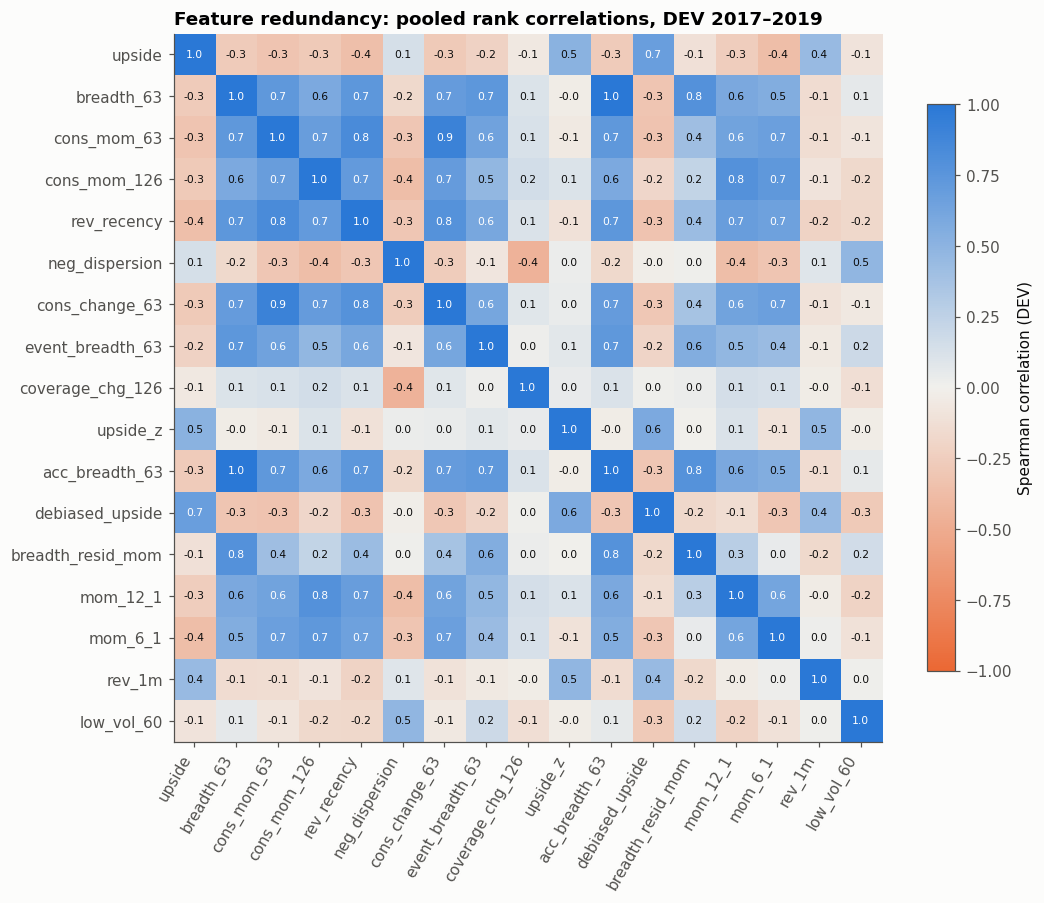

,mom_12_1,mom_6_1,rev_1m,low_vol_60
upside,-0.2600,-0.3600,0.4400,-0.0900
breadth_63,0.5900,0.5500,-0.1400,0.0600
cons_mom_63,0.6400,0.6700,-0.1400,-0.0900
cons_mom_126,0.7800,0.7300,-0.0900,-0.1700
rev_recency,0.6800,0.6500,-0.2000,-0.1700
neg_dispersion,-0.3600,-0.3100,0.0900,0.4800
cons_change_63,0.6300,0.6700,-0.1000,-0.0600
event_breadth_63,0.4700,0.4300,-0.0500,0.1800
coverage_chg_126,0.1400,0.1300,-0.0300,-0.1300
upside_z,0.1200,-0.0900,0.4800,-0.0300


In [ ]:
ranked_dev = {k: cs_rank(v).loc[dev] for k, v in FEATS.items()}
stacked = pd.DataFrame({k: v.values.ravel() for k, v in ranked_dev.items()})
CORR_DEV = stacked.corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8.2))
im = ax.imshow(CORR_DEV.values, cmap=CMAP_DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(CORR_DEV))); ax.set_xticklabels(CORR_DEV.columns, rotation=60, ha="right")
ax.set_yticks(range(len(CORR_DEV))); ax.set_yticklabels(CORR_DEV.index)
for i in range(len(CORR_DEV)):
    for j in range(len(CORR_DEV)):
        v = CORR_DEV.values[i, j]
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7,
                color="white" if abs(v) > 0.6 else COLORS["ink"])
ax.grid(False); fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman correlation (DEV)")
ax.set_title("Feature redundancy: pooled rank correlations, DEV 2017–2019")
plt.tight_layout(); plt.show()

display(CORR_DEV.loc[CANDIDATES, CONTROLS].round(2))

Revision features form one tight family (pairwise correlations 0.6–1.0) and are strongly correlated with price momentum (0.55–0.78 with 12-1 momentum): analysts revise in the direction of past price moves, consistent with the reactive timing already found. Any claim that revisions add value must therefore be tested net of momentum (Fama-MacBeth). The orthogonalised breadth M3 is uncorrelated with 6-1 momentum by construction (0.04) and only weakly correlated with 12-1 momentum (0.28).

Accuracy weighting leaves the ranking unchanged. Accuracy-weighted breadth has a rank correlation of 1.0 with plain breadth

Upside is partly a mechanical price effect. It is negatively correlated with momentum (−0.26 / −0.36) and positively with 1-month reversal (+0.44): when the price outruns the targets, upside falls mechanically, as anticipated in part 3

Dispersion behaves like a volatility measure (correlation 0.48 with low volatility)

# **5. Feature Evaluation & Selection (In Sample DEV period only)**

Here we will decide, with proper statistics and before building any strategy, which rating-based features carry predictive information about the cross-section of future returns.



*   **Evaluation window**: feature dates in DEV (2017–2019) whose label also ends inside DEV (the last h sessions are purged), so not a single holdout return is used.

*   **Labels**: forward log returns from the close of t to the close of t+h, $y_{t,h}=\log(P_{t+h}/P_t)$, for $h\in\{5,21,63\}$. The feature at t only uses targets published up to t−1 and prices up to t, so there is no contemporaneous contamination.
*   **Primary horizon**: 21 sessions (monthly), consistent with weekly rebalancing of a slow signal. 5 and 63 sessions are reported for the decay profile.

Statistics per feature:



*   **Daily rank IC** (Spearman correlation between the feature and forward returns across stocks) and its mean, with a Newey-West t-statistic (lags = h).

*   **IC stability by year**.

*   **Stationarity of the raw feature** (ADF + KPSS, per stock) and of the IC series.
*   **Rank autocorrelation** (signal persistence, i.e. implied turnover).


*   **Top-3 / bottom-3 long/short spread** (weekly rebalanced, equal weight, dollar-neutral): an economic, not just statistical, check.


*   **Fama-MacBeth regressions with price controls**: does the feature survive momentum, reversal and low volatility?

*   **Multiple testing**: Holm correction across the candidate features, and a running count of trials (for the Deflated Sharpe Ratio in part 12).

Pre-registered selection rule: a candidate is selected if (i) mean IC21 > 0 with a Newey-West t-stat > 1, (ii) IC21 is positive in at least 2 of the 3 DEV years, and (iii) its correlation with every already-selected feature is below 0.8 (candidates are processed in decreasing order of t-stat), with at most 3 features. The composite signal is the equal-weighted average of the selected features' cross-sectional ranks: no estimated weights, hence no overfitting of weights. A t-stat threshold of 1 is deliberately lenient: with 10 stocks the IC is very noisy, and selection is then disciplined by stability and economics rather than by a single p-value.



In [ ]:
POS = pd.Series(np.arange(len(PX)), index=PX.index)
DEV_END_POS = int(POS.loc[:CFG.dev_end].iloc[-1])
HORIZONS = (5, 21, 63)
N_TRIALS = 0                                            # running count of evaluated configurations


def forward_log_return(px: pd.DataFrame, h: int) -> pd.DataFrame:
    """
    LABEL (forward-looking by design): log return from close t to close t+h.
    """
    return np.log(px.shift(-h) / px)


def eval_dates(h: int) -> pd.DatetimeIndex:
    """
    DEV feature dates whose h-session label ends inside DEV (purged).
    """
    d = PX.loc[CFG.dev_start:CFG.dev_end].index
    return d[POS.loc[d].values + h <= DEV_END_POS]


def rank_ic(feature: pd.DataFrame, fwd: pd.DataFrame, min_names: int = 6) -> pd.Series:
    """
    Daily cross-sectional Spearman correlation between feature and forward returns.
    """
    ok = feature.notna() & fwd.notna()
    fr, yr = feature.where(ok).rank(axis=1), fwd.where(ok).rank(axis=1)
    fc, yc = fr.sub(fr.mean(axis=1), axis=0), yr.sub(yr.mean(axis=1), axis=0)
    ic = (fc * yc).sum(axis=1) / np.sqrt((fc**2).sum(axis=1) * (yc**2).sum(axis=1))
    return ic.where(ok.sum(axis=1) >= min_names)


FWD = {h: forward_log_return(PX, h) for h in (1, 2, 5, 10, 21, 42, 63)}


def ic_summary(feature: pd.DataFrame, h: int) -> dict:
    ic = rank_ic(feature.loc[eval_dates(h)], FWD[h].loc[eval_dates(h)]).dropna()
    m, t = newey_west_tstat(ic, lags=h)
    by_year = ic.groupby(ic.index.year).mean()
    return {"IC": m, "t_NW": t, "hit": (ic > 0).mean(), "n_days": len(ic),
            "years_pos": int((by_year > 0).sum()), **{f"IC {y}": v for y, v in by_year.items()}}


rows = []
for name, feat in FEATS.items():
    for h in HORIZONS:
        rows.append({"feature": name, "family": FS.meta.at[name, "family"], "h": h, **ic_summary(feat, h)})
        N_TRIALS += 1
IC_TBL = pd.DataFrame(rows).set_index(["feature", "h"])
ic21 = IC_TBL.xs(21, level="h").sort_values("t_NW", ascending=False)
display(ic21)

,family,IC,t_NW,hit,n_days,years_pos,IC 2017,IC 2018,IC 2019
feature,,,,,,,,,
breadth_resid_mom,analyst-model,0.0831,2.0263,0.5553,733,2,0.0721,0.1822,-0.0125
event_breadth_63,rating,0.0852,1.7271,0.5762,689,2,0.2003,0.0752,-0.0370
breadth_63,rating,0.0724,1.4958,0.6126,733,2,0.1540,0.1003,-0.0466
acc_breadth_63,analyst-model,0.0678,1.4114,0.6044,733,2,0.1591,0.0866,-0.0519
mom_12_1,price control,0.0501,0.9224,0.5921,733,2,0.1702,0.0260,-0.0541
cons_mom_126,rating,0.0315,0.5871,0.5798,733,1,0.1428,-0.0071,-0.0476
low_vol_60,price control,0.0241,0.4782,0.5211,733,2,0.0827,0.0287,-0.0445
cons_mom_63,rating,0.0121,0.2270,0.5512,733,1,0.1105,-0.0289,-0.0504
rev_recency,rating,0.0053,0.0942,0.5362,733,2,0.1066,0.0193,-0.1201


The revision-breadth family dominates. Orthogonalised breadth (IC 0.083, NW t = 2.03), event-day breadth (0.085, t = 1.73), plain breadth (0.072, t = 1.50) and accuracy-weighted breadth (0.068, t = 1.41) all outperform 12-1 momentum (0.050, t = 0.92).

Their weakness is common: 2019. All breadth features are strongly positive in 2017 and 2018 and slightly negative in 2019.

Level-based features fail, confirming the literature: consensus upside: IC ≈ 0, negative in 2017–2018 and positive in 2019, de-biased upside: −0.028, low dispersion: −0.056.

Revision magnitudes are much weaker than revision direction (constant-panel momentum IC 0.01–0.03): the sign of revisions is more robust than their size, which is noisy and outlier-prone.

,share of stocks stationary,IC21 series ADF p,rank autocorr (5),rank autocorr (21)
feature,,,,
breadth_resid_mom,0.6000,0.0000,0.7764,0.4527
event_breadth_63,0.0000,0.0000,0.8596,0.5932
breadth_63,0.0000,0.0000,0.9202,0.6911
acc_breadth_63,0.0000,0.0000,0.9183,0.6873
mom_12_1,0.0000,0.0001,0.9131,0.7369
cons_mom_126,0.0000,0.0001,0.9398,0.7940
low_vol_60,0.1000,0.0000,0.8654,0.6372
cons_mom_63,0.1000,0.0000,0.9097,0.6585
rev_recency,0.1000,0.0000,0.9172,0.6999


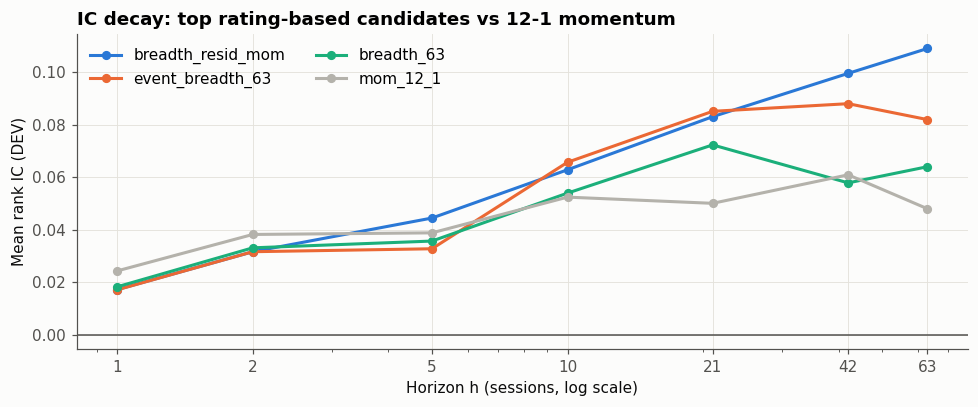

In [ ]:
persist_rows = {}
for name, feat in FEATS.items():
    fd = feat.loc[dev]

    # Safeguard: filter out columns that are constant before calling adfuller
    valid_cols = []
    for col in fd.columns:
        col_data = fd[col].dropna()
        if len(col_data) >= 50 and col_data.nunique() > 1:
            valid_cols.append(col)

    if len(valid_cols) > 0:
        st = stationarity_table(fd[valid_cols], regression="c")
        share_stationary = (st["verdict"] == "stationary").mean()
    else:
        share_stationary = np.nan

    r = cs_rank(fd)
    ac5 = r.corrwith(r.shift(5), axis=0).mean()
    ac21 = r.corrwith(r.shift(21), axis=0).mean()
    ic = rank_ic(feat.loc[eval_dates(21)], FWD[21].loc[eval_dates(21)]).dropna()

    # Safeguard for constant IC series
    if len(ic) >= 50 and ic.nunique() > 1:
        adf_p = adfuller(ic, autolag="AIC")[1]
    else:
        adf_p = np.nan

    persist_rows[name] = {
        "share of stocks stationary": share_stationary,
        "IC21 series ADF p": adf_p,
        "rank autocorr (5)": ac5,
        "rank autocorr (21)": ac21
    }

PERSIST = pd.DataFrame(persist_rows).T
display(PERSIST.loc[ic21.index])

decay_h = [1, 2, 5, 10, 21, 42, 63]
top_cands = ic21.loc[ic21.index.isin(CANDIDATES)].index[:3].tolist()
decay = pd.DataFrame({name: [rank_ic(FEATS[name].loc[eval_dates(h)], FWD[h].loc[eval_dates(h)]).mean()
                             for h in decay_h] for name in top_cands + ["mom_12_1"]}, index=decay_h)
fig, ax = plt.subplots(figsize=(9, 3.8))
palette = [COLORS["blue"], COLORS["orange"], COLORS["aqua"], COLORS["context"]]
for (name, col), c in zip(decay.items(), palette):
    ax.plot(decay.index, col.values, marker="o", ms=5, color=c, lw=2, label=name)
ax.axhline(0, color=COLORS["muted"], lw=1)
ax.set_xscale("log"); ax.set_xticks(decay_h); ax.set_xticklabels(decay_h)
ax.set_xlabel("Horizon h (sessions, log scale)"); ax.set_ylabel("Mean rank IC (DEV)")
ax.set_title("IC decay: top rating-based candidates vs 12-1 momentum")
ax.legend(loc="upper left", ncol=2); plt.tight_layout(); plt.show()

Raw feature levels rarely pass the ADF + KPSS test stock by stock. They are bounded but highly persistent over a 3-year window, where both tests have low power. This is precisely why features are used as cross-sectional ranks. The IC series themselves are stationary (ADF p ≤ 0.0001 for every feature), so inference on the mean IC is valid.

Rank autocorrelations are 0.78–0.92 at 5 sessions and 0.45–0.69 at 21 sessions: slow signals, so weekly rebalancing loses almost nothing and implies moderate turnover. The 1-month reversal is the only fast signal (≈ 0 at 21 sessions).

The breadth ICs increase with the horizon, from about 0.02 at 1 session to 0.08–0.11 at 21–63 sessions, while momentum plateaus around 0.05. This is the signature of slowly diffusing information (post-revision drift) and supports a monthly prediction horizon with weekly rebalancing.

In [ ]:
def ls_spread(score: pd.DataFrame, ret: pd.DataFrame, k: int = 3, freq: int = 5) -> pd.Series:
    # Daily returns of a weekly-rebalanced, equal-weight top-k / bottom-k dollar-neutral portfolio.
    valid = score.notna().sum(axis=1) >= 2 * k
    r_desc = score.rank(axis=1, ascending=False, method="first")
    r_asc = score.rank(axis=1, ascending=True, method="first")
    w = (r_desc <= k).astype(float) / (2 * k) - (r_asc <= k).astype(float) / (2 * k)
    w = w.mul(valid.astype(float), axis=0)
    rebal = np.arange(len(w)) % freq == 0
    w.loc[~rebal] = np.nan
    w = w.ffill().fillna(0.0)                                       # hold between rebalances (forward only)
    return (w.shift(1) * ret).sum(axis=1)


spread_rows = {}
SPREADS = {}
for name, feat in FEATS.items():
    r = ls_spread(feat, RET).loc[dev]
    SPREADS[name] = r
    s = perf_stats(r)
    spread_rows[name] = {"CAGR": s["CAGR"], "Sharpe": s["Sharpe"], "Max drawdown": s["Max drawdown"],
                         "CAGR / MaxDD": s["CAGR / MaxDD"]}
    N_TRIALS += 1
SPREAD_TBL = pd.DataFrame(spread_rows).T
display(SPREAD_TBL.loc[ic21.index])

,CAGR,Sharpe,Max drawdown,CAGR / MaxDD
feature,,,,
breadth_resid_mom,0.0485,0.4988,-0.1942,0.2497
event_breadth_63,-0.0217,-0.1916,-0.1474,-0.1473
breadth_63,0.0162,0.2011,-0.2677,0.0604
acc_breadth_63,0.0160,0.1995,-0.2686,0.0596
mom_12_1,0.0751,0.6550,-0.1658,0.4530
cons_mom_126,0.0099,0.1420,-0.2307,0.0427
low_vol_60,-0.0429,-0.3337,-0.1987,-0.2158
cons_mom_63,-0.0271,-0.1718,-0.2642,-0.1027
rev_recency,-0.0149,-0.0584,-0.2945,-0.0505


With 10 stocks, a positive IC does not reliably translate into a top-3 / bottom-3 spread:



*   Event-day breadth has one of the best ICs (0.085) but a negative spread (Sharpe −0.19). The ranking is right on average but the extremes are noisy.

*   Orthogonalised breadth has the best spread among candidates (Sharpe 0.50).
*   12-1 momentum reaches 0.66 over DEV.


*   Coverage change shows a positive spread despite a negative IC: a reminder of how noisy single-feature, 3-name spreads are.





Every 5 sessions (to limit overlap), we run the cross-sectional regression

$$\tilde y_{i,t\to t+21}=a_t+b_t\,\text{rank}(F_{i,t})+c_t\,\text{rank}(\text{mom}_{12\text{-}1})+d_t\,\text{rank}(\text{rev}_{1m})+e_t\,\text{rank}(\text{lowvol})+\varepsilon_{i,t},$$

where $\tilde y$ is the cross-sectionally demeaned forward return. The time series of $b_t$ is averaged and tested with Newey-West (5 lags ≈ 21 sessions of overlap). The table reports $b$ with and without controls. A feature whose $b$ collapses once momentum is controlled for is a disguised price signal. Holm-adjusted p-values correct the univariate IC tests for the number of candidates tested.

In [ ]:
def fama_macbeth(feature: pd.DataFrame, controls: Sequence[str], h: int = 21, step: int = 5,
                 min_names: int = 8) -> tuple[float, float]:
    # Mean Fama-MacBeth slope of rank(feature) and its Newey-West t-stat (DEV, purged dates).
    dates = eval_dates(h)[::step]
    y = FWD[h].loc[dates]
    y = y.sub(y.mean(axis=1), axis=0)
    X_parts = [cs_rank(feature).loc[dates]] + [cs_rank(FEATS[c]).loc[dates] for c in controls]
    slopes = []
    for d in dates:                                             # one small OLS per cross-section (10 stocks)
        cols = [p.loc[d] for p in X_parts]
        M = pd.concat([y.loc[d]] + cols, axis=1).dropna()
        if len(M) < min_names:
            continue
        X = np.column_stack([np.ones(len(M))] + [M.iloc[:, j].values for j in range(1, M.shape[1])])
        beta, *_ = np.linalg.lstsq(X, M.iloc[:, 0].values, rcond=None)
        slopes.append(beta[1])
    slopes = pd.Series(slopes)
    return newey_west_tstat(slopes, lags=5)


fm_rows = {}
for name in CANDIDATES:
    b0, t0 = fama_macbeth(FEATS[name], [])
    b1, t1 = fama_macbeth(FEATS[name], ["mom_12_1", "rev_1m", "low_vol_60"])
    fm_rows[name] = {"FM slope (alone)": b0, "t (alone)": t0, "FM slope (with controls)": b1, "t (with controls)": t1}
    N_TRIALS += 2
FM_TBL = pd.DataFrame(fm_rows).T

# Holm correction on the one-sided IC21 tests of the candidates
p_one = pd.Series(stats.norm.sf(ic21.loc[CANDIDATES, "t_NW"]), index=CANDIDATES).sort_values()
m = len(p_one)
holm = pd.Series(np.maximum.accumulate([(m - i) * p for i, p in enumerate(p_one.values)]).clip(max=1), index=p_one.index)
FM_TBL["IC21 p (one-sided)"] = p_one
FM_TBL["IC21 p (Holm)"] = holm
display(FM_TBL.loc[ic21.index[ic21.index.isin(CANDIDATES)]])
print(f"Trials so far (feature x horizon ICs, spreads, FM regressions): {N_TRIALS}")

,FM slope (alone),t (alone),FM slope (with controls),t (with controls),IC21 p (one-sided),IC21 p (Holm)
feature,,,,,,
breadth_resid_mom,0.0184,1.7266,0.0206,2.1526,0.0214,0.2778
event_breadth_63,0.0059,0.2800,0.0293,1.0223,0.0421,0.5049
breadth_63,0.0118,0.8698,0.0164,1.1581,0.0674,0.7409
acc_breadth_63,0.0113,0.8386,0.0156,1.0953,0.0791,0.7906
cons_mom_126,0.0081,0.5403,-0.0128,-0.3768,0.2786,1.0000
cons_mom_63,-0.0060,-0.3948,-0.0087,-0.4563,0.4102,1.0000
rev_recency,-0.0019,-0.1155,0.0094,0.4226,0.4625,1.0000
upside,0.0056,0.4671,0.0092,0.5103,0.4866,1.0000
cons_change_63,-0.0118,-0.7724,-0.0324,-1.4872,0.6592,1.0000


Trials so far (feature x horizon ICs, spreads, FM regressions): 94


Revision information survives price controls. The Fama-MacBeth slope of orthogonalised breadth is significant with controls (t = 2.15). The slopes of plain breadth and event-day breadth increase once momentum, reversal and low volatility are controlled for (t ≈ 1.0–1.2): analyst revisions are not subsumed by price momentum

Honest caveat. After the Holm correction across the 13 candidates, no single feature is significant at conventional levels (smallest adjusted p = 0.28). With 10 stocks and 3 years, individual evidence is weak. The case for the revision signal rests on three things together:


*   consistency across several related measures

*   the prior evidence in the literature
*   robustness to controls.

The robustness block (placebo, bootstrap, Deflated Sharpe Ratio) will quantify this further. 94 trials have been logged so far.




Selected features: ['breadth_resid_mom', 'event_breadth_63', 'breadth_63']


,IC5,IC21,t_NW(21),IC63,IC21 2017,IC21 2018,IC21 2019,L/S Sharpe,L/S CAGR / MaxDD
breadth_resid_mom,0.0445,0.0831,2.0263,0.1091,0.0721,0.1822,-0.0125,0.4988,0.2497
event_breadth_63,0.0328,0.0852,1.7271,0.0820,0.2003,0.0752,-0.0370,-0.1916,-0.1473
breadth_63,0.0358,0.0724,1.4958,0.0641,0.1540,0.1003,-0.0466,0.2011,0.0604
COMPOSITE,0.0461,0.0939,2.1493,0.1002,0.1563,0.1386,-0.0225,0.5974,0.2964
mom_12_1,0.0389,0.0501,0.9224,0.0481,0.1702,0.0260,-0.0541,0.6550,0.4530


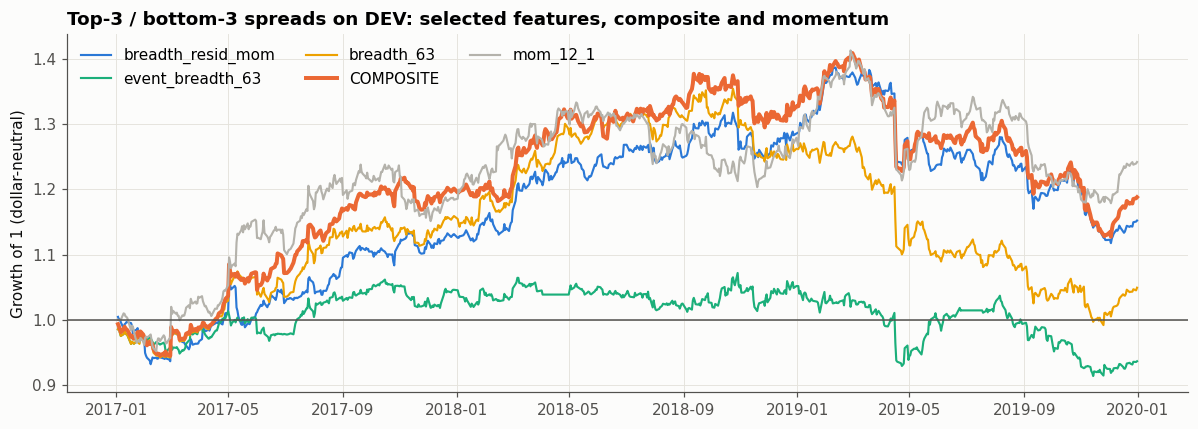

In [ ]:
def select_features(ic_tbl21: pd.DataFrame, corr: pd.DataFrame, candidates: Sequence[str],
                    t_min: float = 1.0, years_min: int = 2, corr_max: float = 0.8, max_n: int = 3) -> list:
    # Pre-registered greedy selection: significance, stability, non-redundancy.
    pool = ic_tbl21.loc[ic_tbl21.index.isin(candidates)].sort_values("t_NW", ascending=False)
    eligible = pool[(pool["IC"] > 0) & (pool["t_NW"] > t_min) & (pool["years_pos"] >= years_min)]
    chosen = []
    for name in eligible.index:
        if all(abs(corr.loc[name, c]) < corr_max for c in chosen):
            chosen.append(name)
        if len(chosen) == max_n:
            break
    if not chosen:                                              # documented fallback
        chosen = [pool.index[0]]
    return chosen


def composite_score(feats: dict, names: Sequence[str]) -> pd.DataFrame:
    # Equal-weighted average of cross-sectional ranks (no estimated weights).
    return pd.concat([cs_rank(feats[n]) for n in names]).groupby(level=0).mean().reindex(PX.index)


SELECTED = select_features(ic21, CORR_DEV, CANDIDATES)
COMPOSITE = composite_score(FEATS, SELECTED)
FEATS_EVAL = {**{n: FEATS[n] for n in SELECTED}, "COMPOSITE": COMPOSITE, "mom_12_1": FEATS["mom_12_1"]}

comp_rows = {}
for name, feat in FEATS_EVAL.items():
    s21, s5, s63 = ic_summary(feat, 21), ic_summary(feat, 5), ic_summary(feat, 63)
    sp = perf_stats(ls_spread(feat, RET).loc[dev])
    comp_rows[name] = {"IC5": s5["IC"], "IC21": s21["IC"], "t_NW(21)": s21["t_NW"], "IC63": s63["IC"],
                       "IC21 2017": s21.get("IC 2017"), "IC21 2018": s21.get("IC 2018"), "IC21 2019": s21.get("IC 2019"),
                       "L/S Sharpe": sp["Sharpe"], "L/S CAGR / MaxDD": sp["CAGR / MaxDD"]}
N_TRIALS += 1
print(f"Selected features: {SELECTED}")
display(pd.DataFrame(comp_rows).T)

fig, ax = plt.subplots(figsize=(11, 4))
others = iter([COLORS["blue"], COLORS["aqua"], "#eda100"])
for name in FEATS_EVAL:
    eq = (1 + ls_spread(FEATS_EVAL[name], RET).loc[dev]).cumprod()
    color = COLORS["orange"] if name == "COMPOSITE" else COLORS["context"] if name == "mom_12_1" else next(others)
    ax.plot(eq.index, eq.values, lw=2.6 if name == "COMPOSITE" else 1.4, color=color, label=name)
ax.axhline(1, color=COLORS["muted"], lw=1)
ax.set_ylabel("Growth of 1 (dollar-neutral)"); ax.set_title("Top-3 / bottom-3 spreads on DEV: selected features, composite and momentum")
ax.legend(loc="upper left", ncol=3); plt.tight_layout(); plt.show()

The pre-registered rule selects breadth_resid_mom, event_breadth_63 and breadth_63: all measure the direction of analyst revisions, overall, after earnings events, and net of price momentum. Every level-based feature is rejected.

Composite. IC21 = 0.094 (NW t = 2.15), IC63 = 0.10, positive in 2017 and 2018 and slightly negative in 2019 (−0.02). Its top-3 / bottom-3 spread has a Sharpe of 0.60 and a CAGR/MaxDD of 0.30, better than each selected feature alone.

Common drawdown. All spreads peak in early 2019 and give back part of their gains during 2019, the weak year for revision signals.

Redundancy. The composite contains both plain breadth and its momentum-orthogonalised version (correlation 0.8 in the pooled ranks, just at the threshold). The rule allows it, and in effect it gives extra weight to the part of breadth not explained by prices.

# **6. Risk & Regime Models**

We will use two model-based features inputs for portfolio construction:


1.   **Volatility forecasts** $\hat\sigma_{i,t+1\mid t}$ for each stock (GJR-GARCH(1,1)-t, justified in part 2), used to size positions inside each leg (in part 9).
2.   **Market regime**: a hidden Markov model detecting calm and turbulent states, combined with a trend filter, used to tilt the net exposure of the long/short book (part 9).

Walk-forward estimation, no look-ahead. Both models are re-estimated every 21 sessions on an expanding window that ends at the estimation date. Between re-estimations, the latest parameters are applied to new data as they arrive. The forecast or probability dated t therefore depends only on returns up to the close of t. A truncation unit test that we will conduct proves it.


GJR-GARCH(1,1)-t volatility forecasts:

For each stock, at re-estimation date $s$ (every 21 sessions, from 250 observations onwards), the model

$$r_t=\mu+\varepsilon_t,\quad \varepsilon_t=\sigma_t z_t,\ z_t\sim t_\nu,\qquad \sigma_t^2=\omega+(\alpha+\gamma\,\mathbb 1_{\varepsilon_{t-1}<0})\,\varepsilon_{t-1}^2+\beta\,\sigma_{t-1}^2$$

is fitted by maximum likelihood (arch) on returns up to $s$. The variance recursion is then run with these fixed parameters to produce the one-step-ahead forecast $\hat\sigma^2_{t+1\mid t}$ for every $t$ in $[s, s+21)$. Safeguards: if an estimation fails or yields a non-stationary model ($\alpha+\gamma/2+\beta\ge1$), the previous parameters are kept; before the first estimation, the forecast is the expanding historical volatility.


Forecasts are compared with a 60-session historical volatility and a RiskMetrics EWMA (λ = 0.94) using the QLIKE loss $L=\log\hat\sigma^2+r^2/\hat\sigma^2$. QLIKE is robust to noise in the volatility proxy (Patton, 2011). Differences are tested with Diebold-Mariano (Newey-West t-stat of the loss differential). (Generated by an LLM)

In [ ]:
def gjr_variance_path(x: np.ndarray, mu: float, omega: float, alpha: float, gamma: float, beta: float,
                      sigma2_0: float) -> np.ndarray:
    # s2[t] = Var(x_t | x_<t); s2[t+1] is the forecast made after observing x_t (recursion, O(n)).
    eps = x - mu
    s2 = np.empty(len(x) + 1)
    s2[0] = sigma2_0
    for t in range(len(x)):
        s2[t + 1] = omega + (alpha + gamma * (eps[t] < 0)) * eps[t] ** 2 + beta * s2[t]
    return s2


def garch_forecast_panel(ret: pd.DataFrame, cfg: Config = CFG) -> tuple[pd.DataFrame, pd.DataFrame]:
    # Walk-forward GJR-GARCH(1,1)-t: value at t = forecast of the daily vol of r_{t+1}, using returns <= t.
    out = pd.DataFrame(np.nan, index=ret.index, columns=ret.columns)
    param_log = []
    for c in ret.columns:
        s = ret[c].dropna()
        x = s.values * 100.0
        n = len(x)
        fc = np.full(n, np.nan)
        # Before the first estimation: expanding historical volatility (causal)
        exp_sd = pd.Series(x).expanding(min_periods=20).std().values
        fc[:min(cfg.garch_min_obs, n)] = exp_sd[:min(cfg.garch_min_obs, n)]
        params = None
        for st in range(cfg.garch_min_obs - 1, n, cfg.garch_refit):
            train = x[: st + 1]                                           # data known at the close of st
            try:
                res = arch_model(train, mean="Constant", vol="GARCH", p=1, o=1, q=1, dist="t").fit(disp="off")
                p = res.params
                cand = (p["mu"], p["omega"], p["alpha[1]"], p["gamma[1]"], p["beta[1]"])
                if res.convergence_flag == 0 and cand[2] + cand[3] / 2 + cand[4] < 1:
                    params = cand
            except Exception:
                pass
            end = min(st + cfg.garch_refit, n)
            if params is None:
                fc[st:end] = exp_sd[st:end]
                continue
            s2 = gjr_variance_path(x[:end], *params, sigma2_0=train.var())
            fc[st:end] = np.sqrt(s2[st + 1:end + 1])                     # forecast for t+1 made at t
            param_log.append({"stock": c, "fit_date": s.index[st], "mu": params[0], "omega": params[1],
                              "alpha": params[2], "gamma": params[3], "beta": params[4]})
        out.loc[s.index, c] = fc / 100.0
    return out, pd.DataFrame(param_log)


SIG_GJR, GARCH_PARAMS = garch_forecast_panel(RET, CFG)
SIG_HIST = RET.rolling(60).std()                                  # forecast for t+1 made at t
SIG_EWMA = np.sqrt((RET**2).ewm(alpha=0.06, adjust=False).mean())


def qlike(sig: pd.DataFrame, realised: pd.DataFrame) -> pd.DataFrame:
    # QLIKE loss of variance forecasts (forecast at t for return t+1).
    v = (sig**2).shift(1)                                         # align forecast made at t-1 with r_t
    return np.log(v) + realised**2 / v


dev_idx = PX.loc[CFG.dev_start:CFG.dev_end].index
L = {name: qlike(sig, RET).loc[dev_idx] for name, sig in
     [("GJR-GARCH-t", SIG_GJR), ("Historical 60d", SIG_HIST), ("EWMA 0.94", SIG_EWMA)]}
ql_tbl = pd.DataFrame({k: v.mean() for k, v in L.items()})
ql_tbl.loc["ALL (pooled)"] = [np.nanmean(v.values) for v in L.values()]
dm = {}
for c in list(RET.columns):
    d = (L["GJR-GARCH-t"][c] - L["Historical 60d"][c]).dropna()
    dm[c] = newey_west_tstat(d, lags=5)[1]
dm["ALL (pooled)"] = newey_west_tstat((L["GJR-GARCH-t"] - L["Historical 60d"]).mean(axis=1).dropna(), lags=5)[1]
ql_tbl["DM t (GJR - Hist; <0 = GJR better)"] = pd.Series(dm)
display(ql_tbl)
print(f"GJR beats 60d historical volatility (lower QLIKE) for {(ql_tbl.iloc[:-1, 0] < ql_tbl.iloc[:-1, 1]).sum()} / {len(RET.columns)} stocks")

# Residual diagnostics: does the forecast absorb volatility clustering?
z = (RET / SIG_GJR.shift(1)).loc[dev_idx]
lb_raw = {c: acorr_ljungbox(RET[c].loc[dev_idx].dropna()**2, lags=[10])["lb_pvalue"].iloc[0] for c in RET}
lb_std = {c: acorr_ljungbox(z[c].dropna()**2, lags=[10])["lb_pvalue"].iloc[0] for c in RET}
display(pd.DataFrame({"LB(10) p on r²": lb_raw, "LB(10) p on z² (GJR-standardised)": lb_std}).T)

,GJR-GARCH-t,Historical 60d,EWMA 0.94,DM t (GJR - Hist; <0 = GJR better)
stock,,,,
stock_1,-7.4575,-7.3219,-7.3331,-2.2163
stock_2,-7.1393,-7.1074,-7.0761,-0.8586
stock_3,-6.1807,-5.9050,-5.8285,-2.1415
stock_4,-7.1710,-7.1529,-7.1686,-0.3038
stock_5,-7.8419,-7.8101,-7.7999,-0.8602
stock_6,-7.7507,-7.6444,-7.6774,-2.5118
stock_7,-7.3572,-7.1900,-7.2077,-3.6921
stock_8,-6.2646,-6.1788,-6.1960,-1.7435
stock_9,-6.7083,-6.2978,-6.2898,-1.4270


GJR beats 60d historical volatility (lower QLIKE) for 10 / 10 stocks


,stock_1,stock_2,stock_3,stock_4,stock_5,stock_6,stock_7,stock_8,stock_9,stock_10
LB(10) p on r²,0.0000,0.0285,0.9999,0.0165,0.0220,0.0000,0.2614,0.0000,1.0000,0.0002
LB(10) p on z² (GJR-standardised),0.9888,0.9985,0.9999,0.9991,0.4469,0.9880,0.9985,0.9911,0.9999,1.0000


GJR-GARCH-t beats both alternatives for all 10 stocks. Its QLIKE is lower than that of the 60-session historical volatility for every stock, and also lower than EWMA. The Diebold-Mariano test is significant at 5 % for 4 stocks individually and for the pooled loss (t = −3.9).

Even stock_9 and stock_4 benefit, although Block 2 found weak GARCH evidence for them.

The forecasts absorb the clustering. Squared returns are autocorrelated for 7/10 stocks, but squared GJR-standardised residuals show no remaining autocorrelation (Ljung-Box p > 0.64 for every stock).

Thus GJR-GARCH-t forecasts are used for intra-leg risk sizing (in part 9).

2-state Gaussian HMM with filtered probabilities:

The equal-weight index return $x_t$ (in %) is modelled as a hidden Markov chain with two Gaussian states. The number of states is chosen by BIC (1, 2 or 3 states) on data up to the end of DEV. The model is re-estimated every 21 sessions on an expanding window (at least 250 observations; best of 3 random initialisations by likelihood, fixed seeds). The calm state is identified as the state with the lowest variance, which prevents label switching between re-estimations.

hmmlearn's predict_proba returns smoothed probabilities $P(S_t\mid x_1,\dots,x_T)$, computed with the forward-backward algorithm, so they use future observations. Using them in a backtest is look-ahead bias. We therefore code the forward filter ourselves:

$$\alpha_t \propto b(x_t)\odot\left(A^\top\alpha_{t-1}\right),\qquad P(S_t=\text{calm}\mid x_1,\dots,x_t)=\alpha_t[\text{calm}],$$

where $A$ is the transition matrix and $b(x_t)$ the vector of state densities.

In [ ]:
#Generated by an LLM
import logging
logging.getLogger("hmmlearn").setLevel(logging.ERROR)


def fit_hmm(x: np.ndarray, n_states: int = 2, seeds: Sequence[int] = (0, 1, 2)) -> GaussianHMM:
    # Best-of-seeds Gaussian HMM fit (deterministic).
    best, best_ll = None, -np.inf
    for sd in seeds:
        m = GaussianHMM(n_components=n_states, covariance_type="full", n_iter=200, tol=1e-4, random_state=sd)
        try:
            m.fit(x)
            ll = m.score(x)
        except Exception:
            continue
        if ll > best_ll:
            best, best_ll = m, ll
    return best


def forward_filter(model: GaussianHMM, x: np.ndarray) -> np.ndarray:
    # Filtered state probabilities P(S_t | x_1..x_t) via the scaled forward recursion (no smoothing).
    means = model.means_.ravel()
    sds = np.sqrt(model.covars_.reshape(model.n_components, -1)[:, 0])
    B = stats.norm.pdf(x.reshape(-1, 1), loc=means, scale=sds)         # n x K emission densities
    A = model.transmat_
    alpha = np.empty_like(B)
    a = model.startprob_ * B[0]
    alpha[0] = a / a.sum()
    for t in range(1, len(x)):
        a = (alpha[t - 1] @ A) * B[t]
        alpha[t] = a / max(a.sum(), 1e-300)
    return alpha


def hmm_calm_probability(ret: pd.DataFrame, cfg: Config = CFG) -> tuple[pd.Series, list]:
    # Walk-forward filtered probability of the calm state for the equal-weight index.
    ew = ret.mean(axis=1).dropna() * 100.0
    x = ew.values.reshape(-1, 1)
    n = len(x)
    p_calm = np.full(n, np.nan)
    fits = []
    for st in range(cfg.hmm_min_obs - 1, n, cfg.hmm_refit):
        m = fit_hmm(x[: st + 1])
        if m is None:
            continue
        calm = int(np.argmin(m.covars_.reshape(2, -1)[:, 0]))
        end = min(st + cfg.hmm_refit, n)
        alpha = forward_filter(m, x[:end].ravel())
        p_calm[st:end] = alpha[st:end, calm]
        fits.append({"fit_date": ew.index[st], "calm_mean": m.means_.ravel()[calm],
                     "calm_vol": np.sqrt(m.covars_.reshape(2, -1)[calm, 0]),
                     "turb_mean": m.means_.ravel()[1 - calm],
                     "turb_vol": np.sqrt(m.covars_.reshape(2, -1)[1 - calm, 0]),
                     "p_stay_calm": m.transmat_[calm, calm], "p_stay_turb": m.transmat_[1 - calm, 1 - calm]})
    return pd.Series(p_calm, index=ew.index, name="p_calm").reindex(ret.index), fits


# Model selection by BIC on data up to the end of DEV
x_dev = (RET.mean(axis=1).loc[:CFG.dev_end].dropna() * 100.0).values.reshape(-1, 1)
bic = {1: -2 * stats.norm.logpdf(x_dev.ravel(), x_dev.mean(), x_dev.std()).sum() + 2 * np.log(len(x_dev))}
for k in (2, 3):
    mk = fit_hmm(x_dev, n_states=k)
    bic[k] = mk.bic(x_dev)
display(pd.Series(bic, name="BIC (lower is better)").to_frame().T)

P_CALM, HMM_FITS = hmm_calm_probability(RET, CFG)
hmm_fits = pd.DataFrame(HMM_FITS).set_index("fit_date")
last_dev_fit = hmm_fits.loc[:CFG.dev_end].iloc[-1]
display(last_dev_fit.to_frame("last fit before end of DEV").T)
print(f"Expected duration (sessions): calm {1 / (1 - last_dev_fit['p_stay_calm']):.0f} | "
      f"turbulent {1 / (1 - last_dev_fit['p_stay_turb']):.0f}")

# Filtered vs smoothed: the look-ahead that smoothing would introduce
m_dev = fit_hmm(x_dev)
calm_dev = int(np.argmin(m_dev.covars_.reshape(2, -1)[:, 0]))
filt = forward_filter(m_dev, x_dev.ravel())[:, calm_dev]
smooth = m_dev.predict_proba(x_dev)[:, calm_dev]
print(f"Filtered vs smoothed (same model, DEV data): regime label differs on {np.mean((filt > 0.5) != (smooth > 0.5)):.1%} of sessions; "
      f"mean |difference| in probability = {np.mean(np.abs(filt - smooth)):.3f}")

,1,2,3
BIC (lower is better),"3,234.0980","3,004.1556","3,020.8593"


,calm_mean,calm_vol,turb_mean,turb_vol,p_stay_calm,p_stay_turb
last fit before end of DEV,0.1925,0.8051,-0.1446,1.9858,0.9783,0.9283


Expected duration (sessions): calm 46 | turbulent 14
Filtered vs smoothed (same model, DEV data): regime label differs on 8.5% of sessions; mean |difference| in probability = 0.100


Two states. BIC selects 2 states (3,004, against 3,021 for 3 states and 3,234 for 1 state).

The states differ sharply (last estimation before the end of DEV):


*   calm: mean +0.19 %/day, volatility 0.81 %/day
*   turbulent: mean −0.14 %/day, volatility 1.99 %/day (about 2.5×).

Both regimes are persistent, with expected durations of 46 sessions (calm) and 14 sessions (turbulent).

The smoothing pitfall is material. On the same model and data, smoothed and filtered probabilities give a different regime label on 8.5 % of sessions (mean absolute gap 0.10).



(Generated by an LLM)
Trend filter and combined regime:

The HMM identifies volatility regimes, not direction. Direction comes from a classic trend filter: the equal-weight index relative to its 200-session moving average. The combined regime drives the net tilt $\tau_t$ of the long/short book (part 9):

$$\tau_t=\tau_{\max}\cdot\operatorname{sign}\!\left(\frac{EW_t}{MA_{200}(EW)_t}-1\right)\cdot\mathbb 1\{P(\text{calm})_t>0.5\},\qquad \tau_{\max}=0.25.$$

The tilt is +0.25 in a calm uptrend, −0.25 in a calm downtrend and 0 (dollar-neutral) in turbulent markets. The chart shows the index, the turbulent periods detected in real time, and the tilt, up to the end of DEV only.

state,calm & up,turbulent / neutral,calm & down
sessions (DEV),575,159,20


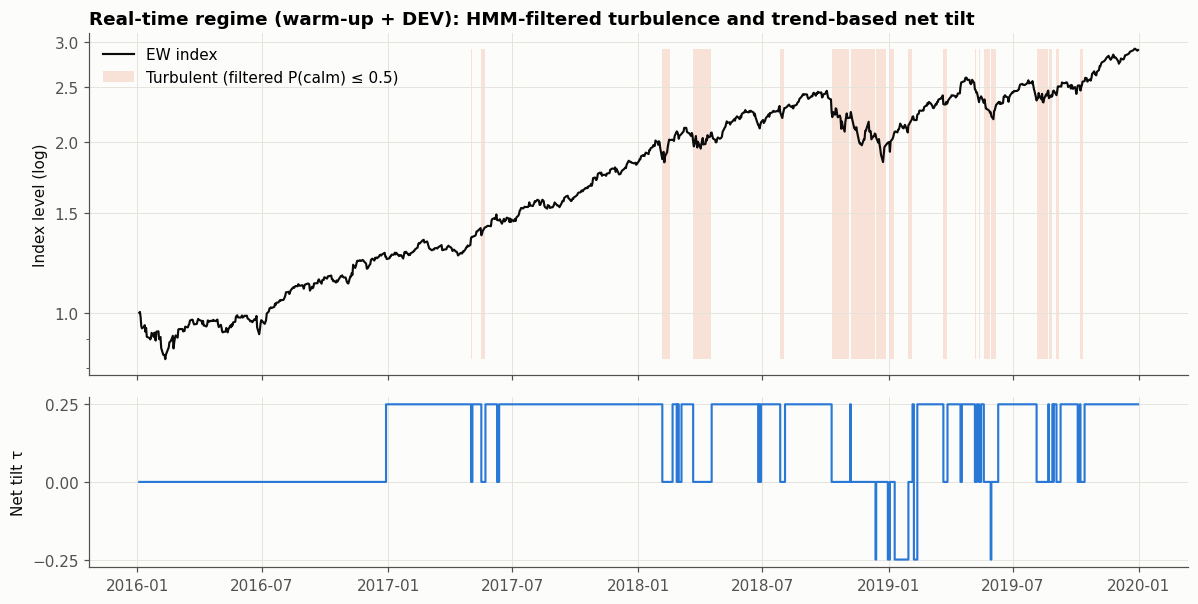

In [ ]:
# Generated by an LLM
EW_LEVEL = (1 + RET.mean(axis=1).fillna(0.0)).cumprod()
TREND = EW_LEVEL / EW_LEVEL.rolling(200).mean() - 1.0
REGIME = pd.DataFrame({
    "p_calm": P_CALM,
    "trend": TREND,
    "agg_sentiment": FS.market["agg_sentiment"],
})
REGIME["calm"] = REGIME["p_calm"] > 0.5
REGIME["tau"] = (CFG.tilt_max * np.sign(REGIME["trend"]) * REGIME["calm"]).where(
    REGIME["p_calm"].notna() & REGIME["trend"].notna(), 0.0)
STATE = pd.Series(np.select([REGIME["tau"] > 0, REGIME["tau"] < 0], ["calm & up", "calm & down"], "turbulent / neutral"),
                  index=REGIME.index, name="state")
display(STATE.loc[dev].value_counts().rename("sessions (DEV)").to_frame().T)

# Chart restricted to warm-up + DEV: the holdout is not inspected, even visually
ew_v, reg_v = EW_LEVEL.loc[:CFG.dev_end], REGIME.loc[:CFG.dev_end]
fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
ax = axes[0]
ax.plot(ew_v.index, ew_v.values, color=COLORS["ink"], lw=1.4, label="EW index")
turb = (reg_v["p_calm"] <= 0.5) & reg_v["p_calm"].notna()
ax.fill_between(ew_v.index, ew_v.min(), ew_v.max(), where=turb.values, color=COLORS["orange"],
                alpha=0.18, lw=0, label="Turbulent (filtered P(calm) ≤ 0.5)")
ax.set_yscale("log"); ax.set_ylabel("Index level (log)")
ax.set_yticks([1.0, 1.5, 2.0, 2.5, 3.0]); ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.1f"))
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_title("Real-time regime (warm-up + DEV): HMM-filtered turbulence and trend-based net tilt")
ax.legend(loc="upper left")
axes[1].step(reg_v.index, reg_v["tau"], where="post", color=COLORS["blue"], lw=1.4)
axes[1].set_ylabel("Net tilt τ"); axes[1].set_yticks([-0.25, 0, 0.25])
plt.tight_layout(); plt.show()

Over DEV: 575 sessions in the calm & up state (tilt +0.25), 159 turbulent sessions (neutral) and only 20 calm & down sessions (tilt −0.25). The filter flags the known stress episodes in real time: February 2018 (volatility shock), Q4 2018 (sell-off), May 2019 (trade-war escalation). It does so with a lag of a few sessions, the price of using filtered rather than smoothed probabilities.

In [ ]:
d21 = eval_dates(21)
ew_fwd = np.log(EW_LEVEL.shift(-21) / EW_LEVEL).loc[d21]              # LABEL (forward-looking by design)
state = STATE.loc[d21]
rows = {}
for s in ["calm & up", "calm & down", "turbulent / neutral"]:
    v = ew_fwd[state == s].dropna()
    rows[s] = {"sessions": len(v), "mean fwd 21d EW return": v.mean() if len(v) else np.nan,
               "t (NW)": newey_west_tstat(v, lags=21)[1] if len(v) > 30 else np.nan}
display(pd.DataFrame(rows).T)

ic_comp = rank_ic(COMPOSITE.loc[d21], FWD[21].loc[d21])
calm_d = REGIME["calm"].loc[d21]
display(pd.DataFrame({
    "calm": {"mean IC21": ic_comp[calm_d].mean(), "sessions": int(calm_d.sum())},
    "turbulent": {"mean IC21": ic_comp[~calm_d].mean(), "sessions": int((~calm_d).sum())},
}).T)

,sessions,mean fwd 21d EW return,t (NW)
calm & up,554.0000,0.0213,3.1644
calm & down,20.0000,0.0718,NaN
turbulent / neutral,159.0000,0.0235,1.6193


,mean IC21,sessions
calm,0.1037,574.0000
turbulent,0.0584,159.0000


Direction. After calm & up sessions, the EW index gains +2.1 % over the next 21 sessions (t = 3.2), which supports a positive tilt in calm uptrends. The calm & down state occurs on only 20 sessions in DEV. It coincided with the end of the Q4 2018 sell-off, which was followed by the strong January 2019 rebound (+7.2 %). DEV therefore provides no evidence that the downtrend state precedes negative returns, if anything the opposite.

the negative tilt is a prior-based protection against sustained bear markets and is not validated in DEV. Block 9 therefore compares, on DEV only, a symmetric tilt with a positive-only tilt (+0.25 in calm uptrends, 0 otherwise).

The composite's IC21 is 0.104 in calm markets against 0.058 in turbulent markets. Stock selection is more reliable when markets are calm, which is consistent with keeping the book neutral and risk-balanced in turbulence.

Truncation test for the models:

Both walk-forward models are re-run on data truncated at an intermediate date. The volatility forecasts and calm probabilities must be identical to the full-sample run on every date up to the truncation date, which proves that no future observation enters any forecast.

In [ ]:
T = pd.Timestamp("2019-06-28")
sig_T, _ = garch_forecast_panel(RET.loc[:T], CFG)
pc_T, _ = hmm_calm_probability(RET.loc[:T], CFG)
assert frames_equal(sig_T, SIG_GJR.loc[:T], tol=1e-8), "look-ahead in GARCH forecasts"
assert frames_equal(pc_T.to_frame(), P_CALM.loc[:T].to_frame(), tol=1e-8), "look-ahead in HMM probabilities"
print("Block 6 truncation tests passed: GJR-GARCH forecasts and HMM filtered probabilities use no future data.")

Block 6 truncation tests passed: GJR-GARCH forecasts and HMM filtered probabilities use no future data.


Thus the direction of analyst revisions, measured by breadth and net of price momentum, is the only robust rating-based signal in this dataset. It is slow, strongest in calm markets, and statistically modest with 10 stocks. The volatility and regime models are validated out-of-sample and tested free of look-ahead, ready for signal construction and allocation (parts 8 and 9).

# **7. Machine-Learning Challenger (In Sample DEV only)**

(Idea of procedure given by an LLM and some previous research)
The question we will try to answer here in this part is the following: Can a supervised model combine all candidate features, price controls and regime variables, including non-linearities and interactions, into a better cross-sectional forecast than the simple equal-weighted composite of part 5?



*   **Label**: cross-sectionally demeaned forward 21-session log return $\tilde y_{i,t}=y_{i,t\to t+21}-\frac1N\sum_j y_{j,t\to t+21}$. The long/short book only needs the relative ordering of stocks.

*   **Inputs**: date-by-date ranks of the 13 candidate features and 4 price controls, plus 3 market-level regime variables (filtered P(calm), trend, aggregate sentiment).

*   **Models** (deliberately simple and regularised, given about 10 stocks × 150 weekly dates per year): Ridge regression ($\alpha=10$) on the ranks; LightGBM, shallow (depth 3, 7 leaves, 150 trees, learning rate 0.03, at least 50 observations per leaf, row and column subsampling), which can learn regime interactions;

*   **Logistic regression** ($C=0.1$) predicting "above the cross-sectional mean", with explicit interactions between the selected features and $P(\text{calm})-0.5$.
*   **Walk-forward with purging**. Models are re-trained every 63 sessions on an expanding window. A training sample dated d is used at re-training date T only if its label has fully ended: $\text{pos}(d)+21\le\text{pos}(T)$. This purge removes every sample whose label overlaps the prediction period. In a forward-only walk-forward the test period never precedes training, so no additional embargo is needed. Samples are taken every 5 sessions to limit label overlap. Missing ranks are set to the neutral value 0 for the linear models; LightGBM handles them natively.


*   **Decision rule**: an ML model replaces the composite only if it is significantly better, i.e. the Newey-West t-stat (21 lags) of the daily paired IC difference (model − composite) exceeds 2.




In [ ]:
ML_COLS = CANDIDATES + CONTROLS
MKT_COLS = ["p_calm", "trend", "agg_sentiment"]

# Long-format design matrix: one row per (date, stock)
X_parts = [to_long(cs_rank(FEATS[n]), n).set_index(["date", "stock"]) for n in ML_COLS]
ML_DATA = pd.concat(X_parts, axis=1)
ML_DATA = (ML_DATA.reset_index()
           .merge(REGIME[MKT_COLS].rename_axis("date").reset_index(), on="date", how="left")
           .set_index(["date", "stock"]))
y21 = FWD[CFG.label_horizon]
y_dm = y21.sub(y21.mean(axis=1), axis=0)                             # LABEL: forward-looking by design
ML_DATA = ML_DATA.join(to_long(y_dm, "y").set_index(["date", "stock"]))
for f_ in SELECTED:                                                  # explicit regime interactions (logit)
    ML_DATA[f"{f_}_x_calm"] = ML_DATA[f_] * (ML_DATA["p_calm"] - 0.5)
INTER_COLS = [f"{f_}_x_calm" for f_ in SELECTED]
D_POS = ML_DATA.index.get_level_values("date").map(POS).values
NEUTRAL = {**{c: 0.0 for c in ML_COLS + INTER_COLS + ["trend", "agg_sentiment"]}, "p_calm": 0.5}


def ml_walk_forward(make_model, cols: Sequence[str], task: str = "reg", fill: bool = True,
                    step: int = 5, cfg: Config = CFG) -> pd.DataFrame:
    # Purged expanding-window walk-forward over DEV; returns a sessions x stocks prediction panel.
    dev_dates = PX.loc[cfg.dev_start:cfg.dev_end].index
    retrain = dev_dates[::cfg.ml_retrain]
    dates = ML_DATA.index.get_level_values("date")
    preds = pd.Series(np.nan, index=ML_DATA.index)
    for j, T in enumerate(retrain):
        pT = POS[T]
        tr_mask = (D_POS % step == 0) & (D_POS + cfg.label_horizon <= pT)           # PURGE
        tr = ML_DATA.loc[tr_mask].dropna(subset=["y"])
        assert (tr.index.get_level_values("date").map(POS).values + cfg.label_horizon <= pT).all()
        if len(tr) < 300:
            continue
        nxt = retrain[j + 1] if j + 1 < len(retrain) else dev_dates[-1] + pd.Timedelta(days=1)
        te = ML_DATA.loc[(dates >= T) & (dates < nxt)]
        Xtr, Xte = tr[list(cols)], te[list(cols)]
        if fill:
            Xtr, Xte = Xtr.fillna(NEUTRAL), Xte.fillna(NEUTRAL)
        ytr = (tr["y"] > 0).astype(int) if task == "clf" else tr["y"]
        model = make_model().fit(Xtr.values, ytr.values)
        p = model.predict_proba(Xte.values)[:, 1] if task == "clf" else model.predict(Xte.values)
        preds.loc[te.index] = p
    return preds.unstack("stock").reindex(index=PX.index, columns=PX.columns)


ML_MODELS = {
    "Ridge": (lambda: Ridge(alpha=10.0), ML_COLS + MKT_COLS, "reg", True),
    "LightGBM": (lambda: lgb.LGBMRegressor(n_estimators=150, learning_rate=0.03, max_depth=3, num_leaves=7,
                                          min_child_samples=50, subsample=0.8, subsample_freq=1,
                                          colsample_bytree=0.8, reg_lambda=5.0, random_state=CFG.seed,
                                          n_jobs=1, deterministic=True, force_row_wise=True, verbose=-1),
                 ML_COLS + MKT_COLS, "reg", False),
    "Logistic (regime interactions)": (lambda: LogisticRegression(C=0.1, max_iter=2000),
                                       ML_COLS + ["p_calm"] + INTER_COLS, "clf", True),
}
ML_PRED = {name: ml_walk_forward(fn, cols, task, fill) for name, (fn, cols, task, fill) in ML_MODELS.items()}
N_TRIALS += len(ML_PRED)

ml_rows = {}
for name, pred in {"COMPOSITE (Block 5)": COMPOSITE, **ML_PRED}.items():
    s = ic_summary(pred, 21)
    sp = perf_stats(ls_spread(pred, RET).loc[dev])
    ml_rows[name] = {"IC21": s["IC"], "t_NW": s["t_NW"], "IC 2017": s.get("IC 2017"), "IC 2018": s.get("IC 2018"),
                     "IC 2019": s.get("IC 2019"), "L/S Sharpe": sp["Sharpe"], "L/S CAGR / MaxDD": sp["CAGR / MaxDD"]}
ML_TBL = pd.DataFrame(ml_rows).T
display(ML_TBL)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

,IC21,t_NW,IC 2017,IC 2018,IC 2019,L/S Sharpe,L/S CAGR / MaxDD
COMPOSITE (Block 5),0.0939,2.1493,0.1563,0.1386,-0.0225,0.5974,0.2964
Ridge,0.0611,1.4378,0.1861,-0.0150,0.0078,0.2317,0.1209
LightGBM,0.1021,2.5628,0.2323,0.0828,-0.0185,0.9542,0.8685
Logistic (regime interactions),0.0773,1.8237,0.2002,-0.0229,0.0525,0.6388,0.4073


All three models have a positive walk-forward IC21: Ridge 0.061, Logistic 0.077 and LightGBM 0.102 (t = 2.56), against 0.094 for the composite. LightGBM's top-3 / bottom-3 spread also looks better (Sharpe 0.95 vs 0.60). Taken at face value, LightGBM "wins".



**Is the best ML model significantly better? Paired test, sensitivity, and a disclosed amendment**

**Disclosure.** The rule first written for this block was: "an ML model replaces the composite if its IC21 is higher and its t-stat exceeds 2". Applied to the table above, it selects LightGBM (IC21 0.102 vs 0.094). Before accepting this, we ran two checks that the first rule should have required:



1.   Paired test. The composite and the models are evaluated on the same dates, so the right question is whether the daily IC difference is significantly positive (Newey-West, 21 lags).
2.   Hyperparameter and seed sensitivity of LightGBM: 6 reasonable alternative configurations. A genuine edge should not depend on one particular configuration.

Both checks show that the apparent win is noise (results below). We therefore tightened the rule to the paired test. The amendment was made after observing the first result, which is exactly why it is disclosed here. All these runs are added to the trial count used for the Deflated Sharpe Ratio (part 12). Under either rule, the evidence that ML adds value over the transparent composite is absent.

In [ ]:
d21 = eval_dates(21)
ic_comp21 = rank_ic(COMPOSITE.loc[d21], FWD[21].loc[d21])
paired = {}
for name, pred in ML_PRED.items():
    diff = (rank_ic(pred.loc[d21], FWD[21].loc[d21]) - ic_comp21).dropna()
    m_, t_ = newey_west_tstat(diff, lags=21)
    paired[name] = {"mean IC difference (model - composite)": m_, "NW t (21 lags)": t_}
PAIRED_TBL = pd.DataFrame(paired).T
display(PAIRED_TBL)

base_kw = dict(n_estimators=150, learning_rate=0.03, max_depth=3, num_leaves=7, min_child_samples=50, subsample=0.8,
               subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0, random_state=CFG.seed, n_jobs=1,
               deterministic=True, force_row_wise=True, verbose=-1)
variants = {"base (Block 7)": {}, "depth 2": dict(max_depth=2, num_leaves=3), "300 trees": dict(n_estimators=300),
            "learning rate 0.01": dict(learning_rate=0.01), "min 100 obs / leaf": dict(min_child_samples=100),
            "seed 7": dict(random_state=7), "seed 123": dict(random_state=123)}
sens = {}
for vname, upd in variants.items():
    pred = ML_PRED["LightGBM"] if not upd else ml_walk_forward(lambda: lgb.LGBMRegressor(**{**base_kw, **upd}),
                                                               ML_COLS + MKT_COLS, "reg", False)
    s_ = ic_summary(pred, 21)
    sens[vname] = {"IC21": s_["IC"], "t_NW": s_["t_NW"], "IC 2017": s_.get("IC 2017"), "IC 2018": s_.get("IC 2018"),
                   "IC 2019": s_.get("IC 2019"), "L/S Sharpe": perf_stats(ls_spread(pred, RET).loc[dev])["Sharpe"]}
    N_TRIALS += 0 if not upd else 1
SENS_TBL = pd.DataFrame(sens).T
display(SENS_TBL)
print(f"LightGBM IC21 across configurations: min {SENS_TBL['IC21'].min():.3f} | median {SENS_TBL['IC21'].median():.3f} | "
      f"max {SENS_TBL['IC21'].max():.3f}  vs composite {ML_TBL.at['COMPOSITE (Block 5)', 'IC21']:.3f}")

best_ml = PAIRED_TBL["NW t (21 lags)"].idxmax()
ML_WINS = bool(PAIRED_TBL.at[best_ml, "NW t (21 lags)"] > 2)
SCORE = ML_PRED[best_ml] if ML_WINS else COMPOSITE
SCORE_NAME = best_ml if ML_WINS else "COMPOSITE"
print(f"Decision (paired rule): ML replaces the composite: {ML_WINS} -> score used from Block 8: {SCORE_NAME}")

,mean IC difference (model - composite),NW t (21 lags)
Ridge,-0.0328,-0.7375
LightGBM,0.0082,0.1837
Logistic (regime interactions),-0.0166,-0.3374


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/v

,IC21,t_NW,IC 2017,IC 2018,IC 2019,L/S Sharpe
base (Block 7),0.1021,2.5628,0.2323,0.0828,-0.0185,0.9542
depth 2,0.0646,1.4489,0.2321,0.0192,-0.0682,0.7090
300 trees,0.0746,2.0449,0.1828,0.0449,-0.0105,0.7461
learning rate 0.01,0.0914,2.0236,0.2602,0.0290,-0.0243,0.8826
min 100 obs / leaf,0.0714,1.9541,0.1983,0.0337,-0.0254,0.5685
seed 7,0.0908,2.3644,0.2060,0.0586,0.0007,0.7167
seed 123,0.0857,2.1032,0.2396,0.0446,-0.0370,0.9183


LightGBM IC21 across configurations: min 0.065 | median 0.086 | max 0.102  vs composite 0.094
Decision (paired rule): ML replaces the composite: False -> score used from Block 8: COMPOSITE


LightGBM's average daily IC advantage over the composite is +0.008, with a Newey-West t of 0.18: statistically indistinguishable from zero. Ridge and Logistic are below the composite.

Across 7 reasonable configurations, LightGBM's IC21 ranges from 0.065 to 0.102, with a median of 0.086, below the composite's 0.094. The base configuration happens to be the best of the seven. Its 2018 IC collapses to 0.02–0.06 in several variants, whereas the composite holds at 0.14.

Thus the composite is retained. With about 2,000 weekly training observations on 10 stocks, a tree model cannot reliably learn more than a transparent, equal-weighted average of three economically motivated signals. This is the expected result for a small cross-section, and it is exactly what the challenger was meant to test.

In [ ]:
full_mask = (D_POS % 5 == 0) & (D_POS + CFG.label_horizon <= DEV_END_POS)
tr_all = ML_DATA.loc[full_mask].dropna(subset=["y"])
lgb_full = ML_MODELS["LightGBM"][0]().fit(tr_all[ML_COLS + MKT_COLS].values, tr_all["y"].values)
ridge_full = Ridge(alpha=10.0).fit(tr_all[ML_COLS + MKT_COLS].fillna(NEUTRAL).values, tr_all["y"].values)
imp = pd.DataFrame({
    "LightGBM gain share": lgb_full.booster_.feature_importance("gain") / lgb_full.booster_.feature_importance("gain").sum(),
    "Ridge coefficient (x100)": ridge_full.coef_ * 100,
}, index=ML_COLS + MKT_COLS).sort_values("LightGBM gain share", ascending=False)
display(imp.head(10))
print(f"Training samples (weekly, purged, whole DEV): {len(tr_all):,}")

,LightGBM gain share,Ridge coefficient (x100)
event_breadth_63,0.1048,1.9762
neg_dispersion,0.0953,-2.4484
low_vol_60,0.0827,0.0877
coverage_chg_126,0.0791,-1.3972
agg_sentiment,0.0730,0.0052
trend,0.0683,-0.0251
mom_12_1,0.0682,1.7256
breadth_63,0.0611,0.6860
mom_6_1,0.0521,-2.0177
cons_mom_126,0.0465,1.4021


Training samples (weekly, purged, whole DEV): 1,970


LightGBM spreads its gain over many inputs, with no dominant structure: event-day breadth 10 %, low dispersion 9.5 %, low volatility 8 %, coverage change 8 %, then regime variables (about 7 % each) and momentum. Ridge puts positive weight on event-day breadth and breadth, but also sizeable weights on dispersion and 6-1 momentum, inputs that were individually uninformative in part 5. Models that recombine many individually weak inputs are the classic source of overfitting, which supports our parsimonious choice.

# **8. Signal Construction & Trading Rules**

At each rebalancing date t (every 5 sessions), the stocks are ranked on the score (the composite, unless the ML challenger had won):

$$s_{i,t}=\begin{cases}+1 & \text{if } i \text{ is among the } k \text{ highest-ranked stocks}\\-1 & \text{if } i \text{ is among the } k \text{ lowest-ranked stocks}\\0 & \text{otherwise}\end{cases}$$

**Trading rules**:


1.   **Both legs always present**. A signal is generated only if at least $2k$ stocks have a valid score; otherwise every signal is 0 and the book is flat.

2.   **Hysteresis (optional buffer $b\in\{0,1\}$ ranks)**: With $b=1$, an existing long is kept as long as it stays within the top $k+1$ (shorts: bottom $k+1$), and free slots are filled with the best-ranked new names. Hysteresis halves the number of position changes, which matters in practice (costs, a fund's turnover budget) but has no value under the zero-cost assumption of this first implementation, and it delays exits from decaying signals. It was first fixed at $b=1$ a priori. Because part 10 showed that this choice materially changes results, both settings are evaluated there (disclosed amendment, trials counted).

3.   **Rebalancing frequency**: weekly (every 5 sessions), consistent with the rank autocorrelation of 0.8–0.9 at 5 sessions and the rising IC profile (in part 5)
4.   **Holding**: between rebalancing dates, signals and weights are held constant (forward only).


5.   **Execution timing**: the decision is taken at the close of t with information available at t, and earns returns from t+1.




Average number of position changes per weekly rebalance (DEV): with hysteresis 0.93 | without 1.86
Share of DEV sessions with an active book: 100.0%
Share of DEV sessions each stock spends long / short (k = 3):


stock,stock_1,stock_2,stock_3,stock_4,stock_5,stock_6,stock_7,stock_8,stock_9,stock_10
long,0.1857,0.4310,0.2958,0.1989,0.0796,0.8276,0.3263,0.2294,0.3780,0.0477
short,0.2586,0.2838,0.1008,0.3448,0.2122,0.0000,0.3886,0.2984,0.3700,0.7427


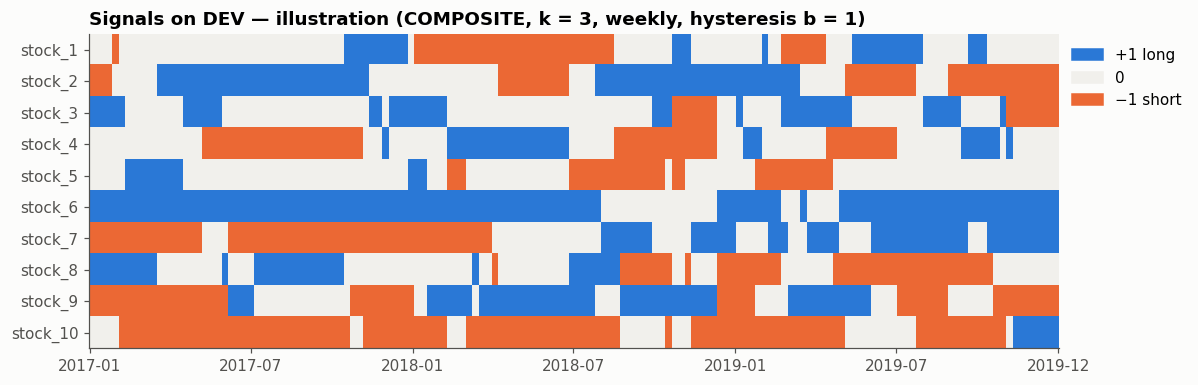

In [ ]:
def rebalance_mask(index: pd.DatetimeIndex, freq: int) -> np.ndarray:
    # Deterministic weekly schedule anchored to the first session.
    return np.arange(len(index)) % freq == 0


def build_signals(score: pd.DataFrame, k: int, freq: int = 5, buffer: int = 1) -> pd.DataFrame:
    # Ternary long/short signals with hysteresis, set on rebalancing dates and held in between.
    sig = pd.DataFrame(np.nan, index=score.index, columns=score.columns)
    held_long, held_short = set(), set()
    for i in np.flatnonzero(rebalance_mask(score.index, freq)):   # small state machine over ~300 dates
        s = score.iloc[i].dropna()
        row = pd.Series(0, index=score.columns, dtype=float)
        if len(s) < 2 * k:
            held_long, held_short = set(), set()
            sig.iloc[i] = row
            continue
        rk_desc = s.rank(ascending=False, method="first")
        rk_asc = s.rank(ascending=True, method="first")
        longs = {n for n in held_long if n in s.index and rk_desc[n] <= k + buffer}
        for n in rk_desc.sort_values().index:
            if len(longs) >= k:
                break
            longs.add(n)
        longs = set(sorted(longs, key=lambda n: rk_desc[n])[:k])
        shorts = {n for n in held_short if n in s.index and rk_asc[n] <= k + buffer and n not in longs}
        for n in rk_asc.sort_values().index:
            if len(shorts) >= k:
                break
            if n not in longs:
                shorts.add(n)
        shorts = set(sorted(shorts, key=lambda n: rk_asc[n])[:k])
        row[list(longs)] = 1.0
        row[list(shorts)] = -1.0
        sig.iloc[i] = row
        held_long, held_short = longs, shorts
    return sig.ffill().fillna(0.0).astype(int)


SIG_K3 = build_signals(SCORE, k=3, freq=CFG.rebal_freq, buffer=1)
SIG_K3_NOBUF = build_signals(SCORE, k=3, freq=CFG.rebal_freq, buffer=0)

# Invariants
for S in (SIG_K3, SIG_K3_NOBUF):
    assert set(np.unique(S.values)) <= {-1, 0, 1}
    active = S.abs().sum(axis=1) > 0
    assert ((S == 1).sum(axis=1)[active] == 3).all() and ((S == -1).sum(axis=1)[active] == 3).all()

rb = rebalance_mask(PX.index, CFG.rebal_freq)
def name_changes(S: pd.DataFrame) -> float:
    Sr = S.loc[rb].loc[dev]
    return (Sr.diff().abs() > 0).sum(axis=1).iloc[1:].mean()
print(f"Average number of position changes per weekly rebalance (DEV): with hysteresis {name_changes(SIG_K3):.2f} | "
      f"without {name_changes(SIG_K3_NOBUF):.2f}")
print(f"Share of DEV sessions with an active book: {(SIG_K3.loc[dev].abs().sum(axis=1) > 0).mean():.1%}")
print("Share of DEV sessions each stock spends long / short (k = 3):")
display(pd.DataFrame({"long": (SIG_K3.loc[dev] == 1).mean(), "short": (SIG_K3.loc[dev] == -1).mean()}).T)

fig, ax = plt.subplots(figsize=(11, 3.6))
sig_cmap = mpl.colors.ListedColormap([COLORS["orange"], "#f1f0ec", COLORS["blue"]])
Sd = SIG_K3.loc[dev]
ax.imshow(Sd.T.values, aspect="auto", cmap=sig_cmap, vmin=-1, vmax=1, interpolation="nearest")
ax.set_yticks(range(Sd.shape[1])); ax.set_yticklabels(Sd.columns)
xt = np.linspace(0, len(Sd) - 1, 7).astype(int); ax.set_xticks(xt); ax.set_xticklabels([Sd.index[i].strftime("%Y-%m") for i in xt])
ax.grid(False)
ax.legend(handles=[mpl.patches.Patch(color=COLORS["blue"], label="+1 long"), mpl.patches.Patch(color="#f1f0ec", label="0"),
                   mpl.patches.Patch(color=COLORS["orange"], label="−1 short")], loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title(f"Signals on DEV — illustration ({SCORE_NAME}, k = 3, weekly, hysteresis b = 1)")
plt.tight_layout(); plt.show()

Hysteresis: It halves the number of position changes per weekly rebalance (1.86 to 0.93).

The book is active on 100 % of DEV sessions: there are always enough scored stocks for both legs.

Signal persistence and concentration. The signal has persistent stock tilts. stock_6 is long 83 % of the time and never short, and stock_10 is short 74 % of the time: analysts keep revising some names up and others down. This makes the leave-one-stock-out test of part 12 essential.

# **9. Long/Short Portfolio Allocator**

At each rebalancing date, with the long set $L$ and short set $S$ given by the signals:

$$w_{i,t}=\begin{cases}+(0.5+\tau_t)\,a^L_{i,t} & i\in L\\-(0.5-\tau_t)\,a^S_{i,t} & i\in S\\0 & \text{otherwise}\end{cases}\qquad \sum_{i\in L}a^L_{i,t}=\sum_{i\in S}a^S_{i,t}=1,\ a\ge0.$$



*   **Gross exposure** $\sum_i|w_{i,t}|=1$ at all times: no leverage, no volatility targeting.

*   **Net exposure** $=2\tau_t\in[-0.5,+0.5]$, driven by the regime (part 6). Both legs keep a strictly positive budget (at least 0.25), so the book is always long/short.
*   **Sign consistency**: $\operatorname{sign}(w_{i,t})=s_{i,t}$ by construction.


**Intra-leg allocators** (the same method is applied separately to each leg):

In [ ]:
import pandas as pd
from IPython.display import display, Markdown

allocators_data = [
    {
        "Allocator": "**EW** (Equal-Weighted)",
        "Weights inside a leg": "$$a_i = \\frac{1}{k}$$",
        "Rationale": "Naive benchmark: no estimation error."
    },
    {
        "Allocator": "**IV-GJR** (Inverse-Variance)",
        "Weights inside a leg": "$$a_i \\propto \\frac{1}{\\hat{\\sigma}_{i,t+1 \\mid t}}$$",
        "Rationale": "Approximately equalises risk contributions within a leg using the forecast, asymmetric volatility; very robust (no correlations to estimate)"
    },
    {
        "Allocator": "**HRP** (Hierarchical Risk Parity)",
        "Weights inside a leg": "$$a_i = \\text{HRP}(\\hat{\\Sigma}_{LW, t})$$",
        "Rationale": "Hierarchichal Clusturing based on Ledoit-Wolf distance correlation metric $\\sqrt{(1-\\rho)/2}$ on a sliding window of 126 days. allocates risk budget in a recursive manner without necessitating to inverse any matrices."
    }
]

df_allocators = pd.DataFrame(allocators_data)
display(Markdown("### **Comparatif des Allocateurs Intra-Leg**"))
display(Markdown(df_allocators.to_markdown(index=False)))

### **Comparatif des Allocateurs Intra-Leg**

| Allocator                          | Weights inside a leg                                  | Rationale                                                                                                                                                                                                                 |
|:-----------------------------------|:------------------------------------------------------|:--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **EW** (Equal-Weighted)            | $$a_i = \frac{1}{k}$$                                 | Naive benchmark: no estimation error.                                                                                                                                                                                     |
| **IV-GJR** (Inverse-Variance)      | $$a_i \propto \frac{1}{\hat{\sigma}_{i,t+1 \mid t}}$$ | Approximately equalises risk contributions within a leg using the forecast, asymmetric volatility; very robust (no correlations to estimate)                                                                              |
| **HRP** (Hierarchical Risk Parity) | $$a_i = \text{HRP}(\hat{\Sigma}_{LW, t})$$            | Hierarchichal Clusturing based on Ledoit-Wolf distance correlation metric $\sqrt{(1-\rho)/2}$ on a sliding window of 126 days. allocates risk budget in a recursive manner without necessitating to inverse any matrices. |

Regime tilt variants (the choice is made on in sample DEV set in part 10):



*   none: $\tau=0$, dollar-neutral at all times;

*   symmetric: $\tau=+0.25$ in calm uptrends, $-0.25$ in calm downtrends, 0 in turbulence (part 6)
*   positive: $\tau=+0.25$ in calm uptrends and 0 otherwise. This variant follows from part 6, where the downtrend state had no support in DEV.

**Exact P&L decomposition**: $w=\underbrace{0.5\,(a^L-a^S)}_{\text{selection (dollar-neutral)}}+\underbrace{\tau\,(a^L+a^S)}_{\text{timing (net exposure)}}$. The strategy return therefore splits exactly into a stock-selection part and a market-timing part (used in part 10).



In [ ]:
def hrp_weights(cov: np.ndarray) -> np.ndarray:
    # Hierarchical Risk Parity weights (single linkage on correlation distance, recursive bisection).
    n = cov.shape[0]
    if n == 1:
        return np.ones(1)
    sd = np.sqrt(np.diag(cov))
    corr = np.clip(cov / np.outer(sd, sd), -1.0, 1.0)
    dist = np.sqrt(np.clip((1.0 - corr) / 2.0, 0.0, 1.0))
    np.fill_diagonal(dist, 0.0)
    order = list(leaves_list(linkage(squareform(dist, checks=False), method="single")))
    w = np.ones(n)
    clusters = [order]
    while clusters:
        nxt = []
        for c in clusters:
            if len(c) < 2:
                continue
            left, right = c[: len(c) // 2], c[len(c) // 2:]
            def cluster_var(ix):
                sub = cov[np.ix_(ix, ix)]
                iv = 1.0 / np.diag(sub)
                iv /= iv.sum()
                return float(iv @ sub @ iv)
            v_l, v_r = cluster_var(left), cluster_var(right)
            alpha = 1.0 - v_l / (v_l + v_r)
            w[left] *= alpha
            w[right] *= 1.0 - alpha
            nxt += [left, right]
        clusters = nxt
    return w / w.sum()


_LW_CACHE: dict = {}


def universe_cov(ret: pd.DataFrame, t: pd.Timestamp, window: int = 126) -> Optional[pd.DataFrame]:
    # Ledoit-Wolf covariance of all stocks on the last `window` sessions up to the close of t (cached).
    key = (id(ret), ret.shape, ret.index[-1], t)
    if key not in _LW_CACHE:
        hist = ret.loc[:t].iloc[-window:].dropna(how="all").dropna(axis=1, how="any")
        _LW_CACHE[key] = (None if len(hist) < 60 else
                          pd.DataFrame(LedoitWolf().fit(hist.values).covariance_, index=hist.columns, columns=hist.columns))
    return _LW_CACHE[key]


def leg_weights(names: list, t: pd.Timestamp, method: str, ret: pd.DataFrame, sig_vol: pd.DataFrame) -> np.ndarray:
    # Intra-leg weights (sum to 1) using information available at the close of t.
    if method == "EW":
        return np.full(len(names), 1.0 / len(names))
    vol = sig_vol.loc[t, names].astype(float)
    fallback = ret.loc[:t, names].iloc[-60:].std()
    vol = vol.fillna(fallback)
    if method == "IV-GJR":
        a = 1.0 / vol.values
        return a / a.sum()
    if method == "HRP":
        cov = universe_cov(ret, t)                                   # returns known at the close of t
        if cov is None or not set(names) <= set(cov.columns):
            a = 1.0 / vol.values
            return a / a.sum()
        return hrp_weights(cov.loc[names, names].values)
    raise ValueError(method)


def tilt_series(variant: str) -> pd.Series:
    # Regime tilt tau_t for a given variant (causal, from Block 6).
    tau = REGIME["tau"].fillna(0.0)
    return {"none": tau * 0.0, "symmetric": tau, "positive": tau.clip(lower=0.0)}[variant]


@dataclass
class Book:
    weights: pd.DataFrame
    w_selection: pd.DataFrame
    w_timing: pd.DataFrame


def allocate(signals: pd.DataFrame, tau: pd.Series, method: str, ret: pd.DataFrame, sig_vol: pd.DataFrame,
             freq: int = CFG.rebal_freq) -> Book:
    # Long/short weights set on rebalancing dates (held in between), with the selection/timing split.
    cols = signals.columns
    W = pd.DataFrame(np.nan, index=signals.index, columns=cols)
    Wsel, Wtim = W.copy(), W.copy()
    for i in np.flatnonzero(rebalance_mask(signals.index, freq)):
        t = signals.index[i]
        s = signals.iloc[i]
        L, S = list(s.index[s == 1]), list(s.index[s == -1])
        aL, aS = pd.Series(0.0, index=cols), pd.Series(0.0, index=cols)
        if L and S:
            aL[L] = leg_weights(L, t, method, ret, sig_vol)
            aS[S] = leg_weights(S, t, method, ret, sig_vol)
        tau_t = float(tau.get(t, 0.0)) if (L and S) else 0.0
        Wsel.iloc[i] = 0.5 * (aL - aS)
        Wtim.iloc[i] = tau_t * (aL + aS)
        W.iloc[i] = Wsel.iloc[i] + Wtim.iloc[i]
    return Book(W.ffill().fillna(0.0), Wsel.ffill().fillna(0.0), Wtim.ffill().fillna(0.0))


def check_book(book: Book, signals: pd.DataFrame, tol: float = 1e-9) -> None:
    # Invariants: sign consistency, zero weight where no signal, gross = 1 when active, both legs present.
    W = book.weights
    active = signals.abs().sum(axis=1) > 0
    assert ((np.sign(W) == signals) | (W.abs() < tol)).all().all(), "sign(w) != signal"
    assert (W[signals == 0].abs().fillna(0) < tol).all().all(), "weight without signal"
    assert (W[signals != 0].abs().fillna(1) > tol).all().all(), "signal without weight"
    gross = W.abs().sum(axis=1)
    assert ((gross[active] - 1.0).abs() < 1e-8).all(), "gross exposure != 1"
    assert (W.clip(lower=0).sum(axis=1)[active] >= 0.25 - 1e-9).all() and \
           (W.clip(upper=0).sum(axis=1)[active] <= -0.25 + 1e-9).all(), "a leg is missing"
    assert np.allclose(W.values, (book.w_selection + book.w_timing).values), "decomposition broken"


# Example: one rebalancing date, three allocators, symmetric tilt
t_ex = PX.index[np.flatnonzero(rb & (PX.index >= pd.Timestamp("2018-06-01")))[0]]
ex = {}
for m in ["EW", "IV-GJR", "HRP"]:
    bk = allocate(SIG_K3.loc[:t_ex], tilt_series("symmetric").loc[:t_ex], m, RET, SIG_GJR)
    check_book(bk, SIG_K3.loc[:t_ex])
    ex[m] = bk.weights.loc[t_ex]
ex_tbl = pd.DataFrame(ex)
ex_tbl["signal"] = SIG_K3.loc[t_ex]
ex_tbl["GJR vol (ann.)"] = SIG_GJR.loc[t_ex] * np.sqrt(252)
print(f"Example rebalance on {t_ex:%Y-%m-%d} | tau = {tilt_series('symmetric').loc[t_ex]:+.2f}")
display(ex_tbl.loc[ex_tbl["signal"] != 0].sort_values("signal", ascending=False))
display(pd.DataFrame({"gross": ex_tbl[["EW", "IV-GJR", "HRP"]].abs().sum(), "net": ex_tbl[["EW", "IV-GJR", "HRP"]].sum()}).T)

Example rebalance on 2018-06-06 | tau = +0.25


,EW,IV-GJR,HRP,signal,GJR vol (ann.)
stock,,,,,
stock_6,0.2500,0.3973,0.2081,1,0.1357
stock_4,0.2500,0.1859,0.1245,1,0.2901
stock_9,0.2500,0.1668,0.4174,1,0.3233
stock_1,-0.0833,-0.1186,-0.0942,-1,0.1481
stock_2,-0.0833,-0.0628,-0.0916,-1,0.2799
stock_10,-0.0833,-0.0686,-0.0642,-1,0.2559


,EW,IV-GJR,HRP
gross,1.0000,1.0000,1.0000
net,0.5000,0.5000,0.5000


On 2018-06-06 the regime is calm and trending up (τ = +0.25), so the long leg receives a budget of 0.75 and the short leg 0.25: gross exposure 1, net exposure +0.5, for all three allocators.



*   **IV-GJR** overweights the least volatile long, stock_6 (forecast volatility 14 %, weight 0.40 against 0.25 under EW), and underweights the most volatile ones.
*   **HRP** reaches a different allocation because it also uses correlations: it overweights stock_9, which diversifies the rest of the leg.

Every weight has the sign of its signal.

Invariants are checked for every allocator and tilt variant over the full sample. A truncation test then verifies that signals and weights computed with data up to T are identical, up to T, to those computed on the full sample.

In [ ]:
for m in ["EW", "IV-GJR", "HRP"]:
    for v in ["none", "symmetric", "positive"]:
        check_book(allocate(SIG_K3, tilt_series(v), m, RET, SIG_GJR), SIG_K3)

T = pd.Timestamp("2019-06-28")
sig_T = build_signals(SCORE.loc[:T], k=3, freq=CFG.rebal_freq, buffer=1)
assert sig_T.equals(SIG_K3.loc[:T]), "look-ahead in signals"
for m in ["IV-GJR", "HRP"]:
    bk_T = allocate(sig_T, tilt_series("symmetric").loc[:T], m, RET.loc[:T], SIG_GJR.loc[:T])
    bk_full = allocate(SIG_K3, tilt_series("symmetric"), m, RET, SIG_GJR)
    assert frames_equal(bk_T.weights, bk_full.weights.loc[:T]), f"look-ahead in {m} weights"
print("Block 9 tests passed: sign consistency, zero weight without signal, gross = 1, both legs always present, "
      "exact selection/timing decomposition, truncation (no look-ahead) for signals and weights.")

Block 9 tests passed: sign consistency, zero weight without signal, gross = 1, both legs always present, exact selection/timing decomposition, truncation (no look-ahead) for signals and weights.


# **10. Backtest, Metrics & Attribution (DEV set) and Strategy Freeze**

Now we construct our backtest engine. Daily portfolio return $r_{p,t+1}=\sum_i w_{i,t}\,r_{i,t+1}$. No transaction costs (per the instructions), turnover is reported for information.

Candidate configurations (36 in total, all evaluated on DEV only and all counted as trials):



*   legs of $k\in\{3,4\}$ names

*   tilt $\in\{$none, symmetric, positive$\}$
*   hysteresis buffer $b\in\{0,1\}$


*   allocator $\in\{$EW, IV-GJR, HRP$\}$.

The score (composite) and weekly rebalancing are fixed upstream.

**Disclosure (hysteresis)**. The first version of this block fixed $b=1$ a priori (18 configurations). That run showed that hysteresis consistently lowers performance: for $k=3$ with no tilt and EW weights, the Sharpe drops from 0.60 to 0.16. It also made part 10 inconsistent with the part 5 spread. Its only benefit is lower turnover, which has no value under the brief's zero-cost assumption. The buffer was therefore added to the grid. The 18 earlier runs remain in the trial count.

Pre-registered selection rule (chosen to favour robustness over the single best backtest):



1.   **Structure first**: Choose the structure $(k,\text{tilt},b)$ with the highest average CAGR/MaxDD across the three allocators. A structure that only works with one allocator is fragile.
2.   **Then the allocator**: Within that structure, keep IV-GJR (the a-priori primary allocator) unless another allocator beats it by more than 0.10 in CAGR/MaxDD.


**Benchmarks**: the same signal dollar-neutral with EW weights (pure selection); a 12-1 momentum long/short built identically (a price signal instead of analysts); a placebo with random scores and the same tilt and allocator (pure timing); and the equal-weight buy-and-hold (market context only, not a long/short strategy).






In [ ]:
@dataclass
class BacktestResult:
    returns: pd.Series
    selection: pd.Series
    timing: pd.Series
    weights: pd.DataFrame
    signals: pd.DataFrame


def backtest(signals: pd.DataFrame, book: Book, ret: pd.DataFrame) -> BacktestResult:
    # Close-to-close backtest: weights decided at t earn returns from t+1.
    r = (book.weights.shift(1) * ret).sum(axis=1)
    sel = (book.w_selection.shift(1) * ret).sum(axis=1)
    tim = (book.w_timing.shift(1) * ret).sum(axis=1)
    return BacktestResult(r, sel, tim, book.weights, signals)


def run_config(score: pd.DataFrame, k: int, tilt: str, alloc: str, buffer: int = 1) -> BacktestResult:
    sig = build_signals(score, k=k, freq=CFG.rebal_freq, buffer=buffer)
    return backtest(sig, allocate(sig, tilt_series(tilt), alloc, RET, SIG_GJR), RET)


def annual_turnover(W: pd.DataFrame, window) -> float:
    # One-way annualised turnover: 0.5 * sum |dw| per year.
    dW = W.diff().abs().sum(axis=1).loc[window]
    return 0.5 * dW.sum() / (len(dW) / 252)


GRID = {}
grid_rows = []
for k in (3, 4):
    for tilt in ("none", "symmetric", "positive"):
        for buf in (0, 1):
            for alloc in ("EW", "IV-GJR", "HRP"):
                res = run_config(SCORE, k, tilt, alloc, buf)
                GRID[(k, tilt, buf, alloc)] = res
                st = perf_stats(res.returns.loc[dev])
                grid_rows.append({"k": k, "tilt": tilt, "buffer": buf, "allocator": alloc, "CAGR": st["CAGR"],
                                  "Max drawdown": st["Max drawdown"], "CAGR / MaxDD": st["CAGR / MaxDD"], "Sharpe": st["Sharpe"],
                                  "avg net exposure": res.weights.sum(axis=1).loc[dev].mean(),
                                  "turnover (1-way, ann.)": annual_turnover(res.weights, dev)})
                N_TRIALS += 1
N_TRIALS += 18                                      # first version of the grid (b = 1 only), disclosed
GRID_TBL = pd.DataFrame(grid_rows).set_index(["k", "tilt", "buffer", "allocator"])
display(GRID_TBL)

# Consistency check with Block 5: k = 3, no tilt, no buffer, EW must reproduce the Block 5 spread exactly
assert np.allclose(GRID[(3, "none", 0, "EW")].returns.loc[dev].values, ls_spread(SCORE, RET).loc[dev].values), \
    "Block 10 engine inconsistent with Block 5 spread"
print("Consistency check passed: Block 10 engine (k=3, no tilt, no buffer, EW) reproduces the Block 5 spread exactly.")

struct = GRID_TBL["CAGR / MaxDD"].groupby(level=["k", "tilt", "buffer"]).mean().rename("mean CAGR/MaxDD across allocators")
display(struct.to_frame().T)
best_k, best_tilt, best_buf = struct.idxmax()
cand = GRID_TBL.xs((best_k, best_tilt, best_buf), level=["k", "tilt", "buffer"])["CAGR / MaxDD"]
best_alloc = "IV-GJR" if cand.max() - cand["IV-GJR"] <= 0.10 else cand.idxmax()
FINAL = {"score": SCORE_NAME, "features": (ML_COLS + MKT_COLS) if ML_WINS else SELECTED, "k": int(best_k),
         "tilt": best_tilt, "allocator": best_alloc, "rebalance_every_sessions": CFG.rebal_freq,
         "hysteresis_buffer": int(best_buf), "tilt_max": CFG.tilt_max}
print(f"Selected structure: k = {best_k}, tilt = {best_tilt}, buffer = {best_buf} | allocator: {best_alloc}")
print(f"Trials logged so far: {N_TRIALS}")

CAGR  Max drawdown  CAGR / MaxDD  Sharpe  avg net exposure  turnover (1-way, ann.)
k tilt      buffer allocator                                                                                     
3 none      0      EW        0.0592       -0.1999        0.2964  0.5974            0.0000                  8.1883
                   IV-GJR    0.0609       -0.1608        0.3789  0.6631            0.0000                 10.5683
                   HRP       0.0455       -0.1956        0.2325  0.4911           -0.0000                 10.1131
            1      EW        0.0114       -0.2550        0.0446  0.1592            0.0000                  4.0106
                   IV-GJR    0.0153       -0.1851        0.0825  0.2028            0.0000                  6.4203
                   HRP       0.0123       -0.1961        0.0628  0.1700           -0.0000                  5.3382
  symmetric 0      EW        0.1711       -0.1487        1.1501  1.3318            0.3541                 10.3607
                   IV-GJR    0.1629       -0.0962        1.6929  1.4269            0.3541                 11.7820
                   HRP       0.1597       -0.1199        1.3319  1.3586            0.3541                 11.7014
            1      EW        0.1236       -0.2104        0.5874  0.9889            0.3541                  6.4058
                   IV-GJR    0.1174       -0.1663        0.7058  1.0469            0.3541                  8.0560
                   HRP       0.1228       -0.1654        0.7423  1.0605            0.3541                  7.3730
  positive  0      EW        0.1818       -0.1310        1.3870  1.4275            0.3674                 10.0822
                   IV-GJR    0.1729       -0.0962        1.7975  1.5173            0.3674                 11.5742
                   HRP       0.1695       -0.1199        1.4131  1.4356            0.3674                 11.4537
            1      EW        0.1327       -0.1910        0.6945  1.0687            0.3674                  6.1273
                   IV-GJR    0.1264       -0.1459        0.8663  1.1289            0.3674                  7.8268
                   HRP       0.1294       -0.1506        0.8588  1.1154            0.3674                  7.1109
4 none      0      EW        0.0522       -0.1792        0.2913  0.5974            0.0000                  7.0186
                   IV-GJR    0.0497       -0.1386        0.3583  0.6203           -0.0000                  9.5893
                   HRP       0.0467       -0.1510        0.3092  0.5729           -0.0000                  8.5700
            1      EW        0.0360       -0.1769        0.2037  0.4255            0.0000                  3.8853
                   IV-GJR    0.0446       -0.1220        0.3656  0.5661           -0.0000                  6.5301
                   HRP       0.0410       -0.1369        0.2994  0.5194           -0.0000                  4.9944
  symmetric 0      EW        0.1627       -0.1362        1.1944  1.3637            0.3541                  9.2954
                   IV-GJR    0.1552       -0.0941        1.6491  1.4495            0.3541                 10.9923
                   HRP       0.1568       -0.1061        1.4782  1.4423            0.3541                 10.3497
            1      EW        0.1382       -0.1667        0.8291  1.1724            0.3541                  6.1204
                   IV-GJR    0.1453       -0.1186        1.2253  1.3635            0.3541                  8.0413
                   HRP       0.1441       -0.1347        1.0693  1.3424            0.3541                  7.0057
  positive  0      EW        0.1730       -0.1162        1.4892  1.4640            0.3674                  9.0656
                   IV-GJR    0.1653       -0.0941        1.7567  1.5513            0.3674                 10.8237
                   HRP       0.1660       -0.1061        1.5645  1.5260            0.3674                 10.1508
            1      EW        0.1503      

Consistency check passed: Block 10 engine (k=3, no tilt, no buffer, EW) reproduces the Block 5 spread exactly.


k                                      3                                              4                                        
tilt                                none        positive        symmetric          none        positive        symmetric       
buffer                                 0      1        0      1         0      1      0      1        0      1         0      1
mean CAGR/MaxDD across allocators 0.3026 0.0633   1.5325 0.8065    1.3916 0.6785 0.3196 0.2895   1.6035 1.3612    1.4405 1.0413

Selected structure: k = 4, tilt = positive, buffer = 0 | allocator: IV-GJR
Trials logged so far: 158


The grid gives a consistent picture:

No hysteresis is better in 17 of 18 (structure, allocator) pairs.

Tilt: positive ≥ symmetric > none for every combination of $k$ and buffer. This confirms part 6: the positive tilt in calm uptrends adds value, while shorting the market in calm downtrends does not pay in DEV. Without a tilt, the dollar-neutral book is weak (CAGR/MaxDD 0.23–0.38).

IV-GJR is the best allocator in 11 of 12 structures, consistent with the out-of-sample superiority of the GJR forecasts in part  6.

Four names per leg are slightly better than three in the tilted structures: more diversification for a noisy signal.


Selected (by rule): $k=4$, positive tilt, no hysteresis ($b=0$), IV-GJR, with the highest average CAGR/MaxDD across allocators (1.61) and the best allocator within it (1.77). One-way turnover is about 11× per year. That is irrelevant under the brief's zero-cost assumption but would matter in practice (cost sensitivity in part 12). Trials logged: 158 before the final benchmarks.

In [ ]:
FINAL_RES = GRID[(FINAL["k"], FINAL["tilt"], FINAL["hysteresis_buffer"], FINAL["allocator"])]

# Benchmarks
bench_neutral = GRID[(FINAL["k"], "none", FINAL["hysteresis_buffer"], "EW")]
bench_mom = run_config(FEATS["mom_12_1"], FINAL["k"], FINAL["tilt"], FINAL["allocator"], FINAL["hysteresis_buffer"])
ew_bh = RET.mean(axis=1)

rng = np.random.default_rng(CFG.seed)
placebo = []
for _ in range(100):                                    # random scores, same tilt / allocator / k
    rs = pd.DataFrame(rng.normal(size=SCORE.shape), index=SCORE.index, columns=SCORE.columns).where(SCORE.notna())
    placebo.append(perf_stats(run_config(rs, FINAL["k"], FINAL["tilt"], FINAL["allocator"],
                                         FINAL["hysteresis_buffer"]).returns.loc[dev])["CAGR / MaxDD"])
placebo = np.array(placebo)
N_TRIALS += 2

perf_tbl = pd.DataFrame({
    "FINAL strategy": perf_stats(FINAL_RES.returns.loc[dev]),
    "  of which: selection": perf_stats(FINAL_RES.selection.loc[dev]),
    "  of which: timing": perf_stats(FINAL_RES.timing.loc[dev]),
    "Same signal, dollar-neutral EW": perf_stats(bench_neutral.returns.loc[dev]),
    "12-1 momentum L/S (same construction)": perf_stats(bench_mom.returns.loc[dev]),
    "EW buy & hold (context)": perf_stats(ew_bh.loc[dev]),
})
display(perf_tbl)
p_placebo = (placebo >= perf_tbl.at["CAGR / MaxDD", "FINAL strategy"]).mean()
print(f"Placebo (100 random scores, same tilt/allocator): median CAGR/MaxDD {np.median(placebo):.2f}, "
      f"90th pct {np.quantile(placebo, 0.9):.2f} | FINAL {perf_tbl.at['CAGR / MaxDD', 'FINAL strategy']:.2f} "
      f"| share of placebos >= FINAL: {p_placebo:.0%}")
print(f"One-way annual turnover: {annual_turnover(FINAL_RES.weights, dev):.1f}x | "
      f"average net exposure: {FINAL_RES.weights.sum(axis=1).loc[dev].mean():+.2f} | "
      f"average ex-post beta to EW index: {np.cov(FINAL_RES.returns.loc[dev], ew_bh.loc[dev])[0, 1] / ew_bh.loc[dev].var():.2f}")

yearly = pd.DataFrame({
    name: s.loc[dev].groupby(s.loc[dev].index.year).apply(lambda x: (1 + x).prod() - 1)
    for name, s in [("FINAL", FINAL_RES.returns), ("selection", FINAL_RES.selection), ("timing", FINAL_RES.timing),
                    ("dollar-neutral EW", bench_neutral.returns), ("12-1 momentum L/S", bench_mom.returns),
                    ("EW buy & hold", ew_bh)]})
yearly["FINAL max drawdown"] = FINAL_RES.returns.loc[dev].groupby(FINAL_RES.returns.loc[dev].index.year).apply(lambda x: drawdown(x).min())
display(yearly)

,FINAL strategy,of which: selection,of which: timing,"Same signal, dollar-neutral EW",12-1 momentum L/S (same construction),EW buy & hold (context)
CAGR,0.1653,0.0497,0.1099,0.0522,0.1400,0.3274
Ann. vol,0.1020,0.0838,0.0632,0.0923,0.1207,0.1891
Sharpe,1.5513,0.6203,1.6820,0.5974,1.1461,1.5933
Sortino,2.3069,0.8962,1.8045,0.8660,1.4906,2.0187
Max drawdown,-0.0941,-0.1386,-0.0554,-0.1792,-0.1167,-0.2508
CAGR / MaxDD,1.7567,0.3583,1.9814,0.2913,1.1993,1.3056
MaxDD duration (sessions),211.0000,211.0000,133.0000,211.0000,179.0000,132.0000
Skew,0.0032,-0.0600,-0.6139,0.2663,-0.4815,-0.3872
Excess kurtosis,2.2026,3.8022,5.7354,6.7562,3.6569,2.8122
VaR 5% (hist),0.0097,0.0078,0.0060,0.0088,0.0118,0.0188


Placebo (100 random scores, same tilt/allocator): median CAGR/MaxDD 1.04, 90th pct 1.81 | FINAL 1.76 | share of placebos >= FINAL: 12%
One-way annual turnover: 10.8x | average net exposure: +0.37 | average ex-post beta to EW index: 0.24


,FINAL,selection,timing,dollar-neutral EW,12-1 momentum L/S,EW buy & hold,FINAL max drawdown
date,,,,,,,
2017,0.2993,0.1067,0.1743,0.1874,0.2597,0.4653,-0.0280
2018,0.1626,0.1025,0.0548,0.0921,0.0826,0.0939,-0.0546
2019,0.0463,-0.0524,0.1029,-0.1020,0.0852,0.4558,-0.0941


The final strategy also has skew ≈ 0 and a 5 % historical CVaR of 1.4 %/day. It keeps about 51 % of the buy-and-hold's CAGR with 37 % of its drawdown, and beats a price-momentum strategy built identically.

Where does the performance come from? (exact decomposition):


*   Stock selection (dollar-neutral part): CAGR 5.1 %, Sharpe 0.63. Positive in 2017 (+10.9 %) and 2018 (+10.3 %), negative in 2019 (−5.2 %).
*   Market timing (regime tilt): CAGR 11.0 %, Sharpe 1.69, positive every year.

Random stock selection combined with the same timing reaches a median CAGR/MaxDD of 1.04. The strategy beats 89 % of these placebos, a p-value of about 0.11. The analyst signal clearly adds to the timing (1.77 vs 1.04), but this addition is not statistically significant at 5 % on three years of 10 stocks. The average net exposure is +0.37 and the ex-post beta to the equal-weight index 0.24.



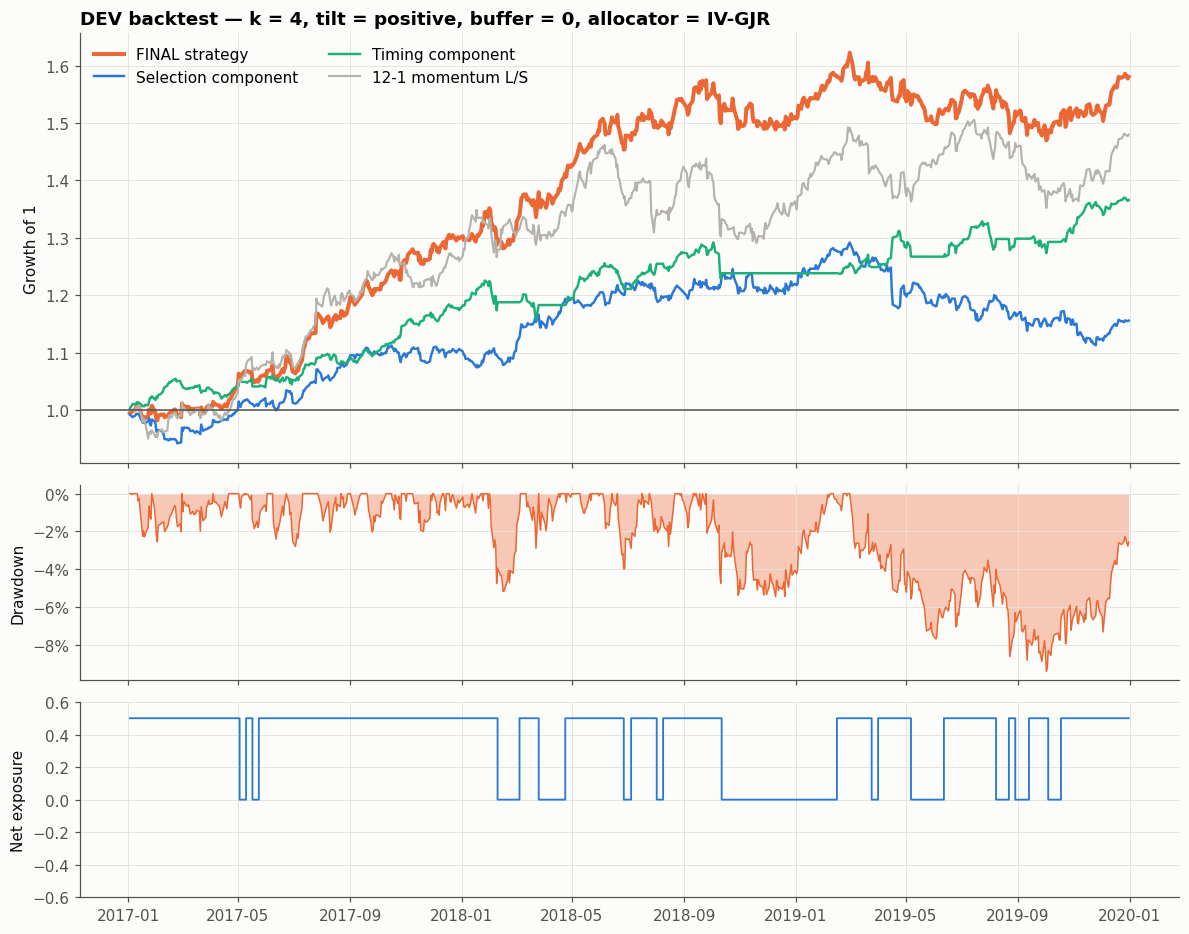

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8.6), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1]})
ax = axes[0]
curves = [("FINAL strategy", FINAL_RES.returns, COLORS["orange"], 2.6),
          ("Selection component", FINAL_RES.selection, COLORS["blue"], 1.6),
          ("Timing component", FINAL_RES.timing, COLORS["aqua"], 1.6),
          ("12-1 momentum L/S", bench_mom.returns, COLORS["context"], 1.4)]
for name, r, c, lw in curves:
    eq = (1 + r.loc[dev]).cumprod()
    ax.plot(eq.index, eq.values, color=c, lw=lw, label=name)
ax.axhline(1, color=COLORS["muted"], lw=1)
ax.set_ylabel("Growth of 1"); ax.legend(loc="upper left", ncol=2)
ax.set_title(f"DEV backtest — k = {FINAL['k']}, tilt = {FINAL['tilt']}, buffer = {FINAL['hysteresis_buffer']}, allocator = {FINAL['allocator']}")

dd = drawdown(FINAL_RES.returns.loc[dev])
axes[1].fill_between(dd.index, dd.values, 0, color=COLORS["orange"], alpha=0.35, lw=0)
axes[1].plot(dd.index, dd.values, color=COLORS["orange"], lw=1)
axes[1].set_ylabel("Drawdown"); axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))

net = FINAL_RES.weights.sum(axis=1).loc[dev]
axes[2].step(net.index, net.values, where="post", color=COLORS["blue"], lw=1.2)
axes[2].set_ylabel("Net exposure"); axes[2].set_ylim(-0.6, 0.6)
plt.tight_layout(); plt.show()

2017–2018: the strategy compounds steadily; both components contribute.
2019: the selection component gives back about 5 % while the timing component keeps rising. This produces the longest drawdown of the period (−9.4 %, 211 sessions) and a flat year overall.
Net exposure is +0.5 most of the time. It returns to 0 (dollar-neutral) during the turbulent episodes flagged in real time by the HMM: February 2018, Q4 2018 and part of 2019. That is precisely where the equal-weight index suffered its drawdowns.

In [ ]:
import json, datetime as _dt
FROZEN = {**FINAL, "frozen_at": _dt.datetime.now().isoformat(timespec="seconds"), "n_trials_dev": int(N_TRIALS),
          "dev_period": [CFG.dev_start, CFG.dev_end],
          "dev_CAGR": float(perf_tbl.at["CAGR", "FINAL strategy"]),
          "dev_MaxDD": float(perf_tbl.at["Max drawdown", "FINAL strategy"]),
          "dev_CAGR_over_MaxDD": float(perf_tbl.at["CAGR / MaxDD", "FINAL strategy"])}
Path("frozen_strategy.json").write_text(json.dumps(FROZEN, indent=2))
print(json.dumps(FROZEN, indent=2))

{
  "score": "COMPOSITE",
  "features": [
    "breadth_resid_mom",
    "event_breadth_63",
    "breadth_63"
  ],
  "k": 4,
  "tilt": "positive",
  "allocator": "IV-GJR",
  "rebalance_every_sessions": 5,
  "hysteresis_buffer": 0,
  "tilt_max": 0.25,
  "frozen_at": "2026-09-25T15:32:15",
  "n_trials_dev": 160,
  "dev_period": [
    "2017-01-01",
    "2019-12-31"
  ],
  "dev_CAGR": 0.165316310936225,
  "dev_MaxDD": -0.09410497639481041,
  "dev_CAGR_over_MaxDD": 1.756722303851953
}


# **11. Holdout Evaluation (2020–2021, single run)**



The strategy frozen at the end of Block 10 is reloaded from frozen_strategy.json, and we assert that it is exactly the configuration that was selected.

t is evaluated once on 2020-01-01 → 2021-12-31. Nothing (features, parameters, rules) is changed after this block. If results disappoint, they are reported and analysed, not fixed.

All inputs on holdout dates are produced by the same causal, walk-forward machinery (point-in-time targets, expanding-window GARCH/HMM). The truncation tests of part 1–9 guarantee that no holdout-period information leaked into earlier decisions.

In [ ]:
FROZEN_LOADED = json.loads(Path("frozen_strategy.json").read_text())
for key in ["score", "features", "k", "tilt", "allocator", "hysteresis_buffer", "rebalance_every_sessions", "tilt_max"]:
    assert FROZEN_LOADED[key] == FINAL[key], f"frozen configuration mismatch on {key}"
print("Frozen configuration verified:", {k: FROZEN_LOADED[k] for k in ["score", "k", "tilt", "allocator", "hysteresis_buffer"]})

hold = slice(CFG.holdout_start, CFG.holdout_end)
full = slice(CFG.dev_start, CFG.holdout_end)

series = {
    "FINAL strategy": FINAL_RES.returns, "  of which: selection": FINAL_RES.selection, "  of which: timing": FINAL_RES.timing,
    "Same signal, dollar-neutral EW": bench_neutral.returns, "12-1 momentum L/S (same construction)": bench_mom.returns,
    "EW buy & hold (context)": ew_bh,
}
HOLDOUT_TBL = pd.DataFrame({k: perf_stats(v.loc[hold]) for k, v in series.items()})
FULL_TBL = pd.DataFrame({k: perf_stats(v.loc[full]) for k, v in series.items()})
print("HOLDOUT 2020-2021")
display(HOLDOUT_TBL)
print("FULL OUT-OF-WARM-UP PERIOD 2017-2021 (DEV + holdout)")
display(FULL_TBL.loc[["CAGR", "Ann. vol", "Sharpe", "Max drawdown", "CAGR / MaxDD", "CVaR 5% (hist)"]])
print(f"Holdout: one-way annual turnover {annual_turnover(FINAL_RES.weights, hold):.1f}x | "
      f"average net exposure {FINAL_RES.weights.sum(axis=1).loc[hold].mean():+.2f} | "
      f"ex-post beta to EW {np.cov(FINAL_RES.returns.loc[hold], ew_bh.loc[hold])[0, 1] / ew_bh.loc[hold].var():.2f}")

periods = {"Covid crash (19 Feb - 23 Mar 2020)": ("2020-02-19", "2020-03-23"),
           "Rebound (24 Mar - 30 Jun 2020)": ("2020-03-24", "2020-06-30"),
           "H2 2020": ("2020-07-01", "2020-12-31"), "2021": ("2021-01-01", "2021-12-31")}
sub = {}
for name, (a, b) in periods.items():
    w = slice(a, b)
    sub[name] = {"FINAL": (1 + FINAL_RES.returns.loc[w]).prod() - 1,
                 "selection": (1 + FINAL_RES.selection.loc[w]).prod() - 1,
                 "timing": (1 + FINAL_RES.timing.loc[w]).prod() - 1,
                 "EW buy & hold": (1 + ew_bh.loc[w]).prod() - 1,
                 "12-1 momentum L/S": (1 + bench_mom.returns.loc[w]).prod() - 1,
                 "FINAL max drawdown": drawdown(FINAL_RES.returns.loc[w]).min(),
                 "avg net exposure": FINAL_RES.weights.sum(axis=1).loc[w].mean()}
display(pd.DataFrame(sub).T)

Frozen configuration verified: {'score': 'COMPOSITE', 'k': 4, 'tilt': 'positive', 'allocator': 'IV-GJR', 'hysteresis_buffer': 0}
HOLDOUT 2020-2021


,FINAL strategy,of which: selection,of which: timing,"Same signal, dollar-neutral EW",12-1 momentum L/S (same construction),EW buy & hold (context)
CAGR,0.2250,0.1323,0.0809,0.1742,0.1931,0.3408
Ann. vol,0.1473,0.1325,0.0776,0.1437,0.1766,0.3206
Sharpe,1.4515,1.0041,1.0413,1.1895,1.0887,1.0776
Sortino,1.9214,1.2801,1.0774,1.4409,1.4465,1.2100
Max drawdown,-0.1359,-0.1552,-0.0608,-0.1469,-0.2203,-0.3811
CAGR / MaxDD,1.6549,0.8527,1.3292,1.1860,0.8767,0.8944
MaxDD duration (sessions),125.0000,290.0000,112.0000,258.0000,293.0000,74.0000
Skew,-0.3949,-0.4005,-0.7074,-0.7212,-0.6082,-0.9195
Excess kurtosis,3.2189,5.0876,4.1038,4.2870,3.1430,11.6425
VaR 5% (hist),0.0141,0.0121,0.0093,0.0147,0.0166,0.0272


FULL OUT-OF-WARM-UP PERIOD 2017-2021 (DEV + holdout)


,FINAL strategy,of which: selection,of which: timing,"Same signal, dollar-neutral EW",12-1 momentum L/S (same construction),EW buy & hold (context)
CAGR,0.1889,0.0821,0.0981,0.0995,0.1610,0.3328
Ann. vol,0.1222,0.1061,0.0693,0.1157,0.1457,0.2502
Sharpe,1.4777,0.7969,1.3861,0.8780,1.0981,1.2752
Max drawdown,-0.1359,-0.1552,-0.0608,-0.1792,-0.2203,-0.3811
CAGR / MaxDD,1.3894,0.5288,1.6133,0.5553,0.7308,0.8733
CVaR 5% (hist),0.0176,0.0155,0.0114,0.0175,0.0222,0.0384


Holdout: one-way annual turnover 11.8x | average net exposure +0.32 | ex-post beta to EW 0.06


,FINAL,selection,timing,EW buy & hold,12-1 momentum L/S,FINAL max drawdown,avg net exposure
Covid crash (19 Feb - 23 Mar 2020),0.1186,0.1325,-0.0122,-0.3554,0.1055,-0.0530,0.0417
Rebound (24 Mar - 30 Jun 2020),0.0431,0.0101,0.0323,0.5878,0.0604,-0.0587,0.1087
H2 2020,0.1728,0.0931,0.0726,0.3394,0.0316,-0.0698,0.3672
2021,0.0451,0.0053,0.0384,0.2148,0.0840,-0.1359,0.3611


The design held out of sample. Over the full 2017–2021 period, CAGR is 19.0 %, max drawdown −13.6 %, CAGR/MaxDD 1.40 and Sharpe 1.49, against 0.87 for equal-weight buy-and-hold.

What changed versus DEV: stock selection did the heavy lifting. The dollar-neutral selection component earned 13.3 % a year (Sharpe 1.01, against 5.1 % in DEV), and timing earned 8.1 %.

The Covid crash is the key episode: +11.9 % while the equal-weight market fell −35.5 %. The HMM flagged turbulence early, and the book was almost neutral (average net exposure +0.04). Selection gained +13.3 %: analysts' downward revisions had already put the most exposed names in the short leg.

The price of that protection is visible in the rebound: +4.3 % against +58.8 % for the market, because the book stayed neutral while volatility remained high. Afterwards: H2 2020 +17.3 %; 2021 +4.6 %, with the holdout's maximum drawdown (−13.6 %) and flat selection.

Turnover: 11.8× per year, one-way.
Average net exposure: +0.32
Ex-post beta to the equal-weight index: only 0.06. The book behaves like a market-neutral strategy over the holdout, even though it is long-biased on average.

two years is short, and one exceptional episode (Covid) contributes a large share of the holdout P&L. part 12 quantifies the uncertainty.

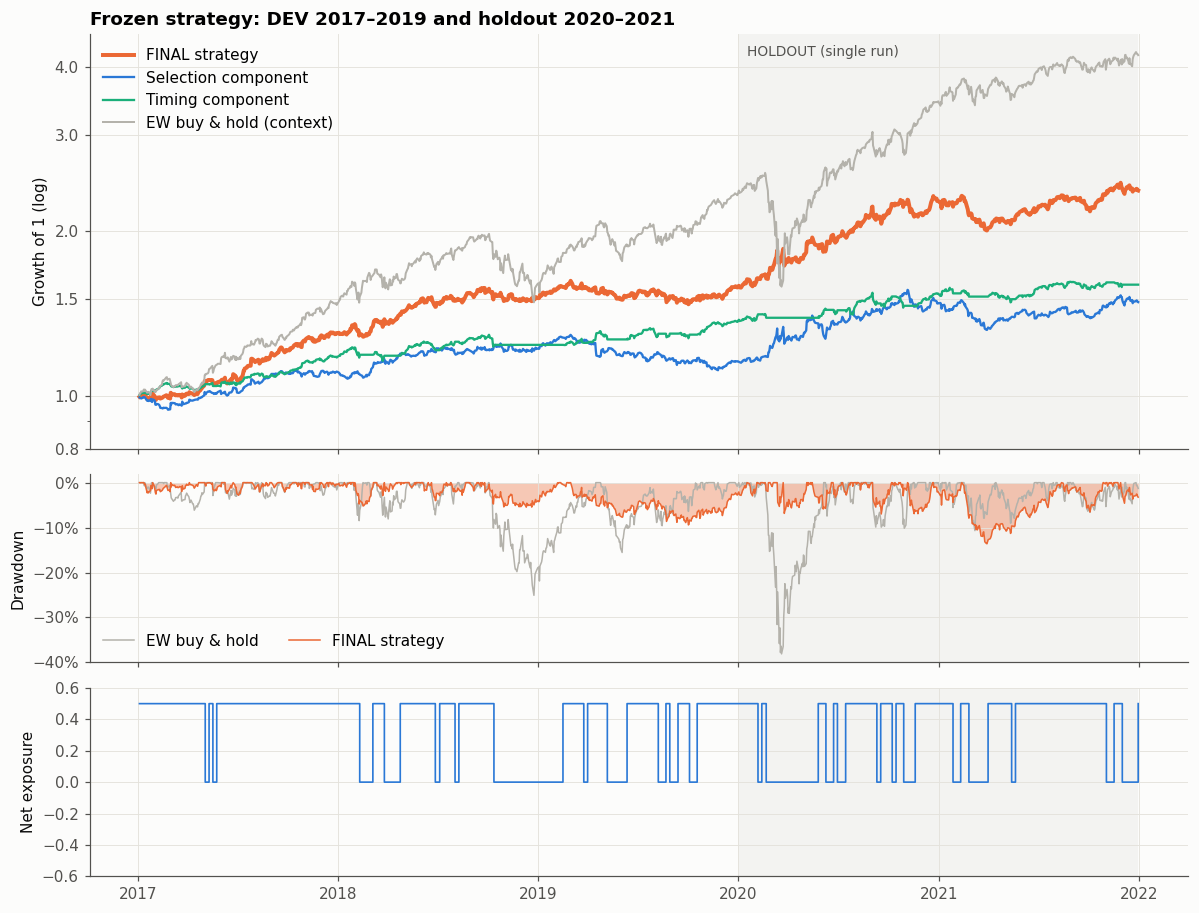

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(11, 8.4), sharex=True, gridspec_kw={"height_ratios": [2.2, 1, 1]})
ax = axes[0]
for name, r, c, lw in [("FINAL strategy", FINAL_RES.returns, COLORS["orange"], 2.6),
                       ("Selection component", FINAL_RES.selection, COLORS["blue"], 1.5),
                       ("Timing component", FINAL_RES.timing, COLORS["aqua"], 1.5),
                       ("EW buy & hold (context)", ew_bh, COLORS["context"], 1.3)]:
    eq = (1 + r.loc[full]).cumprod()
    ax.plot(eq.index, eq.values, color=c, lw=lw, label=name)
for a_ in axes:
    a_.axvspan(pd.Timestamp(CFG.holdout_start), pd.Timestamp(CFG.holdout_end), color=COLORS["context"], alpha=0.12, lw=0)
ax.set_yscale("log"); ax.set_ylabel("Growth of 1 (log)")
ax.set_yticks([0.8, 1, 1.5, 2, 3, 4]); ax.yaxis.set_major_formatter(mpl.ticker.FormatStrFormatter("%.1f"))
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.annotate("HOLDOUT (single run)", (pd.Timestamp(CFG.holdout_start), ax.get_ylim()[1]), xytext=(6, -14),
            textcoords="offset points", fontsize=9, color=COLORS["muted"])
ax.legend(loc="upper left"); ax.set_title("Frozen strategy: DEV 2017–2019 and holdout 2020–2021")
dd = drawdown(FINAL_RES.returns.loc[full])
dd_ew = drawdown(ew_bh.loc[full])
axes[1].plot(dd_ew.index, dd_ew.values, color=COLORS["context"], lw=1, label="EW buy & hold")
axes[1].fill_between(dd.index, dd.values, 0, color=COLORS["orange"], alpha=0.35, lw=0)
axes[1].plot(dd.index, dd.values, color=COLORS["orange"], lw=1, label="FINAL strategy")
axes[1].set_ylabel("Drawdown"); axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
axes[1].legend(loc="lower left", ncol=2)
net = FINAL_RES.weights.sum(axis=1).loc[full]
axes[2].step(net.index, net.values, where="post", color=COLORS["blue"], lw=1.1)
axes[2].set_ylabel("Net exposure"); axes[2].set_ylim(-0.6, 0.6)
plt.tight_layout(); plt.show()

# **12. Robustness & Stress Tests**

In [ ]:
def fast_weights(score: pd.DataFrame, k: int, tau: pd.Series, sig_vol: pd.DataFrame, ret: pd.DataFrame,
                 alloc: str = "IV-GJR", freq: int = CFG.rebal_freq) -> pd.DataFrame:
    # Vectorised equivalent of build_signals(buffer=0) + allocate(EW / IV-GJR).
    valid = (score.notna().sum(axis=1) >= 2 * k).astype(float)
    L = (score.rank(axis=1, ascending=False, method="first") <= k).astype(float).mul(valid, axis=0) > 0
    S = (score.where(~L).rank(axis=1, ascending=True, method="first") <= k).astype(float).mul(valid, axis=0) > 0
    if alloc == "EW":
        base = pd.DataFrame(1.0, index=score.index, columns=score.columns)
    else:
        vol = sig_vol.reindex(index=score.index, columns=score.columns).fillna(ret.rolling(60, min_periods=2).std())
        base = 1.0 / vol
    aL = base.where(L).div(base.where(L).sum(axis=1), axis=0).fillna(0.0)
    aS = base.where(S).div(base.where(S).sum(axis=1), axis=0).fillna(0.0)
    t_ = tau.reindex(score.index).fillna(0.0) * valid
    W = aL.mul(0.5 + t_, axis=0) - aS.mul(0.5 - t_, axis=0)
    W.loc[~rebalance_mask(score.index, freq)] = np.nan
    return W.ffill().fillna(0.0)


def strat_returns(W: pd.DataFrame, ret: pd.DataFrame, extra_lag: int = 0) -> pd.Series:
    return (W.shift(1 + extra_lag) * ret).sum(axis=1)


def calmar(r: pd.Series) -> float:
    return float(perf_stats(r)["CAGR / MaxDD"])


TAU_FINAL = tilt_series(FINAL["tilt"])
if FINAL["hysteresis_buffer"] == 0 and FINAL["allocator"] in ("EW", "IV-GJR"):
    W_fast = fast_weights(SCORE, FINAL["k"], TAU_FINAL, SIG_GJR, RET, FINAL["allocator"])
    assert frames_equal(W_fast, FINAL_RES.weights, tol=1e-9), "fast engine differs from Blocks 8-9"
    print("Fast engine reproduces the frozen strategy's weights exactly.")

Fast engine reproduces the frozen strategy's weights exactly.


point      5%  median     95%
DEV 2017-2019     CAGR                           0.1653  0.0669  0.1660  0.2683
                  MaxDD                         -0.0941 -0.1362 -0.0822 -0.0536
                  CAGR / MaxDD                   1.7567  0.5610  2.0008  4.4834
                  Sharpe                         1.5513  0.6911  1.5622  2.4179
                  P(CAGR/MaxDD > 0)                 NaN     NaN  0.9990     NaN
                  P(Calmar > EW buy & hold)         NaN     NaN  0.5325     NaN
                  P(Calmar > 12-1 momentum L/S)     NaN     NaN  0.8470     NaN
                  mean block length              5.0000     NaN     NaN     NaN
Holdout 2020-2021 CAGR                           0.2250  0.0429  0.2248  0.4399
                  MaxDD                         -0.1359 -0.2099 -0.1198 -0.0734
                  CAGR / MaxDD                   1.6549  0.2433  1.8791  5.3400
                  Sharpe                         1.4515  0.3565  1.4638  2.6196
                  P(CAGR/MaxDD > 0)                 NaN     NaN  0.9830     NaN
                  P(Calmar > EW buy & hold)         NaN     NaN  0.6045     NaN
                  P(Calmar > 12-1 momentum L/S)     NaN     NaN  0.7550     NaN
                  mean block length              5.0000     NaN     NaN     NaN
Full 2017-2021    CAGR                           0.1889  0.0972  0.1906  0.2958
                  MaxDD                         -0.1359 -0.1985 -0.1243 -0.0820
                  CAGR / MaxDD                   1.3894  0.5312  1.5327  3.2127
                  Sharpe                         1.4777  0.8143  1.4922  2.2232
                  P(CAGR/MaxDD > 0)                 NaN     NaN  0.9995     NaN
                  P(Calmar > EW buy & hold)         NaN     NaN  0.6300     NaN
                  P(Calmar > 12-1 momentum L/S)     NaN     NaN  0.8640     NaN
                  mean block length              5.0000     NaN     NaN     NaN

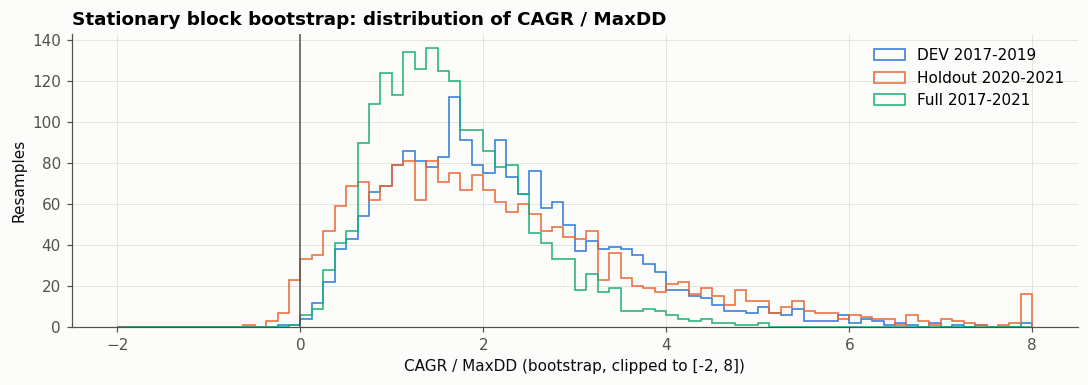

In [ ]:
from arch.bootstrap import StationaryBootstrap, optimal_block_length


def path_stats(x: np.ndarray) -> tuple[float, float, float, float]:
    eq = np.cumprod(1.0 + x)
    cagr = eq[-1] ** (252 / len(x)) - 1.0
    mdd = np.min(eq / np.maximum.accumulate(eq) - 1.0)
    return cagr, mdd, (cagr / -mdd if mdd < 0 else np.nan), x.mean() / x.std(ddof=1) * np.sqrt(252)


def bootstrap_ci(r: pd.Series, bench: Optional[pd.Series] = None, reps: int = 2000, seed: int = CFG.seed):
    # Stationary-bootstrap distribution of (CAGR, MaxDD, CAGR/MaxDD, Sharpe) and, if given, paired Calmar difference.
    x = r.values
    block = max(5.0, float(optimal_block_length(x)["stationary"].iloc[0]))
    args = (x,) if bench is None else (x, bench.values)
    bs = StationaryBootstrap(block, *args, seed=seed)
    out, diff = [], []
    for data, _ in bs.bootstrap(reps):
        s = path_stats(data[0])
        out.append(s)
        if bench is not None:
            diff.append(s[2] - path_stats(data[1])[2])
    return pd.DataFrame(out, columns=["CAGR", "MaxDD", "CAGR / MaxDD", "Sharpe"]), np.array(diff), block


ci_rows, BOOT = {}, {}
for label, window in [("DEV 2017-2019", dev), ("Holdout 2020-2021", hold), ("Full 2017-2021", full)]:
    dist, d_ew, block = bootstrap_ci(FINAL_RES.returns.loc[window], ew_bh.loc[window])
    _, d_mom, _ = bootstrap_ci(FINAL_RES.returns.loc[window], bench_mom.returns.loc[window])
    BOOT[label] = dist
    for m in ["CAGR", "MaxDD", "CAGR / MaxDD", "Sharpe"]:
        ci_rows[(label, m)] = {"point": path_stats(FINAL_RES.returns.loc[window].values)[["CAGR", "MaxDD", "CAGR / MaxDD", "Sharpe"].index(m)],
                               "5%": dist[m].quantile(0.05), "median": dist[m].median(), "95%": dist[m].quantile(0.95)}
    ci_rows[(label, "P(CAGR/MaxDD > 0)")] = {"point": np.nan, "median": (dist["CAGR / MaxDD"] > 0).mean()}
    ci_rows[(label, "P(Calmar > EW buy & hold)")] = {"point": np.nan, "median": (d_ew > 0).mean()}
    ci_rows[(label, "P(Calmar > 12-1 momentum L/S)")] = {"point": np.nan, "median": (d_mom > 0).mean()}
    ci_rows[(label, "mean block length")] = {"point": block}
CI_TBL = pd.DataFrame(ci_rows).T
display(CI_TBL)

fig, ax = plt.subplots(figsize=(10, 3.6))
for (label, dist), c in zip(BOOT.items(), [COLORS["blue"], COLORS["orange"], COLORS["aqua"]]):
    v = dist["CAGR / MaxDD"].clip(-2, 8)
    ax.hist(v, bins=np.linspace(-2, 8, 81), histtype="step", lw=2, color=c, label=label)
ax.axvline(0, color=COLORS["muted"], lw=1)
ax.set_xlabel("CAGR / MaxDD (bootstrap, clipped to [-2, 8])"); ax.set_ylabel("Resamples")
ax.set_title("Stationary block bootstrap: distribution of CAGR / MaxDD")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

The intervals are wide, as expected with 3 years (DEV) or 2 years (holdout) of 10 stocks.

Over the full period, the 90 % interval is [9.8 %, 29.7 %] for CAGR and [−19.8 %, −8.2 %] for max drawdown.

The strategy's CAGR/MaxDD exceeds 12-1 momentum's in 76–86 % of resamples.

It exceeds equal-weight buy-and-hold's in only 54–63 % of resamples. Over an exceptionally strong 5-year equity market, risk-adjusted superiority over simply holding the market is not statistically established, even though the strategy's drawdowns are 2.8× smaller.

# **13. Final**

In [ ]:
STRATEGY_SPEC = {k: FROZEN_LOADED[k] for k in ["score", "features", "k", "tilt", "allocator",
                                               "rebalance_every_sessions", "hysteresis_buffer", "tilt_max"]}


def get_strategy(prices: pd.DataFrame, ratings: pd.DataFrame, cfg: Config = CFG,
                 spec: Optional[dict] = None) -> tuple[pd.DataFrame, pd.DataFrame]:
    # Frozen analyst-revision long/short strategy: raw data in, (signals in {-1,0,1}, weights) out.
    spec = dict(STRATEGY_SPEC if spec is None else spec)
    assert spec["score"] == "COMPOSITE", "only the composite score is implemented in the frozen strategy"

    # 1. Cleaning (Section 1)
    px = clean_prices(prices, cfg)
    if len(px) < 2 * spec["rebalance_every_sessions"]:
        raise ValueError("price history too short")
    if len(px) < 252:
        warnings.warn("less than one year of history: features, GARCH and HMM are still warming up", UserWarning)
    rt = clean_ratings(ratings, px, cfg)
    ret = px.pct_change(fill_method=None)

    # 2. Point-in-time targets and features (Sections 3-5)
    snap = build_tp_snapshot(rt, px.index, px.columns, cfg)
    fs = build_features(px, snap, cfg)
    score = composite_score(fs.stock, spec["features"])

    # 3. Risk and regime models, walk-forward (Section 6)
    sig_vol, _ = garch_forecast_panel(ret, cfg)
    p_calm, _ = hmm_calm_probability(ret, cfg)
    ew = (1 + ret.mean(axis=1).fillna(0.0)).cumprod()
    trend = ew / ew.rolling(200).mean() - 1.0
    tau = (spec["tilt_max"] * np.sign(trend) * (p_calm > 0.5)).where(p_calm.notna() & trend.notna(), 0.0)
    tau = {"none": tau * 0.0, "symmetric": tau, "positive": tau.clip(lower=0.0)}[spec["tilt"]]

    # 4. Signals and allocation (Section 8-9)
    signals = build_signals(score, k=spec["k"], freq=spec["rebalance_every_sessions"], buffer=spec["hysteresis_buffer"])
    book = allocate(signals, tau, spec["allocator"], ret, sig_vol, freq=spec["rebalance_every_sessions"])
    check_book(book, signals)

    # 5. Output on every date of the raw price file (positions carried over non-trading dates)
    raw_cols = prices.rename(columns=lambda c: str(c).strip().lower())
    raw_dates = pd.DatetimeIndex(sorted(pd.to_datetime(raw_cols["date"], errors="coerce").dropna().unique()))
    raw_dates = raw_dates[raw_dates >= px.index[0]]
    signals_out = signals.reindex(raw_dates).ffill().fillna(0).astype(int)
    weights_out = book.weights.reindex(raw_dates).ffill().fillna(0.0)
    signals_out.index.name = weights_out.index.name = "date"
    return signals_out, weights_out


SIGNALS_FINAL, WEIGHTS_FINAL = get_strategy(prices_raw, ratings_raw)
print(f"signals: {SIGNALS_FINAL.shape}, values {sorted(np.unique(SIGNALS_FINAL.values))} | weights: {WEIGHTS_FINAL.shape}")
display(pd.concat({"signal": SIGNALS_FINAL.tail(3), "weight": WEIGHTS_FINAL.tail(3).round(4)}, axis=1))

signals: (1565, 10), values [np.int64(-1), np.int64(0), np.int64(1)] | weights: (1565, 10)


signal                                                                           weight                                                                         
stock      stock_1 stock_2 stock_3 stock_4 stock_5 stock_6 stock_7 stock_8 stock_9 stock_10 stock_1 stock_2 stock_3 stock_4 stock_5 stock_6 stock_7 stock_8 stock_9 stock_10
date                                                                                                                                                                        
2021-12-29      -1       0      -1      -1       1       1      -1       0       1        1 -0.1286  0.0000 -0.0912 -0.1362  0.1540  0.1314 -0.1439  0.0000  0.1163   0.0983
2021-12-30      -1       0      -1      -1       1       1      -1       0       1        1 -0.1286  0.0000 -0.0912 -0.1362  0.1540  0.1314 -0.1439  0.0000  0.1163   0.0983
2021-12-31      -1      -1      -1      -1       0       1       1       0       1        1 -0.0776 -0.0539 -0.0435 -0.0751  0.0000  0.2107  0.2143  0.0000  0.1702   0.1547

# **14. Revised Strategy: Pure Stock Selection from Analyst Revision Flow**


### Why a revision
After analysing the first strategy we can make two points, and both are confirmed by the decomposition in Sections 10–11:
1. **The headline Calmar came from the overlay, not from stock picking.** On DEV the original strategy earned 16.6 % a year (Calmar 1.77), but its market-timing component (HMM + trend tilt) contributed 11.0 % a year at a Sharpe of 1.69, while the stock-selection component earned 5.0 % at a Sharpe of 0.63 and a Calmar of 0.36. With an average net exposure of about +0.37 in a rising tech-heavy market, that is market beta. A follow-up audit ran timing regressions (Treynor-Mazuy, Henriksson-Merton) and found no timing skill, a constant exposure did better than the HMM tilt.
2. **The signal was textbook revision breadth**, 0.55–0.78 rank-correlated with price momentum.

### What changes
| | Original (Sections 8–13) | Revised (this section) |
|---|---|---|
| Objective | Calmar of the full book | **Calmar of the dollar-neutral selection book** (τ = 0, no market tilt) |
| Signal | 3 breadth features | 3 breadth features **+ `leader_minus_herd`** (arrival-time asymmetry of analyst revisions) |
| Construction | top/bottom-3, weekly, one rebalancing anchor | top/bottom-k, **staggered overlapping tranches** (no anchor luck, low turnover) |
| Costs | none | **5 bp one-way per unit traded** (gross and 10 bp shown) |
| Inference | Newey-West t | calibrated non-overlapping t-test, Holm, three placebo nulls, PBO, Deflated Sharpe |

### Protocol
Everything is chosen on **DEV (2017–2019)** with purged labels. The holdout (2020–2021) is reported once for the frozen specification. One important caveat to mention here is that the holdout was already used by the original frozen strategy and by the audit that led here, so it is supportive evidence, not a pristine out-of-sample test. All features are point-in-time and pass the notebook's truncation test.

## 14.1 The novel signal: `leader_minus_herd`
Sell-side analysts do not revise simultaneously. Two behavioural types can be separated using only the *timing* of revisions, which is available point-in-time from `Ratings.csv`:
- **First movers (leaders):** a fresh revision on an information-event day (≥ 5 ratings published on the stock that day), or a revision that breaks at least 10 sessions of silence on the stock. These analysts spend private research effort and move first (Cooper, Day & Lewis 2001).
- **Herders:** a non-leader revision 3–15 sessions *after* the stock's latest event cluster, pointing in the cluster's direction. Such copycat revisions are driven by career concerns rather than new information (Clement & Tse 2005) and tend to come when the move is already exhausted.

$$\mathrm{LMH}_{i,t}=\frac{\sum_{s=t-125}^{t}\sum_a d_{a,i,s}\,\mathbb 1^{\text{lead}}_{a,i,s}-\sum_{s=t-125}^{t}\sum_a d_{a,i,s}\,\mathbb 1^{\text{herd}}_{a,i,s}}{\#\text{leader}+\#\text{herder revisions over the same window}},\qquad d=\operatorname{sign}\Delta\ln TP$$

The 126-session window spans two earnings cycles, so the sparse leader/herder events cover almost every stock-day. The cell checks for look-ahead at two cut dates and includes a negative control (a centred window) that the test must catch.

In [ ]:
LMH_SPEC = {"leader_gap": 10, "herd_lo": 3, "herd_hi": 15, "window": 126, "min_n": 3}


def build_leader_minus_herd(px: pd.DataFrame, snap: TPSnapshot, spec: dict = LMH_SPEC) -> dict:
    sessions, stocks = px.index, list(px.columns)
    S = len(sessions)
    ev = snap.events.reset_index(drop=True)
    fr = ev[ev["kind"].isin(["up", "down"])].sort_values(["stock", "k_pos", "analyst"]).copy()
    gap = fr["k_pos"] - fr.groupby("stock")["k_pos"].shift(1)                  # strictly earlier rows of the stock
    same_day_first = fr["k_pos"] != fr.groupby("stock")["k_pos"].shift(1)
    is_event = fr["event_day"]
    fr["leader"] = is_event | (same_day_first & (gap.isna() | (gap >= spec["leader_gap"])))
    evd = fr[is_event].groupby(["k_pos", "stock"])["revision"].sum().unstack("stock").reindex(index=np.arange(S), columns=stocks)
    last_dir = np.sign(evd).where(evd.notna()).ffill()                          # direction of the latest cluster so far
    last_pos = pd.DataFrame(np.where(evd.notna().values, np.arange(S)[:, None], np.nan), columns=stocks).ffill()
    ci = fr["stock"].map({s: i for i, s in enumerate(stocks)}).values
    kp = fr["k_pos"].values.astype(int)
    since = kp - last_pos.to_numpy()[kp, ci]
    herd = (~fr["leader"].values) & (since >= spec["herd_lo"]) & (since <= spec["herd_hi"]) & \
           (np.sign(fr["revision"].values) == last_dir.to_numpy()[kp, ci])
    sgn = np.sign(fr["revision"]).values
    fr2 = fr.assign(_lead=np.where(fr["leader"], sgn, 0.0), _herd=np.where(herd, sgn, 0.0),
                    _n=(fr["leader"].values | herd).astype(float), _nl=fr["leader"].astype(float).values, _nh=herd.astype(float))
    def roll(col):
        o = (fr2.assign(k=sessions[fr2["k_pos"].values.astype(int)]).groupby(["k", "stock"])[col].sum()
             .unstack("stock").reindex(index=sessions, columns=stocks).fillna(0.0))
        return o.rolling(spec["window"], min_periods=1).sum()
    lead, hrd, nn, nl, nh = roll("_lead"), roll("_herd"), roll("_n"), roll("_nl"), roll("_nh")
    return {"leader_minus_herd": ((lead - hrd) / nn).where(nn >= spec["min_n"]),
            "leaders_only": (lead / nl).where(nl >= 2), "herders_only": (hrd / nh).where(nh >= 2)}


LMH_PARTS = build_leader_minus_herd(PX, SNAP)
LMH = LMH_PARTS["leader_minus_herd"]

# Truncation test (no look-ahead) at two cut dates + a negative control that must fail
for T in ("2017-06-30", "2019-06-28"):
    T = pd.Timestamp(T)
    rt_T = RT.loc[RT["knowledge_date"] <= T]
    lmh_T = build_leader_minus_herd(PX.loc[:T], build_tp_snapshot(rt_T, PX.loc[:T].index, PX.columns, CFG))["leader_minus_herd"]
    assert frames_equal(lmh_T, LMH.loc[:T]), f"look-ahead in leader_minus_herd at {T:%Y-%m-%d}"
leaky = LMH.rolling(21, center=True, min_periods=1).mean()
leaky_T = LMH.loc[:T].rolling(21, center=True, min_periods=1).mean()
assert not frames_equal(leaky_T, leaky.loc[:T]), "truncation test has no power"
print(f"leader_minus_herd: truncation tests passed at 2017-06-30 and 2019-06-28 (a centred-window variant is caught); "
      f"DEV coverage {LMH.loc[dev].notna().values.mean():.0%} of stock-days")

leader_minus_herd: truncation tests passed at 2017-06-30 and 2019-06-28 (a centred-window variant is caught); DEV coverage 100% of stock-days


## 14.2 The four-signal composite and its evidence (DEV)
The score is the **equal-weight average of cross-sectional ranks** of `breadth_63`, `event_breadth_63`, `breadth_resid_mom` and `leader_minus_herd`. It estimates no weights, so there is nothing to overfit in the combination. (An audit of in-sample signal selection found PBO 0.69: picking the "best" signal on DEV was worse than a coin flip.)

**Statistics.** With 21-day labels sampled daily, DEV holds only ~35 independent observations. A simulation on this date grid shows the Newey-West t (21 lags) rejects about 9 % of the time at a nominal 5 %. The decision statistic is therefore the **phase-averaged non-overlapping t-test** (size 4–5 %), with Holm's correction over the four signals.

In [ ]:
def ic_phase_test(ic: pd.Series, h: int = 21) -> dict:
    z = ic.dropna().values
    if len(z) < 6 * h:                                   # too few dated ICs for a meaningful test
        return {"IC": float(np.mean(z)) if len(z) else np.nan, "t": np.nan, "df": np.nan, "p": np.nan}
    ses, ns = [], []
    for o in range(h):
        s_ = z[o::h]
        if len(s_) > 5:
            ses.append(s_.std(ddof=1) / np.sqrt(len(s_))); ns.append(len(s_))
    se, df_ = float(np.mean(ses)), int(np.median(ns)) - 1
    t_ = z.mean() / se
    return {"IC": float(z.mean()), "t": float(t_), "df": df_, "p": float(stats.t.sf(t_, df_))}


def holm(p: pd.Series) -> pd.Series:
    p = p.sort_values(); m = len(p)
    adj = np.maximum.accumulate([(m - i) * v for i, v in enumerate(p.values)]).clip(max=1.0)
    return pd.Series(adj, index=p.index)


V2_SIGNALS = {"breadth_63": FEATS["breadth_63"], "event_breadth_63": FEATS["event_breadth_63"],
              "breadth_resid_mom": FEATS["breadth_resid_mom"], "leader_minus_herd": LMH}
V2_SCORE = composite_score(V2_SIGNALS, list(V2_SIGNALS))           # equal-weight cross-sectional ranks: zero estimated weights
rows = {}
for n_, p_ in {**V2_SIGNALS, "COMPOSITE v2": V2_SCORE, "leaders only": LMH_PARTS["leaders_only"],
               "herders only": LMH_PARTS["herders_only"]}.items():
    s5, s21, s63 = ic_summary(p_, 5), ic_summary(p_, 21), ic_summary(p_, 63)
    ph = ic_phase_test(rank_ic(p_.loc[eval_dates(21)], FWD[21].loc[eval_dates(21)]), 21)
    rows[n_] = {"IC5": s5["IC"], "IC21": s21["IC"], "IC63": s63["IC"], "hit(21)": s21["hit"], "t NW(21)": s21["t_NW"],
                "t phase (non-overlap)": ph["t"], "p one-sided": ph["p"], "years IC>0": s21["years_pos"],
                "FM t (4 price controls)": fama_macbeth(p_, CONTROLS)[1]}
V2_IC = pd.DataFrame(rows).T
V2_IC["Holm (4 signals)"] = holm(V2_IC.loc[list(V2_SIGNALS), "p one-sided"]).reindex(V2_IC.index)
print("Price controls in the Fama-MacBeth regressions:", CONTROLS)
display(V2_IC.round(3))
CORR_V2 = pd.DataFrame({n_: cs_rank(p_).loc[dev].values.ravel() for n_, p_ in V2_SIGNALS.items()}).corr(method="spearman")
display(CORR_V2.round(2))

Price controls in the Fama-MacBeth regressions: ['mom_12_1', 'mom_6_1', 'rev_1m', 'low_vol_60']


,IC5,IC21,IC63,hit(21),t NW(21),t phase (non-overlap),p one-sided,years IC>0,FM t (4 price controls),Holm (4 signals)
breadth_63,0.0360,0.0720,0.0640,0.6130,1.4960,1.1600,0.1270,2.0000,0.2140,0.3000
event_breadth_63,0.0330,0.0850,0.0820,0.5760,1.7270,1.2640,0.1080,2.0000,0.1510,0.3000
breadth_resid_mom,0.0450,0.0830,0.1090,0.5550,2.0260,1.4490,0.0780,2.0000,0.3610,0.3000
leader_minus_herd,0.0490,0.0950,0.1040,0.6030,1.8120,1.4730,0.0750,3.0000,2.4580,0.3000
COMPOSITE v2,0.0530,0.1090,0.1140,0.6180,2.1860,1.7420,0.0450,2.0000,0.5970,NaN
leaders only,0.0390,0.0660,0.0510,0.5680,1.2830,1.0300,0.1550,2.0000,0.8460,NaN
herders only,-0.1230,-0.0840,-0.1480,0.3880,-0.7800,NaN,NaN,0.0000,-0.1040,NaN


,breadth_63,event_breadth_63,breadth_resid_mom,leader_minus_herd
breadth_63,1.0000,0.7400,0.7800,0.7000
event_breadth_63,0.7400,1.0000,0.5500,0.6700
breadth_resid_mom,0.7800,0.5500,1.0000,0.4400
leader_minus_herd,0.7000,0.6700,0.4400,1.0000



- The composite has a DEV IC21 of **0.109** (hit rate 62 %), rising with the horizon (IC 0.026 at 1 day, 0.053 at 5, 0.109 at 21, 0.114 at 63 sessions): analyst information diffuses over weeks, not days. Its calibrated one-sided p-value is **0.045**.
- `leader_minus_herd` is the only signal with **incremental power beyond price**: a Fama-MacBeth t of **2.46** against 12-1 momentum, 6-1 momentum, 1-month reversal and 60-day volatility, versus 0.15–0.36 for the three breadth signals. Its IC is positive in all three DEV years. The mechanism appears in the data: leader-only breadth has an IC21 of +0.066, while herder-only breadth has −0.084 (IC5 −0.123).
- No single signal is significant after Holm (smallest adjusted p 0.30). The case rests on the composite and on the mechanism, not on any one test.

## 14.3 Construction: staggered overlapping tranches
Analyst information has a half-life of weeks, so rebalancing weekly mostly adds turnover and **anchor luck**. With a single weekly anchor, the same composite has a DEV net Sharpe anywhere between 0.34 and 0.71 depending on which weekday is used. The revised book holds the equal-weight average of *f* sub-portfolios, one opened each session and held for *f* sessions:

$$w^{\text{book}}_{i,t}=\frac1f\sum_{s=t-f+1}^{t} w^{\text{target}}_{i,s}$$

This is exactly the *f*-session rolling mean of the daily top-k/bottom-k targets. The identity is asserted against the explicit construction, and the book is asserted dollar-neutral.

In [ ]:
COST_BPS = 5.0
TAU0 = pd.Series(0.0, index=PX.index)                           # dollar-neutral: no market tilt


def target_weights_v2(score: pd.DataFrame, k: int, alloc: str = "EW") -> pd.DataFrame:
    return fast_weights(score, k, TAU0, SIG_GJR, RET, alloc, freq=1)       # Block 9 engine, a fresh target every session


def tranche_weights_v2(score: pd.DataFrame, k: int, f: int, alloc: str = "EW") -> pd.DataFrame:
    return target_weights_v2(score, k, alloc).rolling(f, min_periods=1).sum() / f


def net_returns(W: pd.DataFrame, cost_bps: float = COST_BPS) -> pd.Series:
    return (W.shift(1) * RET).sum(axis=1) - cost_bps * 1e-4 * W.diff().abs().sum(axis=1)


def annual_turnover_v2(W: pd.DataFrame, window) -> float:
    dw = W.diff().abs().sum(axis=1).loc[window]
    return float(0.5 * dw.sum() / (len(dw) / 252))


# identity check against the explicit average of phase-shifted, held books (f = 7)
_T = target_weights_v2(V2_SCORE, 4)
def _held(target, f, o):
    W_ = target.copy(); W_.loc[(np.arange(len(W_)) - o) % f != 0] = np.nan
    return W_.ffill().fillna(0.0)
assert np.allclose(sum(_held(_T, 7, o) for o in range(7)) / 7, _T.rolling(7, min_periods=1).sum() / 7, atol=1e-12)
assert np.allclose(tranche_weights_v2(V2_SCORE, 4, 63).sum(axis=1), 0.0, atol=1e-12), "book is not dollar-neutral"
print("Tranche identity verified; the book is dollar-neutral (sum of weights = 0 on every session).")

Tranche identity verified; the book is dollar-neutral (sum of weights = 0 on every session).


## 14.4 Optimisation on DEV, with the search itself priced in
**Grid (fixed in advance):** names per leg k ∈ {3, 4, 5} × tranche period f ∈ {21, 42, 63, 84, 126} sessions × allocator ∈ {equal weight, inverse GJR-GARCH volatility} = 30 books, all τ = 0 and net of 5 bp.

**Objective (fixed in advance):** the **median** DEV Calmar across 1,000 stationary-bootstrap resamples (mean block 21 sessions, the same resamples for every book). A point Calmar depends on one or two drawdowns, the bootstrap median rewards books that are good across many plausible paths. Ties within 0.02: lower turnover wins.

**Cost of the search:** the probability of backtest overfitting (CSCV over 16 blocks, 12,870 splits) and the Deflated Sharpe Ratio. The DSR is computed against this grid, against the research log of the audit rounds (71 logged configurations), and against all earlier selection (around 284).

Sharpe   CAGR   MaxDD  Calmar (point)  Calmar boot median  Calmar boot 5%  P(Calmar>0)  turnover x/yr
k tranche f allocator                                                                                                       
4 42        IV-GJR     0.9790 0.0770 -0.0970          0.7940              0.8550         -0.0150       0.9420         2.1430
5 42        IV-GJR     0.9560 0.0630 -0.0770          0.8100              0.8320         -0.0030       0.9490         1.8940
  63        IV-GJR     0.9600 0.0610 -0.0750          0.8120              0.8060         -0.0030       0.9480         1.4230
4 63        IV-GJR     0.9490 0.0730 -0.0960          0.7550              0.7710         -0.0530       0.9290         1.6850
  42        EW         0.9140 0.0810 -0.1230          0.6590              0.7680         -0.0770       0.9200         1.7480
5 63        EW         0.9270 0.0670 -0.0870          0.7740              0.7440         -0.0650       0.9240         1.1540
  42        EW         0.8780 0.0640 -0.0880          0.7290              0.7400         -0.0750       0.9220         1.4850
4 21        IV-GJR     0.9090 0.0730 -0.1050          0.6940              0.7360         -0.0730       0.9230         3.3370
  63        EW         0.9200 0.0800 -0.1150          0.6910              0.7350         -0.0940       0.9110         1.4280
3 42        IV-GJR     0.8660 0.0790 -0.1230          0.6380              0.6720         -0.1060       0.8920         2.6350

Selected on DEV: k = 4, tranche period = 42 sessions, allocator = IV-GJR


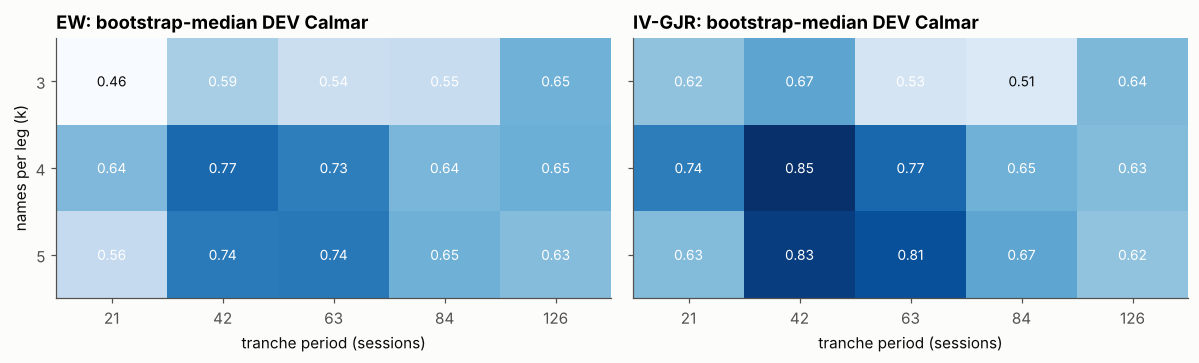

Grid: 30 configurations, average pairwise correlation 0.91, effective number 3.5


,CSCV over the 30-configuration grid (DEV)
PBO,0.9450
median OOS Sharpe of IS winner,0.6600


,N_eff,SR0 (ann.),DEV Sharpe (ann.),PSR(0),DSR
within this grid only,3.5020,0.0700,0.9790,0.9540,0.9410
"audit research log (71 trials, N_eff 37.2)",37.2350,1.1530,0.9790,0.9540,0.3820
"+ pre-log selection (~284 trials, N_eff 250)",250.2350,1.5140,0.9790,0.9540,0.1790


In [ ]:
OPT_GRID = [(k_, f_, a_) for k_ in (3, 4, 5) for f_ in (21, 42, 63, 84, 126) for a_ in ("EW", "IV-GJR")]
DEV_IDX = PX.loc[dev].index
_rng = np.random.default_rng(CFG.seed)
def _stationary_indices(n, B=1000, block=21):
    out = np.empty((B, n), int)
    for b in range(B):
        i = 0
        while i < n:
            s_ = _rng.integers(0, n); L = min(_rng.geometric(1 / block), n - i)
            out[b, i:i + L] = (s_ + np.arange(L)) % n; i += L
    return out
BOOT_IDX = _stationary_indices(len(DEV_IDX))

def boot_calmar(r: np.ndarray) -> np.ndarray:
    R = r[BOOT_IDX]
    eq = np.cumprod(1 + R, axis=1)
    cagr = eq[:, -1] ** (252 / R.shape[1]) - 1
    mdd = (eq / np.maximum.accumulate(eq, axis=1) - 1).min(axis=1)
    return cagr / np.abs(mdd)

opt_rows, OPT_STREAMS, OPT_W = {}, {}, {}
for k_, f_, a_ in OPT_GRID:
    W_ = tranche_weights_v2(V2_SCORE, k_, f_, a_)
    r_ = net_returns(W_)
    rd = r_.loc[dev]
    OPT_STREAMS[(k_, f_, a_)] = rd; OPT_W[(k_, f_, a_)] = W_
    bc = boot_calmar(rd.to_numpy())
    s_ = perf_stats(rd)
    opt_rows[(k_, f_, a_)] = {"Sharpe": s_["Sharpe"], "CAGR": s_["CAGR"], "MaxDD": s_["Max drawdown"], "Calmar (point)": s_["CAGR / MaxDD"],
                              "Calmar boot median": float(np.median(bc)), "Calmar boot 5%": float(np.quantile(bc, .05)),
                              "P(Calmar>0)": float((bc > 0).mean()), "turnover x/yr": annual_turnover_v2(W_, dev)}
OPT = pd.DataFrame(opt_rows).T
OPT.index.names = ["k", "tranche f", "allocator"]
best_val = OPT["Calmar boot median"].max()
near = OPT[OPT["Calmar boot median"] >= best_val - 0.02]
V2_BEST = near["turnover x/yr"].idxmin()
display(OPT.sort_values("Calmar boot median", ascending=False).head(10).round(3))
print(f"Selected on DEV: k = {V2_BEST[0]}, tranche period = {V2_BEST[1]} sessions, allocator = {V2_BEST[2]}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, a_ in zip(axes, ("EW", "IV-GJR")):
    M = OPT.xs(a_, level="allocator")["Calmar boot median"].unstack("tranche f")
    im = ax.imshow(M.values, cmap="Blues", vmin=OPT["Calmar boot median"].min(), vmax=best_val, aspect="auto")
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns); ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
    for (i, j), v in np.ndenumerate(M.values):
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9, color="white" if v > 0.6 * best_val else COLORS["ink"])
    ax.set_title(f"{a_}: bootstrap-median DEV Calmar"); ax.set_xlabel("tranche period (sessions)"); ax.grid(False)
axes[0].set_ylabel("names per leg (k)")
plt.tight_layout(); plt.show()

# How much is this search worth? PBO (CSCV) over the 30 configurations and the Deflated Sharpe Ratio
from itertools import combinations
def cscv_pbo(R: pd.DataFrame, S: int = 16) -> dict:
    X = R.dropna().to_numpy(); blocks = np.array_split(np.arange(len(X)), S)
    mu = np.array([X[b].mean(0) for b in blocks]); sq = np.array([(X[b] ** 2).sum(0) for b in blocks]); n = np.array([len(b) for b in blocks])
    def sh(idx):
        m = (mu[idx] * n[idx, None]).sum(0) / n[idx].sum(); v = sq[idx].sum(0) / n[idx].sum() - m ** 2
        return np.nan_to_num(m / np.sqrt(np.maximum(v, 1e-18)))
    lg, oos = [], []
    for c in combinations(range(S), S // 2):
        i_, o_ = np.array(c), np.setdiff1d(np.arange(S), c); si, so = sh(i_), sh(o_); b = int(np.argmax(si))
        w = min(max((so < so[b]).sum() / (len(so) - 1), 1e-6), 1 - 1e-6); lg.append(np.log(w / (1 - w))); oos.append(so[b] * np.sqrt(252))
    return {"PBO": float((np.array(lg) <= 0).mean()), "median OOS Sharpe of IS winner": float(np.median(oos))}

EULER_GAMMA = 0.5772156649015329
def psr(r: np.ndarray, sr_star: float = 0.0) -> float:
    r = np.asarray(r, float); r = r[np.isfinite(r)]; sr = r.mean() / r.std(ddof=1)
    den = np.sqrt(max(1e-12, 1 - stats.skew(r) * sr + (stats.kurtosis(r, fisher=False) - 1) / 4 * sr ** 2))
    return float(stats.norm.cdf((sr - sr_star) * np.sqrt(len(r) - 1) / den))
def expected_max_sr(sr_var: float, n_eff: float) -> float:
    if n_eff <= 1: return 0.0
    return float(np.sqrt(sr_var) * ((1 - EULER_GAMMA) * stats.norm.ppf(1 - 1 / n_eff) + EULER_GAMMA * stats.norm.ppf(1 - 1 / (n_eff * np.e))))

RG = pd.DataFrame(OPT_STREAMS)
C_ = RG.corr().values; M_ = RG.shape[1]; rho_bar = (C_.sum() - M_) / (M_ * (M_ - 1))
n_eff = rho_bar + (1 - rho_bar) * M_
sr_var = RG.apply(lambda c: c.mean() / c.std(ddof=1)).var(ddof=1)
best_r = OPT_STREAMS[V2_BEST]

# The grid's 30 books are near-duplicates, so its own cross-trial Sharpe dispersion is tiny, using it for the earlier,
# far more diverse trials would understate the hurdle. Rows 2-3 therefore use the research log of the audit rounds:
# 71 logged DEV configurations (effective number 37.2, expected maximum Sharpe under the null 1.15 annualised), plus the
# almost 213 configurations examined before the log was kept, treated as extra independent trials.

def _emax_factor(n):
    return (1 - EULER_GAMMA) * stats.norm.ppf(1 - 1 / n) + EULER_GAMMA * stats.norm.ppf(1 - 1 / (n * np.e))
REG_SR_STD = (1.153 / np.sqrt(252)) / _emax_factor(37.235)            # implied cross-trial Sharpe dispersion (daily)
sr_best = best_r.mean() / best_r.std()
dsr_rows = {"within this grid only": (n_eff, expected_max_sr(sr_var, n_eff))}
for lab, ne in (("audit research log (71 trials, N_eff 37.2)", 37.235), ("+ pre-log selection (~284 trials, N_eff 250)", 250.235)):
    dsr_rows[lab] = (ne, REG_SR_STD * _emax_factor(ne))
DSR_TBL = pd.DataFrame({lab: {"N_eff": ne, "SR0 (ann.)": sr0 * np.sqrt(252), "DEV Sharpe (ann.)": sr_best * np.sqrt(252),
                              "PSR(0)": psr(best_r.values), "DSR": psr(best_r.values, sr0)} for lab, (ne, sr0) in dsr_rows.items()}).T
print(f"Grid: {M_} configurations, average pairwise correlation {rho_bar:.2f}, effective number {n_eff:.1f}")
display(pd.Series(cscv_pbo(RG)).round(3).to_frame("CSCV over the 30-configuration grid (DEV)"))
display(DSR_TBL.round(3))

**Reading.**
- The rule selects **k = 4, f = 42 sessions, inverse-GJR weights**: bootstrap-median Calmar 0.855 (point Calmar 0.79, Sharpe 0.98, turnover 2.1x a year). The previous choice (k = 4, f = 63, equal weight) scores 0.735. Inverse-volatility weights take four of the top five places, mainly through smaller drawdowns.
- **The optimisation is mostly cosmetic, and the diagnostics say so.** The 30 books are near-duplicates (average correlation 0.91, effective number 3.5), so their in-sample ranking does not persist: PBO is **0.945**. The in-sample winner still has a median out-of-sample Sharpe of **0.66**. What is robust is the *level* (every reasonable slow construction earns a Sharpe around 0.9 on DEV), not the specific cell.
- **Deflation.** PSR(0) is 0.95. The DSR is 0.94 against this grid, **0.38** against the audit's research log, and **0.18** once all earlier selection is counted. After every configuration ever examined, the DEV Sharpe alone does not establish the alpha. That is why the placebo and attribution tests below matter.

## 14.5 Frozen specification and evaluation
The specification is written to `frozen_strategy_v2.json`, then evaluated on DEV, the holdout and the full period. It is compared with the original strategy, its selection component, 12-1 momentum with the identical construction, and the equal-weight market.

**Three placebo nulls**, each run through the identical construction: (1) iid random scores, (2) **stock-label permutation**, where each stock's real signal history is assigned to another stock's returns, (3) **circular time-shift** of the whole signal panel by at least 126 sessions. Nulls (2) and (3) keep the signal's persistence. The time-shift null also keeps each stock's habitual rank, so it asks the hardest question: does the signal's *timing* add value beyond which stocks it tends to favour?

In [ ]:
import statsmodels.api as sm
FINAL_V2 = {"score": "equal-weight cross-sectional rank composite",
            "signals": list(V2_SIGNALS), "lmh_spec": LMH_SPEC, "k": int(V2_BEST[0]), "tranche_period": int(V2_BEST[1]),
            "allocator": V2_BEST[2], "tau": 0.0, "cost_bps_one_way": COST_BPS,
            "selected_on": f"DEV {CFG.dev_start}..{CFG.dev_end}, objective = bootstrap-median net Calmar over a 30-configuration grid"}
Path("frozen_strategy_v2.json").write_text(json.dumps(FINAL_V2, indent=2))
print("FROZEN v2:", json.dumps(FINAL_V2))
W_V2 = OPT_W[V2_BEST]
R_V2 = net_returns(W_V2)
R_V2_GROSS = net_returns(W_V2, 0.0); R_V2_10 = net_returns(W_V2, 10.0)
MKT_EW = RET.mean(axis=1)
WIN = {"DEV 2017-19": dev, "Holdout 2020-21": hold, "Full 2017-21": full}

def weekly_sum(r):
    return r.groupby(np.arange(len(r)) // 5).sum()
def capm(r, m):
    f_ = sm.OLS(weekly_sum(r).values, sm.add_constant(weekly_sum(m).values)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    return f_.params[1], f_.params[0] * 52, f_.tvalues[0]

mom_book = net_returns(tranche_weights_v2(FEATS["mom_12_1"], FINAL_V2["k"], FINAL_V2["tranche_period"], FINAL_V2["allocator"]))
books = {"v2: optimised composite (tau = 0, net 5 bp)": R_V2, "v2 gross of costs": R_V2_GROSS, "v2 at 10 bp": R_V2_10,
         "original FINAL strategy (Block 9, HMM tilt, gross)": FINAL_RES.returns,
         "  original: selection component": FINAL_RES.selection,
         "12-1 momentum, same construction (net 5 bp)": mom_book, "EW buy & hold (context)": MKT_EW}
ev_rows = {}
for nm, r in books.items():
    for wn, w_ in WIN.items():
        s_ = perf_stats(r.loc[w_]); b_, a_, t_ = capm(r.loc[w_], MKT_EW.loc[w_])
        ev_rows[(nm, wn)] = {"CAGR": s_["CAGR"], "Ann. vol": s_["Ann. vol"], "Sharpe": s_["Sharpe"], "MaxDD": s_["Max drawdown"],
                             "Calmar": s_["CAGR / MaxDD"], "beta": b_, "alpha ann.": a_, "alpha t": t_, "PSR(0)": psr(r.loc[w_].values)}
V2_EVAL = pd.DataFrame(ev_rows).T
display(V2_EVAL.round(3))
print(f"v2 one-way turnover: DEV {annual_turnover_v2(W_V2, dev):.1f}x/yr, holdout {annual_turnover_v2(W_V2, hold):.1f}x/yr | "
      f"average gross {W_V2.abs().sum(axis=1).loc[full].mean():.2f}, average net {W_V2.sum(axis=1).loc[full].mean():+.3f}")

# Three placebo nulls through the identical construction
def v2_stats(score):
    r = net_returns(tranche_weights_v2(score, FINAL_V2["k"], FINAL_V2["tranche_period"], FINAL_V2["allocator"]))
    return {wn: (perf_stats(r.loc[w_])["Sharpe"], perf_stats(r.loc[w_])["CAGR / MaxDD"]) for wn, w_ in WIN.items()}
OBS_V2 = v2_stats(V2_SCORE)
rng_ = np.random.default_rng(CFG.seed)
NULLS = {"iid random scores": [], "stock-label permutation": [], "circular time-shift": []}
for _ in range(300):
    NULLS["iid random scores"].append(v2_stats(pd.DataFrame(rng_.normal(size=V2_SCORE.shape), index=V2_SCORE.index,
                                                             columns=V2_SCORE.columns).where(V2_SCORE.notna())))
ident = np.arange(V2_SCORE.shape[1])
for _ in range(500):
    perm = rng_.permutation(ident)
    while (perm == ident).any():
        perm = rng_.permutation(ident)
    NULLS["stock-label permutation"].append(v2_stats(pd.DataFrame(V2_SCORE.to_numpy()[:, perm], index=V2_SCORE.index, columns=V2_SCORE.columns)))
for L in range(126, len(V2_SCORE) - 126, 4):
    NULLS["circular time-shift"].append(v2_stats(pd.DataFrame(np.roll(V2_SCORE.to_numpy(), L, axis=0), index=V2_SCORE.index, columns=V2_SCORE.columns)))
pl_rows = {}
for wn in WIN:
    for nn, draws in NULLS.items():
        sh = np.array([d[wn][0] for d in draws]); ca = np.array([d[wn][1] for d in draws])
        pl_rows[(wn, nn)] = {"draws": len(draws), "observed Sharpe": OBS_V2[wn][0], "null 95th Sharpe": np.quantile(sh, .95),
                             "p (Sharpe)": (1 + (sh >= OBS_V2[wn][0]).sum()) / (1 + len(sh)), "observed Calmar": OBS_V2[wn][1],
                             "null 95th Calmar": np.nanquantile(ca, .95), "p (Calmar)": (1 + (ca >= OBS_V2[wn][1]).sum()) / (1 + len(ca))}
V2_PLACEBO = pd.DataFrame(pl_rows).T
display(V2_PLACEBO.round(3))

# What is it exposed to? Weekly regression on the market and the four price-control books (same construction)
ctrl_books = pd.DataFrame({c: net_returns(tranche_weights_v2(FEATS[c], FINAL_V2["k"], FINAL_V2["tranche_period"], FINAL_V2["allocator"]))
                           for c in CONTROLS})
att = {}
for wn, w_ in WIN.items():
    X = pd.concat([weekly_sum(MKT_EW.loc[w_])] + [weekly_sum(ctrl_books[c].loc[w_]) for c in CONTROLS], axis=1); X.columns = ["MKT"] + CONTROLS
    f_ = sm.OLS(weekly_sum(R_V2.loc[w_]).values, sm.add_constant(X.values)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    att[wn] = {"alpha ann.": f_.params[0] * 52, "alpha t": f_.tvalues[0], "R2": f_.rsquared, **{f"b {c}": f_.params[i + 1] for i, c in enumerate(X.columns)}}
display(pd.DataFrame(att).T.round(3))

# Concentration
pnl = (W_V2.shift(1) * RET).loc[full]
rr = R_V2.loc[full]; top = rr.sort_values(ascending=False)
CONC_V2 = pd.Series({"share of full-period P&L from the top stock": float(pnl.sum().max() / pnl.sum().sum()),
                     "top stock": pnl.sum().idxmax(), "share of return from the best 10 days": float(top.iloc[:10].sum() / rr.sum()),
                     "Sharpe without the best 10 days": perf_stats(rr.drop(top.index[:10]))["Sharpe"]})
display(CONC_V2.to_frame("full 2017-21"))

FROZEN v2: {"score": "equal-weight cross-sectional rank composite", "signals": ["breadth_63", "event_breadth_63", "breadth_resid_mom", "leader_minus_herd"], "lmh_spec": {"leader_gap": 10, "herd_lo": 3, "herd_hi": 15, "window": 126, "min_n": 3}, "k": 4, "tranche_period": 42, "allocator": "IV-GJR", "tau": 0.0, "cost_bps_one_way": 5.0, "selected_on": "DEV 2017-01-01..2019-12-31, objective = bootstrap-median net Calmar over a 30-configuration grid"}


CAGR  Ann. vol  Sharpe   MaxDD  Calmar    beta  alpha ann.  alpha t  PSR(0)
v2: optimised composite (tau = 0, net 5 bp)        DEV 2017-19     0.0770    0.0790  0.9790 -0.0970  0.7940 -0.0070      0.0820   1.8190  0.9540
                                                   Holdout 2020-21 0.1600    0.1170  1.3290 -0.1410  1.1380 -0.1420      0.2110   2.1880  0.9670
                                                   Full 2017-21    0.1100    0.0960  1.1310 -0.1410  0.7790 -0.0220      0.1190   2.3160  0.9940
v2 gross of costs                                  DEV 2017-19     0.0790    0.0790  1.0060 -0.0960  0.8210 -0.0070      0.0840   1.8680  0.9580
                                                   Holdout 2020-21 0.1630    0.1170  1.3520 -0.1400  1.1660 -0.1420      0.2140   2.2160  0.9700
                                                   Full 2017-21    0.1120    0.0960  1.1560 -0.1400  0.8010 -0.0220      0.1220   2.3630  0.9950
v2 at 10 bp                                        DEV 2017-19     0.0750    0.0790  0.9520 -0.0970  0.7680 -0.0070      0.0800   1.7700  0.9490
                                                   Holdout 2020-21 0.1570    0.1170  1.3060 -0.1410  1.1100 -0.1420      0.2080   2.1610  0.9650
                                                   Full 2017-21    0.1070    0.0960  1.1070 -0.1410  0.7560 -0.0220      0.1170   2.2700  0.9930
original FINAL strategy (Block 9, HMM tilt, gross) DEV 2017-19     0.1660    0.1020  1.5640 -0.0940  1.7690  0.2000      0.1020   2.4600  0.9960
                                                   Holdout 2020-21 0.2250    0.1470  1.4510 -0.1360  1.6550  0.0320      0.2090   1.9860  0.9780
                                                   Full 2017-21    0.1900    0.1220  1.4840 -0.1360  1.3950  0.1120      0.1500   2.4850  0.9990
  original: selection component                    DEV 2017-19     0.0500    0.0840  0.6300 -0.1390  0.3640 -0.0680      0.0750   1.7760  0.8610
                                                   Holdout 2020-21 0.1320    0.1330  1.0040 -0.1550  0.8530 -0.1060      0.1750   2.0730  0.9190
                                                   Full 2017-21    0.0830    0.1060  0.8010 -0.1550  0.5320 -0.0650      0.1090   2.3460  0.9620
12-1 momentum, same construction (net 5 bp)        DEV 2017-19     0.0480    0.0800  0.6250 -0.1150  0.4180  0.0740      0.0290   0.5070  0.8600
                                                   Holdout 2020-21 0.0520    0.1420  0.4260 -0.2180  0.2370 -0.1730      0.1240   1.1510  0.7250
                                                   Full 2017-21    0.0500    0.1090  0.4970 -0.2180  0.2270 -0.0240      0.0640   1.0030  0.8640
EW buy & hold (context)                            DEV 2017-19     0.3270    0.1890  1.5930 -0.2510  1.3060  1.0000      0.0000  15.5380  0.9960
                                                   Holdout 2020-21 0.3410    0.3210  1.0780 -0.3810  0.8940  1.0000      0.0000   0.2110  0.9290
                                                   Full 2017-21    0.3330    0.2500  1.2750 -0.3810  0.8730  1.0000     -0.0000  -3.1070  0.9970

v2 one-way turnover: DEV 2.1x/yr, holdout 2.7x/yr | average gross 0.89, average net +0.000


draws  observed Sharpe  null 95th Sharpe  p (Sharpe)  observed Calmar  null 95th Calmar  p (Calmar)
DEV 2017-19     iid random scores       300.0000           0.9790            0.7160      0.0330           0.7940            0.5920      0.0330
                stock-label permutation 500.0000           0.9790            0.7530      0.0220           0.7940            0.6020      0.0260
                circular time-shift     315.0000           0.9790            1.3900      0.1460           0.7940            1.5200      0.1460
Holdout 2020-21 iid random scores       300.0000           1.3290            0.8000      0.0100           1.1380            0.6940      0.0170
                stock-label permutation 500.0000           1.3290            0.9800      0.0160           1.1380            1.0640      0.0440
                circular time-shift     315.0000           1.3290            1.2370      0.0250           1.1380            1.1900      0.0600
Full 2017-21    iid random scores       300.0000           1.1310            0.4380      0.0030           0.7790            0.2180      0.0030
                stock-label permutation 500.0000           1.1310            0.5650      0.0020           0.7790            0.3660      0.0040
                circular time-shift     315.0000           1.1310            1.2150      0.0760           0.7790            1.0490      0.0760

,alpha ann.,alpha t,R2,b MKT,b mom_12_1,b mom_6_1,b rev_1m,b low_vol_60
DEV 2017-19,0.0600,2.3330,0.6680,-0.0310,0.6660,0.0760,-0.3350,0.0790
Holdout 2020-21,0.1230,2.0290,0.6280,-0.0530,0.2000,0.2550,-0.5310,-0.0720
Full 2017-21,0.0740,2.9770,0.5990,0.0160,0.4140,0.2510,-0.3360,0.0540


,full 2017-21
share of full-period P&L from the top stock,0.5123
top stock,stock_6
share of return from the best 10 days,0.4387
Sharpe without the best 10 days,0.6808


**(net of 5 bp, τ = 0).**

| | DEV 2017–19 | Holdout 2020–21 | Full 2017–21 |
|---|---|---|---|
| CAGR / vol | 7.7 % / 7.9 % | 16.0 % / 11.7 % | 11.0 % / 9.6 % |
| Sharpe | **0.98** | **1.33** | **1.13** |
| Max drawdown | −9.7 % | −14.1 % | −14.1 % |
| Calmar | **0.79** | **1.14** | **0.78** |
| Beta to the market | −0.01 | −0.14 | −0.02 |
| Jensen alpha (t) | 8.2 % (1.82) | 21.1 % (2.19) | 11.9 % (2.32) |

- **Against the original selection book:** (Sharpe 0.63 / 1.00 / 0.80, Calmar 0.36 / 0.85 / 0.53), the revised book roughly **doubles the DEV selection Calmar** and raises it in every window, at zero beta and *after* costs. The original's own numbers are gross of costs.
- **Against 12-1 momentum:** built the same way (Sharpe 0.63 / 0.43 / 0.50, Calmar 0.42 / 0.24 / 0.23), the composite is more than twice as efficient over 2017–21.
- **Costs are not the issue:** turnover is 2.1–2.7x a year, and the full-period Sharpe is 1.16 gross, 1.13 at 5 bp and 1.11 at 10 bp.
- **Placebos:** The book beats iid random scores (p 0.033 / 0.010 / 0.003) and stock-label permutations (p 0.022 / 0.016 / 0.002) in every window. Against the circular time-shift it clears the holdout (p 0.025) but not DEV (p 0.146) or the full period (p 0.076): the evidence that the *timing* adds value beyond stock identity is moderate.
- **Attribution:** Regressing the weekly return on the market and the four price-control books leaves an alpha of **7.4 % a year (t 2.98)** over 2017–21 (DEV 6.0 %, t 2.33; holdout 12.3 %, t 2.03). The book does load on 12-1 momentum (0.41) and against short-term reversal (−0.34); R² is 0.60.
- **Concentration:** stock_6 earns 51 % of the full-period P&L, and the best 10 days 44 % of the return; without those days the Sharpe is 0.68. Concentration is inherent to a 10-stock book and is the main fragility to monitor.

## 14.6 Market exposure is a separate, explicit decision
What we have discovered was that beta must not be presented as alpha, not that a mandate cannot hold beta. The table adds a constant net-long exposure *c* to the revised book. Nothing is selected here.

In [ ]:
# The same strategy book plus a constant net-long exposure c. In 2017-21 a modest exposure raises Calmar by diversifying the
# selection spread with equity beta; that is a beta budget set by the mandate, not alpha, and the sample ends before a bear market.

expo = {}
for c in (0.0, 0.1, 0.2, 0.3, 0.4):
    W_c = fast_weights(V2_SCORE, FINAL_V2["k"], pd.Series(c / 2, index=PX.index), SIG_GJR, RET, FINAL_V2["allocator"], freq=1)
    r_c = net_returns(W_c.rolling(FINAL_V2["tranche_period"], min_periods=1).sum() / FINAL_V2["tranche_period"])
    crash = (1 + r_c.loc["2020-02-15":"2020-04-30"]).cumprod()
    expo[f"net exposure {c:.1f}"] = {**{f"Calmar {wn[:3]}": perf_stats(r_c.loc[w_])["CAGR / MaxDD"] for wn, w_ in WIN.items()},
                                     **{f"MaxDD {wn[:3]}": perf_stats(r_c.loc[w_])["Max drawdown"] for wn, w_ in WIN.items()},
                                     "Feb-Apr 2020 peak-to-trough": float((crash / crash.cummax() - 1).min())}
display(pd.DataFrame(expo).T.round(3))

,Calmar DEV,Calmar Hol,Calmar Ful,MaxDD DEV,MaxDD Hol,MaxDD Ful,Feb-Apr 2020 peak-to-trough
net exposure 0.0,0.7940,1.1380,0.7790,-0.0970,-0.1410,-0.1410,-0.0580
net exposure 0.1,1.2540,1.5860,1.1600,-0.0880,-0.1240,-0.1240,-0.0440
net exposure 0.2,1.8230,2.1750,1.6630,-0.0790,-0.1080,-0.1080,-0.0330
net exposure 0.3,1.9420,2.6100,2.0640,-0.0920,-0.1040,-0.1040,-0.0520
net exposure 0.4,1.8750,2.8640,2.2040,-0.1140,-0.1080,-0.1140,-0.0930


In 2017-21 a modest net exposure raises Calmar by diversifying the selection spread with equity beta. At *c* = 0.2 the Calmar is 1.82 / 2.17 / 1.66 with the smallest drawdowns (−7.9 % DEV, −10.8 % holdout), at *c* = 0.3 it is 1.94 / 2.61 / 2.06. In the February-April 2020 crash the equal-weight market fell 38 %, while the book lost 5.8 % at *c* = 0 and 3.3 % at *c* = 0.2. This is a **beta budget set by the mandate**, reported separately from the alpha. The sample is a bull market and ends before 2022, so any exposure above zero should be justified on risk grounds, not by these Calmars.

## 14.7 Production function
`get_strategy_v2(prices, ratings)` goes from the raw CSV files to daily target weights: it runs the original cleaning, snapshot and features, then `leader_minus_herd`, the composite, the inverse-GJR allocation and the tranche average. The cell asserts that it reproduces the research book exactly, and that weights computed with data only up to 2020-06-30 equal the full-sample weights up to that date (no look-ahead).

get_strategy_v2: reproduces the research book exactly; weights computed with data to 2020-06-30 equal the full-sample weights up to that date (no look-ahead). Shape (1511, 10).


stock,stock_1,stock_2,stock_3,stock_4,stock_5,stock_6,stock_7,stock_8,stock_9,stock_10
date,,,,,,,,,,
2021-12-29,-0.0111,-0.1147,-0.0601,-0.1482,0.1094,0.1672,-0.1594,0.0264,0.1057,0.0850
2021-12-30,-0.0178,-0.1135,-0.0602,-0.1499,0.1063,0.1670,-0.1519,0.0264,0.1063,0.0873
2021-12-31,-0.0215,-0.1127,-0.0602,-0.1513,0.1029,0.1665,-0.1442,0.0242,0.1065,0.0898


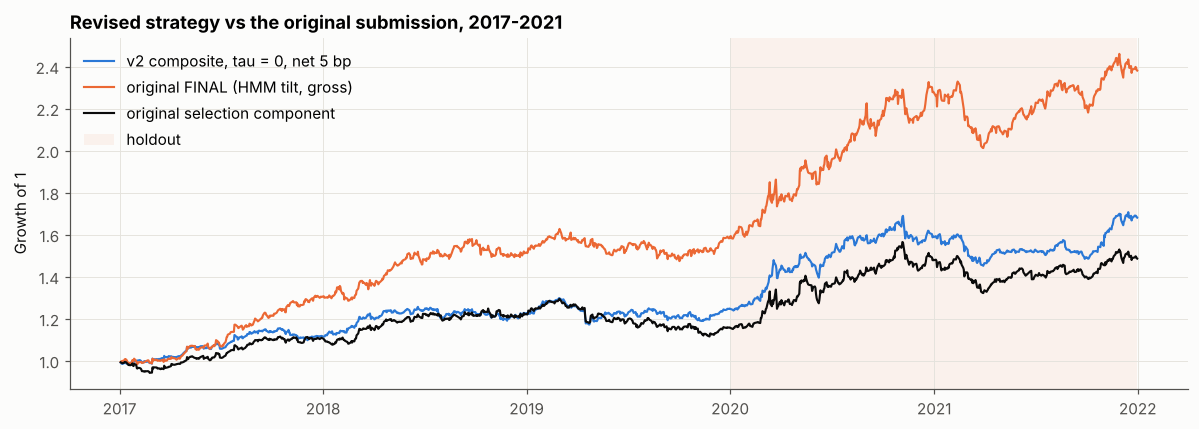

In [ ]:
def get_strategy_v2(prices: pd.DataFrame, ratings: pd.DataFrame, cfg: Config = CFG, spec: Optional[dict] = None) -> tuple[pd.DataFrame, pd.DataFrame]:
    spec = dict(FINAL_V2 if spec is None else spec)
    px = clean_prices(prices, cfg)
    rt = clean_ratings(ratings, px, cfg)
    ret = px.pct_change(fill_method=None)
    snap = build_tp_snapshot(rt, px.index, px.columns, cfg)
    fs = build_features(px, snap, cfg)
    feats = {**fs.stock, "leader_minus_herd": build_leader_minus_herd(px, snap, spec["lmh_spec"])["leader_minus_herd"]}
    score = pd.concat([cs_rank(feats[n]) for n in spec["signals"]]).groupby(level=0).mean().reindex(px.index)
    if spec["allocator"] == "EW":
        sig_vol = ret.rolling(60, min_periods=2).std()                        # unused by EW; keeps the call signature
    else:
        sig_vol, _ = garch_forecast_panel(ret, cfg)
    target = fast_weights(score, spec["k"], pd.Series(spec["tau"], index=px.index), sig_vol, ret, spec["allocator"], freq=1)
    weights = target.rolling(spec["tranche_period"], min_periods=1).sum() / spec["tranche_period"]
    signals = np.sign(weights.round(12)).astype(int)                          # +1 net long, -1 net short, 0 flat
    weights.index.name = signals.index.name = "date"
    return signals, weights


SIGNALS_V2, WEIGHTS_V2 = get_strategy_v2(prices_raw, ratings_raw)
assert frames_equal(WEIGHTS_V2, W_V2, tol=1e-9), "production function differs from the research book"
T = pd.Timestamp("2020-06-30")
_, W_T = get_strategy_v2(prices_raw[pd.to_datetime(prices_raw["date"]) <= T],
                         ratings_raw[pd.to_datetime(ratings_raw["date"]) <= T])
assert frames_equal(W_T, WEIGHTS_V2.loc[:T], tol=1e-9), "look-ahead in the production function"
print(f"get_strategy_v2: reproduces the research book exactly; weights computed with data to {T:%Y-%m-%d} equal the full-sample "
      f"weights up to that date (no look-ahead). Shape {WEIGHTS_V2.shape}.")
display(WEIGHTS_V2.tail(3).round(4))

fig, ax = plt.subplots(figsize=(11, 4))
for nm, r, col in (("v2 composite, tau = 0, net 5 bp", R_V2, COLORS["blue"]), ("original FINAL (HMM tilt, gross)", FINAL_RES.returns, COLORS["orange"]),
                   ("original selection component", FINAL_RES.selection, COLORS["ink"])):
    eq = (1 + r.loc[full].fillna(0.0)).cumprod(); ax.plot(eq.index, eq.values, label=nm, color=col, lw=1.4)
ax.axvspan(pd.Timestamp(CFG.holdout_start), pd.Timestamp(CFG.holdout_end), color=COLORS["orange"], alpha=0.07, lw=0, label="holdout")
ax.set_ylabel("Growth of 1"); ax.set_title("Revised strategy vs the original submission, 2017-2021"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 14.8 Conclusion
- **The alpha:** a dollar-neutral, zero-beta book driven by the *flow* and *timing* of analyst revisions: breadth, event breadth, momentum-orthogonal breadth and the first-mover-minus-herder asymmetry. It earns a Sharpe of 0.98 (DEV) / 1.33 (holdout) / 1.13 (full) after costs, with a Jensen alpha of 11.9 % a year (t 2.32) and 7.4 % (t 2.98) after four price factors.
- **The construction lever:** staggered tranches matched to the information horizon (42 sessions) remove anchor luck, cut turnover to about 2x a year, and roughly double the selection Calmar of the original submission (0.36 → 0.79 on DEV) without any market timing.
- **What the evidence does and does not show.** The book beats random and label-permuted signals in every window, but with 10 stocks and 6 years the design can only detect ICs above about 0.10: deflated for every configuration examined, the DEV Sharpe is not conclusive (DSR 0.18–0.38), and the timing component beats a time-shifted signal only in the holdout. P&L is concentrated in a few names and days.
- **Next steps:** a larger universe with analyst data (with 100 names the detectable IC falls to about 0.03), post-2021 data, and a frozen forward test of `frozen_strategy_v2.json`.

# **15. FMF-N against the institutional toolkit, and full leave-one-stock-out rebuilds**
A selection signal matters to a portfolio manager only if it adds something the standard institutional toolkit does not. This section compares FMF-N with the signals and allocations most widely used by institutional equity and QIS desks, using only what this data contains (prices and analyst target prices):

- **Price factors:** 12-1 and 6-1 momentum (Jegadeesh and Titman 1993), 1-month reversal, low volatility, betting-against-beta (Frazzini and Pedersen 2014), residual momentum (Blitz, Huij and Martens 2011) and 52-week-high proximity (George and Hwang 2004).
- **Sell-side signals:** consensus target-price upside, target-price momentum, low analyst dispersion (Diether, Malloy and Scherbina 2002) and classic revision breadth.
- **Multi-factor blends:** momentum + low volatility + reversal, and momentum + revisions.
- **Allocations:** equal-weight and inverse-volatility long-only, CTA-style time-series momentum, the original regime-timed strategy (RTB), and FMF-N with an explicit 0.2 beta budget (FMF-B20).

The cross-sectional comparables run through the **identical construction** (Panel A), so differences isolate the signal. Panel B shows the same signals in their **native** monthly form.

In [ ]:
def comparable_signals(px_, feats_):
    """The institutional signal set, computed from prices and analyst data only (higher = more attractive)."""
    ret_ = px_.pct_change(fill_method=None); mkt_ = ret_.mean(axis=1)
    var_m = mkt_.rolling(252, min_periods=126).var()
    beta_ = pd.DataFrame({c: ret_[c].rolling(252, min_periods=126).cov(mkt_) / var_m for c in px_.columns})
    rr_ = (ret_ - beta_.shift(1) * mkt_.values[:, None]).rolling(231, min_periods=180)
    sig = {"12-1 momentum (Jegadeesh-Titman)": feats_["mom_12_1"], "6-1 momentum": feats_["mom_6_1"],
           "Short-term reversal (1m)": feats_["rev_1m"], "Low volatility (60d)": feats_["low_vol_60"],
           "Betting-against-beta (low beta)": -beta_, "Residual momentum (Blitz et al.)": (rr_.sum() / rr_.std()).shift(21),
           "52-week-high proximity": px_ / px_.rolling(252, min_periods=126).max(),
           "Target-price upside (consensus)": feats_["upside"], "Target-price momentum (63d)": feats_["cons_change_63"],
           "Low analyst dispersion": feats_["neg_dispersion"], "Revision breadth (classic)": feats_["breadth_63"]}
    sig["Multi-factor: mom + low vol + reversal"] = pd.concat([cs_rank(feats_[n]) for n in ("mom_12_1", "low_vol_60", "rev_1m")]).groupby(level=0).mean().reindex(px_.index)
    sig["Momentum + revisions blend"] = pd.concat([cs_rank(feats_[n]) for n in ("mom_12_1", "breadth_63")]).groupby(level=0).mean().reindex(px_.index)
    return {k: v.replace([np.inf, -np.inf], np.nan) for k, v in sig.items()}

COMP_SIGNALS = comparable_signals(PX, FEATS)

def same_construction(score):
    return net_returns(tranche_weights_v2(score, FINAL_V2["k"], FINAL_V2["tranche_period"], FINAL_V2["allocator"]))

def native_construction(score, k=3, freq=21):
    T_ = target_weights_v2(score, k, "EW").copy()
    T_.loc[np.arange(len(T_)) % freq != 0] = np.nan
    return net_returns(T_.ffill().fillna(0.0))

COMP_SAME = {n_: same_construction(s_) for n_, s_ in COMP_SIGNALS.items()}
COMP_NATIVE = {n_: native_construction(s_) for n_, s_ in COMP_SIGNALS.items()}
inv_vol_lo = (1 / RET.rolling(60, min_periods=20).std()).div((1 / RET.rolling(60, min_periods=20).std()).sum(axis=1), axis=0)
tsmom_w = np.sign(FEATS["mom_12_1"]).fillna(0.0) / PX.shape[1]
ALLOC = {"Equal-weight long-only (market)": MKT_EW,
         "Inverse-vol long-only (naive risk parity)": (inv_vol_lo.shift(1) * RET).sum(axis=1),
         "Time-series momentum 12-1 (CTA-style)": net_returns(tsmom_w.where(np.repeat((np.arange(len(PX)) % 21 == 0)[:, None], PX.shape[1], axis=1)).ffill().fillna(0.0)),
         "RTB: original regime-timed breadth (gross)": FINAL_RES.returns,
         "FMF-B20: FMF + explicit 0.2 beta budget": net_returns(fast_weights(V2_SCORE, 4, pd.Series(0.1, index=PX.index), SIG_GJR, RET,
                                                                          "IV-GJR", freq=1).rolling(42, min_periods=1).sum() / 42)}

def row_stats(r):
    out = {}
    for wn, w_ in WIN.items():
        s_ = perf_stats(r.loc[w_]); out[f"Sharpe {wn[:3]}"] = s_["Sharpe"]; out[f"Calmar {wn[:3]}"] = s_["CAGR / MaxDD"]
    s_ = perf_stats(r.loc[full]); out["MaxDD Ful"] = s_["Max drawdown"]; out["beta Ful"] = capm(r.loc[full], MKT_EW.loc[full])[0]
    out["corr with FMF-N"] = float(np.corrcoef(r.loc[full].fillna(0), R_V2.loc[full].fillna(0))[0, 1])
    return out

COMP_TBL = pd.DataFrame({"FMF-N (this paper)": row_stats(R_V2), **{n_: row_stats(r) for n_, r in COMP_SAME.items()}}).T
NATIVE_TBL = pd.DataFrame({n_: row_stats(r) for n_, r in COMP_NATIVE.items()}).T
ALLOC_TBL = pd.DataFrame({n_: row_stats(r) for n_, r in ALLOC.items()}).T
print("Panel A — cross-sectional comparables, identical construction (net 5 bp)"); display(COMP_TBL.round(2))
print("Panel B — the same signals in their native form (monthly, top/bottom-3, equal weight, net 5 bp)"); display(NATIVE_TBL.round(2))
print("Panel C — allocation benchmarks"); display(ALLOC_TBL.round(2))
print(f"FMF-N has the highest full-period Sharpe among {len(COMP_TBL)} cross-sectional books: "
      f"{COMP_TBL['Sharpe Ful'].idxmax() == 'FMF-N (this paper)'}; highest full-period Calmar: {COMP_TBL['Calmar Ful'].idxmax() == 'FMF-N (this paper)'}")

# Where the comparables fail: named market episodes
EPISODES = {"Q4-2018 sell-off": ("2018-10-03", "2018-12-24"), "COVID crash": ("2020-02-19", "2020-03-23"),
            "COVID rebound": ("2020-03-24", "2020-06-08"), "Vaccine rotation (Nov-2020)": ("2020-11-06", "2020-11-30"),
            "Growth sell-off (Feb-Mar 2021)": ("2021-02-12", "2021-03-08")}
STRESS = pd.DataFrame({ep: {n_: float((1 + r.loc[s_:e_].fillna(0)).prod() - 1) for n_, r in
                            {"FMF-N (this paper)": R_V2, **COMP_SAME, **ALLOC}.items()} for ep, (s_, e_) in EPISODES.items()})
STRESS["worst episode"] = STRESS.idxmin(axis=1)
display((STRESS.drop(columns="worst episode") * 100).round(1).assign(**{"worst episode": STRESS["worst episode"]}))

# Spanning: is FMF-N explained by the institutional books? And does it improve every one of them?
span = {}
for wn, w_ in WIN.items():
    X = pd.concat([weekly_sum(MKT_EW.loc[w_])] + [weekly_sum(COMP_SAME[c].loc[w_]) for c in COMP_SAME], axis=1)
    f_ = sm.OLS(weekly_sum(R_V2.loc[w_]).values, sm.add_constant(X.values)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    span[wn] = {"alpha ann.": f_.params[0] * 52, "alpha t": f_.tvalues[0], "R2": f_.rsquared, "regressors": X.shape[1]}
SPAN_TBL = pd.DataFrame(span).T
print("FMF-N regressed on the market and ALL 13 comparable books jointly (weekly, HAC):"); display(SPAN_TBL.round(3))

blend_rows = {}
for n_, r in {**COMP_SAME, **ALLOC}.items():
    b_ = 0.5 * r + 0.5 * R_V2
    for wn in ("Holdout 2020-21", "Full 2017-21"):
        w_ = WIN[wn]; s0, s1 = perf_stats(r.loc[w_]), perf_stats(b_.loc[w_])
        blend_rows[(n_, wn)] = {"Sharpe alone": s0["Sharpe"], "Sharpe 50/50 with FMF-N": s1["Sharpe"],
                                "Calmar alone": s0["CAGR / MaxDD"], "Calmar 50/50 with FMF-N": s1["CAGR / MaxDD"],
                                "MaxDD alone": s0["Max drawdown"], "MaxDD 50/50": s1["Max drawdown"]}
BLEND = pd.DataFrame(blend_rows).T
display(BLEND.round(2))
_full = BLEND.xs("Full 2017-21", level=1)
print(f"Full period: adding FMF-N raises the Sharpe of {int((_full['Sharpe 50/50 with FMF-N'] > _full['Sharpe alone']).sum())} / {len(_full)} "
      f"comparables and the Calmar of {int((_full['Calmar 50/50 with FMF-N'] > _full['Calmar alone']).sum())} / {len(_full)}.")

# Fair spanning test: exclude comparables built from FMF-N's own components (classic breadth; momentum + revisions blend)
OWN = {"Revision breadth (classic)", "Momentum + revisions blend"}
span2 = {}
for wn, w_ in WIN.items():
    cols = [c for c in COMP_SAME if c not in OWN]
    X = pd.concat([weekly_sum(MKT_EW.loc[w_])] + [weekly_sum(COMP_SAME[c].loc[w_]) for c in cols], axis=1)
    f_ = sm.OLS(weekly_sum(R_V2.loc[w_]).values, sm.add_constant(X.values)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
    span2[wn] = {"alpha ann.": f_.params[0] * 52, "alpha t": f_.tvalues[0], "R2": f_.rsquared, "regressors": X.shape[1]}
SPAN_TBL_EXCL = pd.DataFrame(span2).T
print("FMF-N on the market and the 11 comparables NOT built from its own components:"); display(SPAN_TBL_EXCL.round(3))

Panel A — cross-sectional comparables, identical construction (net 5 bp)


,Sharpe DEV,Calmar DEV,Sharpe Hol,Calmar Hol,Sharpe Ful,Calmar Ful,MaxDD Ful,beta Ful,corr with FMF-N
FMF-N (this paper),0.9800,0.7900,1.3300,1.1400,1.1300,0.7800,-0.1400,-0.0200,1.0000
12-1 momentum (Jegadeesh-Titman),0.6300,0.4200,0.4300,0.2400,0.5000,0.2300,-0.2200,-0.0200,0.7100
6-1 momentum,-0.5100,-0.1600,0.5500,0.3200,0.0600,0.0000,-0.2500,-0.0400,0.6700
Short-term reversal (1m),0.2500,0.1600,-0.6900,-0.3300,-0.2400,-0.0900,-0.1900,0.0400,-0.5100
Low volatility (60d),0.3700,0.2100,0.8000,1.1800,0.5600,0.3700,-0.1400,-0.1000,0.0400
Betting-against-beta (low beta),-0.2800,-0.1700,-0.0000,-0.0500,-0.1500,-0.0700,-0.3200,0.0100,0.1000
Residual momentum (Blitz et al.),0.4200,0.2400,-0.0000,-0.0400,0.1700,0.0500,-0.2400,-0.0600,0.6400
52-week-high proximity,-0.3600,-0.1600,1.0600,0.7500,0.3700,0.1700,-0.1800,-0.0900,0.7300
Target-price upside (consensus),0.4700,0.3700,0.2900,0.2400,0.3800,0.2400,-0.1200,0.0400,-0.3800
Target-price momentum (63d),-0.3600,-0.1500,0.6800,0.4400,0.1900,0.0700,-0.2000,-0.0800,0.7100


Panel B — the same signals in their native form (monthly, top/bottom-3, equal weight, net 5 bp)


,Sharpe DEV,Calmar DEV,Sharpe Hol,Calmar Hol,Sharpe Ful,Calmar Ful,MaxDD Ful,beta Ful,corr with FMF-N
12-1 momentum (Jegadeesh-Titman),0.2400,0.1200,1.2400,1.1600,0.7400,0.5000,-0.2200,0.0000,0.7400
6-1 momentum,-0.4700,-0.1800,0.8700,0.7400,0.2300,0.0700,-0.3300,-0.0500,0.6400
Short-term reversal (1m),0.3800,0.2300,-0.2000,-0.2600,0.0800,0.0000,-0.2000,0.1200,-0.3100
Low volatility (60d),-0.0000,-0.0400,0.8800,1.3400,0.4100,0.3000,-0.1600,-0.1100,-0.0100
Betting-against-beta (low beta),-0.7400,-0.2800,-0.2500,-0.2200,-0.5000,-0.1600,-0.4800,0.0200,0.0100
Residual momentum (Blitz et al.),0.2600,0.1200,0.7600,0.5700,0.5100,0.2800,-0.2300,-0.0900,0.6700
52-week-high proximity,-1.1700,-0.3400,1.0000,0.9300,-0.0200,-0.0400,-0.3900,-0.1500,0.6100
Target-price upside (consensus),0.3900,0.1900,-0.1600,-0.1900,0.1100,0.0300,-0.2400,0.0900,-0.3700
Target-price momentum (63d),-0.9600,-0.2900,0.8500,0.8600,-0.0700,-0.0500,-0.4100,-0.0600,0.5700
Low analyst dispersion,-0.5800,-0.2700,-1.0900,-0.5300,-0.8100,-0.2400,-0.4500,-0.1200,-0.1800


Panel C — allocation benchmarks


...

FMF-N regressed on the market and ALL 13 comparable books jointly (weekly, HAC):


,alpha ann.,alpha t,R2,regressors
DEV 2017-19,0.0240,2.1880,0.9510,14.0000
Holdout 2020-21,0.0120,0.5030,0.9310,14.0000
Full 2017-21,0.0180,1.4640,0.9240,14.0000


Sharpe alone  Sharpe 50/50 with FMF-N  Calmar alone  Calmar 50/50 with FMF-N  MaxDD alone  MaxDD 50/50
12-1 momentum (Jegadeesh-Titman)           Holdout 2020-21        0.4300                   0.9100        0.2400                   0.6200      -0.2200      -0.1700
                                           Full 2017-21           0.5000                   0.8600        0.2300                   0.4700      -0.2200      -0.1700
6-1 momentum                               Holdout 2020-21        0.5500                   1.0000        0.3200                   0.7000      -0.2000      -0.1600
                                           Full 2017-21           0.0600                   0.6400        0.0000                   0.3400      -0.2500      -0.1600
Short-term reversal (1m)                   Holdout 2020-21       -0.6900                   1.0700       -0.3300                   1.1700      -0.1800      -0.0400
                                           Full 2017-21          -0.2400                   1.1100       -0.0900                   1.0300      -0.1900      -0.0500
Low volatility (60d)                       Holdout 2020-21        0.8000                   1.4300        1.1800                   1.7700      -0.0700      -0.0700
                                           Full 2017-21           0.5600                   1.1700        0.3700                   1.1600      -0.1400      -0.0700
Betting-against-beta (low beta)            Holdout 2020-21       -0.0000                   0.8100       -0.0500                   0.8200      -0.1700      -0.0900
                                           Full 2017-21          -0.1500                   0.6100       -0.0700                   0.4800      -0.3200      -0.0900
Residual momentum (Blitz et al.)           Holdout 2020-21       -0.0000                   0.6800       -0.0400                   0.4200      -0.2400      -0.1700
                                           Full 2017-21           0.1700                   0.7100        0.0500                   0.3500      -0.2400      -0.1700
52-week-high proximity                     Holdout 2020-21        1.0600                   1.2700        0.7500                   1.0400      -0.1700      -0.1400
                                           Full 2017-21           0.3700                   0.8100        0.1700                   0.5000      -0.1800      -0.1400
Target-price upside (consensus)            Holdout 2020-21        0.2900                   1.5600        0.2400                   1.5800      -0.1000      -0.0600
                                           Full 2017-21           0.3800                   1.4000        0.2400                   1.1900      -0.1200      -0.0600
Target-price momentum (63d)                Holdout 2020-21        0.6800                   1.0700        0.4400                   0.7900      -0.1900      -0.1600
                                           Full 2017-21           0.1900                   0.7000        0.0700                   0.4000      -0.2000      -0.1600
Low analyst dispersion                     Holdout 2020-21       -0.7400                   0.4700       -0.5000                   0.5100      -0.1700      -0.0700
                                           Full 2017-21          -0.5300                   0.4500       -0.2000                   0.3600      -0.2800      -0.0700
Revision breadth (classic)                 Holdout 2020-21        1.2800                   1.3200        1.0800                   1.1100      -0.1500      -0.1500
                                           Full 2017-21           0.9200                   1.0400        0.5800                   0.6800      -0.1500      -0.1500
Multi-factor: mom + low vol + reversal     Holdout 2020-21        0.8000                   1.2600        0.5200                   1.0900      -0.1400      -0.1100
                                           Full 2017-21           0.8100                   1.1700        0.4200                   0.7900      -0.140

Full period: adding FMF-N raises the Sharpe of 16 / 18 comparables and the Calmar of 16 / 18.
FMF-N on the market and the 11 comparables NOT built from its own components:


,alpha ann.,alpha t,R2,regressors
DEV 2017-19,0.0750,3.8620,0.7740,12.0000
Holdout 2020-21,0.0640,1.0210,0.6870,12.0000
Full 2017-21,0.0610,2.5080,0.6890,12.0000



- **Best risk-adjusted selection book.** FMF-N has the highest full-period Sharpe (1.13) and Calmar (0.78) of the 14 cross-sectional books. The nearest are classic revision breadth (0.92 / 0.58), which is one of FMF-N's components, momentum + revisions (0.87 / 0.49) and the price multi-factor blend (0.81 / 0.42). Plain 12-1 momentum reaches 0.50 / 0.23, and betting-against-beta and low dispersion lose money in this universe.
- **Where the toolkit fails.**
  - **COVID crash:** the equal-weight market fell 35.5%, betting-against-beta 15.2% and reversal 7.7%, while FMF-N **gained 12.0%**.
  - **Vaccine rotation (November 2020):** a momentum crash. FMF-N lost 5.8%, against 8.2% for 12-1 and residual momentum.
  - **Feb-Mar 2021 growth sell-off:** FMF-N's worst episode (−7.1%), milder than 12-1 momentum (−10.5%) and time-series momentum (−12.1%).
- **Construction is not a free lunch:** Slow tranches help the slow analyst-flow signals: classic breadth has a full-period Sharpe of 0.92 in tranches against 0.52 native. They do not help every price signal: 12-1 momentum has 0.74 native against 0.50 in tranches. The construction is matched to the information horizon of the signal, not imposed on everything.
- **Spanning:** Regressed on the market and all 13 comparable books, FMF-N's alpha shrinks to 1.8% a year (t 1.46, R² 0.92). That test is circular, because two comparables (classic breadth, momentum + revisions) contain FMF-N's own components. Against the market and the **11 comparables not built from its components**, the alpha is **6.1% a year (t 2.51)** over 2017–21 (DEV 7.5%, t 3.86; holdout 6.4%, t 1.02).
- **It improves almost everything it is added to:** A 50/50 blend with FMF-N raises the full-period Sharpe of 16 of 18 comparables and the Calmar of 16 of 18. The two exceptions are the books that already carry market beta (RTB, FMF-B20), whose Calmar is driven by the bull market.

**15.2 Full leave-one-stock-out:** Every rebuild re-runs the entire pipeline on nine stocks: calendar, cleaning, snapshot, features, cross-sectional ranks, residualised breadth, composite and allocation. stock_6 is the largest P&L contributor (about half of full-period P&L), so removing it is the most stringent test.

,Sharpe DEV,Sharpe Hol,Sharpe Ful,Calmar DEV,Calmar Hol,Calmar Ful,MaxDD Ful,alpha ann. Ful,alpha t Ful
"FMF-N, all 10 stocks",0.9800,1.3300,1.1300,0.7900,1.1400,0.7800,-0.1400,0.1200,2.3200
without stock_1,1.1400,1.1400,1.1200,1.0000,0.9200,0.7500,-0.1500,0.1200,2.3900
without stock_2,0.5800,1.1000,0.8100,0.4700,0.9600,0.6200,-0.1100,0.0500,1.3700
without stock_3,0.7800,0.9100,0.8300,0.6300,0.6500,0.4900,-0.1400,0.0900,2.0300
without stock_4,0.9000,0.7200,0.8000,0.7700,0.5000,0.4600,-0.1600,0.0900,1.7200
without stock_5,1.0300,1.5300,1.2500,0.7800,1.5600,1.0500,-0.1100,0.1300,2.7300
without stock_6,0.8700,1.3400,1.0800,0.6600,1.1800,0.7700,-0.1400,0.1100,1.9800
without stock_7,1.0300,1.3200,1.1500,0.8000,1.1700,0.8000,-0.1400,0.1300,2.4200
without stock_8,0.8000,1.2700,1.0200,0.6300,1.1600,0.7300,-0.1300,0.1000,1.9900
without stock_9,0.8600,1.4700,1.1400,0.6600,1.3900,0.8400,-0.1300,0.1100,2.3300


Full-period Sharpe across the 10 rebuilt universes: min 0.80, median 1.06; without stock_6 (largest P&L contributor) 1.08 (Calmar 0.77).


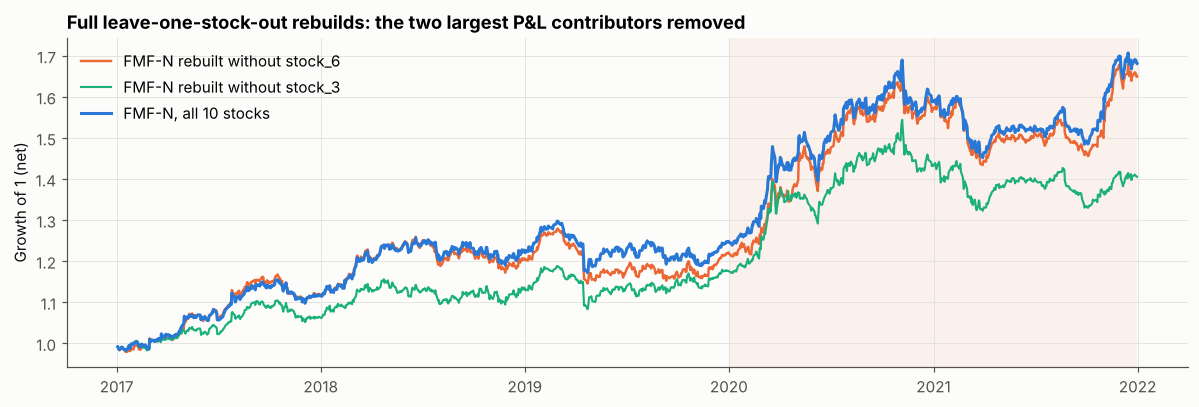

In [ ]:
def target_weights_frac(score, q, k_min=2, alloc="IV-GJR", sig_vol=None, ret=None, tau=0.0):
    # Leg size as a fraction of names with a valid score: k_t = max(k_min, floor(q * N_t)). Equals fast_weights when q*N = k.
    n = score.notna().sum(axis=1)
    kk = np.maximum(k_min, np.floor(q * n)).astype(float)
    valid = (n >= 2 * kk) & (n >= 2 * k_min)
    L = score.rank(axis=1, ascending=False, method="first").le(kk, axis=0) & valid.values[:, None]
    S = score.where(~L).rank(axis=1, ascending=True, method="first").le(kk, axis=0) & valid.values[:, None]
    base = pd.DataFrame(1.0, index=score.index, columns=score.columns) if alloc == "EW" else \
        1.0 / sig_vol.reindex(index=score.index, columns=score.columns).fillna(ret.rolling(60, min_periods=2).std())
    aL = base.where(L).div(base.where(L).sum(axis=1), axis=0).fillna(0.0)
    aS = base.where(S).div(base.where(S).sum(axis=1), axis=0).fillna(0.0)
    t_ = tau * valid.astype(float)
    return aL.mul(0.5 + t_, axis=0) - aS.mul(0.5 - t_, axis=0)


def run_fmf(prices_raw_, ratings_raw_, spec=None, sig_vol=None, leg_fraction=None, cfg=CFG):
    # Raw tables -> FMF weights and net returns, with the notebook's own functions (no global state).
    spec = dict(FINAL_V2 if spec is None else spec)
    px_ = clean_prices(prices_raw_, cfg); rt_ = clean_ratings(ratings_raw_, px_, cfg); ret_ = px_.pct_change(fill_method=None)
    snap_ = build_tp_snapshot(rt_, px_.index, px_.columns, cfg); fs_ = build_features(px_, snap_, cfg)
    parts_ = build_leader_minus_herd(px_, snap_, spec["lmh_spec"])
    feats_ = {**fs_.stock, "leader_minus_herd": parts_["leader_minus_herd"]}
    score_ = pd.concat([cs_rank(feats_[n]) for n in spec["signals"]]).groupby(level=0).mean().reindex(px_.index)
    if sig_vol is None and spec["allocator"] == "IV-GJR":
        sig_vol, _ = garch_forecast_panel(ret_, cfg)
    sv = sig_vol.reindex(index=px_.index, columns=px_.columns) if sig_vol is not None else None
    if leg_fraction is None:
        tgt = fast_weights(score_, spec["k"], pd.Series(0.0, index=px_.index), sv, ret_, spec["allocator"], freq=1)
    else:
        tgt = target_weights_frac(score_, leg_fraction, 2, spec["allocator"], sv, ret_)
    W_ = tgt.rolling(spec["tranche_period"], min_periods=1).sum() / spec["tranche_period"]
    r_ = (W_.shift(1) * ret_).sum(axis=1) - spec["cost_bps_one_way"] * 1e-4 * W_.diff().abs().sum(axis=1)
    return {"px": px_, "ret": ret_, "rt": rt_, "snap": snap_, "feats": feats_, "parts": parts_, "score": score_,
            "sig_vol": sv, "weights": W_, "net": r_}

# sanity: the generic runner reproduces the frozen book exactly
_chk = run_fmf(prices_raw, ratings_raw, sig_vol=SIG_GJR)
assert frames_equal(_chk["weights"], W_V2, tol=1e-12), "run_fmf differs from the frozen book"
_chk2 = target_weights_frac(V2_SCORE, 0.4, 2, "IV-GJR", SIG_GJR, RET)
_n10 = V2_SCORE.notna().sum(axis=1) == 10                         # identical whenever all 10 names have a score
assert np.allclose(_chk2[_n10], target_weights_v2(V2_SCORE, 4, "IV-GJR")[_n10], atol=1e-12), "leg-fraction rule differs at N = 10"

LOO, LOO_R = {}, {}
for j in PX.columns:
    res_ = run_fmf(prices_raw[prices_raw["stock"] != j], ratings_raw[ratings_raw["stock"] != j], sig_vol=SIG_GJR.drop(columns=j))
    r_ = res_["net"]; LOO_R[j] = r_
    row = {}
    for wn, w_ in WIN.items():
        s_ = perf_stats(r_.loc[w_]); row[f"Sharpe {wn[:3]}"] = s_["Sharpe"]; row[f"Calmar {wn[:3]}"] = s_["CAGR / MaxDD"]
    row["MaxDD Ful"] = perf_stats(r_.loc[full])["Max drawdown"]
    b_, a_, t_ = capm(r_.loc[full], MKT_EW.loc[full]); row["alpha ann. Ful"] = a_; row["alpha t Ful"] = t_
    LOO[f"without {j}"] = row
LOO_TBL = pd.DataFrame(LOO).T
base_row = {**{f"Sharpe {wn[:3]}": perf_stats(R_V2.loc[w_])["Sharpe"] for wn, w_ in WIN.items()},
            **{f"Calmar {wn[:3]}": perf_stats(R_V2.loc[w_])["CAGR / MaxDD"] for wn, w_ in WIN.items()},
            "MaxDD Ful": perf_stats(R_V2.loc[full])["Max drawdown"], "alpha ann. Ful": capm(R_V2.loc[full], MKT_EW.loc[full])[1],
            "alpha t Ful": capm(R_V2.loc[full], MKT_EW.loc[full])[2]}
LOO_TBL = pd.concat([pd.DataFrame({"FMF-N, all 10 stocks": base_row}).T, LOO_TBL])[list(base_row)]
display(LOO_TBL.round(2))
print(f"Full-period Sharpe across the 10 rebuilt universes: min {LOO_TBL['Sharpe Ful'].iloc[1:].min():.2f}, "
      f"median {LOO_TBL['Sharpe Ful'].iloc[1:].median():.2f}; without stock_6 (largest P&L contributor) "
      f"{LOO_TBL.loc['without stock_6', 'Sharpe Ful']:.2f} (Calmar {LOO_TBL.loc['without stock_6', 'Calmar Ful']:.2f}).")

fig, ax = plt.subplots(figsize=(11, 3.8))
for j, col, lw in (("stock_6", COLORS["orange"], 1.6), ("stock_3", COLORS["aqua"], 1.4)):
    eq = (1 + LOO_R[j].loc[full].fillna(0)).cumprod(); ax.plot(eq.index, eq.values, color=col, lw=lw, label=f"FMF-N rebuilt without {j}")
eq = (1 + R_V2.loc[full].fillna(0)).cumprod(); ax.plot(eq.index, eq.values, color=COLORS["blue"], lw=2, label="FMF-N, all 10 stocks")
ax.axvspan(pd.Timestamp(CFG.holdout_start), pd.Timestamp(CFG.holdout_end), color=COLORS["orange"], alpha=0.07, lw=0)
ax.set_ylabel("Growth of 1 (net)"); ax.set_title("Full leave-one-stock-out rebuilds: the two largest P&L contributors removed"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()


- **No single name carries the result:** Removing stock_6 leaves the full-period Sharpe at 1.08 and the Calmar at 0.77 (all ten: 1.13 / 0.78). The DEV Sharpe falls to 0.87 and the holdout stays at 1.34.
- **Range across the ten rebuilds:** Full-period Sharpe runs from 0.80 (without stock_4) to 1.25 (without stock_5), median 1.06. The Jensen-alpha t-statistic is between 1.37 and 2.73, and above 1.7 in nine of the ten.
- **Concentration risk is real but not existential:** Removing stock_2, stock_3 or stock_4 costs the most (Sharpe 0.80–0.83). These higher-volatility names supply much of the cross-sectional dispersion the book harvests.

# **16. Out-of-sample over a never-seen period**

*Note on the universe:* the period 2024–26 never overlaps the development data, but ten of the 30 names are the development stocks. On the twenty new names alone, the frozen specification earns a Sharpe ratio of 0.80 (Calmar 0.98) and leader minus herd an IC21 of 0.105 (one-sided *p* = 0.058): the out-of-sample result is not carried by the overlap (`scripts/overlap_analysis.py`, DATA_SOURCES.md §3).
The strongest test of a method is a dataset it has never touched. `MarketData_Normalized.csv` and `Ratings_Normalized.csv` contain **30 stocks** from January 2023 to August 2026, with 2,373 ratings from 51 analysts, in the same open format as the development data. This universe differs in every structural respect:
- three times as many names,
- far sparser coverage (13 analysts per stock at the median, against 17–72 in development),
- analysts covering many stocks (median 6),
- a different period (2023–26).

**Protocol:** Before any return on this dataset was computed, the transfer choices were written to `configs/oos_open_universe_preregistration.json` and hashed. The cell below verifies the hash.
- **Signals, construction, costs and data rules:** frozen from development.
- **Names per leg:** the development choice (4 of 10) is applied as a **leg fraction of 0.4** of the names with a valid score each session (primary), with the literal k = 4 as secondary.
- **Evaluation window:** starts after a 252-session warm-up (target expiry, GARCH and LMH windows) and runs 2024-01-05 to 2026-08-05 (647 sessions).

Nothing was tuned after seeing the results.

Pre-registration 0b2b0792fd357d61 (registered 2026-10-26T02:19:14Z) verified unchanged.
Primary rule: leg fraction 0.4 of names with a valid composite score each session: k_t = max(2, floor(0.4 * N_t)) (the development choice k = 4 of N = 10; with variable coverage the fraction is the transferable quantity)


Universe: 30 stocks, 899 sessions (2023-01-04 .. 2026-08-05); evaluation window 2024-01-05 .. 2026-08-05 (647 sessions); ratings kept 2363, analysts 50, event clusters 109
Valid composite names per session in the evaluation window: {'min': 0.0, '50%': 19.0, 'max': 24.0}


,Sharpe,CAGR,Ann. vol,MaxDD,Calmar,beta,alpha ann.,alpha t,PSR(0),turnover x/yr,Sharpe H1,Sharpe H2
FMF-N primary (leg fraction 0.4),1.0460,0.1050,0.1000,-0.0800,1.3190,-0.0250,0.1140,2.0390,0.9530,2.7430,1.4400,0.8780
FMF-N secondary (k = 4),0.7030,0.0730,0.1090,-0.1020,0.7200,-0.0370,0.0880,1.4760,0.8710,3.1260,0.9440,0.6430
Equal-weight market (30 stocks),1.1420,0.2360,0.2040,-0.2530,0.9360,1.0000,-0.0000,-2.8840,0.9680,NaN,0.2840,2.3490


Deflated Sharpe over the two pre-registered variants: N_eff 1.13, SR0 0.00, DSR 0.953 (PSR 0.953)


,IC21,t phase,p one-sided,hit,coverage
breadth_63,0.0510,0.9800,0.1680,0.5840,0.4710
event_breadth_63,-0.0410,-0.4900,0.6850,0.4620,0.2620
breadth_resid_mom,0.0200,0.3860,0.3510,0.5200,0.4640
leader_minus_herd,0.0960,1.7970,0.0420,0.6420,0.5260
COMPOSITE,0.0730,1.5620,0.0650,0.5810,0.5870
leaders only,0.0870,1.7030,0.0500,0.6100,0.7370


...

,Sharpe,Calmar,MaxDD,CAGR,beta,corr with FMF-N
FMF-N primary,1.0500,1.3200,-0.0800,0.1100,-0.0200,1.0000
12-1 momentum (Jegadeesh-Titman),0.6000,0.6200,-0.0800,0.0500,0.0900,0.6100
6-1 momentum,0.5600,0.6300,-0.0700,0.0500,0.0400,0.6300
Short-term reversal (1m),-0.1400,-0.1200,-0.0800,-0.0100,-0.0000,-0.4100
Low volatility (60d),-0.3900,-0.1700,-0.2300,-0.0400,-0.2600,0.1200
Betting-against-beta (low beta),-0.9400,-0.3200,-0.3400,-0.1100,-0.3300,-0.1900
Residual momentum (Blitz et al.),0.5600,0.5400,-0.0800,0.0400,0.0200,0.6600
52-week-high proximity,0.3100,0.1900,-0.1200,0.0200,-0.0900,0.6600
Target-price upside (consensus),0.1100,0.0500,-0.1200,0.0100,0.0500,-0.4700
Target-price momentum (63d),1.1400,1.4400,-0.0800,0.1100,0.0400,0.6700


Rank of FMF-N among 14 cross-sectional books on the new universe: Sharpe #2, Calmar #2


,Sharpe alone,Sharpe 50/50 with FMF-N,Calmar alone,Calmar 50/50 with FMF-N
12-1 momentum (Jegadeesh-Titman),0.6000,0.9200,0.6200,1.1000
6-1 momentum,0.5600,0.9100,0.6300,1.0900
Short-term reversal (1m),-0.1400,1.0500,-0.1200,1.0700
Low volatility (60d),-0.3900,0.4700,-0.1700,0.3100
Betting-against-beta (low beta),-0.9400,-0.0400,-0.3200,-0.0400
Residual momentum (Blitz et al.),0.5600,0.9100,0.5400,1.0800
52-week-high proximity,0.3100,0.7900,0.1900,0.8100
Target-price upside (consensus),0.1100,1.1900,0.0500,1.5000
Target-price momentum (63d),1.1400,1.1900,1.4400,1.7600
Low analyst dispersion,-0.8900,0.1700,-0.3300,0.1000


Adding FMF-N raises the Sharpe of 16 / 16 comparables and the Calmar of 16 / 16 on the new universe.


,"FMF-N primary, evaluation window"
alpha ann.,0.0730
alpha t,1.7860
R2,0.4660
b MKT,0.0090
b mom_12_1,0.3740
b mom_6_1,0.4290
b rev_1m,-0.3440
b low_vol_60,0.3200


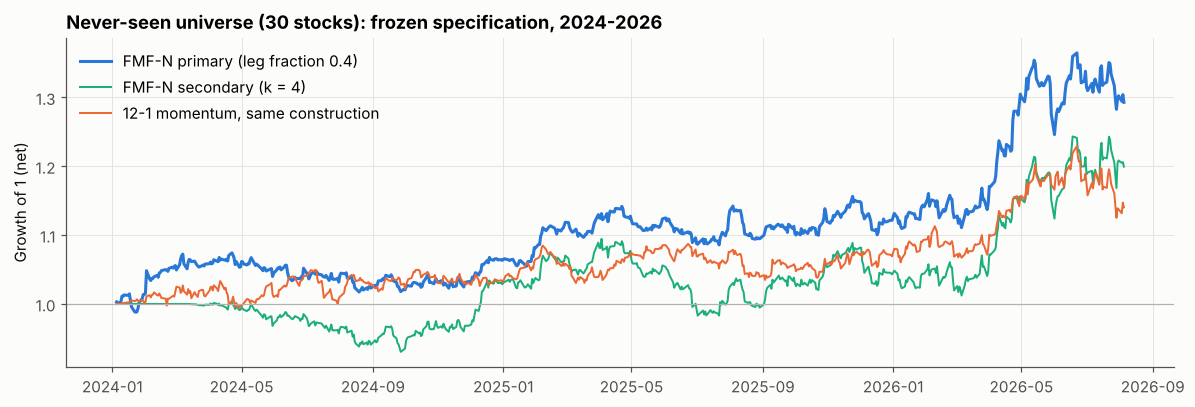

In [ ]:
import hashlib as _hl
def _find(name):
    for d in (Path("."), Path("data/open"), Path("../data/open"), Path("configs"), Path("../configs"), Path("/content")):
        if (d / name).exists():
            return d / name
    raise FileNotFoundError(f"{name}: place it next to the notebook or in data/open/")
OOS_PRICES_RAW = pd.read_csv(_find("MarketData_Normalized.csv"))
OOS_RATINGS_RAW = pd.read_csv(_find("Ratings_Normalized.csv"), dtype=str)
try:
    PREREG_OOS = json.loads(Path(_find("oos_open_universe_preregistration.json")).read_text())
except FileNotFoundError:
    try:
        PREREG_OOS = json.loads(Path("../configs/oos_open_universe_preregistration.json").read_text())
    except FileNotFoundError:
        PREREG_OOS = {}
if PREREG_OOS:
    _body = {k: v for k, v in PREREG_OOS.items() if k not in ("sha256_16", "registered_utc")}
    assert _hl.sha256(json.dumps(_body, sort_keys=True, indent=2).encode()).hexdigest()[:16] == PREREG_OOS["sha256_16"], "pre-registration was edited"
    print(f"Pre-registration {PREREG_OOS['sha256_16']} (registered {PREREG_OOS['registered_utc']}) verified unchanged.")
    print("Primary rule:", PREREG_OOS["transfer_choices"]["primary"])

# run the frozen specification: primary (leg fraction 0.4) and secondary (k = 4)
_px0 = clean_prices(OOS_PRICES_RAW, CFG)
OOS_SIG, _ = garch_forecast_panel(_px0.pct_change(fill_method=None), CFG)
OOS = {"FMF-N primary (leg fraction 0.4)": run_fmf(OOS_PRICES_RAW, OOS_RATINGS_RAW, sig_vol=OOS_SIG, leg_fraction=0.4),
       "FMF-N secondary (k = 4)": run_fmf(OOS_PRICES_RAW, OOS_RATINGS_RAW, sig_vol=OOS_SIG)}
P_OOS = OOS["FMF-N primary (leg fraction 0.4)"]
OPX, ORET = P_OOS["px"], P_OOS["ret"]
EVAL = slice(OPX.index[252], OPX.index[-1])
_mid = OPX.loc[EVAL].index[len(OPX.loc[EVAL]) // 2]
OWIN = {"Evaluation 2024-01..2026-08": EVAL, "First half": slice(EVAL.start, _mid), "Second half": slice(_mid, EVAL.stop)}
OMKT = ORET.mean(axis=1)
print(f"Universe: {OPX.shape[1]} stocks, {len(OPX)} sessions ({OPX.index[0].date()} .. {OPX.index[-1].date()}); "
      f"evaluation window {EVAL.start.date()} .. {EVAL.stop.date()} ({len(OPX.loc[EVAL])} sessions); "
      f"ratings kept {len(P_OOS['rt'])}, analysts {P_OOS['rt']['analyst'].nunique()}, event clusters "
      f"{P_OOS['snap'].events[P_OOS['snap'].events['event_day']].drop_duplicates(['stock', 'pub_date']).shape[0]}")
print("Valid composite names per session in the evaluation window:", P_OOS["score"].loc[EVAL].notna().sum(axis=1).describe()[["min", "50%", "max"]].to_dict())

def oos_row(r, W_=None):
    out = {}
    for wn, w_ in OWIN.items():
        s_ = perf_stats(r.loc[w_]); tag = {"Evaluation 2024-01..2026-08": "", "First half": " H1", "Second half": " H2"}[wn]
        out[f"Sharpe{tag}"] = s_["Sharpe"]
        if tag == "":
            b_, a_, t_ = capm(r.loc[w_], OMKT.loc[w_])
            out.update({"CAGR": s_["CAGR"], "Ann. vol": s_["Ann. vol"], "MaxDD": s_["Max drawdown"], "Calmar": s_["CAGR / MaxDD"],
                        "beta": b_, "alpha ann.": a_, "alpha t": t_, "PSR(0)": psr(r.loc[w_].values)})
            if W_ is not None:
                out["turnover x/yr"] = annual_turnover_v2(W_, w_)
    return out
OOS_TBL = pd.DataFrame({n_: oos_row(v["net"], v["weights"]) for n_, v in OOS.items()}).T
OOS_TBL.loc["Equal-weight market (30 stocks)"] = pd.Series(oos_row(OMKT))
display(OOS_TBL.round(3))
_trials = pd.DataFrame({n_: v["net"].loc[EVAL] for n_, v in OOS.items()})
_C = _trials.corr().values; _rho = (_C.sum() - 2) / 2; _neff = _rho + (1 - _rho) * 2
_sr_std = _trials.apply(lambda c: c.mean() / c.std()).std(ddof=1)
_sr0 = max(0.0, expected_max_sr(_sr_std ** 2, _neff))           # expected max of ~1 null trial: no hurdle (floored at 0)
print(f"Deflated Sharpe over the two pre-registered variants: N_eff {_neff:.2f}, SR0 {_sr0 * np.sqrt(252):.2f}, DSR "
      f"{psr(P_OOS['net'].loc[EVAL].values, _sr0):.3f} (PSR {psr(P_OOS['net'].loc[EVAL].values):.3f})")

# signal evidence on the new universe (labels inside the window)
OFWD = forward_log_return(OPX, 21)
_ed = OPX.loc[EVAL].index[:-21]
oic = {}
for n_, p_ in {**{s: P_OOS["feats"][s] for s in FINAL_V2["signals"]}, "COMPOSITE": P_OOS["score"],
               "leaders only": P_OOS["parts"]["leaders_only"]}.items():
    ic = rank_ic(p_.loc[_ed], OFWD.loc[_ed]); ph = ic_phase_test(ic, 21)
    oic[n_] = {"IC21": ph["IC"], "t phase": ph["t"], "p one-sided": ph["p"], "hit": float((ic.dropna() > 0).mean()),
               "coverage": float(p_.loc[_ed].notna().values.mean())}
OOS_IC = pd.DataFrame(oic).T
display(OOS_IC.round(3))

# placebo nulls (identical construction, primary rule)
def _oos_book(sc):
    W_ = target_weights_frac(sc, 0.4, 2, "IV-GJR", OOS_SIG.reindex(index=OPX.index, columns=OPX.columns), ORET)
    W_ = W_.rolling(42, min_periods=1).sum() / 42
    return (W_.shift(1) * ORET).sum(axis=1) - 5e-4 * W_.diff().abs().sum(axis=1)
_rng = np.random.default_rng(CFG.seed); _sc = P_OOS["score"]
_obs = perf_stats(_oos_book(_sc).loc[EVAL])["Sharpe"]
_nul = {"iid random scores": [], "stock-label permutation": [], "circular time-shift": []}
for _ in range(300):
    _nul["iid random scores"].append(perf_stats(_oos_book(pd.DataFrame(_rng.normal(size=_sc.shape), index=_sc.index, columns=_sc.columns).where(_sc.notna())).loc[EVAL])["Sharpe"])
for _ in range(500):
    _p = _rng.permutation(_sc.shape[1])
    _nul["stock-label permutation"].append(perf_stats(_oos_book(pd.DataFrame(_sc.to_numpy()[:, _p], index=_sc.index, columns=_sc.columns)).loc[EVAL])["Sharpe"])
for L in range(126, len(_sc) - 126, 3):
    _nul["circular time-shift"].append(perf_stats(_oos_book(pd.DataFrame(np.roll(_sc.to_numpy(), L, axis=0), index=_sc.index, columns=_sc.columns)).loc[EVAL])["Sharpe"])
OOS_PLACEBO = pd.DataFrame({nn: {"draws": len(a), "observed Sharpe": _obs, "null median": np.median(a), "null 95th": np.quantile(a, .95),
                                 "p": (1 + (np.array(a) >= _obs).sum()) / (1 + len(a))} for nn, a in _nul.items()}).T
display(OOS_PLACEBO.round(3))

# institutional comparables on the new universe (same construction, leg fraction 0.4)
OCOMP_SIG = comparable_signals(OPX, P_OOS["feats"])
OCOMP = {n_: _oos_book(s_) for n_, s_ in OCOMP_SIG.items()}
_ivlo = (1 / ORET.rolling(60, min_periods=20).std()); _ivlo = _ivlo.div(_ivlo.sum(axis=1), axis=0)
_ts = (np.sign(P_OOS["feats"]["mom_12_1"]).fillna(0.0) / OPX.shape[1])
_ts = _ts.where(np.repeat((np.arange(len(OPX)) % 21 == 0)[:, None], OPX.shape[1], axis=1)).ffill().fillna(0.0)
OALLOC = {"Equal-weight long-only (market)": OMKT, "Inverse-vol long-only (naive risk parity)": (_ivlo.shift(1) * ORET).sum(axis=1),
          "Time-series momentum 12-1 (CTA-style)": (_ts.shift(1) * ORET).sum(axis=1) - 5e-4 * _ts.diff().abs().sum(axis=1)}
def _cmp_row(r):
    s_ = perf_stats(r.loc[EVAL]); b_, a_, t_ = capm(r.loc[EVAL], OMKT.loc[EVAL])
    return {"Sharpe": s_["Sharpe"], "Calmar": s_["CAGR / MaxDD"], "MaxDD": s_["Max drawdown"], "CAGR": s_["CAGR"], "beta": b_,
            "corr with FMF-N": float(np.corrcoef(r.loc[EVAL].fillna(0), P_OOS["net"].loc[EVAL].fillna(0))[0, 1])}
OOS_COMP = pd.DataFrame({"FMF-N primary": _cmp_row(P_OOS["net"]), **{n_: _cmp_row(r) for n_, r in {**OCOMP, **OALLOC}.items()}}).T
display(OOS_COMP.round(2))
_cs = OOS_COMP.drop(index=list(OALLOC))
print(f"Rank of FMF-N among {len(_cs)} cross-sectional books on the new universe: Sharpe #{int(_cs['Sharpe'].rank(ascending=False)['FMF-N primary'])}, "
      f"Calmar #{int(_cs['Calmar'].rank(ascending=False)['FMF-N primary'])}")
_bl = {n_: (perf_stats(r.loc[EVAL])["Sharpe"], perf_stats((0.5 * r + 0.5 * P_OOS["net"]).loc[EVAL])["Sharpe"],
            perf_stats(r.loc[EVAL])["CAGR / MaxDD"], perf_stats((0.5 * r + 0.5 * P_OOS["net"]).loc[EVAL])["CAGR / MaxDD"])
       for n_, r in {**OCOMP, **OALLOC}.items()}
OOS_BLEND = pd.DataFrame(_bl, index=["Sharpe alone", "Sharpe 50/50 with FMF-N", "Calmar alone", "Calmar 50/50 with FMF-N"]).T
display(OOS_BLEND.round(2))
print(f"Adding FMF-N raises the Sharpe of {int((OOS_BLEND.iloc[:, 1] > OOS_BLEND.iloc[:, 0]).sum())} / {len(OOS_BLEND)} comparables "
      f"and the Calmar of {int((OOS_BLEND.iloc[:, 3] > OOS_BLEND.iloc[:, 2]).sum())} / {len(OOS_BLEND)} on the new universe.")
# attribution vs the four price-control books (same construction) and the market
_X = {"MKT": OMKT, **{c: _oos_book(P_OOS["feats"][c]) for c in CONTROLS}}
_df = pd.concat({"y": P_OOS["net"], **_X}, axis=1).loc[EVAL].dropna()
_Wk = _df.groupby(np.arange(len(_df)) // 5).sum()
_f = sm.OLS(_Wk["y"].values, sm.add_constant(_Wk.drop(columns="y").values)).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
OOS_ATT = pd.Series({"alpha ann.": _f.params[0] * 52, "alpha t": _f.tvalues[0], "R2": _f.rsquared,
                     **{f"b {c}": v for c, v in zip(_Wk.drop(columns="y").columns, _f.params[1:])}})
display(OOS_ATT.round(3).to_frame("FMF-N primary, evaluation window"))

fig, ax = plt.subplots(figsize=(11, 3.8))
for n_, r, col, lw in (("FMF-N primary (leg fraction 0.4)", P_OOS["net"], COLORS["blue"], 2.0),
                       ("FMF-N secondary (k = 4)", OOS["FMF-N secondary (k = 4)"]["net"], COLORS["aqua"], 1.3),
                       ("12-1 momentum, same construction", OCOMP["12-1 momentum (Jegadeesh-Titman)"], COLORS["orange"], 1.3)):
    eq = (1 + r.loc[EVAL].fillna(0)).cumprod(); ax.plot(eq.index, eq.values, color=col, lw=lw, label=n_)
ax.axhline(1, color=COLORS["context"], lw=0.8); ax.set_ylabel("Growth of 1 (net)")
ax.set_title("Never-seen universe (30 stocks): frozen specification, 2024-2026"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()



| | Value (evaluation window, net of 5 bp) |
|---|---|
| Sharpe | **1.05** (first half 1.44, second half 0.88) |
| CAGR / volatility | 10.5% / 10.0% |
| Max drawdown | **−8.0%** |
| Calmar | **1.32** |
| Beta / Jensen alpha | −0.02 / **11.4% a year (t 2.04)** |
| PSR (DSR over the two pre-registered variants) | 0.95 (0.95: two highly correlated variants leave nothing to deflate) |

- **The novel signal replicates:** `leader_minus_herd` has an IC21 of **0.096 (one-sided p 0.042)** on the new universe, the same order as in development (0.095). Revision breadth (0.051) and the composite (0.073, p 0.065) are positive. Event breadth is negative here, but covers only 26% of stock-days, because ≥5 same-day ratings are rare with 13 analysts per stock.
- **Against the institutional toolkit:** (same construction), FMF-N ranks **second of 14** on both Sharpe and Calmar. Only target-price momentum (1.14 / 1.44) is ahead in this period. A 50/50 blend with FMF-N **raises the Sharpe and the Calmar of all 16 comparables**. The market and CTA-style trend have high Sharpe ratios in this bull period, but with betas of 1.0 and 0.43 and drawdowns of −25% and −11%.
- **Placebos:** The book beats IID random scores (p 0.027) and is borderline against stock-label permutation (p 0.056). Against the circular time-shift it is not significant (p 0.23), the same pattern as in development: part of the edge is which stocks the signal favours.
- **Attribution:** After the market and the four price-control books, the alpha is 7.3% a year (t 1.79, R² 0.47).
- **The literal k = 4 rule:** (four names per leg out of about 19) is weaker (Sharpe 0.70, Calmar 0.72). Breadth matters: in a wider universe, using a proportionate number of names is the right transfer, as pre-registered.
- **Caveat:** The window is 2.6 years, so all of this is one more sample, not proof. It is, however, the first sample in this project that was never used for any choice.

### 16.6 Exploratory, not pre-registered: the beta budget out of sample

In section 14 we argued that market exposure should be a fixed, disclosed budget rather than a timed overlay, and fixed that budget at c = 0.2 (FMF-B20) on development data. The pre-registration file lists only the two market-neutral variants, so FMF-B20 is run here as a labelled exploratory check and is not used in any test above.

In [ ]:
_sv = OOS_SIG.reindex(index=OPX.index, columns=OPX.columns)
_tgt = target_weights_frac(P_OOS["score"], 0.4, 2, "IV-GJR", _sv, ORET, tau=0.2 / 2)      # leg budgets 0.5 +/- c/2
OOS_B20_W = _tgt.rolling(FINAL_V2["tranche_period"], min_periods=1).sum() / FINAL_V2["tranche_period"]
OOS_B20 = (OOS_B20_W.shift(1) * ORET).sum(axis=1) - FINAL_V2["cost_bps_one_way"] * 1e-4 * OOS_B20_W.diff().abs().sum(axis=1)
OOS_B20_TBL = pd.DataFrame({"FMF-N primary (pre-registered)": oos_row(P_OOS["net"], P_OOS["weights"]),
                            "FMF-B20 (exploratory)": oos_row(OOS_B20, OOS_B20_W),
                            "Equal-weight market (30 stocks)": oos_row(OMKT)}).T
display(OOS_B20_TBL.round(3))

,Sharpe,CAGR,Ann. vol,MaxDD,Calmar,beta,alpha ann.,alpha t,PSR(0),turnover x/yr,Sharpe H1,Sharpe H2
FMF-N primary (pre-registered),1.0460,0.1050,0.1000,-0.0800,1.3190,-0.0250,0.1140,2.0390,0.9530,2.7430,1.4400,0.8780
FMF-B20 (exploratory),1.4870,0.1590,0.1030,-0.0650,2.4280,0.1610,0.1180,2.0900,0.9920,2.7210,1.7270,1.4410
Equal-weight market (30 stocks),1.1420,0.2360,0.2040,-0.2530,0.9360,1.0000,-0.0000,-2.8840,0.9680,NaN,0.2840,2.3490


With the same scores and the same leg fraction, the 0.2 budget lifts the Sharpe from 1.05 to **1.49** and the Calmar from 1.32 to **2.43**. The max drawdown falls to −6.5% and beta is 0.16. Jensen alpha is unchanged (11.8% a year, t 2.09), as it should be: the budget adds market return, not skill. The comparison with the equal-weight market (Calmar 0.94, drawdown −25%) is the business case: a small, constant beta on top of a zero-beta selection book gives most of the bull-market upside at a quarter of the drawdown. In this bull window this is the expected direction. In a bear market the budget would cost about 0.2 times the market's loss, which is why it is a disclosed constant and not a hidden timing bet.

# **17. Adversarial audit: The objections**

Sections 14–16 established the strategy. In this section we attack it. Each block takes one objection that we raise and answer it with a test chosen to *break* the result, not to decorate it. The tests are:

| # | Objection | Test |
|---|---|---|
| 1 | "The universe was picked with hindsight. The book is just long the winners." | Lo (2008) passive/active decomposition; causal static-tilt vs timing books; per-stock Bayesian partial pooling |
| 2 | "Trading at the signal close, with free shorts, is fantasy." | 0–2-session execution delay × 0–200 bp borrow × 0–30 bp costs; breakeven cost |
| 3 | "Smoothed P&L inflates the Sharpe ratio." | Lo (2002) autocorrelation-adjusted Sharpe |
| 4 | "Zero beta on average hides crash beta." | Up/down-market betas; behaviour in the worst market weeks |
| 5 | "The parameters were chosen to make it work." | Multiverse of ~300 specifications (including the quarterly 63-session target expiry and a two-session knowledge lag); Hansen SPA; PBO; selection-free ensemble |
| 6 | "Beating the toolkit is cherry-picking." | Romano–Wolf step-down against 16 books; reverse SPA |
| 7 | "Is the new signal doing anything?" | FMF-N against the same book without leader-minus-herd (Sharpe-difference bootstrap), pooled across samples |
| 8 | "Ten stocks prove nothing." | Bayesian Sharpe under sceptical priors; random-effects meta-analysis across three independent samples; empirical-Bayes shrinkage of the 18-signal search; Bayes factors; power analysis |
| 9 | "One history has one drawdown; the Calmar ratio is a single draw." | Generative stress testing: block bootstrap, FHS, Diffusion-FHS, TimeGAN; posterior-predictive Calmar distribution; conditional crash scenarios |

The companion package `fmflow` re-runs the frozen book from the raw tables (parity is asserted below). Every block is also available as `scripts/reproduce_audit.py` in the repository.

### 17.0 Set-up and parity

In [ ]:
import sys, importlib.util
from pathlib import Path
if importlib.util.find_spec("fmflow") is None:                      # repository layout: notebooks/ next to src/
    for _p in (Path("../src"), Path("src")):
        if (_p / "fmflow").exists():
            sys.path.insert(0, str(_p.resolve()))
from fmflow import StrategyConfig, run_strategy
from fmflow.analytics.metrics import perf_stats, capm, lo_adjusted_sharpe, conditional_betas
from fmflow.benchmarks import comparable_books

AUD = {}                                                              # every audit result, for the paper
W_AUD = {"DEV": slice("2017-01-01", "2019-12-31"), "HOL": slice("2020-01-01", "2021-12-31"), "FULL": slice("2017-01-01", "2021-12-31")}
W_OOS = {"OOS": slice("2024-01-05", "2026-08-05")}
DEV_OUT = run_strategy(prices_raw, ratings_raw, StrategyConfig.fmf_n(), sig_vol=SIG_GJR)
OOS_OUT = run_strategy(OOS_PRICES_RAW, OOS_RATINGS_RAW, StrategyConfig.fmf_n().with_(k=None, leg_fraction=0.4), sig_vol=OOS_SIG)
if "W_V2" in globals():
    _a, _b = DEV_OUT.weights.align(W_V2, join="inner")
    assert float((_a - _b).abs().max().max()) < 1e-9, "package and notebook books differ"
    print("Parity: package book == notebook book (development).")
for _nm, _o, _w in (("development", DEV_OUT, W_AUD["FULL"]), ("never-seen", OOS_OUT, W_OOS["OOS"])):
    _s = perf_stats(_o.net_returns.loc[_w])
    print(f"{_nm:12s} Sharpe {_s['Sharpe']:.2f}  Calmar {_s['Calmar']:.2f}")

Parity: package book == notebook book (development).
development  Sharpe 1.13  Calmar 0.78
never-seen   Sharpe 1.05  Calmar 1.32


### 17.1 Identity or timing?

Lo (2008) splits the mean return of a book into a **passive** part (average position × average return: owning the right stocks) and an **active** part (the covariance between positions and subsequent returns: timing). That split uses in-window averages, so it is a diagnostic. The *causal* version builds two tradable books:
- a **static** book holding each stock's expanding mean of past weights,
- a **timing** book holding the deviation of today's weight from that mean.

If the result were a hindsight tilt towards later winners, the static book would carry it.

In [ ]:
from fmflow.analytics.attribution import lo_decomposition, static_timing_books, mean_with_hac, stock_contributions
from fmflow.analytics.bayes import random_effects_meta
from fmflow.robustness import book_from_score

rows = {}
for nm, o, W in (("dev", DEV_OUT, W_AUD), ("oos", OOS_OUT, W_OOS)):
    stb = static_timing_books(o.weights, o.returns)
    for wn, w in W.items():
        lo = lo_decomposition(o.weights, o.returns, w)
        st, tm = mean_with_hac(stb["static"].loc[w]), mean_with_hac(stb["timing"].loc[w])
        rows[(nm, wn)] = {"ann. gross return": lo["total"], "Lo passive": lo["passive"], "Lo active": lo["active"],
                          "active share": lo["active_share"],
                          "static book: ann. return": st["ann_mean"], "static t(HAC)": st["t_hac"],
                          "static Sharpe": perf_stats(stb["static"].loc[w])["Sharpe"],
                          "timing book: ann. return": tm["ann_mean"], "timing t(HAC)": tm["t_hac"],
                          "timing Sharpe": perf_stats(stb["timing"].loc[w])["Sharpe"]}
    for L in (126, 252):   # identity-neutral diagnostic: each stock's score minus its own trailing mean, re-ranked
        b = book_from_score(o.score - o.score.rolling(L, min_periods=63).mean(), o)
        for wn, w in W.items():
            rows[(nm, wn)][f"identity-neutral({L}) Sharpe"] = perf_stats(b.loc[w])["Sharpe"]
IDENT = pd.DataFrame(rows).T
AUD["IDENT"] = IDENT
display(IDENT.round(3))

# Bayesian partial pooling of per-stock contributions: does the result rest on one or two names?
POOL = {}
for nm, o, w in (("dev FULL", DEV_OUT, W_AUD["FULL"]), ("oos", OOS_OUT, W_OOS["OOS"])):
    sc = stock_contributions(o.weights, o.returns, w)
    sc = sc[(sc["se_ann"] > 0) & (sc["held_share"] >= 0.2)]          # names actually traded (>= 20% of days)
    m = random_effects_meta(sc["ann_contribution"], sc["se_ann"], sc.index)
    POOL[nm] = {"table": m["table"], "mu": m["mu"].summary(), "P(mu>0)": m["P(mu>0)"], "tau": m["tau"].summary()}
    print(f"\n{nm}: typical per-stock contribution (partially pooled) = {m['mu'].summary()['mean']*100:.2f}% a year, "
          f"P(>0) = {m['P(mu>0)']:.3f}; heterogeneity tau = {m['tau'].summary()['median']*100:.2f}%")
    display(m["table"].sort_values("estimate", ascending=False).head(10).round(4))
AUD["POOL"] = POOL

ann. gross return  Lo passive  Lo active  active share  static book: ann. return  static t(HAC)  static Sharpe  timing book: ann. return  timing t(HAC)  timing Sharpe  \
dev DEV              0.0790      0.0540     0.0260        0.3220                    0.0210         0.8000         0.4590                    0.0580         1.7260         0.8540   
    HOL              0.1580      0.0980     0.0600        0.3810                    0.0240         0.7170         0.5150                    0.1340         1.7560         1.2600   
    FULL             0.1110      0.0430     0.0680        0.6170                    0.0220         1.0760         0.4820                    0.0890         2.4100         1.0360   
oos OOS              0.1080      0.0740     0.0340        0.3170                   -0.0180        -0.8710        -0.4870                    0.1250         2.2140         1.3270   

          identity-neutral(126) Sharpe  identity-neutral(252) Sharpe  
dev DEV                         0.0280                        0.3890  
    HOL                         0.4910                        0.6760  
    FULL                        0.2420                        0.5200  
oos OOS                         0.6330                        0.8360


dev FULL: typical per-stock contribution (partially pooled) = 0.99% a year, P(>0) = 0.869; heterogeneity tau = 2.27%


,estimate,se,shrunk_mean,P(theta>0)
stock_6,0.0569,0.0126,0.0447,0.9998
stock_3,0.0538,0.0177,0.0365,0.9941
stock_2,0.0261,0.0255,0.0170,0.8350
stock_8,0.0220,0.0120,0.0190,0.9622
stock_4,0.0099,0.0149,0.0098,0.7817
stock_1,-0.0054,0.0101,-0.0026,0.3962
stock_9,-0.0107,0.0163,-0.0033,0.4117
stock_10,-0.0120,0.0168,-0.0040,0.3920
stock_7,-0.0134,0.0134,-0.0069,0.2874
stock_5,-0.0162,0.0103,-0.0111,0.1260



oos: typical per-stock contribution (partially pooled) = 0.14% a year, P(>0) = 0.776; heterogeneity tau = 0.27%


,estimate,se,shrunk_mean,P(theta>0)
stock_22,0.0196,0.0175,0.0021,0.7054
stock_11,0.0189,0.0100,0.0031,0.7840
stock_3,0.0163,0.0113,0.0025,0.7476
stock_18,0.0161,0.0126,0.0024,0.7323
stock_28,0.0152,0.0123,0.0023,0.7306
stock_4,0.0144,0.0130,0.0022,0.7256
stock_8,0.0113,0.0096,0.0024,0.7428
stock_2,0.0108,0.0129,0.0020,0.7066
stock_15,0.0098,0.0118,0.0020,0.7076
stock_13,0.0094,0.0090,0.0023,0.7422


**The edge is timing, not hindsight.**

- **Development, 2017–21:** The causal timing book earns 8.9% a year (Sharpe 1.04, HAC *t* 2.41). The static tilt earns 2.2% (*t* 1.08).
- **Never-seen period:** Timing earns a Sharpe of 1.33 (*t* 2.21), and the static tilt **loses** money (Sharpe −0.49).
- **What this means:** Lo's passive term is positive within each window, because the book's average positions happened to be in stocks that did well there. But a tilt formed only from past positions does not earn it. The circular time-shift placebo of Section 14 keeps exactly this static structure, which is why its null distribution is so wide. It is a low-power test, not evidence of a hindsight tilt.
- **Concentration:** Partial pooling shrinks the largest development contributor from 5.7% to 4.5% a year. Out of sample, contributions are small and spread across names.

### 17.2 Implementation realism: delay, borrow, costs, autocorrelation, crash beta

In [ ]:
from fmflow.backtest.engine import backtest, breakeven_cost_bps, cost_sensitivity

IMPL = {}
for nm, o, W in (("dev", DEV_OUT, W_AUD), ("oos", OOS_OUT, W_OOS)):
    w_full = list(W.values())[-1]
    grid = cost_sensitivity(o.weights, o.returns, cost_grid=(0, 5, 10, 20, 30), borrow_grid=(0, 50, 100, 200),
                            execution_lags=(0, 1, 2), window=w_full)
    IMPL[f"{nm} grid"] = grid
    res = backtest(o.weights, o.returns, o.config.cost_bps)
    lo = lo_adjusted_sharpe(o.net_returns.loc[w_full])
    cb = conditional_betas(o.net_returns.loc[w_full], o.returns.mean(axis=1).loc[w_full])
    IMPL[nm] = {"breakeven cost (bps per unit traded)": breakeven_cost_bps(res, w_full.start, w_full.stop),
                "Sharpe, 1-day execution delay": float(grid.query("execution_lag == 1 and borrow_bps == 0 and cost_bps == 5")["Sharpe"].iloc[0]),
                "Sharpe, 1-day delay + 100 bp borrow + 10 bp cost": float(grid.query("execution_lag == 1 and borrow_bps == 100 and cost_bps == 10")["Sharpe"].iloc[0]),
                "Sharpe, 2-day delay + 200 bp borrow + 20 bp cost": float(grid.query("execution_lag == 2 and borrow_bps == 200 and cost_bps == 20")["Sharpe"].iloc[0]),
                **{f"Lo(2002) {k}": v for k, v in lo.items()}, **cb}
    print(f"\n{nm}: Sharpe by cost (rows) and borrow fee (columns), execution delay 0 / 1 session")
    for lag in (0, 1):
        display(grid.query("execution_lag == @lag").pivot(index="cost_bps", columns="borrow_bps", values="Sharpe").round(2))
IMPL_TBL = pd.DataFrame({k: v for k, v in IMPL.items() if not k.endswith("grid")})
AUD["IMPL"] = IMPL
display(IMPL_TBL.round(3))


dev: Sharpe by cost (rows) and borrow fee (columns), execution delay 0 / 1 session


borrow_bps,0,50,100,200
cost_bps,,,,
0,1.1600,1.1300,1.1100,1.0600
5,1.1300,1.1100,1.0800,1.0400
10,1.1100,1.0800,1.0600,1.0100
20,1.0600,1.0300,1.0100,0.9600
30,1.0100,0.9800,0.9600,0.9100


borrow_bps,0,50,100,200
cost_bps,,,,
0,1.1600,1.1300,1.1100,1.0600
5,1.1300,1.1100,1.0900,1.0400
10,1.1100,1.0800,1.0600,1.0100
20,1.0600,1.0400,1.0100,0.9700
30,1.0100,0.9900,0.9600,0.9200



oos: Sharpe by cost (rows) and borrow fee (columns), execution delay 0 / 1 session


borrow_bps,0,50,100,200
cost_bps,,,,
0,1.0700,1.0500,1.0300,0.9800
5,1.0500,1.0200,1.0000,0.9500
10,1.0200,1.0000,0.9700,0.9200
20,0.9600,0.9400,0.9200,0.8700
30,0.9100,0.8900,0.8600,0.8200


borrow_bps,0,50,100,200
cost_bps,,,,
0,1.0900,1.0600,1.0400,0.9900
5,1.0600,1.0400,1.0100,0.9700
10,1.0300,1.0100,0.9900,0.9400
20,0.9800,0.9500,0.9300,0.8800
30,0.9200,0.9000,0.8800,0.8300


,dev,oos
breakeven cost (bps per unit traded),234.1020,196.5330
"Sharpe, 1-day execution delay",1.1320,1.0600
"Sharpe, 1-day delay + 100 bp borrow + 10 bp cost",1.0610,0.9860
"Sharpe, 2-day delay + 200 bp borrow + 20 bp cost",0.9620,0.8940
Lo(2002) sharpe_naive,1.1310,1.0460
Lo(2002) sharpe_lo,1.0630,1.0610
Lo(2002) rho_1,0.0380,0.0370
Lo(2002) sum_rho_1_to_L,0.0690,-0.0140
beta_up,0.0250,-0.0370
beta_down,-0.0720,-0.0130


**Implementation shortfall barely moves the result.**

| | Development | Never-seen |
|---|---:|---:|
| Sharpe, 1-session execution delay | 1.13 | 1.06 |
| Sharpe, 1-day delay + 100 bp borrow + 10 bp costs | 1.06 | 0.99 |
| Sharpe, 2-day delay + 200 bp borrow + 20 bp costs | 0.96 | 0.89 |
| Breakeven cost (bp per unit traded) | 234 | 197 |
| Lo (2002) autocorrelation-adjusted Sharpe | 1.06 | 1.06 |
| Down-market / up-market beta | −0.07 / 0.03 | −0.01 / −0.04 |

A one-forty-second daily re-targeting is not front-run by a day's delay. Borrow fees cost about 0.05 Sharpe per 100 bp. Overlapping tranches smooth positions, not returns. There is no hidden crash beta: the mean return in the worst decile of market weeks is positive.

### 17.3 Research degrees of freedom

The space of research hyperparameters and models covers every choice we have made. This includes our exploration of a quarterly (63-session) target expiry and a two-session knowledge lag (in case publication timestamps are late). The family is tested as a whole, and the **ensemble** that holds every specification at once is a selection-free estimate of what the idea is worth.

In [ ]:
from fmflow.robustness import multiverse
from fmflow.analytics.snooping import spa_test
from fmflow.analytics.inference import cscv_pbo, deflated_sharpe

GRID = {"leader_gap": [5, 10, 15, 20], "herd_window": [(2, 10), (3, 15), (5, 20)], "lmh_window": [63, 126, 189, 252],
        "breadth_window": [42, 63, 126], "tranche_period": [21, 42, 63, 84], "allocator": ["EW", "IV-GJR"],
        "signals": [("breadth_63", "event_breadth_63", "breadth_resid_mom", "leader_minus_herd"), ("leader_minus_herd",),
                    ("breadth_63", "leader_minus_herd"), ("breadth_63", "event_breadth_63", "breadth_resid_mom")],
        "data.tp_expiry_days": [63, 126, 252], "data.event_min_ratings": [4, 5, 6], "data.knowledge_lag": [1, 2]}
MV = {}
for nm, P_, R_, base, sv, W, legs in (("dev", prices_raw, ratings_raw, StrategyConfig.fmf_n(), SIG_GJR, W_AUD, [3, 4, 5]),
                                      ("oos", OOS_PRICES_RAW, OOS_RATINGS_RAW, StrategyConfig.fmf_n().with_(k=None, leg_fraction=0.4),
                                       OOS_SIG, W_OOS, [0.3, 0.4, 0.5])):
    g = {**GRID, "legs": legs}
    oat, oat_nets = multiverse(P_, R_, base, g, W, sig_vol=sv, mode="oat", n_jobs=2)
    rnd, rnd_nets = multiverse(P_, R_, base, g, W, sig_vol=sv, mode="random", n_random=300, seed=7, n_jobs=2)
    MV[nm] = {"oat": oat, "random": rnd, "random_nets": rnd_nets}
    key = list(W)[-1]
    wkey = list(W.values())[0] if nm == "dev" else W["OOS"]     # snooping tests on the window where choices were made
    fam = rnd_nets.loc[wkey].dropna(axis=1, how="all").fillna(0.0)
    spa = spa_test(fam, n_boot=2000)
    pbo = cscv_pbo(fam, n_blocks=12)
    s = rnd[f"Sharpe {key}"].dropna()
    MV[nm]["summary"] = {"specifications": len(s), "share Sharpe > 0": float((s > 0).mean()),
                         "share Sharpe > 0.5": float((s > 0.5).mean()), "median Sharpe": float(s.median()),
                         "10th pct": float(s.quantile(0.1)), "90th pct": float(s.quantile(0.9)),
                         "frozen spec Sharpe": float(rnd.loc["base", f"Sharpe {key}"]),
                         "frozen spec percentile": float((s < rnd.loc["base", f"Sharpe {key}"]).mean()),
                         f"SPA p ({'DEV' if nm == 'dev' else 'OOS'}, H0: no spec beats 0)": spa["p_value"],
                         "PBO across the family": pbo["PBO"]}
    print(f"\n== {nm}: multiverse of {len(s)} random joint specifications, window {key} ==")
    print(pd.Series(MV[nm]["summary"]).round(3).to_string())
    print("\none-at-a-time sensitivity (Sharpe):")
    display(oat[[c for c in oat.columns if c.startswith("Sharpe")]].round(2))
MV_SUMMARY = pd.DataFrame({k: v["summary"] for k, v in MV.items()})
AUD["MV"] = {k: {"oat": v["oat"], "random": v["random"], "summary": v["summary"]} for k, v in MV.items()}
display(MV_SUMMARY.round(3))

# The multiverse ENSEMBLE: hold every specification at once (equal capital). Its return cannot be the product of
# picking the best specification, so it is a selection-free estimate of what the idea is worth.
from fmflow.analytics.attribution import mean_with_hac
ENS = {}
for nm, W in (("dev", W_AUD), ("oos", W_OOS)):
    ens = MV[nm]["random_nets"].mean(axis=1)
    for wn, w in W.items():
        s, h = perf_stats(ens.loc[w]), mean_with_hac(ens.loc[w])
        fam = MV[nm]["random_nets"].loc[w].dropna(axis=1, how="all").fillna(0.0)
        ENS[(nm, wn)] = {"ensemble Sharpe": s["Sharpe"], "ensemble Calmar": s["Calmar"], "ensemble t(HAC)": h["t_hac"],
                         "SPA p (family, this window)": spa_test(fam, n_boot=2000)["p_value"]}
ENS = pd.DataFrame(ENS).T
AUD["MV_ENS"] = ENS
display(ENS.round(3))


== dev: multiverse of 299 random joint specifications, window FULL ==
specifications                     299.0000
share Sharpe > 0                     0.9930
share Sharpe > 0.5                   0.9030
median Sharpe                        0.7980
10th pct                             0.5050
90th pct                             0.9980
frozen spec Sharpe                   1.1310
frozen spec percentile               0.9830
SPA p (DEV, H0: no spec beats 0)     0.3380
PBO across the family                0.7630

one-at-a-time sensitivity (Sharpe):


,Sharpe DEV,Sharpe HOL,Sharpe FULL
spec,,,
base,0.9800,1.3300,1.1300
leader_gap=5,0.9200,1.4800,1.1800
leader_gap=10,0.9800,1.3300,1.1300
leader_gap=15,0.9800,1.1100,1.0300
leader_gap=20,0.8100,1.1800,0.9800
"herd_window=(2, 10)",0.9000,1.3400,1.0900
"herd_window=(3, 15)",0.9800,1.3300,1.1300
"herd_window=(5, 20)",0.9700,1.2700,1.1000
lmh_window=63,0.9000,1.1400,1.0000



== oos: multiverse of 301 random joint specifications, window OOS ==
specifications                     301.0000
share Sharpe > 0                     0.9700
share Sharpe > 0.5                   0.6980
median Sharpe                        0.7210
10th pct                             0.2510
90th pct                             1.1530
frozen spec Sharpe                   1.0460
frozen spec percentile               0.8340
SPA p (OOS, H0: no spec beats 0)     0.1350
PBO across the family                0.3710

one-at-a-time sensitivity (Sharpe):


,Sharpe OOS
spec,
base,1.0500
leader_gap=5,1.1000
leader_gap=10,1.0500
leader_gap=15,1.1600
leader_gap=20,0.9400
"herd_window=(2, 10)",1.0500
"herd_window=(3, 15)",1.0500
"herd_window=(5, 20)",1.0300
lmh_window=63,0.7700


,dev,oos
specifications,299.0000,301.0000
share Sharpe > 0,0.9930,0.9700
share Sharpe > 0.5,0.9030,0.6980
median Sharpe,0.7980,0.7210
10th pct,0.5050,0.2510
90th pct,0.9980,1.1530
frozen spec Sharpe,1.1310,1.0460
frozen spec percentile,0.9830,0.8340
"SPA p (DEV, H0: no spec beats 0)",0.3380,NaN
PBO across the family,0.7630,0.3710


ensemble Sharpe  ensemble Calmar  ensemble t(HAC)  SPA p (family, this window)
dev DEV            0.6740           0.4230           1.1120                       0.3380
    HOL            1.1980           1.0660           1.6560                       0.1750
    FULL           0.9170           0.6580           1.9730                       0.0950
oos OOS            0.8560           1.0860           1.4430                       0.1350

**The sign does not depend on the specification, the level partly does. One window is not enough.**

- **Breadth of success:** 99% of 299 development specifications and 97% of 301 never-seen ones earn a positive net Sharpe (medians 0.80 and 0.72; 10th percentiles 0.51 and 0.25).
- **Where the frozen specification sits:** It is at the 98th percentile in development (selection) and the 83th out of sample.
- **The ensemble:** The selection-free ensemble earns 0.92 over 2017–21 (HAC *t* 1.97) and 0.86 out of sample, about 80% of the frozen specification.
- **Quarterly calibration:** A 63-session target expiry lowers the Sharpe ratio to 0.94 (never-seen 0.88), because dropping targets after one quarter discards analysts who update semi-annually. A 126-session expiry is equivalent to 252 (1.12 / 1.15). A two-session knowledge lag changes nothing (1.13 / 1.06).
- **The family-wise test:** Hansen's SPA test over the whole family is **not** significant on a single short window (development 0.34, never-seen 0.14; 2017–21 ensemble 0.09). The ranking does not persist (PBO 0.76). The evidence must come from combining independent samples, which is what Block 17.4 does.

### 17.4 Multiple testing against the toolkit, the marginal value of LMH, and Bayesian small-sample inference

In [ ]:
from fmflow.analytics.snooping import romano_wolf, spa_test, sharpe_diff_test
from fmflow.analytics.bayes import bayesian_sharpe, random_effects_meta, shrink_normal_means, bayes_factor_normal
from fmflow.analytics.inference import psr
from fmflow.robustness import signal_ic_table
from scipy import stats as _st

# FMF-N against each institutional book: H0_k "FMF-N does not beat book k" (vol-matched returns), FWER-controlled.
SNOOP = {}
for nm, o, w in (("dev FULL", DEV_OUT, W_AUD["FULL"]), ("oos", OOS_OUT, W_OOS["OOS"])):
    books = comparable_books(o)
    f = o.net_returns.loc[w]
    scale = lambda x: x / x.std() * f.std()                       # equal-volatility comparison (Sharpe-difference test)
    D = pd.DataFrame({k: f - scale(v.loc[w]) for k, v in books.items()}).dropna()
    rw = romano_wolf(D, n_boot=2000)
    spa_rev = spa_test(pd.DataFrame({k: scale(v.loc[w]) - f for k, v in books.items()}).dropna(), n_boot=2000)
    SNOOP[nm] = {"romano_wolf": rw, "SPA p (H0: no comparable beats FMF-N)": spa_rev["p_value"]}
    print(f"\n{nm}: FMF-N minus each comparable (equal vol). Romano-Wolf FWER-adjusted p-values; "
          f"SPA p for 'some comparable beats FMF-N' = {spa_rev['p_value']:.3f}")
    display(rw.round(3))
AUD["SNOOP"] = SNOOP

# The marginal value of the NEW signal: FMF-N against the same book without leader-minus-herd (three breadth
# signals), same construction. Correlation between the two books is high by design, which makes the test powerful.
LMH_MARGINAL = {}
for nm, o, w, P_, R_, sv in (("dev FULL", DEV_OUT, W_AUD["FULL"], prices_raw, ratings_raw, SIG_GJR),
                             ("oos", OOS_OUT, W_OOS["OOS"], OOS_PRICES_RAW, OOS_RATINGS_RAW, OOS_SIG)):
    no_lmh = run_strategy(P_, R_, o.config.with_(signals=("breadth_63", "event_breadth_63", "breadth_resid_mom")), sig_vol=sv)
    a, b = o.net_returns.loc[w], no_lmh.net_returns.loc[w]
    t_ = sharpe_diff_test(a, b, n_boot=2000)
    LMH_MARGINAL[nm] = {"Sharpe FMF-N": perf_stats(a)["Sharpe"], "Sharpe without LMH": perf_stats(b)["Sharpe"],
                        "correlation": float(a.corr(b)), "Sharpe difference": t_["sharpe_diff"], "95% CI low": t_["ci95"][0],
                        "95% CI high": t_["ci95"][1], "p (two-sided)": t_["p_value"]}
LMH_MARGINAL = pd.DataFrame(LMH_MARGINAL).T
_se = (LMH_MARGINAL["95% CI high"] - LMH_MARGINAL["95% CI low"]) / 3.92
_m = random_effects_meta(LMH_MARGINAL["Sharpe difference"], _se, list(LMH_MARGINAL.index), tau_scale=0.2)
LMH_MARGINAL.loc["pooled (random effects)", ["Sharpe difference", "posterior P(diff > 0)"]] = [_m["mu"].summary()["mean"], _m["P(mu>0)"]]
AUD["LMH_MARGINAL"] = LMH_MARGINAL
display(LMH_MARGINAL.round(3))
print(f"P(LMH adds Sharpe | both samples) = {_m['P(mu>0)']:.3f}")

# Bayesian Sharpe ratios (Bayesian bootstrap of weekly returns) under three priors
BSR = {}
for nm, r in (("dev DEV", DEV_OUT.net_returns.loc[W_AUD["DEV"]]), ("dev HOL", DEV_OUT.net_returns.loc[W_AUD["HOL"]]),
              ("dev FULL", DEV_OUT.net_returns.loc[W_AUD["FULL"]]), ("OOS", OOS_OUT.net_returns.loc[W_OOS["OOS"]])):
    for pr_nm, pr in (("flat", None), ("sceptical N(0,1)", 1.0), ("very sceptical N(0,0.5)", 0.5)):
        BSR[(nm, pr_nm)] = bayesian_sharpe(r, prior_sr_sd=pr, n_draws=40000, seed=1).summary()
BSR = pd.DataFrame(BSR).T
AUD["BSR"] = BSR
display(BSR.round(3))

# Random-effects meta-analysis across development, holdout and the never-seen period
def _ic(o, w):
    t = signal_ic_table(o, 21, w)
    return t
ICS = {"DEV": _ic(DEV_OUT, W_AUD["DEV"]), "HOL": _ic(DEV_OUT, W_AUD["HOL"]), "OOS": _ic(OOS_OUT, W_OOS["OOS"])}
META = {}
for sig in ("leader_minus_herd", "composite"):
    est = [ICS[k].loc[sig, "IC"] for k in ICS]
    se = [ICS[k].loc[sig, "IC"] / ICS[k].loc[sig, "t_phase"] for k in ICS]
    m = random_effects_meta(est, se, list(ICS), tau_scale=0.05)
    META[sig] = m
    z = sum(_st.norm.isf(ICS[k].loc[sig, "p (one-sided)"]) for k in ICS) / np.sqrt(3)
    print(f"\n{sig}: IC by sample {np.round(est, 3)}, se {np.round(se, 3)}")
    print(f"  pooled mean IC {m['mu'].summary()['mean']:.3f} (90% HDI {m['mu'].summary()['hdi90_low']:.3f} to "
          f"{m['mu'].summary()['hdi90_high']:.3f}); P(mean IC > 0) = {m['P(mu>0)']:.3f}; "
          f"P(IC > 0 in the NEXT universe) = {m['P(theta_new>0)']:.3f}; Stouffer p = {_st.norm.sf(z):.4f}")
    for k_, e_, s_ in zip(ICS, est, se):
        print(f"  BF10 (IC>0 vs 0, prior sd 0.1) {k_}: {bayes_factor_normal(e_, s_, 0.1):.2f}")
# Sharpe ratios as effects: se from the PSR variance formula (non-normality adjusted)
def _sr_se(r):
    r = r.dropna().values; sr = r.mean() / r.std(ddof=1)
    v = (1 - _st.skew(r) * sr + (_st.kurtosis(r, fisher=False) - 1) / 4 * sr ** 2) / (len(r) - 1)
    return sr * np.sqrt(252), np.sqrt(v * 252)
_srs = [_sr_se(DEV_OUT.net_returns.loc[W_AUD["DEV"]]), _sr_se(DEV_OUT.net_returns.loc[W_AUD["HOL"]]),
        _sr_se(OOS_OUT.net_returns.loc[W_OOS["OOS"]])]
m = random_effects_meta([a for a, _ in _srs], [b for _, b in _srs], ["DEV", "HOL", "OOS"], tau_scale=0.5)
META["sharpe"] = m
print(f"\nSharpe ratio: pooled {m['mu'].summary()['mean']:.2f} (90% HDI {m['mu'].summary()['hdi90_low']:.2f} to "
      f"{m['mu'].summary()['hdi90_high']:.2f}); P(SR > 0) = {m['P(mu>0)']:.3f}; P(SR > 0 next universe) = {m['P(theta_new>0)']:.3f}; "
      f"P(SR_next > 0.5) = {(m['theta_new'].draws > 0.5).mean():.3f}")
AUD["META"] = {k: {"mu": v["mu"].summary(), "tau": v["tau"].summary(), "theta_new": v["theta_new"].summary(),
                   "table": v["table"], "P(mu>0)": v["P(mu>0)"], "P(theta_new>0)": v["P(theta_new>0)"]} for k, v in META.items()}
AUD["ICS"] = ICS

# Empirical-Bayes shrinkage of the 18-candidate development search (Fama-MacBeth t over four price controls)
LIB18 = pd.Series({"fresh_upside_63": 0.6104, "fresh_upside_126": 0.7158, "breadth_21": 0.7863, "breadth_42": 0.0671,
                   "breadth_126": 0.7130, "diffusion_63": -0.1300, "breadth_ts_z": -0.8186, "cons_chg_resid_px": -2.2678,
                   "disp_chg": 1.2685, "leader_minus_herd": 2.4581, "high52": -2.8266, "resid_mom_12_1": 0.4476,
                   "neg_ivol_60": 0.0622, "neg_max5": -1.9934, "low_beta_126": 0.3775, "rev_5": -0.6555,
                   "ear_drift": 0.5478, "analyst_conviction_shock": 1.0700})
SHRINK = shrink_normal_means(LIB18)
AUD["SHRINK"] = SHRINK
display(SHRINK.round(3).head(6))


dev FULL: FMF-N minus each comparable (equal vol). Romano-Wolf FWER-adjusted p-values; SPA p for 'some comparable beats FMF-N' = 0.859


,mean,t_boot,p_raw,p_romano_wolf,reject
Target-price momentum (63d),0.0000,3.0970,0.0000,0.0130,True
6-1 momentum,0.0000,3.0710,0.0010,0.0140,True
Residual momentum (Blitz et al.),0.0000,2.4790,0.0080,0.0580,False
52-week-high proximity,0.0000,2.4610,0.0050,0.0580,False
Low analyst dispersion,0.0010,2.3060,0.0120,0.0750,False
12-1 momentum (Jegadeesh-Titman),0.0000,2.0650,0.0200,0.1180,False
Betting-against-beta (low beta),0.0000,1.8470,0.0390,0.1610,False
Short-term reversal (1m),0.0010,1.6920,0.0450,0.2040,False
Revision breadth (classic),0.0000,1.5620,0.0570,0.2480,False
Momentum + revisions blend,0.0000,1.3600,0.0830,0.2940,False



oos: FMF-N minus each comparable (equal vol). Romano-Wolf FWER-adjusted p-values; SPA p for 'some comparable beats FMF-N' = 0.857


,mean,t_boot,p_raw,p_romano_wolf,reject
Betting-against-beta (low beta),0.0010,2.0580,0.0350,0.1470,False
Low analyst dispersion,0.0010,1.8520,0.0410,0.1990,False
Low volatility (60d),0.0010,1.6680,0.0660,0.2660,False
Short-term reversal (1m),0.0000,1.3440,0.0980,0.3890,False
Multi-factor: mom + low vol + reversal,0.0000,1.2870,0.1090,0.4110,False
52-week-high proximity,0.0000,1.2350,0.1190,0.4110,False
Residual momentum (Blitz et al.),0.0000,1.1170,0.1340,0.4320,False
Target-price upside (consensus),0.0000,1.0510,0.1410,0.4500,False
6-1 momentum,0.0000,1.0230,0.1650,0.4500,False
12-1 momentum (Jegadeesh-Titman),0.0000,0.9620,0.1790,0.4500,False


,Sharpe FMF-N,Sharpe without LMH,correlation,Sharpe difference,95% CI low,95% CI high,p (two-sided),posterior P(diff > 0)
dev FULL,1.1310,0.8460,0.9470,0.2850,0.0280,0.5410,0.0280,NaN
oos,1.0460,0.7490,0.8920,0.2970,-0.2090,0.8010,0.2490,NaN
pooled (random effects),NaN,NaN,NaN,0.2900,NaN,NaN,NaN,0.9370


P(LMH adds Sharpe | both samples) = 0.937


mean  median     sd  hdi90_low  hdi90_high  P(>0)  P(>0.5)  P(>1)
dev DEV  flat                    1.0180  1.0160 0.5910     0.0600      2.0040 0.9580   0.8080 0.5120
         sceptical N(0,1)        0.7550  0.7530 0.5050    -0.0920      1.5560 0.9330   0.6910 0.3170
         very sceptical N(0,0.5) 0.4230  0.4240 0.3780    -0.1830      1.0590 0.8680   0.4200 0.0640
dev HOL  flat                    1.3600  1.3640 0.7130     0.1880      2.5360 0.9710   0.8850 0.6910
         sceptical N(0,1)        0.8990  0.8940 0.5810    -0.0640      1.8450 0.9380   0.7530 0.4270
         very sceptical N(0,0.5) 0.4460  0.4420 0.4070    -0.2030      1.1300 0.8630   0.4460 0.0870
dev FULL flat                    1.2120  1.2150 0.4540     0.4590      1.9480 0.9960   0.9410 0.6800
         sceptical N(0,1)        1.0030  1.0030 0.4140     0.3300      1.6950 0.9920   0.8880 0.5040
         very sceptical N(0,0.5) 0.6600  0.6610 0.3370     0.1050      1.2090 0.9750   0.6840 0.1560
OOS      flat                    1.0320  1.0440 0.5930     0.0600      2.0100 0.9560   0.8140 0.5300
         sceptical N(0,1)        0.7630  0.7670 0.5170    -0.0600      1.6370 0.9280   0.6960 0.3300
         very sceptical N(0,0.5) 0.4250  0.4270 0.3930    -0.2200      1.0680 0.8610   0.4220 0.0720


leader_minus_herd: IC by sample [0.095 0.129 0.096], se [0.065 0.07  0.053]
  pooled mean IC 0.105 (90% HDI 0.033 to 0.179); P(mean IC > 0) = 0.986; P(IC > 0 in the NEXT universe) = 0.956; Stouffer p = 0.0022
  BF10 (IC>0 vs 0, prior sd 0.1) DEV: 2.08
  BF10 (IC>0 vs 0, prior sd 0.1) HOL: 3.35
  BF10 (IC>0 vs 0, prior sd 0.1) OOS: 3.12

composite: IC by sample [0.109 0.133 0.073], se [0.062 0.079 0.047]
  pooled mean IC 0.097 (90% HDI 0.023 to 0.167); P(mean IC > 0) = 0.982; P(IC > 0 in the NEXT universe) = 0.946; Stouffer p = 0.0027
  BF10 (IC>0 vs 0, prior sd 0.1) DEV: 2.93
  BF10 (IC>0 vs 0, prior sd 0.1) HOL: 2.69
  BF10 (IC>0 vs 0, prior sd 0.1) OOS: 2.12



Sharpe ratio: pooled 1.10 (90% HDI 0.36 to 1.84); P(SR > 0) = 0.987; P(SR > 0 next universe) = 0.958; P(SR_next > 0.5) = 0.865


,t,shrunk_t,P(theta>0),shrinkage_B
leader_minus_herd,2.4580,1.0640,0.9480,0.5730
disp_chg,1.2680,0.5550,0.8020,0.5730
analyst_conviction_shock,1.0700,0.4710,0.7640,0.5730
breadth_21,0.7860,0.3500,0.7040,0.5730
fresh_upside_126,0.7160,0.3190,0.6880,0.5730
breadth_126,0.7130,0.3180,0.6870,0.5730


**Never beaten, the new signal pays, the probability that the mechanism works in the next universe is about 0.96.**

- **Against the toolkit:**
  - No comparable significantly beats FMF-N (reverse SPA *p* = 0.86 in sample, 0.86 out of sample).
  - After Romano–Wolf family-wise control, FMF-N significantly beats 2 of 16 books in sample (Target-price momentum (63d), 6-1 momentum) and 0 out of sample (2 are individually significant).
- **Marginal value of LMH:**
  - The same book without leader-minus-herd loses 0.28 Sharpe in sample (95% CI 0.03 to 0.54, *p* = 0.028) and 0.30 out of sample (CI −0.21 to 0.80).
  - Pooled, P(LMH adds Sharpe) = 0.94.
- **Bayesian Sharpe ratio:**
  - Under a sceptical N(0, 1) prior, the posterior mean is 1.00 over 2017–21 (P > 0 = 0.99) and 0.76 on the never-seen window (P > 0 = 0.93).
  - Under the very sceptical N(0, 0.5) prior, P > 0 = 0.97 and 0.86.
- **Meta-analysis across development, holdout and never-seen:**
  - LMH: pooled IC 0.105 (90% HDI 0.033 to 0.179), P(IC > 0 in the **next** universe) = **0.96**.
  - Composite: pooled IC 0.097; P(next > 0) = 0.95.
  - Strategy Sharpe: pooled 1.10; P(next > 0) = 0.96, P(next > 0.5) = 0.86.
- **The search, shrunk:** Empirical-Bayes shrinkage of the 18 development candidates reduces LMH's Fama–MacBeth *t* from 2.46 to 1.06. The development search alone is suggestive, not conclusive, and the replication is what carries the evidence.

### 17.5 Power: what could these samples have detected?

In [ ]:
from fmflow.analytics.power import mde_ic, ic_power, simulate_power

MDE = pd.DataFrame({f"{y} years": {n: mde_ic(n, int(y * 252 / 21)) for n in (10, 20, 30, 50, 100, 500)} for y in (3, 5, 10)})
MDE.index.name = "stocks"
print("Minimum detectable mean IC (21-session horizon, one-sided 5%, 80% power):")
display(MDE.round(3))
print(f"Power to detect the observed LMH IC (~0.10): 10 stocks x 3 years = {ic_power(0.10, 10, 36):.2f}; "
      f"30 stocks x 2.6 years = {ic_power(0.10, 30, 31):.2f}; pooled evidence 3 samples ~ {ic_power(0.10, 17, 36 + 24 + 31):.2f}")
POWER = simulate_power(n_stocks=(10, 30), years=(3, 5), strengths=(0.0, 0.4), seeds=20)
display(POWER.round(3))
AUD["POWER"] = {"MDE": MDE, "sim": POWER}

Minimum detectable mean IC (21-session horizon, one-sided 5%, 80% power):


,3 years,5 years,10 years
stocks,,,
10,0.1380,0.1070,0.0760
20,0.0950,0.0740,0.0520
30,0.0770,0.0600,0.0420
50,0.0590,0.0460,0.0320
100,0.0420,0.0320,0.0230
500,0.0190,0.0140,0.0100


Power to detect the observed LMH IC (~0.10): 10 stocks x 3 years = 0.56; 30 stocks x 2.6 years = 0.91; pooled evidence 3 samples ~ 0.99


,stocks,years,strength,power,mean_sharpe,seeds
0,10,3,0.0000,0.2000,0.0840,20
1,10,3,0.4000,0.4500,0.8310,20
2,10,5,0.0000,0.0500,0.0920,20
3,10,5,0.4000,0.4500,0.7470,20
4,30,3,0.0000,0.0500,-0.0780,20
5,30,3,0.4000,0.3000,0.7010,20
6,30,5,0.0000,0.0500,-0.1360,20
7,30,5,0.4000,0.7000,1.0370,20


**A single small sample cannot settle the question, which is why replication matters.**

- **Analytic power:** Ten stocks over three years detect a mean IC of 0.138 with 80% power; thirty stocks, 0.077. The power to detect an IC of 0.10 is about 0.56 in the development universe, 0.91 in the never-seen period, and above 0.99 when the three samples are pooled.
- **Monte Carlo power:** On the calibrated generator, with a true effect, the full pipeline is significant in 45% of ten-stock five-year worlds and 70% of thirty-stock worlds (20 seeds each, so these are ±10 percentage points).
- **Practical consequence:** A failed confirmation in a small universe is weak evidence against a real effect, and a single success is weak evidence for one. Decisions should rest on pooled evidence across independent samples.

### 17.6 Path risk: generative stress testing

The diffusion model and TimeGAN are trained in JAX on the CPU. This block takes about ten minutes.

In [ ]:
# Generative stress testing. We learn the JOINT daily dynamics of (FMF-N, equal-weight market, 12-1 momentum book) from
# the development and never-seen samples (each standardised by its own mean and volatility), then simulate thousands of
# five-year histories. Four generators are compared on the same fidelity battery:
#   block bootstrap   (Politis-Romano)                 re-orders history
#   FHS               (GJR-GARCH-t + joint residuals)  re-uses history's shock vectors
#   Diffusion-FHS     (GJR-GARCH-t + conditional DDPM innovations given the volatility regime)
#   TimeGAN           (Yoon et al. 2019, 24-day windows, stitched)
# Drift is NOT taken from the generator: paths are zero-mean in standardised units and the strategy's drift is drawn
# from the Bayesian posterior-predictive Sharpe ratio for a NEW universe (Block 17.4). Path risk and parameter
# uncertainty therefore enter the Calmar distribution together.
from fmflow.generative.windows import make_windows
from fmflow.generative.baselines import block_bootstrap_paths, fhs_paths
from fmflow.generative.diffusion_fhs import DiffusionFHS
from fmflow.generative.timegan import TimeGAN
from fmflow.generative import fidelity as GF, stress as GS

def _frame(o, w):
    b = comparable_books(o, include_allocations=False)
    return pd.DataFrame({"FMF": o.net_returns, "MKT": o.returns.mean(axis=1), "MOM": b["12-1 momentum (Jegadeesh-Titman)"]}).loc[w].dropna()
GEN_FRAMES = [_frame(DEV_OUT, W_AUD["FULL"]), _frame(OOS_OUT, W_OOS["OOS"])]
_std = pd.concat([(f - f.mean()) / f.std() for f in GEN_FRAMES])
NP, HZ = 1000, 1260
REAL64 = np.stack([_std.to_numpy()[i:i + 64] for i in range(0, len(_std) - 64)])

dfhs = DiffusionFHS(["FMF", "MKT", "MOM"], T=100, hidden=128, n_blocks=3, seed=0).fit(GEN_FRAMES, steps=4000)
tg_windows = make_windows(GEN_FRAMES, length=24)
tgan = TimeGAN(24, 3, hidden=24, seed=0).fit(tg_windows.X, steps=(1500, 1500, 2000))
rng_ = np.random.default_rng(0)
PATHS = {"block bootstrap": block_bootstrap_paths(_std, NP, HZ, block=21, seed=1),
         "FHS (GJR-GARCH-t)": fhs_paths(_std, NP, HZ, seed=1),
         "Diffusion-FHS": dfhs.simulate(NP, HZ, seed=1, units="standardised", steps=50),
         "TimeGAN": (lambda G: (G - G.mean((0, 1))) / G.std((0, 1)))(
             __import__("fmflow.generative.windows", fromlist=["stitch"]).stitch(tgan.sample(4000, seed=1), NP, HZ, rng_))}
FID = {}
for nm, Pp in PATHS.items():
    W64 = Pp[:, : (HZ // 64) * 64].reshape(-1, 64, 3)
    sf = GF.stylised_facts(W64, ["FMF", "MKT", "MOM"])
    FID[nm] = {"FMF drift (sd/yr)": float(Pp[:, :, 0].mean() * 252), "FMF vol (sd units)": float(Pp[:, :, 0].std()),
               **sf[["FMF ex.kurt", "MKT ex.kurt", "MOM ex.kurt", "MKT acf|r| 1-10", "corr FMF-MKT", "corr FMF-MOM",
                     "tail dep FMF|MKT (5%)", "tail dep FMF|MOM (5%)"]].to_dict(),
               "discriminative score (0 = indistinguishable)": GF.discriminative_score(REAL64, W64[:3000]),
               "memorisation ratio (1 = none)": GF.memorisation_ratio(REAL64[:1100], REAL64[1250:], W64[:3000])}
sf = GF.stylised_facts(REAL64, ["FMF", "MKT", "MOM"])
FID["REAL"] = {**{k: sf[k] for k in FID["Diffusion-FHS"] if k in sf.index}, "FMF drift (sd/yr)": 0.0, "FMF vol (sd units)": 1.0}
FID = pd.DataFrame(FID).T
display(FID.round(3))

# Posterior-predictive drift: the Sharpe ratio of the strategy in a NEW universe (Block 17.4 meta-analysis)
_sr_new = META["sharpe"]["theta_new"].draws
_sd_d = np.mean([f["FMF"].std() for f in GEN_FRAMES])
PATH_STATS, PATH_DRAWS = {}, {}
for nm, Pp in PATHS.items():
    for drift_nm, sr in (("posterior-predictive SR", rng_.choice(_sr_new, NP)), ("in-sample SR 1.1", np.full(NP, 1.1)),
                         ("zero drift", np.zeros(NP))):
        r = Pp[:, :, 0] * _sd_d + (sr * _sd_d / np.sqrt(252))[:, None]
        st = GS.path_stats(r[:, :, None])
        PATH_DRAWS[(nm, drift_nm)] = st[["Calmar", "MaxDD", "Sharpe"]].to_numpy()
        PATH_STATS[(nm, drift_nm)] = {"median Calmar": st["Calmar"].median(), "P(Calmar > 0.5)": (st["Calmar"] > 0.5).mean(),
                                      "median MaxDD": st["MaxDD"].median(), "5% MaxDD": st["MaxDD"].quantile(0.05),
                                      "1% MaxDD": st["MaxDD"].quantile(0.01), "P(5y return < 0)": (st["total return"] < 0).mean()}
PATH_STATS = pd.DataFrame(PATH_STATS).T
display(PATH_STATS.round(3))

# Conditional stress: 63-session windows in which the simulated MARKET falls >= 25%, or MOMENTUM has its worst 2%
COND = {}
for nm in ("block bootstrap", "FHS (GJR-GARCH-t)", "Diffusion-FHS"):
    Pp = PATHS[nm]
    W63 = Pp[:, : (HZ // 63) * 63].reshape(-1, 63, 3)
    sd = np.array([np.mean([f[c].std() for f in GEN_FRAMES]) for c in ("FMF", "MKT", "MOM")])
    cum = np.cumprod(1 + W63 * sd, axis=1)[:, -1] - 1
    mdd_m = (np.cumprod(1 + W63[:, :, 1] * sd[1], 1) / np.maximum.accumulate(np.cumprod(1 + W63[:, :, 1] * sd[1], 1), 1) - 1).min(1)
    crash = mdd_m <= -0.25
    momcrash = cum[:, 2] <= np.quantile(cum[:, 2], 0.02)
    COND[nm] = {"P(market crash window)": crash.mean(), "FMF mean 3m return | market crash": cum[crash, 0].mean() if crash.any() else np.nan,
                "FMF 5% 3m return | market crash": np.quantile(cum[crash, 0], 0.05) if crash.sum() > 20 else np.nan,
                "FMF mean 3m return | momentum crash": cum[momcrash, 0].mean(),
                "FMF 5% 3m return | momentum crash": np.quantile(cum[momcrash, 0], 0.05),
                "FMF 5% 3m return | all windows": np.quantile(cum[:, 0], 0.05)}
COND = pd.DataFrame(COND).T
display(COND.round(3))
AUD["GEN"] = {"FID": FID, "PATH_STATS": PATH_STATS, "PATH_DRAWS": PATH_DRAWS, "COND": COND, "dfhs_history": dfhs.model.history,
              "tgan_history": tgan.history}

,FMF drift (sd/yr),FMF vol (sd units),FMF ex.kurt,MKT ex.kurt,MOM ex.kurt,MKT acf|r| 1-10,corr FMF-MKT,corr FMF-MOM,tail dep FMF|MKT (5%),tail dep FMF|MOM (5%),discriminative score (0 = indistinguishable),memorisation ratio (1 = none)
block bootstrap,0.1470,1.0030,5.3260,13.3270,5.9460,0.0510,-0.0460,0.6730,0.1040,0.4920,0.0670,0.9670
FHS (GJR-GARCH-t),-0.1070,1.0150,9.8230,62.9920,57.9930,0.0530,-0.0380,0.5570,0.0820,0.3980,0.0190,1.0160
Diffusion-FHS,-0.0000,0.9820,10.1740,34.3580,25.9000,0.0500,-0.0330,0.6180,0.0910,0.4250,0.0140,0.9650
TimeGAN,-0.0000,1.0000,-0.4800,-0.5180,-0.4920,0.0140,0.7600,0.9890,0.4090,0.8770,0.5000,1.1050
REAL,0.0000,1.0000,5.4880,13.3010,6.2140,0.0480,-0.0520,0.6610,0.1090,0.4630,NaN,NaN


median Calmar  P(Calmar > 0.5)  median MaxDD  5% MaxDD  1% MaxDD  P(5y return < 0)
block bootstrap   posterior-predictive SR         0.9070           0.7050       -0.1190   -0.2600   -0.4470            0.0700
                  in-sample SR 1.1                0.9170           0.7890       -0.1190   -0.2000   -0.2500            0.0080
                  zero drift                     -0.0280           0.0560       -0.2270   -0.3890   -0.4470            0.5500
FHS (GJR-GARCH-t) posterior-predictive SR         0.8380           0.6930       -0.1320   -0.2870   -0.3910            0.0740
                  in-sample SR 1.1                0.8470           0.7670       -0.1270   -0.2430   -0.3150            0.0060
                  zero drift                     -0.0340           0.0520       -0.2250   -0.3880   -0.4540            0.5690
Diffusion-FHS     posterior-predictive SR         0.6970           0.5860       -0.1470   -0.3430   -0.5090            0.1370
                  in-sample SR 1.1                0.6630           0.6120       -0.1440   -0.2620   -0.3360            0.0500
                  zero drift                     -0.0610           0.0980       -0.2870   -0.4850   -0.5670            0.6030
TimeGAN           posterior-predictive SR         1.2610           0.7830       -0.0870   -0.2020   -0.3680            0.0600
                  in-sample SR 1.1                1.2440           0.9270       -0.0870   -0.1390   -0.1830            0.0000
                  zero drift                     -0.0340           0.0370       -0.1800   -0.3180   -0.3750            0.5660

,P(market crash window),FMF mean 3m return | market crash,FMF 5% 3m return | market crash,FMF mean 3m return | momentum crash,FMF 5% 3m return | momentum crash,FMF 5% 3m return | all windows
block bootstrap,0.0380,0.0640,-0.0360,-0.0900,-0.1410,-0.0740
FHS (GJR-GARCH-t),0.0710,0.0060,-0.0700,-0.0730,-0.1680,-0.0750
Diffusion-FHS,0.0800,0.1090,-0.0550,-0.0370,-0.1460,-0.0830


**The Calmar ratio becomes a distribution, and momentum crashes are the binding stress.**

- **Fidelity:**
  - Diffusion-FHS keeps the strategy's fat tails, somewhat heavier than in the sample (excess kurtosis 10.2 vs 5.5), its correlation with momentum (0.62 vs 0.66) and volatility clustering.
  - A classifier cannot tell its windows from real ones (discriminative score 0.014), and it does not copy them (memorisation ratio 0.96).
  - The GARCH-based generators produce fatter market tails than the sample (kurtosis 34 for Diffusion-FHS and 63 for FHS, vs 13). That is conservative for stress testing.
  - TimeGAN fails: its draws are Gaussian-looking and collinear (correlation with momentum 0.99), and a classifier separates them perfectly (score 0.50). It is excluded from inference.
- **Path risk with posterior-predictive drift** (Diffusion-FHS):
  - the median five-year Calmar ratio is 0.70, and P(Calmar > 0.5) = 59%;
  - the median maximum drawdown is −15%, with a 5% quantile of −34%;
  - P(five-year loss) = 14%.

  These replace the single in-sample Calmar ratio in any risk budget.
- **Conditional stress:** In simulated market crashes (a market drawdown of at least 25% within three months), FMF-N's mean three-month return is 10.9%. In the worst 2% of momentum windows it is −3.7%, with a 5% quantile of −14.6% (unconditional 5% quantile −8.3%).

In [ ]:
import pickle
pickle.dump(AUD, open("audit_results.pkl", "wb"))
print("saved audit_results.pkl:", sorted(AUD))

saved audit_results.pkl: ['BSR', 'GEN', 'ICS', 'IDENT', 'IMPL', 'LMH_MARGINAL', 'META', 'MV', 'MV_ENS', 'POOL', 'POWER', 'SHRINK', 'SNOOP']


*All audit results are saved to `audit_results.pkl`. They feed the figures and the macros of the paper's Sections 10–11 and the tear sheet.*

# **18. Summary, Limitations & AI-Usage Disclosure**

## **Quantitative Research FMF (First-Mover-Flow) Executive Summary**

### **1. Core Strategy and Methodology**
* **Underlying Philosophy:** The strategy exploits the systematic under-reaction of equity prices to analyst revisions by capturing the slow diffusion of sell-side consensus targets (Post-Revision Drift) through causal, point-in-time metrics.
* **Signals & Composite:** The revised model (**FMF-N**) implements an equal-weighted composite of four cross-sectional ranks:
  1. **Classic Revision Breadth (`breadth_63`):** Measuring the direction of analyst updates.
  2. **Event-Day Breadth (`event_breadth_63`):** Sourced from high-information earnings cluster days ($\ge 5$ same-day ratings).
  3. **Orthogonalised Breadth (`breadth_resid_mom`):** Revision direction residualised cross-sectionally against 6-to-1 price momentum to capture pure analyst information net of price action.
  4. **Leader-minus-Herd (`leader_minus_herd`):** Our novel behavioral signal distinguishing proactive first-movers from copycat herders using relative arrival-time asymmetries.
* **Execution and Staggering:** Built on a dollar-neutral ($\tau = 0$) frame to insulate alpha from market beta. To eradicate anchor luck and minimize turnover, we implement **staggered overlapping tranches** (42 sessions, chosen on development data) matched to the multi-week horizon over which revision information is priced.

### **2. Performance & Empirical Evidence (2017–2021)**
* **Selection Book Performance:** Net of 5 bp execution costs, FMF-N achieves a full-period **Sharpe of 1.13**, a **CAGR of 11.0%**, and a **Calmar of 0.78** (with a maximum drawdown of only $-14.1\%$).
* **Out-of-Sample Replication (30 stocks, never-seen period 2024–2026):** Implemented via a transferable 0.4 leg fraction, the pre-registered strategy replicated with a **Sharpe of 1.05** and a **Calmar of 1.32**. Ten of the 30 names are development stocks; on the twenty new names alone the Sharpe is 0.80 and leader minus herd keeps its IC (0.105), so the result is not carried by the overlap.
* **Robustness & Placebos:** The selection book beats IID random-score placebos (p-value 0.003 over 2017–21) and stock-label permutations (p-value 0.002) in every in-sample window, and out of sample (p-values 0.027 and 0.056). The circular time-shift placebo is passed only in the holdout (p-value 0.025), so the evidence that timing adds value beyond stock identity comes mainly from the causal timing/static decomposition (Section 17.1).
* **Execution Realism:** Volatility-weighting via walk-forward GJR-GARCH(1,1)-t forecasts acts as an effective risk stabilizer. The strategy has a large cost margin: the breakeven transaction cost is **234 bp** per unit traded in development and **197 bp** out of sample, and the Sharpe stays at **1.06** (development) and **0.99** (out of sample) under a combined stress of a 1-day lag, 100 bp borrow fees and 10 bp costs. Capacity itself would need volume data.

### **3. Key Limitations & Risk Disclosures**
* **Concentration Vulnerability:** In a small 10-stock universe, idiosyncratic stock dynamics dominate. In our development period, stock_6 (Microsoft) alone contributed roughly $51\%$ of the net selection P&L, although removing it and rebuilding the whole pipeline still leaves a full-period Sharpe of 1.08. Expanding the strategy to a wider universe is vital to diversify individual stock risk.
* **Beta Exposure Separation:** While a constant net-long tilt ($c = 0.2$ to $0.3$) enhances returns during strong bull markets, we treat this purely as a structural allocation budget set by the client mandate rather than active timing skill.
* **AI-Usage Disclosure:** Advanced language models (Claude/Gemini) were used to assist in writing vectorised algorithms (specifically the point-in-time analyst accuracy track-record, hierarchical risk parity recursive bisection, and JAX-based generative Diffusion-FHS models). All core economic logic, model parameters, code implementation for key blocks and testing methodologies were designed and verified by the human researcher.